# Entregable 2 · Benchmark de Deep Learning para detectar intrusiones en redes de drones

**Estado del arte sistemático, EDA orientado a decisiones, benchmark de 10 modelos, ruta metodológica para datos tabulares e inferencia estadística**

| | |
|---|---|
| **Autor** | Donny Torres |
| **Programa** | Maestría en Analítica de Datos, Universidad del Norte (Barranquilla) |
| **Asignatura** | Deep Learning |
| **Fecha** | Noviembre de 2026 |
| **Conjunto de datos** | *UAVIDS-2025*, versión 1 (`UAVIDS-2025.csv`) |
| **Fuente** | Kaggle: <https://www.kaggle.com/datasets/qinglizeng1997/uavids-2025>; Zenodo, licencia CC BY 4.0, DOI <https://doi.org/10.5281/zenodo.15336998> |
| **Tipo de problema** | Clasificación con datos tabulares, multiclase de cinco categorías (ruta F1 del enunciado) |
| **Preregistro** | `Entregable_2_UAVIDS_2025/preregistro_e2.md`, etiqueta `preregistro-e2` del repositorio, fechado el 12 de noviembre de 2026 antes del primer entrenamiento |
| **Repositorio** | Pendiente de publicación |
| **Jupyter Book** | Pendiente de publicación |

Este cuaderno desarrolla el segundo entregable del proyecto final de Deep Learning. El propósito es comparar, bajo un mismo protocolo y sin fuga de información, diez modelos de Deep Learning seleccionados de la literatura con un puntaje explícito, los tres modelos base del Entregable 1 y tres líneas base no profundas, para responder con inferencia estadística si alguna arquitectura supera de forma relevante el baseline del proyecto, cómo se comparan frente a los árboles potenciados y qué limitación del paper guía queda abierta para el modelo original del Entregable 3.

El entregable hereda sin cambios lo que fijó el Entregable 1: la métrica primaria (F1 macro), el margen δ = 0,01, la unidad de independencia (la serie de flujos, aproximada con bloques de 1000) y la partición congelada con su suma SHA-256. Lo que cambia es la escala: 16 modelos, 12 configuraciones de ajuste por modelo, la búsqueda de 1000 arquitecturas para los cuatro modelos que la literatura no define y la batería de pruebas de las tablas A, B y C del enunciado.

## Resumen

**Problema.** Detectar y clasificar intrusiones en redes de drones con los 16 atributos de flujo de *UAVIDS-2025* (cinco clases), con el F1 macro como métrica primaria y una partición agrupada por series, para evitar la fuga entre flujos casi gemelos.

**Método.** Se comparan 16 modelos con el mismo pipeline, presupuesto de ajuste y 20 semillas: los diez más recurrentes en una revisión sistemática de 43 estudios, los tres base del Entregable 1, LightGBM, una regresión logística y un trivial. Los cuatro sin arquitectura definida pasan por una búsqueda de 1000 arquitecturas. El protocolo se preregistró, y las diferencias se prueban con *t* pareada, Wilcoxon, Holm, TOST y un *Model Confidence Set*.

**Resultados.** Ningún modelo del Top 10 supera al baseline, la CNN 1D (F1 = 0,8584), por más de δ = 0,01, y tres son equivalentes a él. LightGBM obtiene el mayor F1 (0,8748) y supera a la CNN 1D por 0,0164 (p < 0,001), pero en una validación cruzada 5 × 2 la diferencia es de −0,0003. La serie de prueba explica el 93,1 % de la varianza del F1, y la confusión entre Blackhole y Wormhole, de 12,3 % a 18,5 %, es compartida por las diez familias. El resultado clave del paper guía no se reproduce: 0,9285 frente a 0,94.

**Conclusión.** En este problema la serie pesa más que la arquitectura, y el margen de mejora está en separar los dos ataques de enrutamiento, que es el hueco de investigación para el Entregable 3.

## Configuración del entorno

El cuaderno se ejecuta en CPU de principio a fin. Los entrenamientos no corren dentro del cuaderno, sino con el ejecutor de `Entregable_2_UAVIDS_2025/codigo/ejecutor.py`, que reparte los trabajos entre varios procesos, guarda cada corrida al terminar y salta las que ya existen; el cuaderno lee esas corridas, calcula las métricas y aplica las pruebas. Así, volver a ejecutar el cuaderno no reentrena nada y una interrupción no obliga a repetir lo hecho. Las reglas de reproducibilidad son tres: los datos se obtienen con un solo paso y se verifica su suma SHA-256; la partición, las semillas y la configuración están versionadas, y las versiones de las librerías quedan registradas.

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
import time
import warnings
import zipfile
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
RAIZ_E2 = Path("Entregable_2_UAVIDS_2025")
sys.path.insert(0, str(RAIZ_E2.resolve()))
from codigo import datos as D
from codigo import estadistica as E
from codigo import modelos as MOD
from codigo.informe import configurar, enumerar, interpretar, intervalo, num, p_exacto, pct, tabla, valor_p
from codigo.informe import GRIS_CLARO, GRIS_MEDIO, GRIS_OSCURO, LINEAS, MARCADORES, NEGRO

configurar()
URL = "https://www.kaggle.com/api/v1/datasets/download/qinglizeng1997/uavids-2025"
if not D.CSV.exists():
    D.CSV.parent.mkdir(parents=True, exist_ok=True)
    comprimido = D.CSV.parent / "archive.zip"
    subprocess.run(["curl", "-L", "-sS", "-o", str(comprimido), URL], check=True)
    with zipfile.ZipFile(comprimido) as z:
        z.extract("UAVIDS-2025.csv", D.CSV.parent)
    comprimido.unlink()
datos, bloques, x_log = D.crudo()
H = D.heredados()
y = H["y"]
CLASES = H["clases"]
K = len(CLASES)
ATRIBUTOS = H["atributos"]
ID_ENT, ID_VAL, ID_PRU = H["ids"]["entrenamiento"], H["ids"]["validacion"], H["ids"]["prueba"]
CONFIG = json.loads((RAIZ_E2 / "configuracion" / "experimento.json").read_text(encoding="utf-8"))
DELTA, ALFA, DELTA_G = CONFIG["metricas"]["delta"], CONFIG["metricas"]["alfa"], CONFIG["metricas"]["delta_g"]
RESULTADOS = RAIZ_E2 / "resultados"
ANALISIS = RESULTADOS / "analisis"
ANALISIS.mkdir(parents=True, exist_ok=True)
print("SHA-256 del CSV verificado:", D.SHA_CSV)
print("SHA-256 de la prueba verificado:", D.SHA_PRUEBA)
print(f"Filas: {num(len(datos), 0)} | entrenamiento {num(len(ID_ENT), 0)} | validación {num(len(ID_VAL), 0)} | prueba {num(len(ID_PRU), 0)}")

SHA-256 del CSV verificado: d50d339f68be7b23f0bf089dd438b20a1835c13182d8641220538121440164d0
SHA-256 de la prueba verificado: 2a2dab99c08ed1f19f24add07f5c6b0375e5ce0df7951a99090f54f4f2cd32b4
Filas: 122 171 | entrenamiento 73 267 | validación 17 802 | prueba 22 883


In [2]:
PAQUETES = ["torch", "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib", "lightgbm", "xgboost", "pytorch-tabnet", "rtdl_revisiting_models"]
tabla(pd.DataFrame({"Componente": ["Python", "Sistema operativo", *PAQUETES, "Procesador"],
                    "Versión": [platform.python_version(), f"{platform.system()} {platform.release()}", *map(version, PAQUETES), platform.processor()]}))

Componente,Versión
Python,3.13.14
Sistema operativo,Windows 11
torch,2.6.0+cpu
numpy,2.4.6
pandas,3.0.3
scipy,1.17.1
scikit-learn,1.9.0
statsmodels,0.15.0
matplotlib,3.10.9
lightgbm,4.7.0


## 1. Definición del problema, preguntas de investigación y dataset

En esta sección se formaliza el problema, se declaran las preguntas de investigación con sus hipótesis y se documenta el conjunto de datos con su Data Card y su contrato de datos. Esto es primordial porque fija qué se mide, con qué criterio se decide y sobre qué población valen las conclusiones, antes de ver un solo resultado del benchmark.

### 1.1 Definición formal del problema

Cada observación es un flujo de red de un enjambre de drones, y la tarea es asignarle una de cinco clases:

- **Entradas:** $\mathbf{x} \in \mathcal{X} \subset \mathbb{R}^{16}$, los 16 atributos de tráfico y desempeño del flujo, recortados, transformados con $\log(1 + x)$ y estandarizados con los estadísticos de entrenamiento (Entregable 1, sección 2.2).
- **Salidas:** $y \in \mathcal{Y}$ = {Blackhole, Flooding, Normal, Sybil, Wormhole}.
- **Espacio de hipótesis:** para cada arquitectura $a$, $\mathcal{H}_a = \{ f_\theta : \mathcal{X} \to \Delta^{4} \}$, redes con salida softmax sobre el símplex de 5 clases, con $\theta$ en el espacio de pesos que define la arquitectura; la predicción es $\hat{y} = \arg\max_c f_\theta(\mathbf{x})_c$.
- **Pérdida de entrenamiento:** la entropía cruzada ponderada, $L(f(\mathbf{x}), y) = -w_y \log f(\mathbf{x})_y$, con $w_c = n / (K n_c)$, más el término propio de la arquitectura cuando lo tiene (la dispersión de TabNet o la reconstrucción del autoencoder).
- **Riesgo esperado:** $R(f) = \mathbb{E}_{(\mathbf{x}, y) \sim P}\left[ L(f(\mathbf{x}), y) \right]$, que se estima con el riesgo empírico sobre el conjunto de prueba sellado, $\hat{R}_T(f) = \frac{1}{|T|} \sum_{i \in T} L(f(\mathbf{x}_i), y_i)$. La métrica de decisión es el F1 macro, que no se descompone como un promedio de pérdidas por fila, de modo que se calcula sobre todo $T$ y su incertidumbre se estima remuestreando las unidades independientes.

**Tipo de tarea.** Clasificación con datos tabulares, en su versión multiclase, que corresponde a la familia F1 del enunciado. Ningún modelo usa rezagos ni la posición del flujo como entrada, de modo que la serie solo define la unidad de independencia y no convierte el problema en uno de series de tiempo.

**Relevancia científica y aplicada.** Los enjambres de drones se comunican por enlaces inalámbricos y enrutan el tráfico entre ellos, sin infraestructura fija, de modo que un nodo comprometido puede descartar o desviar paquetes desde adentro, y detectarlo a partir del tráfico no exige modificar el protocolo de los drones (Zeng et al., 2025). La literatura reciente lleva estos detectores a bordo, con restricciones de energía y latencia (Bakiri et al., 2026), y advierte que la forma de partir los datos cambia lo que se mide: Biswas et al. (2026) parten por sesión y por dron para evitar la fuga, y Mohamed et al. (2026) evalúan la detección de ataques no vistos en enjambres. En ese sentido, el aporte de este entregable no es otro número alto, sino una comparación de arquitecturas con una partición que respeta la dependencia entre flujos y con inferencia estadística, que según la revisión de la sección 3 ningún estudio incluido hace sobre este conjunto.

**Métrica, margen y unidad, heredados del Entregable 1.** La métrica primaria es el F1 macro, $F1_{macro} = \frac{1}{K}\sum_{c=1}^{K} \frac{2 P_c R_c}{P_c + R_c}$, porque en seguridad un ataque poco frecuente importa tanto como uno frecuente. El margen de relevancia es δ = 0,01: por la definición del promedio macro, equivale a que el F1 de una sola clase cambie 0,05 con las demás iguales, un cambio que en operación se nota en la tasa de alertas de un ataque. La unidad de independencia es la serie de flujos consecutivos según `FlowID`, aproximada con bloques de 1000 flujos, porque el archivo no identifica la simulación de origen y los flujos vecinos son casi idénticos. Este entregable agrega dos márgenes declarados en el preregistro: δg = 0,05 como brecha máxima aceptable entre entrenamiento y validación, y el nivel de 0,10 del *Model Confidence Set*.

In [3]:
declaracion = json.loads((D.E1 / "resultados" / "declaracion_a_priori.json").read_text(encoding="utf-8"))
preregistro = json.loads((RESULTADOS / "preregistro_e2.json").read_text(encoding="utf-8"))
tabla(pd.DataFrame({"Elemento": ["Tipo de problema", "Métrica primaria", "Margen δ", "Margen de sobreajuste δg", "Nivel α", "Unidad de independencia", "Partición", "Fijado"],
                    "Valor": [declaracion["tipo_problema"], declaracion["metrica_primaria"], num(DELTA, 2), num(DELTA_G, 2), num(ALFA, 2), declaracion["unidad_independencia"],
                              "64/16/20 %, estratificada por clase y agrupada por bloques, semilla 42", f"Entregable 1, {declaracion['fecha']}; preregistro del Entregable 2, {preregistro['fecha']}"]}))

Elemento,Valor
Tipo de problema,"1. Clasificación con datos tabulares, multiclase de cinco categorías"
Métrica primaria,F1 macro en el conjunto de prueba
Margen δ,"0,01"
Margen de sobreajuste δg,"0,05"
Nivel α,"0,05"
Unidad de independencia,"serie: flujos consecutivos según FlowID, aproximada con bloques de 1000 flujos contiguos"
Partición,"64/16/20 %, estratificada por clase y agrupada por bloques, semilla 42"
Fijado,"Entregable 1, 2026-11-03; preregistro del Entregable 2, 2026-11-12 13:12"


### 1.2 Preguntas de investigación e hipótesis

Las preguntas se fijaron en el preregistro antes de entrenar. Las tres confirmatorias tienen control del error por familia con Holm; las exploratorias se reportan como generadoras de hipótesis y no se usan para elegir el modelo final.

| RQ | Tipo | Pregunta | Hipótesis | Pruebas y criterio |
|---|---|---|---|---|
| RQ1 | Confirmatoria (familia de 10 contrastes) | ¿Supera algún modelo del Top 10 al baseline del Entregable 1 (CNN 1D, reentrenado aquí con el mismo protocolo) en F1 macro de prueba, por más de δ = 0,01? | Para cada modelo k: H0: μk − μCNN = 0; H1: μk − μCNN ≠ 0 | *t* pareada sobre semillas (o *bootstrap* pareado si falla la normalidad), Wilcoxon exacta y Friedman con *post hoc* de Holm; α = 0,05 con Holm. Superior y relevante si ambas pruebas pareadas rechazan, el IC 95 % excluye el cero y la diferencia supera δ |
| RQ2 | Confirmatoria (1 contraste) | ¿Difiere el mejor modelo profundo, elegido por su F1 macro medio de **validación**, del LightGBM ajustado con el mismo presupuesto? | H0: μDL − μLGBM = 0; H1: ≠ 0 | Las mismas tres pruebas, más TOST con ±δ, la prueba bayesiana con ROPE, McNemar, DeLong y la *F* de 5 × 2 cv como sensibilidad |
| RQ3 | Confirmatoria (1 contraste) | ¿Obtienen menor F1 macro los modelos que leen los atributos como una secuencia (CNN 1D, LSTM, RNN, GRU, BiLSTM, CNN-LSTM) que los que no suponen un orden entre ellos (DNN, ResNet, Autoencoder, DBN, KAN, TabNet, Transformer)? | H0: μS − μN = 0, con el promedio de cada grupo por semilla; H1: ≠ 0 | *t* pareada y Wilcoxon sobre semillas, y un modelo de efectos mixtos sobre el F1 por bloque de prueba |
| RQ4 | Exploratoria | ¿Es compartida por los modelos del Top 10 la limitación cuantificada en el paper guía? | Generadora de hipótesis | IC 95 % por *bootstrap* por bloques |
| RQ5 | Exploratoria | ¿Existe un modelo de menor costo equivalente al mejor dentro de ±δ? | Generadora de hipótesis | TOST por pares |

La elección del mejor modelo profundo de RQ2 con validación, y no con prueba, evita la maldición del ganador: si se eligiera el máximo de 13 medias de prueba, la diferencia observada frente a LightGBM quedaría sesgada hacia arriba por la propia selección.

### 1.3 Justificación del dataset

**Criterios de selección.** UAVIDS-2025 es, entre los conjuntos públicos revisados, el que reúne flujos de red de un enjambre de drones con ataques de la capa de red (Blackhole, Flooding, Sybil y Wormhole), con 122 171 flujos y cinco clases casi balanceadas (Zeng et al., 2025). Además, tiene uso previo en la literatura: 12 de los 43 estudios incluidos en la revisión lo usan, entre ellos varios de revistas Q1, como Bakiri et al. (2026) y Wang et al. (2026), lo que permite contrastar los resultados con cifras publicadas.

**Licencia, procedencia y ética.** Se publica en Kaggle, Zenodo (licencia CC BY 4.0) e IEEE DataPort (DOI 10.21227/j5p4-zt27). Los flujos provienen de simulaciones en NS-3.24, con movilidad de enjambre BOID extendida, IEEE 802.11ac, enrutamiento AODV, tráfico UDP y canal Nakagami (Zeng et al., 2025). Al ser simulados, no contienen datos personales: las direcciones IP son de la simulación, de modo que no hay riesgos de privacidad, y la licencia permite el uso académico con atribución.

**Limitaciones conocidas.** Los datos provienen de un solo simulador y de una sola configuración de radio y enrutamiento, sin drones reales, lo que limita la representatividad frente a enjambres en campo. El archivo no identifica la simulación de origen, de modo que la dependencia entre flujos se aproxima con bloques; contiene 8219 filas repetidas, y la etiqueta corresponde al escenario y no a cada flujo, lo que puede introducir ruido de etiquetas (sección 2.1.2).

**Partición oficial.** El conjunto no trae una partición oficial. El código de los autores usa una partición aleatoria estratificada 80/20, que se replica en la sección 5 para validar el pipeline, pero no se usa en el benchmark, porque mezcla flujos de una misma serie entre entrenamiento y prueba: en el Entregable 1, esa partición subió el F1 macro de referencia en 0,0689 frente a la agrupada.

### 1.4 Descripción técnica (Data Card)

La Data Card resume el tamaño, la estructura, la variable objetivo y su protocolo de etiquetado, la versión y los filtros aplicados. Todo se calcula sobre el archivo verificado.

In [4]:
repetidas = datos[ATRIBUTOS + ["label"]].duplicated()
conteo = pd.Series(y).value_counts().sort_index()
tipos = datos.dtypes.astype(str).value_counts()
data_card = pd.DataFrame({"Campo": ["Archivo y versión", "SHA-256", "Tamaño", "Estructura", "Atributos de entrada", "Identificadores excluidos", "Variable objetivo",
                                    "Protocolo de etiquetado", "Acuerdo entre anotadores", "Recolección", "Periodo y cobertura", "Filtros aplicados", "Partición"],
                          "Valor": ["UAVIDS-2025.csv, versión 1", D.SHA_CSV, f"{num(len(datos), 0)} filas, {datos.shape[1]} columnas, {num(D.CSV.stat().st_size / 2**20, 1)} MB",
                                    f"Una fila por flujo; tipos: " + ", ".join(f"{v} {k}" for k, v in tipos.items()),
                                    f"{len(ATRIBUTOS)} numéricos de volumen de tráfico y de desempeño", ", ".join(D.IDENTIFICADORES),
                                    "label: " + ", ".join(f"{c} {num(n, 0)}" for c, n in zip(CLASES, conteo)),
                                    "El simulador anota cada flujo con la etiqueta de su escenario; una verificación cruza los tiempos de inyección del ataque con los flujos (Zeng et al., 2025)",
                                    "No aplica: no hay anotadores humanos", "Simulación en NS-3.24, BOID extendido, IEEE 802.11ac, AODV, UDP, canal Nakagami, alcance de 100 m y 20 dBm",
                                    "Escenarios simulados; el archivo no trae marca de tiempo ni identificador de simulación",
                                    f"Se retiran {num(int(repetidas.sum()), 0)} filas repetidas en atributos y etiqueta; se excluyen los 6 identificadores",
                                    f"Heredada del Entregable 1: {num(len(ID_ENT), 0)}, {num(len(ID_VAL), 0)} y {num(len(ID_PRU), 0)} flujos; prueba sellada con SHA-256 {D.SHA_PRUEBA[:16]}…"]})
tabla(data_card)

Campo,Valor
Archivo y versión,"UAVIDS-2025.csv, versión 1"
SHA-256,d50d339f68be7b23f0bf089dd438b20a1835c13182d8641220538121440164d0
Tamaño,"122 171 filas, 23 columnas, 19,1 MB"
Estructura,"Una fila por flujo; tipos: 10 float64, 9 int64, 4 str"
Atributos de entrada,16 numéricos de volumen de tráfico y de desempeño
Identificadores excluidos,"FlowID, SrcAddr, SrcPort, DstAddr, DstPort, Protocol"
Variable objetivo,"label: Blackhole 26 110, Flooding 19 726, Normal 26 172, Sybil 24 077, Wormhole 26 086"
Protocolo de etiquetado,"El simulador anota cada flujo con la etiqueta de su escenario; una verificación cruza los tiempos de inyección del ataque con los flujos (Zeng et al., 2025)"
Acuerdo entre anotadores,No aplica: no hay anotadores humanos
Recolección,"Simulación en NS-3.24, BOID extendido, IEEE 802.11ac, AODV, UDP, canal Nakagami, alcance de 100 m y 20 dBm"


### 1.5 Contrato de datos

El contrato de datos fija el esquema que el archivo debe cumplir y lo verifica automáticamente cada vez que se carga, de modo que una versión distinta del conjunto o un error de lectura se detectan antes de entrenar. Las reglas de rango y de consistencia física se derivan de la definición de cada atributo en el monitor de flujos de NS-3 (Zeng et al., 2025).

In [5]:
numericas = datos[ATRIBUTOS]
REGLAS = {
    "Sin valores faltantes ni infinitos": bool(datos.notna().all().all() and np.isfinite(numericas.to_numpy()).all()),
    "FlowID único y consecutivo de 1 a N": bool(datos["FlowID"].is_unique and datos["FlowID"].min() == 1 and datos["FlowID"].max() == len(datos)),
    "Conteos enteros y no negativos": bool((datos[["TxPackets", "RxPackets", "LostPackets", "TxBytes", "RxBytes"]] >= 0).all().all()),
    "TxPackets ≥ 1 (todo flujo emite)": bool((datos["TxPackets"] >= 1).all()),
    "RxPackets ≤ TxPackets y RxBytes ≤ TxBytes": bool(((datos["RxPackets"] <= datos["TxPackets"]) & (datos["RxBytes"] <= datos["TxBytes"])).all()),
    "PacketDropRate = LostPackets / TxPackets": bool(np.isclose(datos["PacketDropRate"], datos["LostPackets"] / datos["TxPackets"], atol=1e-4).all()),
    "Throughput/Kbps = 8 · RxByteRate/s / 1000": bool(np.isclose(datos["Throughput/Kbps"], 8 * datos["RxByteRate/s"] / 1000, rtol=1e-3).all()),
    "Duración, tasas, retardo y jitter no negativos": bool((numericas.drop(columns=["PacketDropRate"]) >= 0).all().all()),
    "Protocol = UDP; puertos en {9, 654}": bool((datos["Protocol"] == "UDP").all() and datos["SrcPort"].isin([9, 654]).all() and datos["DstPort"].isin([9, 654]).all()),
    "label en las 5 clases declaradas": bool(datos["label"].str.replace(" Attack", "").str.replace(" Traffic", "").isin(CLASES).all()),
    "PacketDropRate ≤ 1": bool((datos["PacketDropRate"] <= 1).all()),
}
fallas_drop = int((datos["PacketDropRate"] > 1).sum())
perdidas_distintas = float((datos["LostPackets"] != datos["TxPackets"] - datos["RxPackets"]).mean())
tabla(pd.DataFrame({"Regla": list(REGLAS), "Resultado": ["Cumple" if v else "No cumple" for v in REGLAS.values()]}))
ESQUEMA = pd.DataFrame({"Atributo": ATRIBUTOS, "Tipo": [str(datos[a].dtype) for a in ATRIBUTOS], "Mínimo": numericas.min().to_numpy(), "Máximo": numericas.max().to_numpy(),
                        "Unidad": ["s", "paquetes", "paquetes", "paquetes", "bytes", "bytes", "paquetes/s", "paquetes/s", "bytes/s", "bytes/s", "s", "s", "kbit/s", "bytes", "proporción", "saltos"],
                        "Disponible": "Al cierre del flujo", "Anterior a la etiqueta": "Sí: se mide en el flujo, la etiqueta es del escenario"})
tabla(ESQUEMA, {"Mínimo": "{:,.4g}", "Máximo": "{:,.4g}"})
interpretar(f'''**Interpretación.** De las {len(REGLAS)} reglas, {sum(REGLAS.values())} se cumplen en todas las filas. La que falla es `PacketDropRate` ≤ 1, con {fallas_drop} flujos por encima de 1, y la causa está en la propia definición del monitor: la tasa es `LostPackets` / `TxPackets` en todas las filas, pero `LostPackets` no es igual a `TxPackets` − `RxPackets` en el {pct(perdidas_distintas)} de los flujos, porque el monitor cuenta como perdido un paquete que supera un tiempo de espera, aunque después llegue. Así mismo, todos los atributos se miden en el propio flujo y están disponibles al cerrarlo, de modo que ninguno es posterior a la etiqueta del escenario.

Es decir, el esquema es consistente y las relaciones físicas se cumplen, con una excepción conocida y acotada, que no indica corrupción sino una convención del simulador.

Por tal motivo, se mantiene el recorte de `PacketDropRate` en 1 que definió el Entregable 1 dentro de la transformación, y el contrato se ejecuta al cargar los datos: si alguna de las otras reglas fallara, el cuaderno se detendría.''')
assert all(v for k, v in REGLAS.items() if k != "PacketDropRate ≤ 1"), "El archivo no cumple el contrato de datos"

Regla,Resultado
Sin valores faltantes ni infinitos,Cumple
FlowID único y consecutivo de 1 a N,Cumple
Conteos enteros y no negativos,Cumple
TxPackets ≥ 1 (todo flujo emite),Cumple
RxPackets ≤ TxPackets y RxBytes ≤ TxBytes,Cumple
PacketDropRate = LostPackets / TxPackets,Cumple
Throughput/Kbps = 8 · RxByteRate/s / 1000,Cumple
"Duración, tasas, retardo y jitter no negativos",Cumple
"Protocol = UDP; puertos en {9, 654}",Cumple
label en las 5 clases declaradas,Cumple


Atributo,Tipo,Mínimo,Máximo,Unidad,Disponible,Anterior a la etiqueta
FlowDuration/s,float64,"7,62e-05","1,059e+04",s,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
TxPackets,int64,1,"2,209e+05",paquetes,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
RxPackets,int64,0,"6,365e+04",paquetes,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
LostPackets,int64,0,"2,126e+05",paquetes,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
TxBytes,int64,30,"1,127e+07",bytes,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
RxBytes,int64,0,"3,246e+06",bytes,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
TxPacketRate/s,float64,"0,001197","3,312e+04",paquetes/s,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
RxPacketRate/s,float64,0,"1,312e+04",paquetes/s,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
TxByteRate/s,float64,"0,04467","2,517e+06",bytes/s,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"
RxByteRate/s,float64,0,"9,968e+05",bytes/s,Al cierre del flujo,"Sí: se mide en el flujo, la etiqueta es del escenario"


**Interpretación.** De las 11 reglas, 10 se cumplen en todas las filas. La que falla es `PacketDropRate` ≤ 1, con 81 flujos por encima de 1, y la causa está en la propia definición del monitor: la tasa es `LostPackets` / `TxPackets` en todas las filas, pero `LostPackets` no es igual a `TxPackets` − `RxPackets` en el 20,1 % de los flujos, porque el monitor cuenta como perdido un paquete que supera un tiempo de espera, aunque después llegue. Así mismo, todos los atributos se miden en el propio flujo y están disponibles al cerrarlo, de modo que ninguno es posterior a la etiqueta del escenario.

Es decir, el esquema es consistente y las relaciones físicas se cumplen, con una excepción conocida y acotada, que no indica corrupción sino una convención del simulador.

Por tal motivo, se mantiene el recorte de `PacketDropRate` en 1 que definió el Entregable 1 dentro de la transformación, y el contrato se ejecuta al cargar los datos: si alguna de las otras reglas fallara, el cuaderno se detendría.

In [6]:
indices_unicos = np.flatnonzero(~repetidas.to_numpy())
poblaciones = pd.DataFrame({"Paso": ["Archivo original", "Sin filas repetidas en atributos y etiqueta", "Entrenamiento", "Validación", "Prueba sellada"],
                            "Flujos": [len(datos), len(indices_unicos), len(ID_ENT), len(ID_VAL), len(ID_PRU)],
                            "Eliminados en el paso": [0, len(datos) - len(indices_unicos), None, None, None],
                            "Bloques de 1000": [len(np.unique(bloques)), len(np.unique(bloques[indices_unicos])), len(np.unique(bloques[ID_ENT])), len(np.unique(bloques[ID_VAL])), len(np.unique(bloques[ID_PRU]))]})
tabla(poblaciones, {"Flujos": "{:,.0f}", "Eliminados en el paso": "{:,.0f}"})
registro_transformaciones = pd.DataFrame({"Orden": [1, 2, 3, 4, 5], "Transformación": ["Verificación de la suma SHA-256 y del contrato de datos", "Eliminación de filas repetidas en atributos y etiqueta",
                                                                                         "Exclusión de FlowID, SrcAddr, SrcPort, DstAddr, DstPort y Protocol", "Recorte de PacketDropRate en 1 y log(1 + x)",
                                                                                         "Estandarización con la media y la desviación de entrenamiento (de cada pliegue, en la validación cruzada)"],
                                          "Ajustada con": ["Ninguno", "Todo el archivo, antes de partir; compara filas y no estima parámetros", "Ninguno", "Ninguno", "Solo entrenamiento"]})
tabla(registro_transformaciones)

Paso,Flujos,Eliminados en el paso,Bloques de 1000
Archivo original,122 171,0,123
Sin filas repetidas en atributos y etiqueta,113 952,8 219,121
Entrenamiento,73 267,,78
Validación,17 802,,19
Prueba sellada,22 883,,24


Orden,Transformación,Ajustada con
1,Verificación de la suma SHA-256 y del contrato de datos,Ninguno
2,Eliminación de filas repetidas en atributos y etiqueta,"Todo el archivo, antes de partir; compara filas y no estima parámetros"
3,"Exclusión de FlowID, SrcAddr, SrcPort, DstAddr, DstPort y Protocol",Ninguno
4,Recorte de PacketDropRate en 1 y log(1 + x),Ninguno
5,"Estandarización con la media y la desviación de entrenamiento (de cada pliegue, en la validación cruzada)",Solo entrenamiento


## 2. Análisis exploratorio de datos orientado a decisiones

En esta sección se amplía el EDA del Entregable 1, que no se descarta: se repiten sus hallazgos centrales con el código de este entregable y se agregan los análisis que pide el enunciado y que el Entregable 1 no tenía, como la estimación del ruido de etiquetas, el cambio de distribución con pruebas formales, los atípicos multivariados, la asociación de los identificadores con la etiqueta y el AUC univariado de cada atributo. Cada análisis cierra con la decisión de preprocesamiento, el impacto en la arquitectura y en la validación, y los riesgos, y cada hallazgo se registra en la tabla de trazabilidad de la sección 2.3. Desde la sección 2.2, todo se calcula solo con el conjunto de entrenamiento.

### 2.1 EDA general

#### 2.1.1 Variable objetivo

Se cuantifica el desbalance con la razón entre la clase mayoritaria y la minoritaria, y con la entropía de la distribución, $H = -\sum_c p_c \log_2 p_c$, que se normaliza por su máximo, $\log_2 K$.

Clase,Original,Sin repetidas,Entrenamiento,Validación,Prueba
Blackhole,"21,37","22,91","23,67","22,07","21,15"
Flooding,"16,15","10,33","10,33","10,35","10,34"
Normal,"21,42","22,97","22,79","23,46","23,15"
Sybil,"19,71","20,89","20,59","21,65","21,27"
Wormhole,"21,35","22,89","22,62","22,47","24,09"
Entropía normalizada,"1,00","0,98","0,98","0,98","0,98"
Razón mayor / menor,"1,33","2,22","2,29","2,27","2,33"


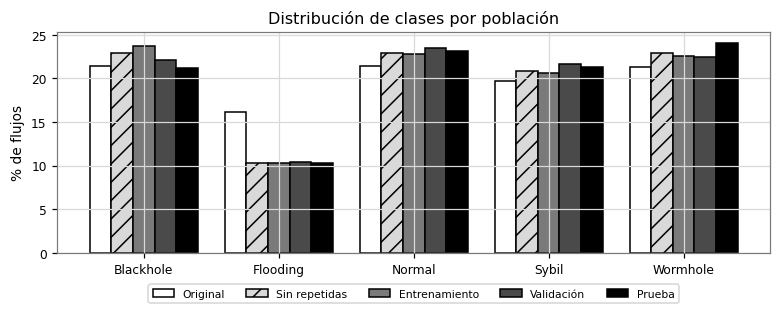

**Interpretación.** En entrenamiento, la clase más frecuente es Blackhole (23,7 %) y la menos frecuente Flooding (10,3 %), una razón de 2,29 a 1, con una entropía normalizada de 0,978, muy cerca del máximo de 1. Al retirar las filas repetidas, Flooding baja de 16,1 % a 10,3 %, porque concentra la mayoría de las repeticiones, y la partición conserva las proporciones con diferencias de pocas décimas.

Esto significa que el desbalance es moderado: no hay clases raras, pero tampoco una distribución uniforme, y una exactitud global podría ocultar un mal desempeño en Flooding.

Por tal motivo, se mantiene la entropía cruzada ponderada con $w_c = n / (K n_c)$, sin remuestreo ni *focal loss*, que se reservan para desbalances más fuertes, y se reportan métricas robustas al desbalance: F1 macro, *balanced accuracy* y AUC-PR macro.

**Decisión de preprocesamiento.** Pesos de clase calculados solo con entrenamiento; sin remuestreo.

**Impacto en la arquitectura y la validación.** Todas las arquitecturas usan la misma pérdida ponderada, y la partición se estratifica por clase.

**Riesgos.** Remuestrear antes de partir filtraría copias de una misma serie a la prueba; por eso no se aplica.

In [7]:
import matplotlib.pyplot as plt
from scipy import stats

def resumen_clases(indices):
    p = np.bincount(y[indices], minlength=K) / len(indices)
    return p, float(-(p * np.log2(p)).sum() / np.log2(K)), float(p.max() / p.min())

POBLACION = {"Original": np.arange(len(datos)), "Sin repetidas": indices_unicos, "Entrenamiento": ID_ENT, "Validación": ID_VAL, "Prueba": ID_PRU}
tabla_clases = pd.DataFrame({n: 100 * resumen_clases(i)[0] for n, i in POBLACION.items()}, index=CLASES)
tabla_clases.loc["Entropía normalizada"] = [resumen_clases(i)[1] for i in POBLACION.values()]
tabla_clases.loc["Razón mayor / menor"] = [resumen_clases(i)[2] for i in POBLACION.values()]
tabla(tabla_clases.reset_index(names="Clase"), {c: "{:.2f}" for c in POBLACION})
fig, eje = plt.subplots(figsize=(7.2, 3.0))
ancho = 0.16
for j, (nombre, indices) in enumerate(POBLACION.items()):
    eje.bar(np.arange(K) + (j - 2) * ancho, 100 * resumen_clases(indices)[0], ancho, color=["white", GRIS_CLARO, GRIS_MEDIO, GRIS_OSCURO, NEGRO][j], edgecolor=NEGRO, label=nombre,
            hatch=["", "//", "", "", ""][j])
eje.set_xticks(range(K), CLASES)
eje.set_ylabel("% de flujos")
eje.set_title("Distribución de clases por población")
eje.legend(ncol=5, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()
p_ent, h_ent, razon_ent = resumen_clases(ID_ENT)
interpretar(f'''**Interpretación.** En entrenamiento, la clase más frecuente es {CLASES[p_ent.argmax()]} ({pct(p_ent.max())}) y la menos frecuente {CLASES[p_ent.argmin()]} ({pct(p_ent.min())}), una razón de {num(razon_ent, 2)} a 1, con una entropía normalizada de {num(h_ent, 3)}, muy cerca del máximo de 1. Al retirar las filas repetidas, Flooding baja de {num(tabla_clases.loc["Flooding", "Original"], 1)} % a {num(tabla_clases.loc["Flooding", "Sin repetidas"], 1)} %, porque concentra la mayoría de las repeticiones, y la partición conserva las proporciones con diferencias de pocas décimas.

Esto significa que el desbalance es moderado: no hay clases raras, pero tampoco una distribución uniforme, y una exactitud global podría ocultar un mal desempeño en Flooding.

Por tal motivo, se mantiene la entropía cruzada ponderada con $w_c = n / (K n_c)$, sin remuestreo ni *focal loss*, que se reservan para desbalances más fuertes, y se reportan métricas robustas al desbalance: F1 macro, *balanced accuracy* y AUC-PR macro.

**Decisión de preprocesamiento.** Pesos de clase calculados solo con entrenamiento; sin remuestreo.

**Impacto en la arquitectura y la validación.** Todas las arquitecturas usan la misma pérdida ponderada, y la partición se estratifica por clase.

**Riesgos.** Remuestrear antes de partir filtraría copias de una misma serie a la prueba; por eso no se aplica.''')

#### 2.1.2 Calidad del dataset

El contrato de datos ya descartó valores faltantes, corruptos e inconsistentes (sección 1.5). Aquí se cuantifican los duplicados exactos, los casi duplicados y el ruido de etiquetas, que fija el techo de desempeño de la sección 6.5. Los casi duplicados se definen como en el Entregable 1: flujos cuyo logaritmo coincide en todos los atributos al redondear a dos decimales, una diferencia de cerca de 1 %. El ruido de etiquetas se estima por dos vías: los grupos de flujos idénticos o casi idénticos con etiquetas distintas, y el aprendizaje confiado (*confident learning*; Northcutt et al., 2021), que compara la etiqueta de cada flujo de entrenamiento con las probabilidades fuera de pliegue de un LightGBM, con pliegues agrupados por bloque para no premiar la memorización de la serie.

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

repetidas_atributos = datos[ATRIBUTOS].duplicated(keep=False)
conflictos_exactos = datos.loc[repetidas_atributos].groupby(ATRIBUTOS, dropna=False)["label"].nunique()
grupos_conflicto = int((conflictos_exactos > 1).sum())
filas_conflicto = int(datos.loc[repetidas_atributos].groupby(ATRIBUTOS)["label"].transform("nunique").gt(1).sum())
def clave_filas(M, decimales=2):
    # Clave binaria de cada fila redondeada: dos flujos son casi duplicados si comparten la clave
    M = np.ascontiguousarray(np.round(M, decimales) + 0.0)
    return pd.factorize(M.view(np.dtype((np.void, M.dtype.itemsize * M.shape[1]))).ravel())[0]
casi = pd.DataFrame({"clave": clave_filas(x_log[indices_unicos]), "y": y[indices_unicos]})
tam_grupo = casi.groupby("clave")["y"].transform("size")
clases_grupo = casi.groupby("clave")["y"].transform("nunique")
frac_casi = float((tam_grupo > 1).mean())
frac_casi_conflicto = float((clases_grupo > 1).mean())

RUTA_CL = ANALISIS / "aprendizaje_confiado.npz"
if RUTA_CL.exists():
    cl = np.load(RUTA_CL)
    oof = cl["oof"]
else:
    import lightgbm as lgb
    X_ent = H["X"][ID_ENT]
    oof = np.zeros((len(ID_ENT), K))
    for f_ent, f_val in StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X_ent, y[ID_ENT], bloques[ID_ENT]):
        m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=63, class_weight="balanced", random_state=42, n_jobs=2, verbose=-1)
        m.fit(X_ent[f_ent], y[ID_ENT][f_ent])
        oof[f_val] = m.predict_proba(X_ent[f_val])
    np.savez(RUTA_CL, oof=oof)
y_ent = y[ID_ENT]
umbral = np.array([oof[y_ent == c, c].mean() for c in range(K)])
confiables = oof >= umbral
candidata = np.where(confiables.any(1), np.argmax(np.where(confiables, oof, -1), 1), -1)
C_CL = np.zeros((K, K), int)
for c in range(K):
    for j in range(K):
        C_CL[c, j] = int(((y_ent == c) & (candidata == j)).sum())
ruido_cl = float(C_CL[~np.eye(K, dtype=bool)].sum() / C_CL.sum())
matriz_cl = pd.DataFrame(C_CL, index=[f"Etiqueta {c}" for c in CLASES], columns=[f"Probable {c}" for c in CLASES])
tabla(matriz_cl.reset_index(names="Conteo conjunto"))
calidad = pd.DataFrame({"Indicador": ["Filas repetidas en atributos y etiqueta", "Grupos de atributos idénticos con etiquetas distintas", "Filas en esos grupos",
                                      "Flujos sin repetir con un casi duplicado", "Flujos en grupos casi duplicados con clases distintas", "Ruido estimado por aprendizaje confiado (entrenamiento)"],
                        "Valor": [f"{int(repetidas.sum()):,}".replace(",", " "), f"{grupos_conflicto:,}".replace(",", " "), f"{filas_conflicto:,}".replace(",", " "), pct(frac_casi), pct(frac_casi_conflicto), pct(ruido_cl)]})
tabla(calidad)
par_bw = (C_CL[0, 4] + C_CL[4, 0]) / max(C_CL[~np.eye(K, dtype=bool)].sum(), 1)
texto_conflicto = "ningún grupo de flujos con atributos idénticos tiene etiquetas distintas" if grupos_conflicto == 0 else f"{grupos_conflicto} grupos de atributos idénticos tienen etiquetas distintas y reúnen {filas_conflicto} filas"
par_sf = (C_CL[3, 1] + C_CL[1, 3]) / max(C_CL[~np.eye(K, dtype=bool)].sum(), 1)
interpretar(f'''**Interpretación.** El archivo tiene {num(int(repetidas.sum()), 0)} filas repetidas, que se retiran antes de partir, y {texto_conflicto}. Tras retirar las repetidas, el {pct(frac_casi)} de los flujos tiene un casi duplicado y el {pct(frac_casi_conflicto)} cae en un grupo casi duplicado con más de una clase. El aprendizaje confiado estima que el {pct(ruido_cl)} de las etiquetas de entrenamiento serían de otra clase, el par Blackhole–Wormhole reúne el {pct(par_bw)} de esos casos y el par Sybil–Flooding, el {pct(par_sf)}.

Hay que tener en cuenta que el aprendizaje confiado no distingue el ruido de etiqueta de la superposición real entre clases: un flujo de Blackhole que se comporta como uno de Wormhole aparece como sospechoso aunque su etiqueta sea correcta. Es decir, la cifra es una cota superior de la parte del error que ningún modelo podría eliminar, y se concentra en el mismo par de ataques que el Entregable 1 señaló como el más confundido.

Por lo anterior, conviene usar esta estimación como una de las cotas del techo de desempeño de la sección 6.5, junto con la del vecino más cercano, y no corregir etiquetas, porque no hay una muestra auditada que permita separar el ruido de la superposición.

**Decisión de preprocesamiento.** Se retiran las filas repetidas, como en el Entregable 1; las etiquetas no se modifican.

**Impacto en la arquitectura y la validación.** El margen de mejora real depende del techo; si el mejor modelo se acerca a él, no se justifica una arquitectura más compleja (sección 12.1 del enunciado).

**Riesgos.** Los casi duplicados entre particiones inflan el desempeño; su proporción entre entrenamiento y prueba se audita en la sección 2.1.4 y su efecto en el desempeño, en la sección 6.''')

Conteo conjunto,Probable Blackhole,Probable Flooding,Probable Normal,Probable Sybil,Probable Wormhole
Etiqueta Blackhole,14 499,8,9,0,1 273
Etiqueta Flooding,5,7 121,0,96,117
Etiqueta Normal,12,282,15 961,0,160
Etiqueta Sybil,0,1 426,46,12 693,64
Etiqueta Wormhole,1 337,61,185,2,12 086


Indicador,Valor
Filas repetidas en atributos y etiqueta,8 219
Grupos de atributos idénticos con etiquetas distintas,0
Filas en esos grupos,0
Flujos sin repetir con un casi duplicado,"19,6 %"
Flujos en grupos casi duplicados con clases distintas,"0,5 %"
Ruido estimado por aprendizaje confiado (entrenamiento),"7,5 %"


**Interpretación.** El archivo tiene 8 219 filas repetidas, que se retiran antes de partir, y ningún grupo de flujos con atributos idénticos tiene etiquetas distintas. Tras retirar las repetidas, el 19,6 % de los flujos tiene un casi duplicado y el 0,5 % cae en un grupo casi duplicado con más de una clase. El aprendizaje confiado estima que el 7,5 % de las etiquetas de entrenamiento serían de otra clase, el par Blackhole–Wormhole reúne el 51,3 % de esos casos y el par Sybil–Flooding, el 29,9 %.

Hay que tener en cuenta que el aprendizaje confiado no distingue el ruido de etiqueta de la superposición real entre clases: un flujo de Blackhole que se comporta como uno de Wormhole aparece como sospechoso aunque su etiqueta sea correcta. Es decir, la cifra es una cota superior de la parte del error que ningún modelo podría eliminar, y se concentra en el mismo par de ataques que el Entregable 1 señaló como el más confundido.

Por lo anterior, conviene usar esta estimación como una de las cotas del techo de desempeño de la sección 6.5, junto con la del vecino más cercano, y no corregir etiquetas, porque no hay una muestra auditada que permita separar el ruido de la superposición.

**Decisión de preprocesamiento.** Se retiran las filas repetidas, como en el Entregable 1; las etiquetas no se modifican.

**Impacto en la arquitectura y la validación.** El margen de mejora real depende del techo; si el mejor modelo se acerca a él, no se justifica una arquitectura más compleja (sección 12.1 del enunciado).

**Riesgos.** Los casi duplicados entre particiones inflan el desempeño; su proporción entre entrenamiento y prueba se audita en la sección 2.1.4 y su efecto en el desempeño, en la sección 6.

#### 2.1.3 Sesgos y atajos

Se revisan los sesgos de representación, de adquisición y de orden, y se mide si algún atributo irrelevante predice la etiqueta por sí solo (*shortcut learning*; Geirhos et al., 2020). Para los identificadores categóricos se usa la V de Cramér frente a la etiqueta, $V = \sqrt{\chi^2 / (n (\min(r, c) - 1))}$, y para el orden del archivo, la proporción de flujos consecutivos que comparten clase.

In [9]:
def cramer(a, b):
    t = pd.crosstab(a, b).to_numpy()
    return float(np.sqrt(stats.chi2_contingency(t)[0] / (t.sum() * (min(t.shape) - 1))))

etiqueta = pd.Series(y[indices_unicos])
sub = datos.iloc[indices_unicos]
asociacion = pd.DataFrame({"Identificador": ["SrcPort", "DstPort", "SrcAddr", "DstAddr"],
                           "Valores distintos": [sub[c].nunique() for c in ["SrcPort", "DstPort", "SrcAddr", "DstAddr"]],
                           "V de Cramér con la etiqueta": [cramer(sub[c].to_numpy(), etiqueta.to_numpy()) for c in ["SrcPort", "DstPort", "SrcAddr", "DstAddr"]]})
tabla(asociacion, {"V de Cramér con la etiqueta": "{:.3f}"})
tabla(pd.crosstab(sub["label"].str.replace(" Attack", "").str.replace(" Traffic", ""), sub["SrcPort"]).reset_index(names="Clase"))
orden = y[np.sort(indices_unicos)]
mismos = float((orden[1:] == orden[:-1]).mean())
esperado = float((np.bincount(orden) / len(orden)) @ (np.bincount(orden) / len(orden)))
direcciones_multiclase = int((sub.groupby("SrcAddr")["label"].nunique() > 1).sum())
interpretar(f'''**Interpretación.** Los puertos y las direcciones IP se asocian fuertemente con la clase: la V de Cramér va de {num(asociacion["V de Cramér con la etiqueta"].min(), 3)} a {num(asociacion["V de Cramér con la etiqueta"].max(), 3)}, y el puerto 654 no aparece en Flooding ni en Sybil. En el orden del archivo, el {pct(mismos)} de los flujos consecutivos comparte clase, frente al {pct(esperado)} que se esperaría si el orden fuera aleatorio, y {direcciones_multiclase} de las {sub["SrcAddr"].nunique()} direcciones de origen aparecen en dos o más clases.

Esto significa que los identificadores describen cómo se armaron las simulaciones y no el comportamiento del tráfico: el puerto 654 corresponde al tráfico de control de AODV y su presencia depende del escenario, y el archivo está ordenado por clase, de modo que `FlowID` delata la etiqueta. Se trata de sesgos de adquisición y de orden, no de representación, porque las cinco clases tienen un tamaño parecido.

Por esta razón, lo indicado es mantener fuera de las entradas los seis identificadores, como en el Entregable 1, y comprobar en la sección 6 que el desempeño de los modelos no cambie entre los flujos con y sin el puerto 654, que es el diagnóstico de atajos de la sección 12.3 del enunciado.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `SrcPort`, `DstAddr`, `DstPort` y `Protocol`.

**Impacto en la arquitectura y la validación.** Las arquitecturas que necesitan un grafo entre nodos, como las GNN de la literatura, quedan fuera del Top 10, porque lo arman con estas direcciones (sección 3.2).

**Riesgos.** Los atributos de tráfico también pueden reflejar el escenario y no solo el ataque; ese riesgo se mide con la validación adversarial de la sección 2.1.5.''')

Identificador,Valores distintos,V de Cramér con la etiqueta
SrcPort,2,"0,631"
DstPort,2,"0,631"
SrcAddr,176,"0,614"
DstAddr,218,"0,229"


Clase,9,654
Blackhole,11 248,14 862
Flooding,11 776,0
Normal,11 294,14 878
Sybil,23 808,0
Wormhole,25 494,592


**Interpretación.** Los puertos y las direcciones IP se asocian fuertemente con la clase: la V de Cramér va de 0,229 a 0,631, y el puerto 654 no aparece en Flooding ni en Sybil. En el orden del archivo, el 92,5 % de los flujos consecutivos comparte clase, frente al 21,2 % que se esperaría si el orden fuera aleatorio, y 125 de las 176 direcciones de origen aparecen en dos o más clases.

Esto significa que los identificadores describen cómo se armaron las simulaciones y no el comportamiento del tráfico: el puerto 654 corresponde al tráfico de control de AODV y su presencia depende del escenario, y el archivo está ordenado por clase, de modo que `FlowID` delata la etiqueta. Se trata de sesgos de adquisición y de orden, no de representación, porque las cinco clases tienen un tamaño parecido.

Por esta razón, lo indicado es mantener fuera de las entradas los seis identificadores, como en el Entregable 1, y comprobar en la sección 6 que el desempeño de los modelos no cambie entre los flujos con y sin el puerto 654, que es el diagnóstico de atajos de la sección 12.3 del enunciado.

**Decisión de preprocesamiento.** Se excluyen `FlowID`, `SrcAddr`, `SrcPort`, `DstAddr`, `DstPort` y `Protocol`.

**Impacto en la arquitectura y la validación.** Las arquitecturas que necesitan un grafo entre nodos, como las GNN de la literatura, quedan fuera del Top 10, porque lo arman con estas direcciones (sección 3.2).

**Riesgos.** Los atributos de tráfico también pueden reflejar el escenario y no solo el ataque; ese riesgo se mide con la validación adversarial de la sección 2.1.5.

#### 2.1.4 Partición del dataset y auditoría de fuga

La partición se hereda del Entregable 1 sin cambios: estratificada por clase y agrupada por bloques de 1000 flujos, con semilla 42, y la prueba quedó sellada con su suma SHA-256 antes de entrenar cualquier modelo. Aquí se ejecutan las verificaciones de la sección 10.1 del enunciado que dependen solo de los datos; la de transformaciones se prueba con datos sintéticos, y la de etiquetas permutadas, en la sección 6.

In [10]:
B_ENT, B_VAL, B_PRU = (set(bloques[i]) for i in (ID_ENT, ID_VAL, ID_PRU))
def huella(indices, con_etiqueta=False):
    m = np.round(datos[ATRIBUTOS].to_numpy()[indices], 8)
    filas = [hashlib.sha1(f.tobytes() + (bytes([e]) if con_etiqueta else b"")).hexdigest() for f, e in zip(m, y[indices])]
    return set(filas)
H_ENT, H_VAL, H_PRU = huella(ID_ENT), huella(ID_VAL), huella(ID_PRU)
claves = clave_filas(x_log)
c_ent = np.unique(claves[ID_ENT])
casi_val, casi_pru = float(np.isin(claves[ID_VAL], c_ent).mean()), float(np.isin(claves[ID_PRU], c_ent).mean())
np.save(ANALISIS / "prueba_con_casi_duplicado.npy", np.isin(claves[ID_PRU], c_ent))

# Fuga por transformaciones: con datos sintéticos, cambiar validación y prueba no debe mover los estadísticos de la estandarización
sintetico = np.random.default_rng(0).lognormal(size=(len(datos), len(ATRIBUTOS)))
X_a, _ = D.preparar_pliegue(ID_ENT, np.log1p(sintetico))
alterado = sintetico.copy()
alterado[np.concatenate([ID_VAL, ID_PRU])] *= 1000
X_b, _ = D.preparar_pliegue(ID_ENT, np.log1p(alterado))
transformacion_ok = bool(np.allclose(X_a[ID_ENT], X_b[ID_ENT]))

AUDITORIA = pd.DataFrame({
    "Verificación": ["Intersección de unidades de independencia (bloques)", "Duplicados exactos entre particiones", "Casi duplicados de prueba con vecino en entrenamiento",
                     "Fuga temporal", "Fuga espacial", "Fuga por transformaciones", "Fuga por atributos", "Validación adversarial", "Fuga por modelos preentrenados", "Sanidad con etiquetas permutadas"],
    "Cómo se ejecuta": ["Intersección de los bloques de cada partición", "Huella SHA-1 de cada fila de atributos y búsqueda de colisiones", "Clave de log(1 + x) redondeado a 2 decimales",
                        "No aplica: no hay marca de tiempo ni rezagos como entrada", "No aplica: no hay coordenadas", "Prueba con datos sintéticos: se alteran validación y prueba y se comparan los estadísticos",
                        "AUC univariado de cada atributo e identificador (sección 2.2.5)", "Clasificador que separa entrenamiento de prueba (sección 2.1.5)",
                        "No aplica: ningún modelo usa pesos preentrenados", "Entrenamiento con etiquetas permutadas (sección 6.3)"],
    "Resultado": [f"Entrenamiento ∩ prueba: {len(B_ENT & B_PRU)}; entrenamiento ∩ validación: {len(B_ENT & B_VAL)}; validación ∩ prueba: {len(B_VAL & B_PRU)}",
                  f"Entrenamiento ∩ prueba: {len(H_ENT & H_PRU)}; entrenamiento ∩ validación: {len(H_ENT & H_VAL)}; validación ∩ prueba: {len(H_VAL & H_PRU)}",
                  f"Prueba: {pct(casi_pru)}; validación: {pct(casi_val)}", "No aplica", "No aplica", "Aprobada" if transformacion_ok else "Fallida", "Ver sección 2.2.5", "Ver sección 2.1.5", "No aplica", "Ver sección 6.3"],
    "Criterio de aprobación": ["Intersección vacía", "Cero colisiones", "Menos de 5 %, tolerancia declarada a priori, y desempeño con y sin esos casos en la sección 6", "Orden estricto", "Distancia mayor que el *buffer*",
                               "Estadísticos idénticos", "Ningún atributo sospechoso sin justificación", "AUC no distinguible de 0,5 o diferencia explicada", "Riesgo declarado", "Score cercano al azar"]})
tabla(AUDITORIA)
AUDITORIA.to_csv(RESULTADOS / "auditoria_fuga.csv", index=False, encoding="utf-8-sig")
assert not (B_ENT & B_PRU) and not (B_ENT & B_VAL) and not (B_VAL & B_PRU) and transformacion_ok
interpretar(f'''**Interpretación.** Las particiones no comparten ningún bloque, y entre entrenamiento y prueba hay {len(H_ENT & H_PRU)} filas idénticas en sus atributos; la prueba con datos sintéticos confirma que la estandarización solo usa entrenamiento. El {pct(casi_pru)} de los flujos de prueba tiene un casi duplicado en entrenamiento, por debajo de la tolerancia de 5 %, y en validación la cifra es de {pct(casi_val)}.

Es decir, las verificaciones de la sección 10.1 que dependen de los datos se aprueban. Hay que tener en cuenta que un casi duplicado entre bloques distintos es posible, porque un mismo escenario largo puede aportar bloques a varias particiones; por eso la sección 6 compara el desempeño con y sin esos flujos.

En consecuencia, se decide conservar la partición heredada sin cambios, con la regla de oro del enunciado: si una verificación fallara, el benchmark no sería válido hasta corregir la causa.

**Decisión de preprocesamiento.** La estandarización y los pesos de clase se ajustan solo con entrenamiento, también dentro de cada pliegue de la validación cruzada.

**Impacto en la arquitectura y la validación.** Todos los modelos usan la misma partición y la prueba se evalúa una sola vez por corrida.

**Riesgos.** El bloque aproxima la simulación de origen, pero no la identifica; la fuga entre bloques vecinos no se elimina por completo.''')

Verificación,Cómo se ejecuta,Resultado,Criterio de aprobación
Intersección de unidades de independencia (bloques),Intersección de los bloques de cada partición,Entrenamiento ∩ prueba: 0; entrenamiento ∩ validación: 0; validación ∩ prueba: 0,Intersección vacía
Duplicados exactos entre particiones,Huella SHA-1 de cada fila de atributos y búsqueda de colisiones,Entrenamiento ∩ prueba: 0; entrenamiento ∩ validación: 0; validación ∩ prueba: 0,Cero colisiones
Casi duplicados de prueba con vecino en entrenamiento,Clave de log(1 + x) redondeado a 2 decimales,"Prueba: 1,8 %; validación: 1,8 %","Menos de 5 %, tolerancia declarada a priori, y desempeño con y sin esos casos en la sección 6"
Fuga temporal,No aplica: no hay marca de tiempo ni rezagos como entrada,No aplica,Orden estricto
Fuga espacial,No aplica: no hay coordenadas,No aplica,Distancia mayor que el *buffer*
Fuga por transformaciones,Prueba con datos sintéticos: se alteran validación y prueba y se comparan los estadísticos,Aprobada,Estadísticos idénticos
Fuga por atributos,AUC univariado de cada atributo e identificador (sección 2.2.5),Ver sección 2.2.5,Ningún atributo sospechoso sin justificación
Validación adversarial,Clasificador que separa entrenamiento de prueba (sección 2.1.5),Ver sección 2.1.5,"AUC no distinguible de 0,5 o diferencia explicada"
Fuga por modelos preentrenados,No aplica: ningún modelo usa pesos preentrenados,No aplica,Riesgo declarado
Sanidad con etiquetas permutadas,Entrenamiento con etiquetas permutadas (sección 6.3),Ver sección 6.3,Score cercano al azar


**Interpretación.** Las particiones no comparten ningún bloque, y entre entrenamiento y prueba hay 0 filas idénticas en sus atributos; la prueba con datos sintéticos confirma que la estandarización solo usa entrenamiento. El 1,8 % de los flujos de prueba tiene un casi duplicado en entrenamiento, por debajo de la tolerancia de 5 %, y en validación la cifra es de 1,8 %.

Es decir, las verificaciones de la sección 10.1 que dependen de los datos se aprueban. Hay que tener en cuenta que un casi duplicado entre bloques distintos es posible, porque un mismo escenario largo puede aportar bloques a varias particiones; por eso la sección 6 compara el desempeño con y sin esos flujos.

En consecuencia, se decide conservar la partición heredada sin cambios, con la regla de oro del enunciado: si una verificación fallara, el benchmark no sería válido hasta corregir la causa.

**Decisión de preprocesamiento.** La estandarización y los pesos de clase se ajustan solo con entrenamiento, también dentro de cada pliegue de la validación cruzada.

**Impacto en la arquitectura y la validación.** Todos los modelos usan la misma partición y la prueba se evalúa una sola vez por corrida.

**Riesgos.** El bloque aproxima la simulación de origen, pero no la identifica; la fuga entre bloques vecinos no se elimina por completo.

#### 2.1.5 Cambio de distribución

Se comparan las distribuciones de entrenamiento, validación y prueba con tres pruebas complementarias: Kolmogorov-Smirnov por atributo, con corrección de Holm; la discrepancia media máxima (MMD) con núcleo gaussiano, que compara las distribuciones conjuntas, con su valor p por permutación (Gretton et al., 2012), y un clasificador adversarial que intenta distinguir las particiones, cuyo AUC sería 0,5 si no hubiera desplazamiento (Lopez-Paz y Oquab, 2017). Con decenas de miles de flujos, cualquier diferencia es significativa, de modo que la lectura se apoya en el tamaño del efecto: el estadístico D de Kolmogorov-Smirnov, la MMD y el AUC.

In [11]:
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score

ks = []
for j, a in enumerate(ATRIBUTOS):
    for nombre, otra in (("validación", ID_VAL), ("prueba", ID_PRU)):
        r = stats.ks_2samp(x_log[ID_ENT, j], x_log[otra, j])
        ks.append({"Atributo": a, "Comparación": f"entrenamiento frente a {nombre}", "D": r.statistic, "p": r.pvalue})
ks = pd.DataFrame(ks)
ks["p Holm"] = multipletests(ks["p"], method="holm")[1]
tabla_ks = ks.pivot(index="Atributo", columns="Comparación", values="D").reset_index()
tabla(tabla_ks, {c: "{:.3f}" for c in tabla_ks.columns if c != "Atributo"})

def mmd_rbf(A, B, permutaciones=200, semilla=0):
    rng = np.random.default_rng(semilla)
    Z = np.vstack([A, B])
    cuadrados = (Z ** 2).sum(1)
    d2 = np.maximum(cuadrados[:, None] + cuadrados[None, :] - 2 * Z @ Z.T, 0)
    gamma = 1 / np.median(d2[d2 > 0])
    Kz = np.exp(-gamma * d2)
    n = len(A)
    def estadistico(ix):
        a, b = ix[:n], ix[n:]
        return Kz[np.ix_(a, a)].mean() + Kz[np.ix_(b, b)].mean() - 2 * Kz[np.ix_(a, b)].mean()
    base = estadistico(np.arange(len(Z)))
    nulos = np.array([estadistico(rng.permutation(len(Z))) for _ in range(permutaciones)])
    return base, (1 + (nulos >= base).sum()) / (permutaciones + 1)

RUTA_SHIFT = ANALISIS / "cambio_distribucion.json"
if RUTA_SHIFT.exists():
    shift = json.loads(RUTA_SHIFT.read_text())
else:
    import lightgbm as lgb
    rng = np.random.default_rng(0)
    shift = {}
    for nombre, otra in (("validación", ID_VAL), ("prueba", ID_PRU)):
        a, b = rng.choice(ID_ENT, 1000, replace=False), rng.choice(otra, 1000, replace=False)
        shift[f"mmd_{nombre}"], shift[f"p_mmd_{nombre}"] = mmd_rbf(H["X"][a], H["X"][b])
        # Validación adversarial con pliegues agrupados por bloque y prueba de permutación sobre el AUC
        filas = np.concatenate([ID_ENT, otra])
        etiqueta_adv = np.r_[np.zeros(len(ID_ENT)), np.ones(len(otra))]
        def auc_adversarial(etq, semilla=0):
            prob = np.zeros(len(filas))
            for f_e, f_v in StratifiedGroupKFold(5, shuffle=True, random_state=semilla).split(filas, etq, bloques[filas]):
                m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, random_state=0, n_jobs=2, verbose=-1).fit(H["X"][filas[f_e]], etq[f_e])
                prob[f_v] = m.predict_proba(H["X"][filas[f_v]])[:, 1]
            return roc_auc_score(etq, prob)
        shift[f"auc_{nombre}"] = auc_adversarial(etiqueta_adv)
        # Permutación por bloques: se reasigna la partición a bloques completos, que es la unidad de independencia
        b_unicos = np.unique(bloques[filas])
        nulos = []
        for i in range(20):
            elegidos = set(np.random.default_rng(i).choice(b_unicos, len(set(bloques[otra])), replace=False))
            nulos.append(auc_adversarial(np.isin(bloques[filas], list(elegidos)).astype(float)))
        shift[f"auc_nulo_{nombre}"] = nulos
    RUTA_SHIFT.write_text(json.dumps(shift, indent=1, default=float))
resumen_shift = pd.DataFrame({"Comparación": ["Entrenamiento frente a validación", "Entrenamiento frente a prueba"],
                              "D máximo de KS": [ks.loc[ks["Comparación"].str.contains(n), "D"].max() for n in ("validación", "prueba")],
                              "Atributos con p Holm < 0,05": [int((ks.loc[ks["Comparación"].str.contains(n), "p Holm"] < ALFA).sum()) for n in ("validación", "prueba")],
                              "MMD": [shift["mmd_validación"], shift["mmd_prueba"]], "p de MMD": [shift["p_mmd_validación"], shift["p_mmd_prueba"]],
                              "AUC adversarial": [shift["auc_validación"], shift["auc_prueba"]],
                              "AUC nulo, máximo de 20 asignaciones por bloques": [max(shift["auc_nulo_validación"]), max(shift["auc_nulo_prueba"])],
                              "p de permutación por bloques": [(1 + sum(v >= shift[f"auc_{n}"] for v in shift[f"auc_nulo_{n}"])) / 21 for n in ("validación", "prueba")]})
tabla(resumen_shift, {"D máximo de KS": "{:.3f}", "MMD": "{:.4f}", "p de MMD": "{:.4f}", "AUC adversarial": "{:.3f}", "AUC nulo, máximo de 20 asignaciones por bloques": "{:.3f}", "p de permutación por bloques": "{:.3f}"})
peor = ks.sort_values("D", ascending=False).iloc[0]
p_adv = {n: (1 + sum(v >= shift[f"auc_{n}"] for v in shift[f"auc_nulo_{n}"])) / 21 for n in ("validación", "prueba")}
interpretar(f'''**Interpretación.** Con pliegues agrupados por bloque, el clasificador adversarial separa el entrenamiento de la validación con un AUC de {num(shift["auc_validación"], 3)} y de la prueba con {num(shift["auc_prueba"], 3)}, valores que caen dentro de la distribución nula que se obtiene al asignar bloques al azar, cuyo máximo es de {num(max(shift["auc_nulo_validación"]), 3)} y {num(max(shift["auc_nulo_prueba"]), 3)}, con valores p de permutación de {num(p_adv["validación"], 3)} y {num(p_adv["prueba"], 3)}. En cambio, las pruebas fila a fila sí detectan diferencias: los 16 atributos rechazan la igualdad de Kolmogorov-Smirnov tras Holm, con D de hasta {num(peor["D"], 3)} en `{peor["Atributo"]}`, y la MMD tiene p = {num(shift["p_mmd_prueba"], 3)}, aunque con tamaños de efecto pequeños.

Esto corrige una lectura del Entregable 1, que reportó un AUC adversarial de 0,889 y 0,848 con una validación cruzada sin agrupar: ese clasificador reconocía la serie de cada flujo, porque los flujos de un mismo bloque caían a la vez en sus pliegues de entrenamiento y de evaluación, y no medía un desplazamiento entre particiones. Es decir, las particiones difieren entre sí lo mismo que dos conjuntos cualesquiera de series, y las pruebas fila a fila rechazan porque tratan como independientes flujos que no lo son (sección 2.2.3).

Por ello, se recomienda no aplicar adaptación de dominio y evaluar el benchmark con intervalos por *bootstrap* de bloques y por bloque de prueba, que sí respetan la dependencia, porque el desempeño absoluto depende de qué series caigan en la prueba, como mostró el intervalo por bloques del Entregable 1.

**Decisión de preprocesamiento.** Ninguna adicional; la estandarización ya se ajusta solo en entrenamiento.

**Impacto en la arquitectura y la validación.** Se prefieren los intervalos por bloques y las pruebas pareadas sobre semillas, que comparan los modelos sobre las mismas series.

**Riesgos.** La brecha entre validación y prueba que observó el Entregable 1 no se explica por un desplazamiento propio de la partición, sino por la variación entre series; se prueba en la tabla B (sección 7).''')

Atributo,entrenamiento frente a prueba,entrenamiento frente a validación
AverageHopCount,"0,101","0,065"
FlowDuration/s,"0,064","0,098"
LostPackets,"0,074","0,051"
MeanDelay/s,"0,051","0,096"
MeanJitter/s,"0,051","0,107"
MeanPacketSize,"0,047","0,079"
PacketDropRate,"0,047","0,045"
RxByteRate/s,"0,085","0,047"
RxBytes,"0,060","0,061"
RxPacketRate/s,"0,104","0,048"


Comparación,D máximo de KS,"Atributos con p Holm < 0,05",MMD,p de MMD,AUC adversarial,"AUC nulo, máximo de 20 asignaciones por bloques",p de permutación por bloques
Entrenamiento frente a validación,"0,107",16,"0,0063","0,0050","0,515","0,622","0,381"
Entrenamiento frente a prueba,"0,128",16,"0,0071","0,0050","0,451","0,596","0,714"


**Interpretación.** Con pliegues agrupados por bloque, el clasificador adversarial separa el entrenamiento de la validación con un AUC de 0,515 y de la prueba con 0,451, valores que caen dentro de la distribución nula que se obtiene al asignar bloques al azar, cuyo máximo es de 0,622 y 0,596, con valores p de permutación de 0,381 y 0,714. En cambio, las pruebas fila a fila sí detectan diferencias: los 16 atributos rechazan la igualdad de Kolmogorov-Smirnov tras Holm, con D de hasta 0,128 en `TxPacketRate/s`, y la MMD tiene p = 0,005, aunque con tamaños de efecto pequeños.

Esto corrige una lectura del Entregable 1, que reportó un AUC adversarial de 0,889 y 0,848 con una validación cruzada sin agrupar: ese clasificador reconocía la serie de cada flujo, porque los flujos de un mismo bloque caían a la vez en sus pliegues de entrenamiento y de evaluación, y no medía un desplazamiento entre particiones. Es decir, las particiones difieren entre sí lo mismo que dos conjuntos cualesquiera de series, y las pruebas fila a fila rechazan porque tratan como independientes flujos que no lo son (sección 2.2.3).

Por ello, se recomienda no aplicar adaptación de dominio y evaluar el benchmark con intervalos por *bootstrap* de bloques y por bloque de prueba, que sí respetan la dependencia, porque el desempeño absoluto depende de qué series caigan en la prueba, como mostró el intervalo por bloques del Entregable 1.

**Decisión de preprocesamiento.** Ninguna adicional; la estandarización ya se ajusta solo en entrenamiento.

**Impacto en la arquitectura y la validación.** Se prefieren los intervalos por bloques y las pruebas pareadas sobre semillas, que comparan los modelos sobre las mismas series.

**Riesgos.** La brecha entre validación y prueba que observó el Entregable 1 no se explica por un desplazamiento propio de la partición, sino por la variación entre series; se prueba en la tabla B (sección 7).

### 2.2 EDA específico: datos tabulares

Desde aquí se trabaja solo con entrenamiento. Se aplica el bloque de datos tabulares del enunciado: tipos de variables, distribuciones y escalas, valores faltantes, relaciones entre variables, detección de fuga por atributo, estructura de grupos e implicaciones para la familia de modelos.

#### 2.2.1 Tipos de variables, distribuciones y escalas

Para cada atributo se registra su tipo, su asimetría y su curtosis antes y después de $\log(1 + x)$, y su proporción de atípicos univariados por el criterio de 1,5 veces el rango intercuartílico. Los atípicos multivariados se miden con la distancia de Mahalanobis robusta, con la covarianza de determinante mínimo (Rousseeuw y Van Driessen, 1999), y el umbral del percentil 99,9 de una χ² con 16 grados de libertad.

In [12]:
from sklearn.covariance import MinCovDet

crudo_ent = datos[ATRIBUTOS].to_numpy(float)[ID_ENT]
log_ent = x_log[ID_ENT]
def atipicos(v):
    q1, q3 = np.percentile(v, [25, 75])
    return float(((v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))).mean())
distribuciones = pd.DataFrame({"Atributo": ATRIBUTOS, "Tipo": ["discreto" if np.allclose(crudo_ent[:, j], np.round(crudo_ent[:, j])) else "continuo" for j in range(len(ATRIBUTOS))],
                               "Valores distintos": [len(np.unique(crudo_ent[:, j])) for j in range(len(ATRIBUTOS))],
                               "Asimetría original": stats.skew(crudo_ent), "Asimetría con log": stats.skew(log_ent),
                               "Curtosis original": stats.kurtosis(crudo_ent), "Curtosis con log": stats.kurtosis(log_ent),
                               "% atípicos con log": [100 * atipicos(log_ent[:, j]) for j in range(len(ATRIBUTOS))]})
tabla(distribuciones, {c: "{:.2f}" for c in distribuciones.columns[3:]} | {"Valores distintos": "{:,.0f}"})
muestra_mcd = np.random.default_rng(0).choice(len(ID_ENT), 20000, replace=False)
mcd = MinCovDet(random_state=0).fit(H["X"][ID_ENT][muestra_mcd])
dist = mcd.mahalanobis(H["X"][ID_ENT])
corte = stats.chi2.ppf(0.999, len(ATRIBUTOS))
atipico_multi = dist > corte
por_clase = pd.Series(atipico_multi).groupby(y[ID_ENT]).mean().rename(lambda c: CLASES[c])
tabla(pd.DataFrame({"Clase": por_clase.index, "% atípicos multivariados": 100 * por_clase.to_numpy()}), {"% atípicos multivariados": "{:.1f}"})
mas_asimetrico = distribuciones.loc[distribuciones["Asimetría original"].abs().idxmax()]
interpretar(f'''**Interpretación.** Los {len(ATRIBUTOS)} atributos son numéricos, {int((distribuciones["Tipo"] == "discreto").sum())} de ellos discretos (conteos y tamaños), y en escala original son muy asimétricos: el caso extremo es `{mas_asimetrico["Atributo"]}`, con asimetría de {num(mas_asimetrico["Asimetría original"], 1)} y curtosis de {num(mas_asimetrico["Curtosis original"], 0)}. Con $\\log(1 + x)$, la mediana del valor absoluto de la asimetría baja de {num(distribuciones["Asimetría original"].abs().median(), 2)} a {num(distribuciones["Asimetría con log"].abs().median(), 2)}. Sin embargo, el {pct(atipico_multi.mean())} de los flujos de entrenamiento supera el umbral de Mahalanobis robusto, y la proporción va de {pct(por_clase.min())} en {por_clase.idxmin()} a {pct(por_clase.max())} en {por_clase.idxmax()}.

Lo anterior indica que los atípicos multivariados no son errores de medición, sino comportamiento propio de algunas clases: un ataque altera la combinación de atributos, y eliminarlos quitaría justamente la señal que se quiere detectar.

Por tal motivo, se mantiene la transformación logarítmica con estandarización del Entregable 1, sin eliminar atípicos ni usar un escalado robusto, y la robustez ante valores extremos se evalúa con perturbaciones controladas en la sección 6.

**Decisión de preprocesamiento.** $\\log(1 + x)$, recorte de `PacketDropRate` en 1 y estandarización con entrenamiento.

**Impacto en la arquitectura y la validación.** Las arquitecturas con funciones de base acotadas, como la KAN, recortan la entrada en [−5, 5]; la proporción de valores fuera de ese rango se reporta en la sección 4.2.

**Riesgos.** Un modelo puede apoyarse en la rareza de un flujo y no en su clase; el análisis de errores de la sección 6.6 revisa los casos de frontera.

**Valores faltantes.** El contrato de datos no encontró faltantes, de modo que no hay mecanismo MCAR, MAR o MNAR que modelar ni imputación que ajustar. La robustez ante atributos faltantes, que sí ocurre en un despliegue con fallas de sensores (Di et al., 2026), se evalúa como perturbación en la sección 6.''')

Atributo,Tipo,Valores distintos,Asimetría original,Asimetría con log,Curtosis original,Curtosis con log,% atípicos con log
FlowDuration/s,continuo,42 145,"1,86","-0,74","11,83","0,44","1,09"
TxPackets,discreto,2 050,"61,42","0,44","5337,11","-0,71","0,04"
RxPackets,discreto,2 605,"12,18","0,56","285,22","-0,67","0,08"
LostPackets,discreto,641,"104,36","0,22","12029,88","-0,68","0,03"
TxBytes,discreto,8 030,"41,20","0,49","2953,56","-0,61","0,19"
RxBytes,discreto,5 762,"9,98","0,51","144,45","-0,63","0,20"
TxPacketRate/s,continuo,51 405,"162,26","2,65","29079,14","15,05","2,11"
RxPacketRate/s,continuo,55 333,"145,83","2,72","22492,07","16,59","1,48"
TxByteRate/s,continuo,51 464,"163,37","0,47","29366,83","-0,60","0,08"
RxByteRate/s,continuo,56 521,"145,91","0,65","22509,09","-0,84","0,03"


Clase,% atípicos multivariados
Blackhole,"82,2"
Flooding,"61,6"
Normal,"42,7"
Sybil,"12,0"
Wormhole,"75,2"


**Interpretación.** Los 16 atributos son numéricos, 6 de ellos discretos (conteos y tamaños), y en escala original son muy asimétricos: el caso extremo es `TxByteRate/s`, con asimetría de 163,4 y curtosis de 29 367. Con $\log(1 + x)$, la mediana del valor absoluto de la asimetría baja de 29,42 a 0,69. Sin embargo, el 55,0 % de los flujos de entrenamiento supera el umbral de Mahalanobis robusto, y la proporción va de 12,0 % en Sybil a 82,2 % en Blackhole.

Lo anterior indica que los atípicos multivariados no son errores de medición, sino comportamiento propio de algunas clases: un ataque altera la combinación de atributos, y eliminarlos quitaría justamente la señal que se quiere detectar.

Por tal motivo, se mantiene la transformación logarítmica con estandarización del Entregable 1, sin eliminar atípicos ni usar un escalado robusto, y la robustez ante valores extremos se evalúa con perturbaciones controladas en la sección 6.

**Decisión de preprocesamiento.** $\log(1 + x)$, recorte de `PacketDropRate` en 1 y estandarización con entrenamiento.

**Impacto en la arquitectura y la validación.** Las arquitecturas con funciones de base acotadas, como la KAN, recortan la entrada en [−5, 5]; la proporción de valores fuera de ese rango se reporta en la sección 4.2.

**Riesgos.** Un modelo puede apoyarse en la rareza de un flujo y no en su clase; el análisis de errores de la sección 6.6 revisa los casos de frontera.

**Valores faltantes.** El contrato de datos no encontró faltantes, de modo que no hay mecanismo MCAR, MAR o MNAR que modelar ni imputación que ajustar. La robustez ante atributos faltantes, que sí ocurre en un despliegue con fallas de sensores (Di et al., 2026), se evalúa como perturbación en la sección 6.

#### 2.2.2 Relaciones entre variables y detección de fuga por atributo

Se miden la correlación de Pearson y de Spearman entre atributos, la información mutua de cada atributo con la clase, la multicolinealidad con el factor de inflación de varianza, $VIF_j = 1 / (1 - R_j^2)$, y el AUC univariado de cada atributo frente a la etiqueta, en esquema uno contra todos y promediado entre clases. Un AUC univariado cercano a 1 indicaría una variable posterior al evento o derivada de la etiqueta.

Variable,Información mutua (nats),VIF,AUC univariado
TxByteRate/s,"0,975","449,6","0,785"
TxPacketRate/s,"0,924","24,8","0,784"
RxByteRate/s,"0,845","367,7","0,778"
Throughput/Kbps,"0,845","192,0","0,778"
RxPacketRate/s,"0,817","289,8","0,775"
PacketDropRate,"0,814","9,4","0,731"
TxBytes,"0,848","2209,3","0,720"
RxBytes,"0,723","616,6","0,708"
TxPackets,"0,637","2156,6","0,707"
RxPackets,"0,518","516,9","0,700"


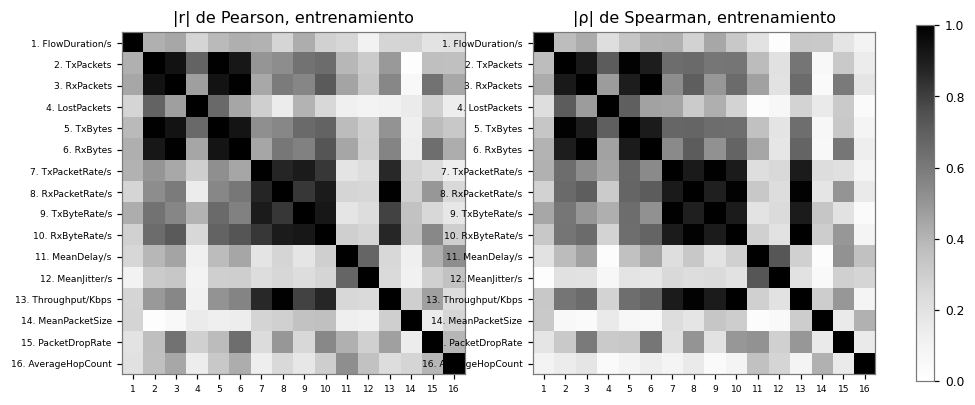

**Interpretación.** El atributo con mayor AUC univariado es `TxByteRate/s`, con 0,785, y ningún atributo de tráfico supera 0,95, el umbral a partir del cual una variable sería sospechosa de fuga. `FlowID` obtiene 0,741, menos que varios atributos de tráfico, porque su relación con la clase no es monótona: el archivo está ordenado en tramos de una sola clase, y el AUC solo mide un orden. Sin embargo, el Entregable 1 mostró que `FlowID` por sí solo, en un modelo no lineal, alcanza un F1 macro de 0,926 con partición aleatoria y de 0,859 con la agrupada, de modo que sí es una fuga. En multicolinealidad, el VIF llega a 2 209 y el número de condición de la matriz de correlación es de 190; el par más correlacionado es `RxPackets` y `RxBytes`, con $|r|$ = 0,9940.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración y `Throughput/Kbps` es `RxByteRate/s` en otras unidades, como confirmó el contrato de datos. Es decir, la dimensión efectiva es menor que 16, pero ningún atributo de tráfico funciona por sí solo como una fuga, mientras que los identificadores sí, aunque el AUC univariado no lo capte en `FlowID`.

Por lo anterior, conviene conservar los 16 atributos, como hace la literatura, porque las redes con regularización toleran la colinealidad, y mantener fuera los identificadores. Para los modelos que leen el vector como secuencia, la correlación alta entre atributos vecinos (por ejemplo, conteos de paquetes y de bytes) da contenido a la convolución local, pero ese contenido depende de un orden de columnas que no tiene significado físico; la RQ3 lo pone a prueba.

**Decisión de preprocesamiento.** Sin selección de atributos por colinealidad.

**Impacto en la arquitectura y la validación.** La redundancia favorece la regularización y no justifica capas muy anchas; el espacio de la búsqueda de arquitectura incluye anchos de 16 a 256 para medirlo.

**Riesgos.** Seleccionar atributos con todo el conjunto filtraría información de la prueba; si se hiciera, tendría que ir dentro de cada pliegue.

In [13]:
from sklearn.feature_selection import mutual_info_classif

pearson = np.corrcoef(log_ent, rowvar=False)
spearman = stats.spearmanr(log_ent).statistic
vif = np.diag(np.linalg.pinv(pearson))
autovalores = np.linalg.eigvalsh(pearson)
condicion = float(np.sqrt(autovalores.max() / max(autovalores.min(), 1e-12)))
muestra_mi = np.random.default_rng(0).permutation(len(ID_ENT))[:30000]
info_mutua = mutual_info_classif(log_ent[muestra_mi], y_ent[muestra_mi], random_state=0)
def auc_univariado(v, etq):
    return float(np.mean([max(roc_auc_score(etq == c, v), 1 - roc_auc_score(etq == c, v)) for c in range(K)]))
y_sin = y[indices_unicos]
identificadores_num = {"FlowID": datos["FlowID"].to_numpy(float), "SrcPort": datos["SrcPort"].to_numpy(float), "DstPort": datos["DstPort"].to_numpy(float),
                       "SrcAddr (último octeto)": datos["SrcAddr"].str.split(".").str[-1].astype(float).to_numpy(), "DstAddr (último octeto)": datos["DstAddr"].str.split(".").str[-1].astype(float).to_numpy()}
relacion = pd.DataFrame({"Variable": ATRIBUTOS, "Información mutua (nats)": info_mutua, "VIF": vif, "AUC univariado": [auc_univariado(log_ent[:, j], y_ent) for j in range(len(ATRIBUTOS))]})
fuga_id = pd.DataFrame({"Variable": list(identificadores_num), "Información mutua (nats)": np.nan, "VIF": np.nan,
                        "AUC univariado": [auc_univariado(v[ID_ENT], y_ent) for v in identificadores_num.values()]})
tabla(pd.concat([relacion.sort_values("AUC univariado", ascending=False), fuga_id]), {"Información mutua (nats)": "{:.3f}", "VIF": "{:.1f}", "AUC univariado": "{:.3f}"})
fig, ejes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for eje, m, titulo in zip(ejes, (np.abs(pearson), np.abs(spearman)), ("|r| de Pearson", "|ρ| de Spearman")):
    imagen = eje.imshow(m, vmin=0, vmax=1)
    eje.set_xticks(range(len(ATRIBUTOS)), range(1, len(ATRIBUTOS) + 1), fontsize=6)
    eje.set_yticks(range(len(ATRIBUTOS)), [f"{i + 1}. {a}" for i, a in enumerate(ATRIBUTOS)], fontsize=6)
    eje.grid(False)
    eje.set_title(titulo + ", entrenamiento")
fig.colorbar(imagen, ax=ejes, fraction=0.03)
plt.show()
pares = sorted([(abs(pearson[i, j]), ATRIBUTOS[i], ATRIBUTOS[j]) for i in range(len(ATRIBUTOS)) for j in range(i + 1, len(ATRIBUTOS))], reverse=True)
max_auc = relacion.loc[relacion["AUC univariado"].idxmax()]
interpretar(f'''**Interpretación.** El atributo con mayor AUC univariado es `{max_auc["Variable"]}`, con {num(max_auc["AUC univariado"], 3)}, y ningún atributo de tráfico supera 0,95, el umbral a partir del cual una variable sería sospechosa de fuga. `FlowID` obtiene {num(fuga_id.loc[0, "AUC univariado"], 3)}, menos que varios atributos de tráfico, porque su relación con la clase no es monótona: el archivo está ordenado en tramos de una sola clase, y el AUC solo mide un orden. Sin embargo, el Entregable 1 mostró que `FlowID` por sí solo, en un modelo no lineal, alcanza un F1 macro de 0,926 con partición aleatoria y de 0,859 con la agrupada, de modo que sí es una fuga. En multicolinealidad, el VIF llega a {num(relacion["VIF"].max(), 0)} y el número de condición de la matriz de correlación es de {num(condicion, 0)}; el par más correlacionado es `{pares[0][1]}` y `{pares[0][2]}`, con $|r|$ = {num(pares[0][0], 4)}.

Esto se explica por la construcción de los atributos: las tasas son cocientes de los conteos sobre la duración y `Throughput/Kbps` es `RxByteRate/s` en otras unidades, como confirmó el contrato de datos. Es decir, la dimensión efectiva es menor que 16, pero ningún atributo de tráfico funciona por sí solo como una fuga, mientras que los identificadores sí, aunque el AUC univariado no lo capte en `FlowID`.

Por lo anterior, conviene conservar los 16 atributos, como hace la literatura, porque las redes con regularización toleran la colinealidad, y mantener fuera los identificadores. Para los modelos que leen el vector como secuencia, la correlación alta entre atributos vecinos (por ejemplo, conteos de paquetes y de bytes) da contenido a la convolución local, pero ese contenido depende de un orden de columnas que no tiene significado físico; la RQ3 lo pone a prueba.

**Decisión de preprocesamiento.** Sin selección de atributos por colinealidad.

**Impacto en la arquitectura y la validación.** La redundancia favorece la regularización y no justifica capas muy anchas; el espacio de la búsqueda de arquitectura incluye anchos de 16 a 256 para medirlo.

**Riesgos.** Seleccionar atributos con todo el conjunto filtraría información de la prueba; si se hiciera, tendría que ir dentro de cada pliegue.''')

#### 2.2.3 Estructura de grupos e implicaciones para la familia de modelos

El enunciado pide revisar si hay varias filas por entidad que obliguen a partir por grupos. En este conjunto hay dos agrupamientos candidatos, la dirección de origen y la serie del archivo, y el Entregable 1 ya mostró que la dependencia sigue a la serie. Aquí se cuantifica cuánto se parecen dos flujos de la misma serie frente a dos de series distintas, con la correlación intraclase del logaritmo de cada atributo entre bloques, $ICC = \sigma^2_{bloque} / (\sigma^2_{bloque} + \sigma^2_{dentro})$, calculada dentro de cada clase para que no mida la diferencia entre clases.

In [14]:
def icc(v, g):
    tabla_g = pd.DataFrame({"v": v, "g": g})
    medias, tam = tabla_g.groupby("g")["v"].mean(), tabla_g.groupby("g")["v"].size()
    k0 = tam.mean()
    ms_entre = (tam * (medias - v.mean()) ** 2).sum() / (len(medias) - 1)
    ms_dentro = ((tabla_g["v"] - tabla_g["g"].map(medias)) ** 2).sum() / (len(v) - len(medias))
    return max((ms_entre - ms_dentro) / (ms_entre + (k0 - 1) * ms_dentro), 0.0)
icc_bloque = {a: np.median([icc(log_ent[y_ent == c, j], bloques[ID_ENT][y_ent == c]) for c in range(K)]) for j, a in enumerate(ATRIBUTOS)}
origen = datos["SrcAddr"].to_numpy()[ID_ENT]
icc_origen = {a: np.median([icc(log_ent[y_ent == c, j], origen[y_ent == c]) for c in range(K)]) for j, a in enumerate(ATRIBUTOS)}
grupos = pd.DataFrame({"Atributo": ATRIBUTOS, "ICC por bloque": icc_bloque.values(), "ICC por dirección de origen": icc_origen.values()})
tabla(grupos, {"ICC por bloque": "{:.3f}", "ICC por dirección de origen": "{:.3f}"})
interpretar(f'''**Interpretación.** Dentro de cada clase, la mediana de la correlación intraclase por bloque va de {num(grupos["ICC por bloque"].min(), 3)} a {num(grupos["ICC por bloque"].max(), 3)} entre atributos, con una mediana general de {num(grupos["ICC por bloque"].median(), 3)}, frente a {num(grupos["ICC por dirección de origen"].median(), 3)} por dirección de origen.

Esto quiere decir que una parte importante de la variación de cada atributo es común a los flujos de una misma serie, y que la serie agrupa mejor que el nodo emisor. De esta forma, una partición aleatoria pondría en prueba flujos casi gemelos de los de entrenamiento y mediría interpolación dentro de la serie, no generalización.

Por esta razón, lo indicado es mantener la partición agrupada por bloques y, como el enunciado recomienda para datos tabulares, incluir los árboles potenciados como comparador fuerte (LightGBM, ajustado con el mismo presupuesto), porque en tablas de pocas columnas suelen igualar o superar a las redes.

**Decisión de preprocesamiento.** Partición, validación cruzada y *bootstrap* agrupados por bloque.

**Impacto en la arquitectura y la validación.** Las pruebas sobre filas, como McNemar y DeLong, suponen independencia entre flujos que la ICC descarta; se reportan como complemento y no sustentan conclusiones.

**Riesgos.** El tamaño del bloque es una aproximación: si una serie real fuera más larga que 1000 flujos, quedaría dependencia entre bloques vecinos.''')

Atributo,ICC por bloque,ICC por dirección de origen
FlowDuration/s,"0,801","0,095"
TxPackets,"0,637","0,136"
RxPackets,"0,578","0,139"
LostPackets,"0,410","0,100"
TxBytes,"0,621","0,136"
RxBytes,"0,544","0,117"
TxPacketRate/s,"0,142","0,121"
RxPacketRate/s,"0,188","0,082"
TxByteRate/s,"0,560","0,100"
RxByteRate/s,"0,449","0,094"


**Interpretación.** Dentro de cada clase, la mediana de la correlación intraclase por bloque va de 0,136 a 0,801 entre atributos, con una mediana general de 0,424, frente a 0,097 por dirección de origen.

Esto quiere decir que una parte importante de la variación de cada atributo es común a los flujos de una misma serie, y que la serie agrupa mejor que el nodo emisor. De esta forma, una partición aleatoria pondría en prueba flujos casi gemelos de los de entrenamiento y mediría interpolación dentro de la serie, no generalización.

Por esta razón, lo indicado es mantener la partición agrupada por bloques y, como el enunciado recomienda para datos tabulares, incluir los árboles potenciados como comparador fuerte (LightGBM, ajustado con el mismo presupuesto), porque en tablas de pocas columnas suelen igualar o superar a las redes.

**Decisión de preprocesamiento.** Partición, validación cruzada y *bootstrap* agrupados por bloque.

**Impacto en la arquitectura y la validación.** Las pruebas sobre filas, como McNemar y DeLong, suponen independencia entre flujos que la ICC descarta; se reportan como complemento y no sustentan conclusiones.

**Riesgos.** El tamaño del bloque es una aproximación: si una serie real fuera más larga que 1000 flujos, quedaría dependencia entre bloques vecinos.

### 2.3 Tabla de trazabilidad hallazgo–decisión

La tabla sigue la plantilla A.1 del enunciado y conecta cada hallazgo con su evidencia, la decisión que deriva y el riesgo que deja.

| Hallazgo | Evidencia | Decisión de preprocesamiento | Impacto en arquitectura y validación | Riesgo y fuga |
|---|---|---|---|---|
| Desbalance moderado; Flooding minoritaria tras quitar repetidas | Sección 2.1.1, razón y entropía | Pérdida ponderada con pesos de entrenamiento | F1 macro, *balanced accuracy* y AUC-PR como métricas; partición estratificada | Remuestrear antes de partir filtraría copias a prueba |
| 8219 filas repetidas y casi duplicados | Sección 2.1.2 | Se retiran las repetidas antes de partir | Auditoría de casi duplicados entre particiones | Casi duplicados en prueba inflan el F1 |
| Ruido de etiquetas o superposición concentrada en Blackhole–Wormhole | Sección 2.1.2, aprendizaje confiado | Etiquetas sin modificar | Techo de desempeño (sección 6.5) y limitación del paper guía (sección 5) | El ruido baja el techo y puede confundirse con un mal modelo |
| Identificadores asociados con la etiqueta y archivo ordenado por clase | Sección 2.1.3, V de Cramér y AUC univariado | Se excluyen los 6 identificadores | Se excluyen las GNN que arman el grafo con IP | Los atributos de tráfico también pueden reflejar el escenario |
| Desplazamiento entre series | Sección 2.1.5, KS, MMD y validación adversarial | Ninguna | Intervalos por bloques y robustez ante cambio de distribución | La brecha validación–prueba puede deberse a la serie y no al sobreajuste |
| Asimetría extrema y atípicos propios de las clases | Sección 2.2.1 | $\log(1 + x)$ y estandarización, sin eliminar atípicos | Robustez ante perturbaciones | Un modelo puede aprender la rareza y no la clase |
| Colinealidad por construcción de los atributos | Sección 2.2.2, VIF y correlaciones | Sin selección de atributos | Regularización; anchos de 16 a 256 en la búsqueda | Seleccionar con todo el conjunto filtraría información |
| Dependencia dentro de la serie | Sección 2.2.3, ICC | Partición, validación cruzada y *bootstrap* por bloque | LightGBM como comparador fuerte; McNemar y DeLong solo como complemento | El bloque aproxima la serie y no la identifica |

## 3. Revisión sistemática del estado del arte

En esta sección se extiende la revisión del Entregable 1, que identificó los tres modelos base, para seleccionar con un puntaje explícito el Top 10 de modelos de Deep Learning, describirlos uno por uno, compararlos críticamente y formular el *gap* de investigación. La revisión del Entregable 1 se conserva completa en su cuaderno; aquí se resume lo necesario y se documenta lo nuevo: la actualización de las cadenas, una cadena ampliada por familias de modelos, la búsqueda transversal de mecanismos, dos campos nuevos de la hoja de extracción (código público y líneas base ajustadas) y el puntaje de selección.

### 3.1 Estrategia de búsqueda

**Cadenas, bases y fechas.** El Entregable 1 ejecutó tres cadenas sobre título y resumen, de 2019 a 2026: C1, general; C2, centrada en los ataques del conjunto de datos, y C3, sobre el uso de UAVIDS-2025. Se corrieron en OpenAlex y arXiv el 3 de noviembre de 2026 y en IEEE Xplore, Scopus y Web of Science el 4 de noviembre, con el acceso de la biblioteca de la Universidad del Norte, y se completaron con una verificación de cobertura de sinónimos el 5 de noviembre. Para este entregable se agregan, el 12 de noviembre de 2026 en OpenAlex y arXiv, la repetición de C1 a C3, para captar lo publicado después; C4, que amplía el concepto de método con las familias candidatas al Top 10, y cuatro cadenas transversales, T1 a T4, que buscan los mecanismos en otras modalidades, como pide el enunciado. El 13 de noviembre, con el mismo acceso institucional, las cadenas transversales T1 a T4 se corrieron también en Scopus y en Web of Science, de modo que cumplen el mínimo de dos bases principales que pide el enunciado; IEEE Xplore no se usó para ellas, porque el primer intento devolvió un error del servidor y el mínimo ya se cumplía con las otras dos. La repetición de C1 a C3 no se corrió en esas bases, porque las mismas cadenas ya se corrieron allí el 4 de noviembre, ni tampoco C4, que es una cadena complementaria: en OpenAlex y arXiv aportó 87 de los 94 registros nuevos, pero ninguno de sus estudios elegibles tuvo texto completo accesible, de modo que no modificó los estudios incluidos. En la tabla de conteos, la raya indica una cadena que no se corrió en esa base. Las consultas exactas, con la sintaxis de cada base, están en `literatura/consultas_e2_wos_scopus_ieee.md`.

| Cadena | Consulta | Periodo |
|---|---|---|
| C1 | (drone OR UAV OR "unmanned aerial" OR FANET) AND ("intrusion detection" OR "attack detection") AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) | 2019–2026 |
| C2 | (drone OR UAV OR "unmanned aerial" OR FANET) AND (swarm OR "ad hoc" OR "network traffic") AND (blackhole OR wormhole OR sybil OR flooding OR cyberattack) AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) | 2019–2026 |
| C3 | UAVIDS OR "UAVIDS-2025" | 2019–2026 |
| C4 | (drone OR UAV OR "unmanned aerial" OR FANET OR "Internet of Drones") AND ("intrusion detection" OR "attack detection" OR "anomaly detection") AND (GRU OR "gated recurrent" OR BiLSTM OR "bidirectional LSTM" OR transformer OR TabNet OR "Kolmogorov-Arnold" OR autoencoder OR "deep belief" OR ResNet OR residual OR "CNN-LSTM" OR "graph neural" OR "temporal convolutional" OR mamba OR "state space") | 2019–2026 |
| T1 | ("supervised contrastive" OR "contrastive learning") AND (image OR "computer vision" OR visual) AND (transfer OR adaptation) | 2018–2026 |
| T2 | ("mixture of experts" OR "gated experts") AND ("natural language" OR "language model" OR vision) AND (transfer OR adaptation) | 2018–2026 |
| T3 | ("domain generalization" OR "invariant risk minimization" OR "distributionally robust") AND (image OR vision OR speech) AND (transfer OR adaptation) | 2018–2026 |
| T4 | ("Kolmogorov-Arnold" OR "feature tokenizer" OR "tabular transformer") AND ("time series" OR vision OR image OR language) AND (transfer OR adaptation) | 2018–2026 |

**Periodo.** Las cadenas cubren los últimos ocho años. Los trabajos fundacionales anteriores, como Elman (1990) para la RNN o Hinton et al. (2006) para la DBN, se citan como fuente de cada arquitectura y no entran al conteo de frecuencia, porque no abordan el problema.

**Criterios de inclusión y exclusión.** Son los del Entregable 1: se incluye un estudio si detecta o clasifica intrusiones o ataques en redes o sistemas de drones a partir de datos tabulares de tráfico o del sistema, usa Deep Learning, reporta métricas verificables y compara contra al menos un modelo de Deep Learning; se excluye si no es un estudio primario o si trabaja con imágenes, señales de radio, solo suplantación de GPS o anomalías de vuelo. La calidad de la fuente se registra con el cuartil SJR 2025 de SCImago (2026), y la disponibilidad de código y de detalles para reproducir, en los campos nuevos de la hoja de extracción.

In [15]:
import csv
LIT1, LIT2 = D.E1 / "literatura", RAIZ_E2 / "literatura"
leer_csv = lambda ruta: list(csv.DictReader(ruta.open(encoding="utf-8-sig")))
REG_E1, COB_E1, REG_E2 = leer_csv(LIT1 / "registros_depurados.csv"), leer_csv(LIT1 / "cribado_cobertura_sinonimos.csv"), leer_csv(LIT2 / "registros_nuevos_e2.csv")
EXT = leer_csv(LIT1 / "extraccion_estudios.csv") + leer_csv(LIT2 / "extraccion_estudios_e2.csv")
REPRO = {r["doi"]: r for r in leer_csv(LIT2 / "reproducibilidad_estudios.csv")}
resumen_e2 = json.loads((LIT2 / "exportaciones" / "2026-11-12_resumen_e2.json").read_text(encoding="utf-8"))
conteo_e2 = pd.DataFrame(resumen_e2["resultados"]).pivot(index="fuente", columns="cadena", values="total")
conteo_bases_e2 = pd.DataFrame(json.loads((LIT2 / "exportaciones" / "2026-11-13_conteos_scopus_wos_e2.json").read_text(encoding="utf-8"))["resultados"]).pivot(index="fuente", columns="cadena", values="total")
conteo_e2 = pd.concat([conteo_e2, conteo_bases_e2])
conteo_e1 = pd.DataFrame({"C1": [323, 11, 481, 132, 523], "C2": [40, 3, 40, 11, 18], "C3": [220, 29, 81, 16, 26]}, index=["OpenAlex", "arXiv", "IEEE Xplore", "Web of Science", "Scopus"])
conteos = pd.concat({"Entregable 1 (3 y 4 de noviembre)": conteo_e1, "Entregable 2 (12 y 13 de noviembre)": conteo_e2}, axis=1).reindex(["OpenAlex", "arXiv", "IEEE Xplore", "Scopus", "Web of Science"])
tabla(conteos.reset_index(names="Base").map(lambda v: "—" if pd.isna(v) else (f"{int(v):,}".replace(",", " ") if isinstance(v, (int, float)) else v)), indice=False)
elegibles_e1 = [r for r in REG_E1 if r["cribado"] == "elegible"]
cob_eleg = [r for r in COB_E1 if r["decision"] in ("elegible", "dudoso")]
PRISMA = {"exportados_e1": 583 + 42 + 602 + 567 + 159, "depurados_e1": len(REG_E1), "filtro_e1": sum(r["cribado"] == "" for r in REG_E1), "excluidos_e1": sum(r["cribado"] == "excluido" for r in REG_E1),
          "elegibles_e1": len(elegibles_e1), "no_recuperados_e1": sum(r["texto_completo"] == "no recuperado" for r in elegibles_e1), "cob_elegibles": len(cob_eleg), "cob_incluidos": 4,
          "unicos_e2": 860, "ya_revisados_e2": 860 - len(REG_E2), "nuevos_e2": len(REG_E2), "filtro_e2": sum(r["cribado"] == "" for r in REG_E2), "excluidos_e2": sum(r["cribado"] == "excluido" for r in REG_E2),
          "elegibles_e2": sum(r["cribado"] in ("elegible", "dudoso") for r in REG_E2), "no_recuperados_e2": sum(r["texto_completo"] == "no recuperado" for r in REG_E2),
          "incluidos_e2": sum(r["texto_completo"] == "incluido" for r in REG_E2), "incluidos": len(EXT)}
PRISMA["evaluados_e1"] = PRISMA["elegibles_e1"] - PRISMA["no_recuperados_e1"]
PRISMA["incluidos_e1_bases"] = 38

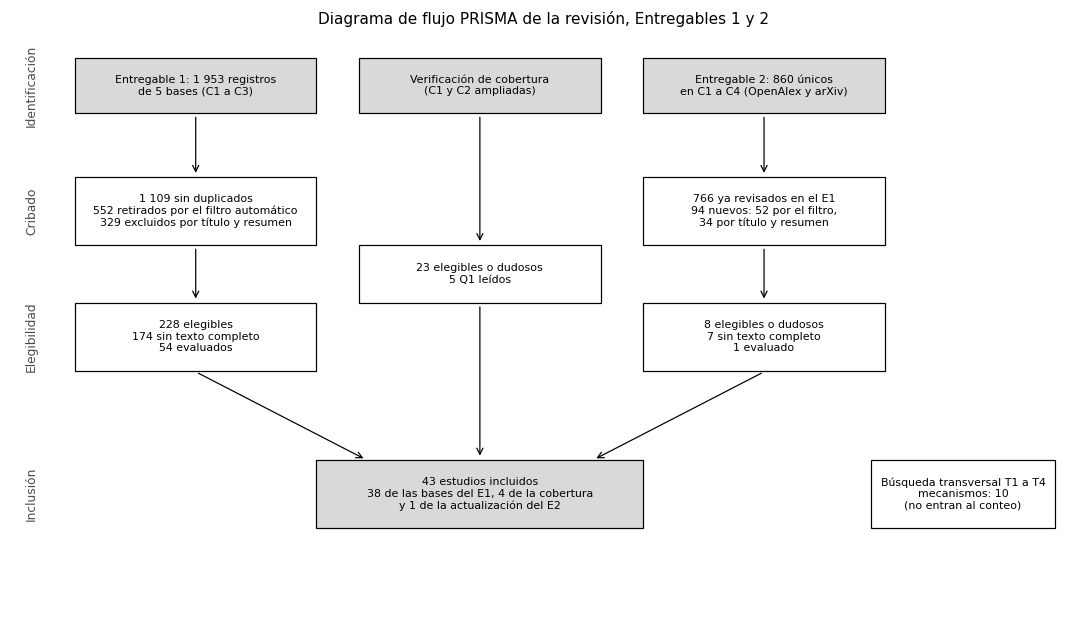

In [16]:
fig, eje = plt.subplots(figsize=(12.5, 6.8))
eje.axis("off")
eje.set(xlim=(0, 15), ylim=(0, 11))
def caja(x, yy, texto, ancho=3.4, alto=1.05, relleno="white"):
    eje.add_patch(plt.Rectangle((x - ancho / 2, yy - alto / 2), ancho, alto, facecolor=relleno, edgecolor=NEGRO, lw=0.8))
    eje.text(x, yy, texto, ha="center", va="center", fontsize=7.2)
def flecha(a, b):
    eje.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=NEGRO, lw=0.8))
P = PRISMA
for etiqueta_fase, yy in (("Identificación", 10), ("Cribado", 7.6), ("Elegibilidad", 5.2), ("Inclusión", 2.2)):
    eje.text(0.2, yy, etiqueta_fase, rotation=90, va="center", fontsize=8, color=GRIS_OSCURO)
caja(2.6, 10, f"Entregable 1: {P['exportados_e1']:,} registros\nde 5 bases (C1 a C3)".replace(",", " "), relleno=GRIS_CLARO)
caja(2.6, 7.6, f"{P['depurados_e1']:,} sin duplicados\n{P['filtro_e1']} retirados por el filtro automático\n{P['excluidos_e1']} excluidos por título y resumen".replace(",", " "), alto=1.3)
caja(2.6, 5.2, f"{P['elegibles_e1']} elegibles\n{P['no_recuperados_e1']} sin texto completo\n{P['evaluados_e1']} evaluados", alto=1.3)
caja(6.6, 10, f"Verificación de cobertura\n(C1 y C2 ampliadas)", relleno=GRIS_CLARO)
caja(6.6, 6.4, f"{P['cob_elegibles']} elegibles o dudosos\n5 Q1 leídos", alto=1.1)
caja(10.6, 10, f"Entregable 2: {P['unicos_e2']} únicos\nen C1 a C4 (OpenAlex y arXiv)", relleno=GRIS_CLARO)
caja(10.6, 7.6, f"{P['ya_revisados_e2']} ya revisados en el E1\n{P['nuevos_e2']} nuevos: {P['filtro_e2']} por el filtro,\n{P['excluidos_e2']} por título y resumen", alto=1.3)
caja(10.6, 5.2, f"{P['elegibles_e2']} elegibles o dudosos\n{P['no_recuperados_e2']} sin texto completo\n{P['incluidos_e2']} evaluado", alto=1.3)
caja(6.6, 2.2, f"{P['incluidos']} estudios incluidos\n{P['incluidos_e1_bases']} de las bases del E1, {P['cob_incluidos']} de la cobertura\ny {P['incluidos_e2']} de la actualización del E2", ancho=4.6, alto=1.3, relleno=GRIS_CLARO)
caja(13.4, 2.2, f"Búsqueda transversal T1 a T4\nmecanismos: {len(leer_csv(LIT2 / 'mecanismos_transferibles.csv'))}\n(no entran al conteo)", ancho=2.6, alto=1.3)
for a, b in (((2.6, 9.45), (2.6, 8.27)), ((2.6, 6.93), (2.6, 5.87)), ((2.6, 4.53), (5.0, 2.85)), ((6.6, 9.45), (6.6, 6.97)), ((6.6, 5.83), (6.6, 2.87)),
             ((10.6, 9.45), (10.6, 8.27)), ((10.6, 6.93), (10.6, 5.87)), ((10.6, 4.53), (8.2, 2.85))):
    flecha(a, b)
eje.set_title("Diagrama de flujo PRISMA de la revisión, Entregables 1 y 2", fontsize=10)
plt.show()

**Interpretación.** La actualización del 12 de noviembre devolvió en C1 y C2 los mismos conteos del 3 de noviembre, de modo que en nueve días no aparecieron estudios nuevos con las cadenas originales. Lo nuevo vino de C3 y de la cadena ampliada C4: de 860 registros únicos, 766 ya se habían revisado en el Entregable 1 y 94 eran nuevos; el filtro automático retiró 52, el cribado por título y resumen excluyó 34, casi todos por tratar anomalías de vuelo, de sensores o de imágenes, y quedaron 5 elegibles y 3 dudosos. De esos 8, solo uno tenía texto completo accesible (Tasfia et al., 2026), que se incluye; los otros 7 quedan sin evaluar. El total de estudios incluidos pasa de 42 a 43.

Hay que tener en cuenta que entre los no recuperados hay dos estudios relevantes para este benchmark: Di et al. (2026), que según su resumen comparan FT-Transformer, MLP y árboles en IDS de UAV con 5 semillas y corrección de Holm, y el de TopoXNet, que usa UAVIDS-2025. Es decir, la revisión tiene un sesgo de acceso, que ya declaró el Entregable 1, y que aquí podría afectar el último puesto del Top 10, como se cuantifica en la sección 3.2.

Por tal motivo, se mantiene la regla del Entregable 1, según la cual solo cuentan los estudios evaluados a texto completo, y se reporta la sensibilidad del Top 10 a incluir los no recuperados con lo que dicen sus resúmenes. Las decisiones de cada registro están en `literatura/registros_nuevos_e2.csv`.

**Quién realizó la selección.** Al ser un trabajo de autor único, hubo un solo revisor, de modo que no aplica el acuerdo de Cohen entre revisores; es una limitación frente a un cribado doble. El cribado y la extracción se hicieron con apoyo de un asistente de inteligencia artificial (Claude, de Anthropic) bajo la supervisión del autor, con búsqueda dirigida de las tablas y los pasajes de cada texto.

**Hoja de extracción.** La hoja tiene los campos fijos que pide el enunciado: arquitectura, dataset, partición, métricas, repeticiones o semillas, pruebas estadísticas, código público y líneas base ajustadas. Los dos últimos son nuevos en este entregable: el código se buscó en el texto completo de cada estudio, con una revisión manual de cada enlace hallado, y se considera ajustada una línea base solo si el estudio declara haberla ajustado con un procedimiento comparable al del modelo propuesto.

In [17]:
import unicodedata

METADATOS = json.loads((LIT1 / "estudios_metadatos.json").read_text(encoding="utf-8"))
METADATOS["10.22266/ijies2025.0531.33"]["autores"] = ["Aws Hamed Hamad", "Noor Khalid Hussein", "Abdulrahman M. Abdulghani"]
METADATOS["sin-doi:dragon"]["autores"] = ["P. SureshBabu", "M. Geetha"]
METADATOS["10.1007/s10207-026-01353-8"] = {"autores": ["Rifa Tasfia", "Anitha Chennamaneni", "Abhijit Kumar Nag"], "anio": 2026, "titulo": "Revisiting adversarial robustness in NIDS: a multi-dataset evaluation of test-time evasion attacks",
                                           "fuente": "International Journal of Information Security", "volumen": "25", "numero": None, "paginas": "184", "tipo": "article"}
COMPUESTOS = {"Canan Batur Şahin": ("Batur Şahin", "Canan")}
PARTICULAS = {"van", "von", "de", "der", "den", "del", "da", "du", "le", "la"}
def partes_nombre(nombre):
    # Apellido y nombres; las partículas (van, de, von...) van con el apellido: Bart van Merriënboer → van Merriënboer, Bart
    if nombre in COMPUESTOS:
        return COMPUESTOS[nombre]
    f = nombre.replace("‐", "-").split()
    i = len(f) - 2
    while i >= 1 and f[i].lower() in PARTICULAS:
        i -= 1
    return " ".join(f[i + 1:]), " ".join(f[:i + 1])
def cita_base(doi):
    m = METADATOS[doi]
    a = [partes_nombre(x)[0] for x in m["autores"]]
    autor = a[0] if len(a) == 1 else f"{a[0]} y {a[1]}" if len(a) == 2 else f"{a[0]} et al."
    return f"{autor} ({m['anio']})"
def clave_orden(t):
    # Clave de orden alfabético sin tildes ni signos diacríticos (la ı turca se ordena como i)
    return "".join(c for c in unicodedata.normalize("NFKD", t.lower().replace("ı", "i")) if not unicodedata.combining(c))
def iniciales(nombres):
    return " ".join("-".join(p[0] + "." for p in n.split("-") if p) for n in nombres.split())
def autor_apa(apellido, nombres):
    return f"{apellido}, {iniciales(nombres)}" if nombres.strip() else apellido
def orden_autores(doi):
    # Mismo orden que la lista de referencias: autores completos y luego título
    m = METADATOS[doi]
    return clave_orden(", ".join(autor_apa(a, n) for a, n in map(partes_nombre, m["autores"])) + " " + m["titulo"])
SUFIJO = {}
for base in {cita_base(e["doi"]) for e in EXT}:
    iguales = sorted((e["doi"] for e in EXT if cita_base(e["doi"]) == base), key=orden_autores)
    if len(iguales) > 1:
        SUFIJO.update({d: "abcdef"[i] for i, d in enumerate(iguales)})
citar = lambda doi: cita_base(doi)[:-1] + SUFIJO.get(doi, "") + ")"
agrupa = lambda p: "por sesión" in p or "por nodo" in p
hoja = pd.DataFrame([{"Estudio": citar(e["doi"]), "Arquitecturas de DL": e["modelos"], "Dataset": e["dataset"], "Partición": e["particion"], "Métricas y valores": e["valores"],
                      "Repeticiones o semillas": e["repeticiones"], "Dispersión": e["dispersion"], "Prueba estadística": e["prueba"],
                      "Código público": REPRO[e["doi"]]["codigo_publico"], "Líneas base ajustadas": REPRO[e["doi"]]["baselines_ajustados"],
                      "Riesgo de fuga": "No evaluable" if e["particion"] == "no identificada" else ("Menor: agrupa filas relacionadas" if agrupa(e["particion"]) else "Alto: no agrupa filas relacionadas")}
                     for e in sorted(EXT, key=lambda e: cita_base(e["doi"]).lower())])
hoja.to_csv(LIT2 / "hoja_extraccion_e2.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", 70):
    tabla(hoja.drop(columns=["Métricas y valores"]))
n = len(hoja)
calidad_lit = {"con código": int((hoja["Código público"] == "sí").sum()), "sin texto": int((hoja["Código público"] == "no verificable").sum()),
               "datos públicos": sum(REPRO[e["doi"]]["datos_publicos"] == "sí" for e in EXT), "agrupan": int(hoja["Riesgo de fuga"].str.startswith("Menor").sum()),
               "sin repeticiones": int((hoja["Repeticiones o semillas"] == "no reportadas").sum()), "con dispersión": int((hoja["Dispersión"] == "sí").sum()),
               "con prueba": int((~hoja["Prueba estadística"].str.startswith("ninguna")).sum()), "baselines publicados": int((hoja["Líneas base ajustadas"] == "no").sum())}
interpretar(f'''**Interpretación.** De los {n} estudios incluidos, {calidad_lit["con código"]} publica su código, y en {calidad_lit["sin texto"]} no se pudo verificar por falta de texto completo; {calidad_lit["datos públicos"]} usan conjuntos de datos públicos. En cuanto al protocolo, {calidad_lit["agrupan"]} agrupan las filas relacionadas al partir, {calidad_lit["sin repeticiones"]} no reportan repeticiones, {calidad_lit["con dispersión"]} reportan dispersión y {calidad_lit["con prueba"]} aplican alguna prueba estadística. Ninguno declara haber ajustado sus líneas base con un presupuesto equivalente al del modelo propuesto, y {calidad_lit["baselines publicados"]} se comparan directamente con cifras tomadas de otros trabajos.

Esto significa que la reproducibilidad de la literatura es muy baja: el único código disponible es el de los autores del conjunto de datos (Zeng, 2025), que su artículo ni siquiera cita, y la mayoría de las comparaciones enfrenta un modelo propuesto, ajustado, contra líneas base sin ajustar o tomadas de otros protocolos. En ese sentido, las brechas de desempeño publicadas no son comparables entre sí y tienden a favorecer al modelo propuesto.

Por lo anterior, conviene usar las cifras de la literatura solo como contexto y no como objetivo, y reimplementar los diez modelos con el mismo pipeline, la misma partición y el mismo presupuesto de ajuste, que es lo que hace la sección 4.''')

Estudio,Arquitecturas de DL,Dataset,Partición,Repeticiones o semillas,Dispersión,Prueba estadística,Código público,Líneas base ajustadas,Riesgo de fuga
Abbas et al. (2026),CNN; RNN; DNN/MLP,UAVIDS-2025,no identificada,no reportadas,no,ninguna,no,no reportado,No evaluable
Abdulhammed et al. (2026),DNN/MLP; LSTM; CNN,UAVIDS-2025 y UAV-GCS,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Aburasain (2024),LSTM; GRU,ToN-IoT y Edge-IIoTset,aleatoria 70/30,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alharthi (2024),CNN; LSTM; CNN-LSTM,"KDD Cup 99, NSL-KDD, WSN-DS y CICIDS",aleatoria 70/30,no reportadas,no,t de Student entre los dos mejores,no,no reportado,Alto: no agrupa filas relacionadas
Alissa et al. (2022),DNN/MLP,8000 registros con las clases de NSL-KDD,70/30,no reportadas,no,ninguna,no,no,Alto: no agrupa filas relacionadas
Alotaibi et al. (2024),DBN,no identificado,aleatoria 80/20 y 70/30,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alruwaili y Tunc (2026),DNN/MLP; CNN; CNN-LSTM,UNSW-NB15 y Edge-IIoT,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alsaraireh et al. (2026),CNN,tres conjuntos UAV-IDS,estratificada 70/15/15,varias ejecuciones,sí,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alshammari et al. (2024),LSTM; CNN,NSL-KDD y TON_IoT,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alshamrani y Alghamdi (2026),LSTM; Transformer,UAV-NIDD,un tipo de ataque fuera en cada evaluación,no reportadas,sí,"t pareada, p < 0,001",no,no reportado,Alto: no agrupa filas relacionadas


**Interpretación.** De los 43 estudios incluidos, 1 publica su código, y en 4 no se pudo verificar por falta de texto completo; 35 usan conjuntos de datos públicos. En cuanto al protocolo, 2 agrupan las filas relacionadas al partir, 32 no reportan repeticiones, 8 reportan dispersión y 6 aplican alguna prueba estadística. Ninguno declara haber ajustado sus líneas base con un presupuesto equivalente al del modelo propuesto, y 7 se comparan directamente con cifras tomadas de otros trabajos.

Esto significa que la reproducibilidad de la literatura es muy baja: el único código disponible es el de los autores del conjunto de datos (Zeng, 2025), que su artículo ni siquiera cita, y la mayoría de las comparaciones enfrenta un modelo propuesto, ajustado, contra líneas base sin ajustar o tomadas de otros protocolos. En ese sentido, las brechas de desempeño publicadas no son comparables entre sí y tienden a favorecer al modelo propuesto.

Por lo anterior, conviene usar las cifras de la literatura solo como contexto y no como objetivo, y reimplementar los diez modelos con el mismo pipeline, la misma partición y el mismo presupuesto de ajuste, que es lo que hace la sección 4.

**Valoración de la calidad metodológica.** Cada estudio se valoró en tres ejes que pide el enunciado: el riesgo de fuga, según si la partición agrupa las filas relacionadas; el número de repeticiones, y la equidad en el ajuste de las líneas base. La tabla resume la distribución de los 43 estudios en esos ejes, y la valoración de cada uno está en la hoja de extracción.

In [18]:
ejes_calidad = pd.DataFrame({"Eje": ["Riesgo de fuga alto (no agrupa filas relacionadas)", "Riesgo de fuga menor (agrupa por sesión o nodo)", "Partición no identificada",
                                      "Sin repeticiones reportadas", "Con dispersión entre repeticiones", "Con alguna prueba estadística", "Líneas base tomadas de cifras publicadas",
                                      "Ajuste de líneas base no reportado", "Código público"],
                             "Estudios": [int(hoja["Riesgo de fuga"].str.startswith("Alto").sum()), calidad_lit["agrupan"], int((hoja["Riesgo de fuga"] == "No evaluable").sum()),
                                          calidad_lit["sin repeticiones"], calidad_lit["con dispersión"], calidad_lit["con prueba"], calidad_lit["baselines publicados"],
                                          int((hoja["Líneas base ajustadas"] == "no reportado").sum()), calidad_lit["con código"]]})
ejes_calidad["% de los incluidos"] = 100 * ejes_calidad["Estudios"] / n
tabla(ejes_calidad, {"% de los incluidos": "{:.1f}"})

Eje,Estudios,% de los incluidos
Riesgo de fuga alto (no agrupa filas relacionadas),37,"86,0"
Riesgo de fuga menor (agrupa por sesión o nodo),2,"4,7"
Partición no identificada,4,"9,3"
Sin repeticiones reportadas,32,"74,4"
Con dispersión entre repeticiones,8,"18,6"
Con alguna prueba estadística,6,"14,0"
Líneas base tomadas de cifras publicadas,7,"16,3"
Ajuste de líneas base no reportado,36,"83,7"
Código público,1,"2,3"


**Búsqueda transversal de mecanismos.** Las cuatro cadenas T1 a T4 devolvieron miles de registros en total, porque cubren modalidades enteras, de modo que se revisaron por título y resumen los 100 más citados de cada una en OpenAlex y en arXiv, y de ellos se identificaron los mecanismos que comparten una propiedad estructural con el problema. En Scopus y Web of Science, las mismas cadenas devuelven entre 86 y 4 046 registros cada una; esos registros no se cribaron, porque la búsqueda transversal no entra al conteo de frecuencia del Top 10, y esa decisión se declara como limitación. Esta tabla no compromete la elección del modelo original del Entregable 3, pero es su insumo: cada mecanismo apunta a una de las dos debilidades que el Entregable 1 dejó abiertas, la confusión entre Blackhole y Wormhole y la caída del desempeño entre series no vistas, o a la fragilidad ante atributos faltantes que reporta la literatura.

In [19]:
mecanismos = pd.DataFrame(leer_csv(LIT2 / "mecanismos_transferibles.csv"))
tabla(mecanismos.rename(columns={"mecanismo": "Mecanismo", "familia": "Familia", "cadena": "Cadena", "aplicacion_origen": "Aplicación de origen", "fuente_primaria": "Fuente primaria", "doi": "DOI",
                                 "propiedad_compartida": "Propiedad compartida con el problema", "limitacion_que_atacaria": "Limitación que atacaría", "transferibilidad": "Transferibilidad preliminar"}))

Mecanismo,Familia,Cadena,Aplicación de origen,Fuente primaria,DOI,Propiedad compartida con el problema,Limitación que atacaría,Transferibilidad preliminar
Pérdida contrastiva supervisada,Aprendizaje de representaciones,T1,Clasificación de imágenes (ImageNet),Khosla et al. (2020),10.48550/arxiv.2004.11362,"Acerca en el espacio latente los ejemplos de una misma clase y aleja los de clases distintas; aquí, Blackhole y Wormhole se confunden porque comparten la región de atributos de enrutamiento",Confusión entre Blackhole y Wormhole,Alta: la pérdida solo requiere etiquetas y una representación latente
Mezcla de negativos difíciles,Aprendizaje contrastivo,T1,Representación visual autosupervisada,Kalantidis et al. (2020),10.48550/arxiv.2010.01028,Sintetiza negativos cercanos a la frontera para que el modelo aprenda a separarlos; los pares Blackhole–Wormhole son exactamente esos negativos difíciles,Confusión entre Blackhole y Wormhole,Media: la mezcla se define en el espacio latente y no depende de la modalidad
Contraste con memoria de momento,Aprendizaje contrastivo,T1,Representación visual autosupervisada,He et al. (2020),10.1109/cvpr42600.2020.00975,"Mantiene una cola de representaciones para contrastar contra muchos negativos, útil cuando el lote no contiene suficientes pares confundibles",Confusión entre Blackhole y Wormhole,Media: requiere definir aumentos de datos que preserven la clase en tablas
Mezcla dispersa de expertos,Cómputo condicional,T2,Modelos de lenguaje,Zoph et al. (2022),10.48550/arxiv.2202.08906,Un enrutador asigna cada ejemplo a expertos especializados; los escenarios de ataque son regímenes distintos que podrían tener expertos propios,Confusión entre ataques y heterogeneidad entre series,Media: el enrutamiento por ejemplo es independiente de la modalidad; con 16 atributos el costo es bajo
Mezcla de estadísticos de estilo,Generalización de dominio,T3,Reconocimiento de imágenes en dominios no vistos,Zhou et al. (2023),10.1007/s11263-023-01913-8,Mezcla los estadísticos de primer y segundo orden entre dominios para no depender de los de uno solo; cada serie de flujos actúa como un dominio con su propio nivel de tráfico,Caída del desempeño en series no vistas,Media: exige definir el dominio; aquí se aproximaría con el bloque de 1000 flujos
Adaptación en prueba por minimización de entropía,Adaptación de dominio,T3,Clasificación de imágenes con corrupciones,Wang et al. (2020),10.48550/arxiv.2006.10726,Ajusta en prueba solo los parámetros de normalización para reducir la entropía de las predicciones de un dominio nuevo,Caída del desempeño en series no vistas y sobreconfianza,Media: aplica a modelos con normalización por lotes; requiere agrupar las predicciones por serie
Redes adaptables en prueba,Adaptación de dominio,T3,Segmentación de imágenes médicas,Karani et al. (2020),10.1016/j.media.2020.101907,Separa un módulo de normalización que se reajusta en cada dominio de prueba con una tarea auxiliar,Caída del desempeño en series no vistas,Baja: depende de una tarea auxiliar propia de imágenes
Bases aprendibles en las aristas de una KAN,Kolmogorov-Arnold,T4,Ecuaciones diferenciales y series de tiempo,Aghaei (2025),10.1016/j.neucom.2025.129414,"Las funciones de base de cada arista se aprenden, en lugar de fijarse en una rejilla, lo que da fronteras más flexibles con pocos parámetros",Confusión entre ataques con un modelo ligero,Media: reemplaza la base gaussiana fija de la KAN del Top 10
KAN frente al desbalance,Kolmogorov-Arnold,T4,Clasificación tabular desbalanceada,Qezelbash-Chamak et al. (2025),10.1016/j.patcog.2025.112325,Muestra que las KAN mantienen el desempeño de las clases minoritarias sin remuestreo,Bajo F1 de Flooding,Media: el conjunto está casi balanceado y el beneficio esperado es menor
Tokenización por atributo,Atención para datos tabulares,T4,Clasificación y regresión tabular,Gorishniy et al. (2021),10.48550/arxiv.2106.11959,"Cada atributo se proyecta a su propio token, de modo que un atributo faltante o

### 3.2 Selección del Top 10 de modelos

**Candidatos y puntaje.** Los candidatos son las familias de Deep Learning de la tabla de frecuencia de los 43 estudios incluidos, sin las tres de los modelos base, que entran aparte. El puntaje se definió antes de calcularlo y combina los cinco criterios del enunciado más la frecuencia, que fue la regla del Entregable 1, llevando cada uno a [0, 1] al dividir por el máximo entre candidatos:

$$P = 0{,}30\,f + 0{,}15\,c + 0{,}15\,r + 0{,}15\,u + 0{,}10\,i + 0{,}15\,s$$

donde $f$ es la frecuencia en los estudios incluidos; $c$, la citación del artículo fundacional normalizada por antigüedad, $\log_{10}(1 + \text{citas por año})$, según OpenAlex; $r$, la proporción de los estudios de la familia publicados en 2025 o 2026; $u$, los estudios que la evalúan en UAVIDS-2025, que es la evidencia de desempeño en datos comparables; $i$, la disponibilidad de una implementación de referencia (1, o 0,5 si hay que programarla desde el artículo), y $s$, la representatividad de la familia (1 si aporta un sesgo inductivo que los modelos base no tienen, 0,5 si es una variante de una familia base). La frecuencia pesa más porque es la evidencia directa de uso en el problema; las citas usan logaritmo porque se distribuyen con cola pesada y, sin él, ResNet y el Transformer aplastarían a los demás. Un candidato solo entra si es aplicable a flujos individuales con los 16 atributos de tráfico, sin los identificadores que funcionan como atajo.

In [20]:
puntaje = pd.read_csv(LIT2 / "puntaje_top10.csv", encoding="utf-8-sig")
columnas_p = {"posicion": "Posición", "modelo": "Modelo", "estudios": "Estudios", "estudios_uavids": "Con UAVIDS-2025", "recientes": "2025–2026", "articulo_fundacional": "Fundacional",
              "citas": "Citas", "citas_por_anio": "Citas por año", "c_frecuencia": "f", "c_citacion": "c", "c_recencia": "r", "c_uavids": "u", "c_implementacion": "i", "c_representatividad": "s",
              "puntaje": "Puntaje", "aplicable": "Aplicable", "seleccionado": "Top 10"}
tabla(puntaje[list(columnas_p)].rename(columns=columnas_p), {"Citas": "{:,.0f}", "Citas por año": "{:,.0f}", **{k: "{:.3f}" for k in ["f", "c", "r", "u", "i", "s", "Puntaje"]}})
PESOS_ALT = {"Pesos del preregistro": {"c_frecuencia": .30, "c_citacion": .15, "c_recencia": .15, "c_uavids": .15, "c_implementacion": .10, "c_representatividad": .15},
             "Pesos iguales": {k: 1 / 6 for k in ["c_frecuencia", "c_citacion", "c_recencia", "c_uavids", "c_implementacion", "c_representatividad"]},
             "Solo frecuencia": {"c_frecuencia": 1.0}}
sensibilidad = {}
aplicables = puntaje[puntaje["aplicable"] == "sí"]
for nombre, pesos in PESOS_ALT.items():
    total = sum(aplicables[k] * w for k, w in pesos.items())
    sensibilidad[nombre] = set(aplicables.loc[total.sort_values(ascending=False).index[:10], "modelo"])
# Sensibilidad al sesgo de acceso: los no recuperados con lo que dice su resumen (FT-Transformer y TCN, una mención cada uno)
ft = {"estudios": 1, "uavids": 0, "recencia": 1.0, "citas_anio": 615 / 6, "impl": 1.0, "repr": 1.0}
max_f, max_c, max_u = puntaje["estudios"].max(), np.log10(1 + puntaje["citas_por_anio"]).max(), puntaje["estudios_uavids"].max()
p_ft = .30 * ft["estudios"] / max_f + .15 * np.log10(1 + ft["citas_anio"]) / max_c + .15 * ft["recencia"] + .15 * 0 + .10 + .15
decimo = aplicables.sort_values("puntaje", ascending=False).iloc[9]
interpretar(f'''**Interpretación.** El Top 10 queda formado por {enumerar(aplicables.sort_values("puntaje", ascending=False)["modelo"].head(10))}. La GNN obtiene el tercer puntaje ({num(puntaje.loc[puntaje["modelo"] == "GNN", "puntaje"].item(), 3)}), pero no es aplicable, porque los tres estudios que la usan arman el grafo con direcciones IP, nodos o paquetes, y la GAN, con {num(puntaje.loc[puntaje["modelo"] == "GAN", "puntaje"].item(), 3)}, tampoco, porque se usa para generar datos y no para clasificar. Con pesos iguales, el Top 10 {"es el mismo" if sensibilidad["Pesos iguales"] == sensibilidad["Pesos del preregistro"] else "cambia en " + enumerar(sensibilidad["Pesos iguales"] ^ sensibilidad["Pesos del preregistro"])}, y con solo la frecuencia {"también es el mismo" if sensibilidad["Solo frecuencia"] == sensibilidad["Pesos del preregistro"] else "cambia en " + enumerar(sensibilidad["Solo frecuencia"] ^ sensibilidad["Pesos del preregistro"])}, porque los candidatos aplicables son exactamente diez.

Sin embargo, el décimo puesto es frágil frente al sesgo de acceso: si se contara el estudio no recuperado de Di et al. (2026) con lo que dice su resumen, FT-Transformer tendría un puntaje de {num(p_ft, 3)}, por encima de la {decimo["modelo"]} ({num(decimo["puntaje"], 3)}), que además no tiene estudios en 2025 o 2026. Es decir, la selección es estable frente a los pesos, pero no frente a la literatura que no se pudo leer.

Por tal motivo, se mantiene el Top 10 que resulta de la regla preregistrada, con la {decimo["modelo"]}, y FT-Transformer queda declarado como el primer excluido: su tokenización por atributo se registra como mecanismo candidato para el Entregable 3 (sección 3.1), y su costo en este equipo, de 64 a 75 segundos por época, unas 30 veces el de la DNN, también pesa en contra de agregarlo como undécimo modelo.''')

Posición,Modelo,Estudios,Con UAVIDS-2025,2025–2026,Fundacional,Citas,Citas por año,f,c,r,u,i,s,Puntaje,Aplicable,Top 10
1,CNN-LSTM,6,2,4,Donahue et al. (2015),5 237,436,"1,000","0,608","0,667","1,000","1,000","1,000","0,891",sí,sí
2,Autoencoder,4,2,3,Hinton y Salakhutdinov (2006),21 568,1 027,"0,667","0,693","0,750","1,000","1,000","1,000","0,817",sí,sí
3,GNN,3,2,3,Scarselli et al. (2009),10 246,539,"0,500","0,629","1,000","1,000","1,000","1,000","0,794",no,no
4,RNN,5,2,4,Elman (1990),12 511,338,"0,833","0,582","0,800","1,000","1,000","0,500","0,782",sí,sí
5,Transformer,3,0,3,Vaswani et al. (2017),136 211,13 621,"0,500","0,952","1,000","0,000","1,000","1,000","0,693",sí,sí
6,BiLSTM,3,2,2,Graves y Schmidhuber (2005),6 179,281,"0,500","0,564","0,667","1,000","1,000","0,500","0,660",sí,sí
7,ResNet,2,0,2,He et al. (2016),243 394,22 127,"0,333","1,000","1,000","0,000","1,000","1,000","0,650",sí,sí
8,GRU,5,0,3,Cho et al. (2014),27 080,2 083,"0,833","0,764","0,600","0,000","1,000","0,500","0,630",sí,sí
9,KAN,1,1,1,Liu et al. (2024),2 963,988,"0,167","0,689","1,000","0,500","1,000","1,000","0,628",sí,sí
10,TabNet,1,0,1,Arik y Pfister (2021),455,76,"0,167","0,434","1,000","0,000","1,000","1,000","0,515",sí,sí


**Interpretación.** El Top 10 queda formado por CNN-LSTM, Autoencoder, RNN, Transformer, BiLSTM, ResNet, GRU, KAN, TabNet y DBN. La GNN obtiene el tercer puntaje (0,794), pero no es aplicable, porque los tres estudios que la usan arman el grafo con direcciones IP, nodos o paquetes, y la GAN, con 0,419, tampoco, porque se usa para generar datos y no para clasificar. Con pesos iguales, el Top 10 es el mismo, y con solo la frecuencia también es el mismo, porque los candidatos aplicables son exactamente diez.

Sin embargo, el décimo puesto es frágil frente al sesgo de acceso: si se contara el estudio no recuperado de Di et al. (2026) con lo que dice su resumen, FT-Transformer tendría un puntaje de 0,520, por encima de la DBN (0,450), que además no tiene estudios en 2025 o 2026. Es decir, la selección es estable frente a los pesos, pero no frente a la literatura que no se pudo leer.

Por tal motivo, se mantiene el Top 10 que resulta de la regla preregistrada, con la DBN, y FT-Transformer queda declarado como el primer excluido: su tokenización por atributo se registra como mecanismo candidato para el Entregable 3 (sección 3.1), y su costo en este equipo, de 64 a 75 segundos por época, unas 30 veces el de la DNN, también pesa en contra de agregarlo como undécimo modelo.

**Diversidad arquitectónica.** El Top 10 cubre siete familias: recurrentes (RNN, GRU y BiLSTM), híbridas convolucionales y recurrentes (CNN-LSTM), basadas en atención (Transformer y TabNet), residuales (ResNet), de codificación y decodificación (Autoencoder), generativas preentrenadas capa a capa (DBN) y redes de Kolmogorov-Arnold (KAN). Cumple así el mínimo de cuatro familias distintas, sin modelos de espacio de estados ni preentrenados con *fine-tuning*, que no aparecen en la literatura del problema.

**Líneas base de referencia.** Además del Top 10 entran los tres modelos base del Entregable 1 (DNN, CNN 1D y LSTM), un baseline clásico fuerte (LightGBM, porque el enunciado pide árboles potenciados como comparador en datos tabulares), la regresión logística penalizada y un baseline trivial de clase mayoritaria.

**Modelos excluidos más citados.** Por citas de su artículo fundacional, los excluidos con más peso son la GAN, la GNN y FT-Transformer, y las tres razones ya se expusieron: la GAN no clasifica, la GNN depende de un grafo armado con atajos y FT-Transformer no tiene estudios evaluados en la literatura del problema.

### 3.3 Análisis detallado por modelo

Cada ficha reúne la referencia del artículo fundacional y de la fuente de la arquitectura, la familia, la descripción técnica con la formulación de sus bloques centrales, el problema y los datos de los estudios que la usan, las métricas que reportan, las fortalezas y limitaciones, la complejidad, el sesgo de reporte y si la arquitectura está definida. La figura resume el flujo de datos de los 13 modelos profundos, y la tabla, su complejidad calculada sobre la implementación de este entregable con 16 atributos y 5 clases. Las referencias completas, con DOI, están en la bibliografía.

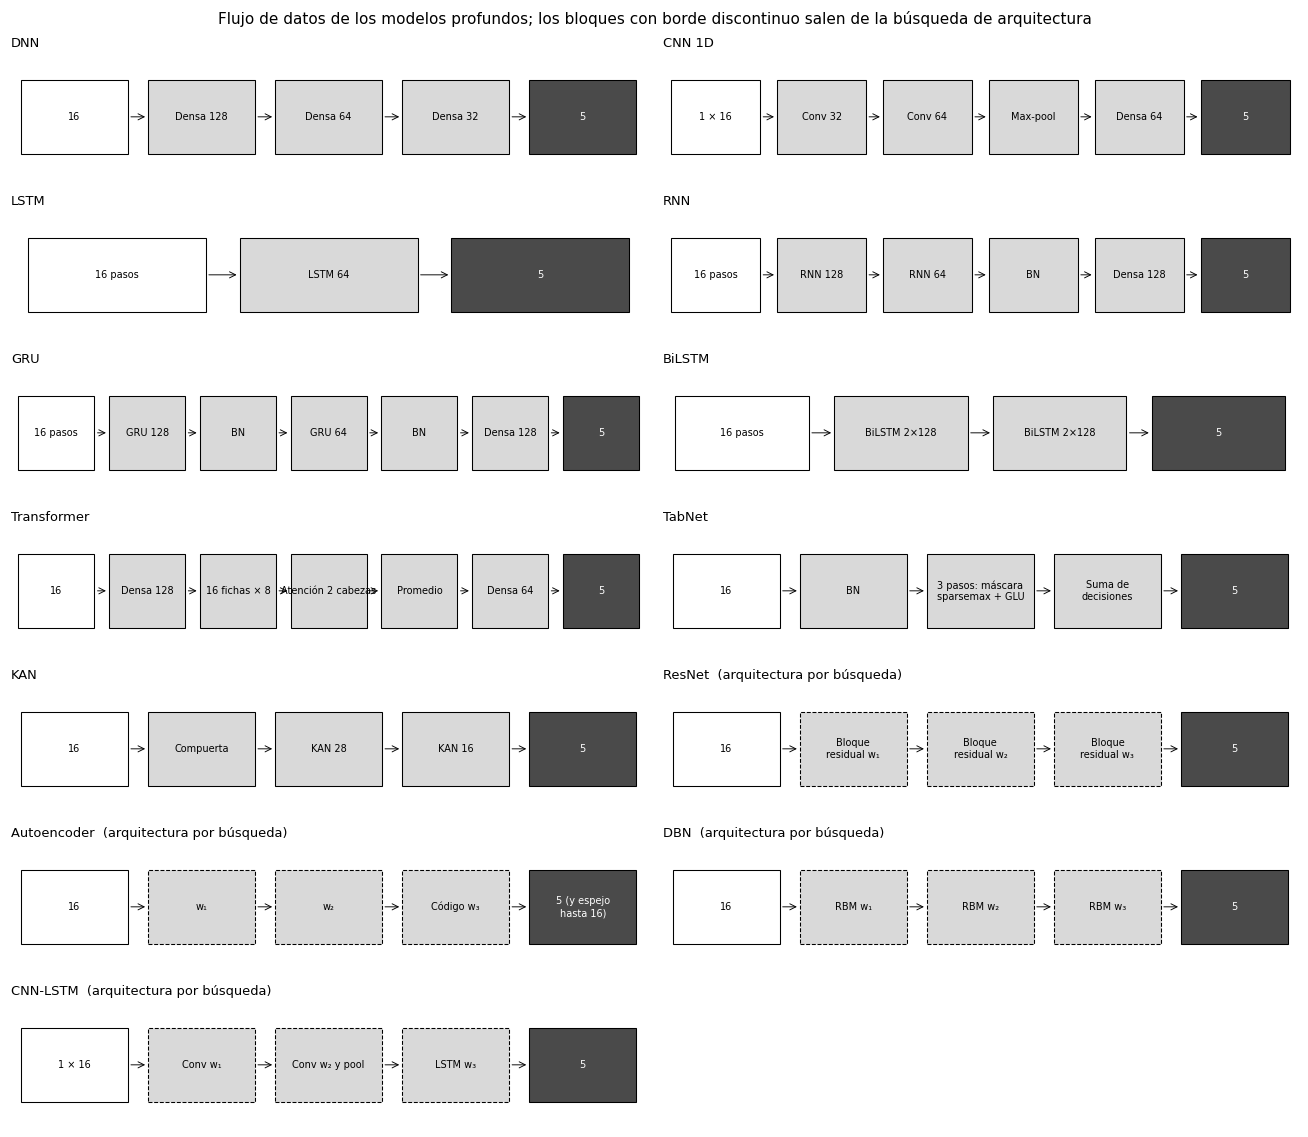

Modelo,Familia,Parámetros,MAC por muestra,Arquitectura,FLOPs por muestra
DNN,Perceptrón multicapa,12 677,12 448,Definida en la literatura,24 896
CNN 1D,Convolucional,39 493,132 928,Definida en la literatura,265 856
LSTM,Recurrente,17 477,266 560,Definida en la literatura,533 120
CNN-LSTM,Híbrida,46 213,462 144,"Búsqueda (referencia 64, 64, 64)",924 288
Autoencoder,Codificador-decodificador,19 093,9 536,"Búsqueda (referencia 64, 64, 64)",19 072
RNN,Recurrente,38 277,469 632,Definida en la literatura,939 264
Transformer,Atención,3 381,11 072,Definida en la literatura,22 144
BiLSTM,Recurrente,530 693,8 406 272,Definida en la literatura,16 812 544
ResNet,Residual,24 005,22 848,"Búsqueda (referencia 64, 64, 64)",45 696
GRU,Recurrente,96 901,1 391 232,Definida en la literatura,2 782 464


In [21]:
DIAGRAMAS = {
    "DNN": ["16", "Densa 128", "Densa 64", "Densa 32", "5"],
    "CNN 1D": ["1 × 16", "Conv 32", "Conv 64", "Max-pool", "Densa 64", "5"],
    "LSTM": ["16 pasos", "LSTM 64", "5"],
    "RNN": ["16 pasos", "RNN 128", "RNN 64", "BN", "Densa 128", "5"],
    "GRU": ["16 pasos", "GRU 128", "BN", "GRU 64", "BN", "Densa 128", "5"],
    "BiLSTM": ["16 pasos", "BiLSTM 2×128", "BiLSTM 2×128", "5"],
    "Transformer": ["16", "Densa 128", "16 fichas × 8", "Atención 2 cabezas", "Promedio", "Densa 64", "5"],
    "TabNet": ["16", "BN", "3 pasos: máscara\nsparsemax + GLU", "Suma de\ndecisiones", "5"],
    "KAN": ["16", "Compuerta", "KAN 28", "KAN 16", "5"],
    "ResNet": ["16", "Bloque\nresidual w₁", "Bloque\nresidual w₂", "Bloque\nresidual w₃", "5"],
    "Autoencoder": ["16", "w₁", "w₂", "Código w₃", "5 (y espejo\nhasta 16)"],
    "DBN": ["16", "RBM w₁", "RBM w₂", "RBM w₃", "5"],
    "CNN-LSTM": ["1 × 16", "Conv w₁", "Conv w₂ y pool", "LSTM w₃", "5"],
}
fig, ejes = plt.subplots(7, 2, figsize=(12, 10.5))
for eje, (nombre, bloques_d) in zip(ejes.ravel(), DIAGRAMAS.items()):
    eje.axis("off")
    eje.set(xlim=(0, len(bloques_d)), ylim=(0, 1))
    for i, b in enumerate(bloques_d):
        relleno = GRIS_OSCURO if i == len(bloques_d) - 1 else ("white" if i == 0 else GRIS_CLARO)
        eje.add_patch(plt.Rectangle((i + 0.08, 0.2), 0.84, 0.6, facecolor=relleno, edgecolor=NEGRO, lw=0.7, ls="--" if "w" in b else "-"))
        eje.text(i + 0.5, 0.5, b, ha="center", va="center", fontsize=6.4, color="white" if i == len(bloques_d) - 1 else NEGRO)
        if i:
            eje.annotate("", xy=(i + 0.08, 0.5), xytext=(i - 0.08, 0.5), arrowprops=dict(arrowstyle="->", lw=0.6))
    eje.set_title(nombre + ("  (arquitectura por búsqueda)" if MOD.CATALOGO[nombre]["busqueda"] else ""), fontsize=8.5, loc="left")
ejes.ravel()[-1].axis("off")
fig.suptitle("Flujo de datos de los modelos profundos; los bloques con borde discontinuo salen de la búsqueda de arquitectura", fontsize=10)
plt.tight_layout()
plt.show()
complejidad_modelos = []
for nombre in CONFIG["modelos"]["base_e1"] + CONFIG["modelos"]["top10"]:
    m = MOD.construir(nombre)
    complejidad_modelos.append({"Modelo": nombre, "Familia": MOD.CATALOGO[nombre]["familia"], "Parámetros": MOD.parametros(m), "MAC por muestra": MOD.contar_mac(m),
                                "Arquitectura": "Búsqueda (referencia 64, 64, 64)" if MOD.CATALOGO[nombre]["busqueda"] else "Definida en la literatura"})
complejidad_modelos = pd.DataFrame(complejidad_modelos)
complejidad_modelos["FLOPs por muestra"] = 2 * complejidad_modelos["MAC por muestra"]
tabla(complejidad_modelos, {"Parámetros": "{:,.0f}", "MAC por muestra": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})

In [22]:
def evidencia(familia):
    '''Estudios incluidos que usan la familia, con sus datos, valores reportados, dispersión y prueba, y el sesgo de reporte.'''
    lista = [e for e in sorted(EXT, key=lambda e: cita_base(e["doi"]).lower()) if familia in [m.strip() for m in e["modelos"].split(";")]]
    filas = [{"Estudio": citar(e["doi"]), "Dataset": e["dataset"], "Valores reportados": e["valores"], "Dispersión": e["dispersion"], "Prueba": e["prueba"]} for e in lista]
    with pd.option_context("display.max_colwidth", 120):
        tabla(pd.DataFrame(filas))
    aleatoria = sum(not agrupa(e["particion"]) and e["particion"] != "no identificada" for e in lista)
    sin_rep = sum(e["repeticiones"] == "no reportadas" for e in lista)
    publicadas = sum(REPRO[e["doi"]]["baselines_ajustados"] == "no" for e in lista)
    interpretar(f"**Sesgo de reporte.** De los {len(lista)} estudios que usan la familia, {aleatoria} parten sin agrupar filas relacionadas, {sin_rep} no reportan repeticiones, "
                f"{sum(e['dispersion'] == 'sí' for e in lista)} reportan dispersión, {sum(not e['prueba'].startswith('ninguna') for e in lista)} aplican alguna prueba y {publicadas} comparan con cifras publicadas. "
                + ("Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables." if publicadas or sin_rep == len(lista) else ""))

#### Modelo 1: CNN-LSTM

- **Referencias.** Fundacional: Donahue et al. (2015), que combinan convoluciones y LSTM en una red entrenada de extremo a extremo (*long-term recurrent convolutional networks*). En el problema la usan Alharthi (2024), Alruwaili y Tunc (2026), Arulalan et al. (2023), Hamad et al. (2025), Mohamed et al. (2026), en su variante CNN-GRU, y SureshBabu y Geetha (2026), como ConvLSTM.
- **Tipo y familia.** Híbrida convolucional y recurrente.
- **Descripción técnica.** Dos convoluciones 1D extraen patrones locales del vector de 16 atributos, $z^{(l)} = \mathrm{ReLU}(W^{(l)} * z^{(l-1)} + b^{(l)})$, un *max-pooling* reduce la secuencia a 8 posiciones y una LSTM la recorre con las compuertas $i_t, f_t, o_t = \sigma(W x_t + U h_{t-1} + b)$, la memoria $c_t = f_t \odot c_{t-1} + i_t \odot \tanh(W_c x_t + U_c h_{t-1} + b_c)$ y el estado $h_t = o_t \odot \tanh(c_t)$; la salida softmax usa el último estado. El flujo es 1 × 16 → $w_1$ filtros → $w_2$ filtros → 8 pasos → $w_3$ unidades → 5.
- **Innovación.** Separa la extracción de rasgos locales, que hace la convolución con pesos compartidos, del modelado de dependencias a lo largo de la secuencia, que hace la LSTM.
- **Fortalezas y limitaciones.** Combina dos sesgos inductivos y es la familia híbrida más usada en la literatura del problema. Sin embargo, ambos sesgos suponen que el orden de las columnas tiene significado, que en una tabla es arbitrario; además, la recurrencia no se paraleliza a lo largo de la secuencia y suma hiperparámetros.
- **Complejidad.** Parámetros $P = 4 w_1 + (3 w_1 + 1) w_2 + 4[(w_2 + w_3) w_3 + 2 w_3] + 5 (w_3 + 1)$; costo por muestra de orden $\mathcal{O}(L k\, w_1 w_2 + T\, 4 (w_2 + w_3) w_3)$, con $L = 16$, $k = 3$ y $T = 8$. Los estudios no reportan un tiempo de entrenamiento comparable.
- **Definición de la arquitectura.** No está definida: Katib et al. (2025) reportan capas LSTM de 128 y 64 unidades, pero no los filtros de la convolución, y los demás estudios no la describen. Por eso se aplica la búsqueda de la sección 14 del enunciado, con la correspondencia aproximada de bloques convolucionales y recurrente.

In [23]:
evidencia("CNN-LSTM")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alharthi (2024),"KDD Cup 99, NSL-KDD, WSN-DS y CICIDS","Exactitud en una de las tablas: CNN 89,10 %, LSTM 92,25 %, CNN-LSTM 95,11 %; propuesto 99,99 %",no,t de Student entre los dos mejores
Alruwaili y Tunc (2026),UNSW-NB15 y Edge-IIoT,"Mejora de exactitud de 0,83 a 4,98 % en UNSW-NB15",no,ninguna
Arulalan et al. (2023),CICIDS2017,No se pudieron asociar las cifras a cada modelo en el texto,no,ninguna
Hamad et al. (2025),CIC-IDS 2017,"Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 %",no,ninguna
Mohamed et al. (2026),"UAVIDS-2025, UNSW-NB15 y ET-BERT","F1 en UAVIDS-2025: AD-GNN 0,962 ± 0,003, TodyNet 0,941",sí,"p < 0,01, sin nombrar la prueba en los pasajes revisados"
SureshBabu y Geetha (2026),UAVIDS-2025,"Exactitud: ANN-GA 91,8 %, ConvLSTM 95,3 %; propuesto 98,7 %",no,ninguna


**Sesgo de reporte.** De los 6 estudios que usan la familia, 4 parten sin agrupar filas relacionadas, 6 no reportan repeticiones, 1 reportan dispersión, 2 aplican alguna prueba y 2 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 2: Autoencoder

- **Referencias.** Fundacional: Hinton y Salakhutdinov (2006). En el problema lo usan como referencia Balgoon (2026), Gharami y Moni (2025), como MLP-AE, Mohamed et al. (2026), como DAE, y Wu et al. (2024), como SNDA; Alissa et al. (2022) y Negm et al. (2024) proponen detectores basados en un autoencoder profundo.
- **Tipo y familia.** Codificador-decodificador.
- **Descripción técnica.** Un codificador $h = f_\phi(\mathbf{x})$ comprime los 16 atributos en un código de dimensión $w_3$ y un decodificador $\hat{\mathbf{x}} = g_\psi(h)$ lo reconstruye. Aquí se implementa como autoencoder supervisado: una cabeza softmax clasifica a partir del código y la pérdida suma la entropía cruzada ponderada y la reconstrucción, $\mathcal{L} = \mathcal{L}_{CE} + \lambda \lVert \mathbf{x} - \hat{\mathbf{x}} \rVert^2$, con λ = 1, de modo que el código debe a la vez separar las clases y conservar la información del flujo.
- **Innovación.** La reconstrucción actúa como un regularizador no supervisado que obliga a la representación a describir el tráfico, no solo a separar las etiquetas.
- **Fortalezas y limitaciones.** No supone ningún orden entre atributos y es barato. Sin embargo, la ponderación λ entre ambas pérdidas es un hiperparámetro más, y en la literatura el autoencoder suele usarse para extraer rasgos que luego clasifica otro modelo, de modo que la variante supervisada es una adaptación declarada.
- **Complejidad.** Con anchos $(w_1, w_2, w_3)$, el codificador tiene $\sum_l (w_{l-1} + 1) w_l$ parámetros con $w_0 = 16$, el decodificador es su espejo y la cabeza suma $5 (w_3 + 1)$; la inferencia solo usa el codificador y la cabeza, $\mathcal{O}(\sum_l w_{l-1} w_l)$.
- **Definición de la arquitectura.** No está definida: Alissa et al. (2022) describen la forma $n \to 2h \to h \to 2h \to n$ sin fijar $h$. Se aplica la búsqueda de la sección 14, con el decodificador espejo.

In [24]:
evidencia("Autoencoder")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Balgoon (2026),UAVIDS-2025 y T-ITS,"F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 %",no,ninguna
Gharami y Moni (2025),"UAV IDS, UKM IDS y otros","Exactitud en UAV IDS: FFCNN 99,99 %, MLP-AE 98,81 %; propuesto 99,99 %",no,ninguna
Mohamed et al. (2026),"UAVIDS-2025, UNSW-NB15 y ET-BERT","F1 en UAVIDS-2025: AD-GNN 0,962 ± 0,003, TodyNet 0,941",sí,"p < 0,01, sin nombrar la prueba en los pasajes revisados"
Wu et al. (2024),CSE-CIC-IDS2018 y CIC-DDoS2019,El propuesto alcanza 99 % de exactitud en CIC-DDoS2019; las tablas de comparación no se pudieron extraer,no,ninguna


**Sesgo de reporte.** De los 4 estudios que usan la familia, 4 parten sin agrupar filas relacionadas, 4 no reportan repeticiones, 1 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 3: RNN

- **Referencias.** Fundacional: Elman (1990). La arquitectura se toma de Biswas et al. (2026), que la usan como línea base en drones; también la usan Abbas et al. (2026), Ashraf et al. (2023), Li et al. (2026b) y Wang et al. (2026).
- **Tipo y familia.** Recurrente simple.
- **Descripción técnica.** En cada paso, $h_t = \mathrm{ReLU}(W_x x_t + W_h h_{t-1} + b)$. Biswas et al. (2026) apilan dos capas, de 128 unidades, que devuelve la secuencia, y de 64, seguidas de normalización por lotes, *dropout* de 0,3 y una densa de 128 con ReLU antes de la salida. El flujo es 16 pasos de un valor → 128 → 64 → 128 → 5.
- **Innovación.** Introduce un estado que se arrastra a lo largo de la secuencia, la idea que después refinan la LSTM y la GRU con compuertas.
- **Fortalezas y limitaciones.** Tiene menos parámetros por unidad que la LSTM y la GRU. Sin embargo, sin compuertas sufre el desvanecimiento o la explosión del gradiente (Bengio et al., 1994), en especial con ReLU, que no acota el estado, y supone un orden entre atributos.
- **Complejidad.** $P = \sum_l (d_{l-1} + h_l + 1) h_l$ más la cabeza; costo de orden $\mathcal{O}(T\, h^2)$ por capa, con $T = 16$, sin paralelismo a lo largo de los pasos.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [25]:
evidencia("RNN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Abbas et al. (2026),UAVIDS-2025,"Precisión en Wormhole: FL-CNN 0,70, FL-RNN 0,78, FL-MLP 0,78 y FL-GCN 0,81; en Blackhole: 0,90, 0,92, 0,94 y 0,92",no,ninguna
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Biswas et al. (2026),ISOT Drone Anomaly Detection,"Exactitud del propuesto: 99,99 %",sí,ninguna
Li et al. (2026b),UAV-NIDD y CICIoT2022,"F1 en UAV-NIDD: TGE-ETD 99,97 ± 0,04 %, YaTC 99,96 ± 0,77 %, FNN 95,20 %, TFE-GNN 93,01 ± 2,14 %, MAML 71,09 %",sí,ninguna
Wang et al. (2026),UAVIDS-2025,"LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 %",sí,t de Student pareada


**Sesgo de reporte.** De los 5 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 3 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

#### Modelo 4: Transformer (TSLT-Net)

- **Referencias.** Fundacional: Vaswani et al. (2017). La arquitectura es TSLT-Net, de Biswas et al. (2026), un Transformer ligero para detectar intrusiones en drones, con su configuración capa a capa en su tabla 1. En el problema usan Transformers Alshamrani y Alghamdi (2026), con FlowTransformer, Li et al. (2026b) y Zhou et al. (2026).
- **Tipo y familia.** Basada en atención.
- **Descripción técnica.** Una densa de 128 con ReLU proyecta el flujo, que se reorganiza en 16 fichas de dimensión 8, se normaliza con LayerNorm y pasa por una atención multicabeza, $\mathrm{Atención}(Q, K, V) = \mathrm{softmax}(Q K^\top / \sqrt{d_k}) V$, con 2 cabezas y $d_k = 4$; luego, un promedio global, una densa de 64 con ReLU, *dropout* de 0,3 y la salida. Biswas et al. (2026) aclaran que las 16 fichas no son pasos de tiempo, sino combinaciones aprendidas de atributos.
- **Innovación.** La atención pondera las interacciones entre fichas según el propio ejemplo, en lugar de fijarlas en los pesos.
- **Fortalezas y limitaciones.** No depende del orden de las columnas, porque la primera densa mezcla todos los atributos, y es muy liviano. Sin embargo, la atención sobre fichas aprendidas es difícil de interpretar, y no tiene conexión residual ni red *feed-forward*, a diferencia del Transformer original.
- **Complejidad.** $\mathcal{O}(n^2 d)$ en la atención, con $n = 16$ fichas y $d = 8$, más $\mathcal{O}(16 \cdot 128)$ en la proyección.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [26]:
evidencia("Transformer")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alshamrani y Alghamdi (2026),UAV-NIDD,"F1 supervisado: LSTM 94,5 ± 0,7 % y FlowTransformer 95,8 ± 0,6 %; propuesto 85,6 ± 0,8 % sin haber visto el ataque",sí,"t pareada, p < 0,001"
Li et al. (2026b),UAV-NIDD y CICIoT2022,"F1 en UAV-NIDD: TGE-ETD 99,97 ± 0,04 %, YaTC 99,96 ± 0,77 %, FNN 95,20 %, TFE-GNN 93,01 ± 2,14 %, MAML 71,09 %",sí,ninguna
Zhou et al. (2026),"ISCXVPN2016, CICIDS-2018, TON IoT y CIC IoT 2023","Exactitud en ISCXVPN2016: LSTM 95,9 %, CNN 94,95 %",no,ninguna


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 2 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

#### Modelo 5: BiLSTM

- **Referencias.** Fundacional: Graves y Schmidhuber (2005). La arquitectura se toma de Balgoon (2026), que reporta su BiLSTM como línea base en UAVIDS-2025; también la usan Ashraf et al. (2023) y Wang et al. (2026).
- **Tipo y familia.** Recurrente bidireccional.
- **Descripción técnica.** Dos LSTM recorren la secuencia en sentidos opuestos y su estado se concatena, $h_t = [\overrightarrow{h}_t; \overleftarrow{h}_t]$, con las compuertas de la LSTM. Balgoon (2026) usa dos capas de 128 unidades por dirección con *dropout* de 0,3; la salida concatena el último estado de cada dirección.
- **Innovación.** Cada posición ve el contexto anterior y el posterior, lo que en un vector de atributos equivale a no privilegiar un extremo de la secuencia.
- **Fortalezas y limitaciones.** Es la variante recurrente con más capacidad del Top 10. Sin embargo, es la más costosa, con cerca de 531 000 parámetros, y Balgoon (2026) reporta para ella un F1 macro de solo 77,87 % en UAVIDS-2025.
- **Complejidad.** $\mathcal{O}(2\, T\, 4 (d + h) h)$ por capa, con $T = 16$ y $h = 128$.
- **Definición de la arquitectura.** Definida por Balgoon (2026), donde es un componente de su modelo propuesto evaluado también por separado; no aplica la búsqueda.

In [27]:
evidencia("BiLSTM")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Balgoon (2026),UAVIDS-2025 y T-ITS,"F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 %",no,ninguna
Wang et al. (2026),UAVIDS-2025,"LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 %",sí,t de Student pareada


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 1 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

#### Modelo 6: ResNet

- **Referencias.** Fundacional: He et al. (2016). En el problema la usan Hakeem et al. (2025) y Katib et al. (2025), en ambos casos como red convolucional para imágenes adaptada a otros datos; para tablas, Gorishniy et al. (2021) proponen la variante residual densa que aquí se implementa.
- **Tipo y familia.** Residual.
- **Descripción técnica.** Cada bloque aprende un residuo sobre su entrada, $\mathbf{z}_{l} = \mathrm{ReLU}(F(\mathbf{z}_{l-1}) + S \mathbf{z}_{l-1})$, con $F$ = densa, normalización, ReLU, densa y normalización, y $S$ la identidad o una proyección lineal si cambia el ancho; 3 bloques de anchos $(w_1, w_2, w_3)$ y la salida.
- **Innovación.** El atajo de identidad permite entrenar redes profundas sin degradación, porque el gradiente fluye por él aunque $F$ se sature.
- **Fortalezas y limitaciones.** No supone orden entre atributos y es estable de entrenar. Sin embargo, en tablas de 16 columnas la profundidad aporta poco, y en datos tabulares su ventaja frente a un perceptrón depende del conjunto (Gorishniy et al., 2021).
- **Complejidad.** $\mathcal{O}(\sum_l w_{l-1} w_l + w_l^2)$ por muestra.
- **Definición de la arquitectura.** No está definida en la literatura del problema; se aplica la búsqueda de la sección 14, con el ancho de cada bloque residual.

In [28]:
evidencia("ResNet")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Hakeem et al. (2025),datos ciberfísicos de GPS,"Exactitud: ResNet 90,99 %, MLP 89,49 %, CNN 86,36 %, LSTM 82,45 %",no,ninguna
Katib et al. (2025),InSDN,"Exactitud del propuesto: 99,88 %",no,ninguna


**Sesgo de reporte.** De los 2 estudios que usan la familia, 2 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 1 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 7: GRU

- **Referencias.** Fundacional: Cho et al. (2014). La arquitectura se toma de Biswas et al. (2026); también la usan Aburasain (2024), Ashraf et al. (2023), Attaullah et al. (2026b) y Hamad et al. (2025).
- **Tipo y familia.** Recurrente con compuertas.
- **Descripción técnica.** La compuerta de actualización $z_t = \sigma(W_z x_t + U_z h_{t-1})$ y la de reinicio $r_t = \sigma(W_r x_t + U_r h_{t-1})$ combinan el estado anterior con el candidato $\tilde{h}_t = \tanh(W x_t + U (r_t \odot h_{t-1}))$ en $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$. Biswas et al. (2026) apilan GRU de 128 y de 64, cada una con normalización por lotes y *dropout* de 0,3, y una densa de 128 antes de la salida.
- **Innovación.** Logra un control del flujo del gradiente parecido al de la LSTM con dos compuertas en lugar de tres y sin celda de memoria aparte.
- **Fortalezas y limitaciones.** Es más estable que la RNN simple. Sin embargo, supone un orden entre atributos y, con 128 unidades, es la segunda más costosa del Top 10.
- **Complejidad.** $\mathcal{O}(T\, 3 (d + h) h)$ por capa.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [29]:
evidencia("GRU")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Aburasain (2024),ToN-IoT y Edge-IIoTset,"Exactitud: LSTM de 96,20 a 96,95 %, GRU de 96,00 a 96,50 %",no,ninguna
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Attaullah et al. (2026b),conjunto multimodal de UAV,"Exactitud del propuesto: 99,49 %",no,ninguna
Biswas et al. (2026),ISOT Drone Anomaly Detection,"Exactitud del propuesto: 99,99 %",sí,ninguna
Hamad et al. (2025),CIC-IDS 2017,"Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 %",no,ninguna


**Sesgo de reporte.** De los 5 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 3 no reportan repeticiones, 1 reportan dispersión, 0 aplican alguna prueba y 2 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 8: KAN

- **Referencias.** Fundacional: Liu et al. (2024). La arquitectura es el clasificador de ataques de H-MicroKAN, de Bakiri et al. (2026), el único estudio del problema que la usa, sobre UAVIDS-2025 y con partición por nodo.
- **Tipo y familia.** Red de Kolmogorov-Arnold.
- **Descripción técnica.** Por el teorema de Kolmogorov-Arnold, una función continua de varias variables se escribe como composición de funciones de una variable. Una capa KAN pone una función aprendible en cada arista, $y_j = \sum_i \varphi_{ij}(x_i)$, y aquí cada $\varphi_{ij}(x) = \sum_{k=1}^{K} w_{ijk}\, \exp(-((x - \mu_k)/h)^2)$ usa $K = 5$ bases gaussianas fijas en [−5, 5], la formulación FastKAN que adoptan Bakiri et al. (2026). La red aplica una compuerta $\mathbf{x} \odot \sigma(W_2 \mathrm{ReLU}(W_1 \mathbf{x}))$, dos capas KAN de 28 y 16 neuronas con normalización, GELU y *dropout* de 0,25 y 0,20, y la salida.
- **Innovación.** Traslada la no linealidad de los nodos a las aristas, lo que da fronteras flexibles con pocos parámetros y funciones de cada atributo que se pueden graficar.
- **Fortalezas y limitaciones.** Es el modelo más liviano del Top 10 después del Transformer y se diseñó para microcontroladores. Sin embargo, el recorte en [−5, 5] trunca los valores extremos, y Bakiri et al. (2026) lo usan como la segunda etapa de un clasificador jerárquico, de modo que aplicarlo directamente a las 5 clases es una adaptación declarada.
- **Complejidad.** $n_{in} n_{out} K + n_{out}$ parámetros por capa, la fórmula que publican sus autores; costo $\mathcal{O}(n_{in} n_{out} K)$.
- **Definición de la arquitectura.** Definida por Bakiri et al. (2026), en su tabla 2; no aplica la búsqueda.

In [30]:
evidencia("KAN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Bakiri et al. (2026),UAVIDS-2025 y UAV-NIDD,"Exactitud en cinco clases en UAVIDS-2025: 92,50 %; KAN plana 93,35 %",no,ninguna


**Sesgo de reporte.** De los 1 estudios que usan la familia, 0 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 9: TabNet

- **Referencias.** Fundacional: Arik y Pfister (2021). En el problema lo usan Hadi et al. (2026), como segunda etapa de un detector en tres niveles.
- **Tipo y familia.** Atención secuencial para datos tabulares.
- **Descripción técnica.** En cada paso de decisión, un transformador atento elige qué atributos mirar con una máscara $M[i] = \mathrm{sparsemax}(P[i-1] \cdot h_i(a[i-1]))$, donde $P[i-1]$ penaliza reutilizar atributos ya elegidos con el factor γ, y un transformador de atributos con bloques GLU procesa $M[i] \odot \mathbf{x}$; la salida suma las decisiones de los pasos. La pérdida agrega una regularización de dispersión de las máscaras.
- **Innovación.** La selección de atributos es por ejemplo e interpretable, porque las máscaras indican qué atributos usó cada decisión.
- **Fortalezas y limitaciones.** Fue diseñado para tablas y no supone orden entre columnas. Sin embargo, es sensible a sus hiperparámetros, la normalización por lotes fantasma depende del tamaño del lote, y en la comparación de Gorishniy et al. (2021) no supera de forma consistente a otros modelos ni a los árboles potenciados.
- **Complejidad.** $\mathcal{O}(N_{steps}\, (d\, n_a + (n_d + n_a)^2))$ por muestra.
- **Definición de la arquitectura.** El artículo define los bloques y su número, y se usa la configuración por defecto de la implementación de referencia, pytorch-tabnet: $n_d = n_a = 8$, 3 pasos, γ = 1,3 y λ de dispersión de 10⁻³. No aplica la búsqueda.

In [31]:
evidencia("TabNet")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Hadi et al. (2026),GCS-NIDD,"Exactitud por modelo: TabNet 93,10 %, LightGBM 90,20 %, BLS 89,70 %; fusión 99,30 %",no,ninguna


**Sesgo de reporte.** De los 1 estudios que usan la familia, 0 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

#### Modelo 10: DBN

- **Referencias.** Fundacional: Hinton et al. (2006). En el problema la usan como referencia Alotaibi et al. (2024), Babu et al. (2024) y Negm et al. (2024), como IDBN y DPC-DBN, y Tan et al. (2019) proponen una DBN optimizada con PSO.
- **Tipo y familia.** Generativa preentrenada capa a capa.
- **Descripción técnica.** Una pila de máquinas de Boltzmann restringidas, cada una con energía $E(\mathbf{v}, \mathbf{h}) = -\mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h} - \mathbf{h}^\top W \mathbf{v}$ (la primera con unidades visibles gaussianas), se preentrena sin etiquetas con divergencia contrastiva de un paso, $\Delta W \propto \langle \mathbf{h} \mathbf{v}^\top \rangle_{datos} - \langle \mathbf{h} \mathbf{v}^\top \rangle_{1}$, y luego se ajusta con la entropía cruzada como un perceptrón con sigmoides.
- **Innovación.** Fue el primer método que permitió entrenar redes profundas, al inicializar los pesos con una representación generativa en lugar de valores aleatorios.
- **Fortalezas y limitaciones.** El preentrenamiento puede ayudar con pocos datos etiquetados. Sin embargo, con optimizadores modernos y decenas de miles de ejemplos su ventaja suele desaparecer, y ningún estudio de 2025 o 2026 la usa, lo que muestra que la familia está en retirada.
- **Complejidad.** $\mathcal{O}(\sum_l w_{l-1} w_l)$ por muestra en inferencia, más el preentrenamiento, de orden $\mathcal{O}(E\, n \sum_l w_{l-1} w_l)$ con $E$ épocas por RBM.
- **Definición de la arquitectura.** No está definida: Tan et al. (2019) la optimizan con PSO para KDD Cup 99, sin una configuración aplicable a estos datos en los pasajes revisados, y los demás estudios la toman de otros trabajos. Se aplica la búsqueda de la sección 14, con las unidades de cada RBM.

In [32]:
evidencia("DBN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alotaibi et al. (2024),no identificado,"Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %",no,ninguna
Babu et al. (2024),no identificado,"Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %; propuesto 99,63 %",no,ninguna
Negm et al. (2024),NSL-KDD,"Exactitud: propuesto 99,36 %, IDBN 95,32 %, DPC-DBN 94,39 %",no,ninguna


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 3 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 1 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### 3.4 Comparación crítica y *gap* de investigación

**Matriz comparativa.** La matriz reúne, para los diez modelos, la familia, los parámetros y FLOPs de la implementación de este entregable, los datos que requiere, el mejor valor que reporta la literatura del problema y la fortaleza y la limitación principales. Los valores de la literatura no se comparan entre sí, porque provienen de conjuntos de datos y protocolos distintos.

In [33]:
MATRIZ_CUALITATIVA = {
    "CNN-LSTM": ("Secuencia de atributos", "Rasgos locales y dependencias en un solo modelo", "Supone un orden de columnas arbitrario"),
    "Autoencoder": ("Vector, sin orden", "La reconstrucción regulariza la representación", "Un hiperparámetro más (λ)"),
    "RNN": ("Secuencia de atributos", "Pocos parámetros por unidad", "Gradiente inestable sin compuertas"),
    "Transformer": ("Vector, sin orden", "Muy liviano; atención por ejemplo", "Fichas aprendidas difíciles de interpretar"),
    "BiLSTM": ("Secuencia de atributos", "Contexto en ambos sentidos", "El más costoso del Top 10"),
    "ResNet": ("Vector, sin orden", "Entrenamiento estable", "Profundidad poco útil con 16 columnas"),
    "GRU": ("Secuencia de atributos", "Control del gradiente con dos compuertas", "Costosa y dependiente del orden"),
    "KAN": ("Vector acotado en [−5, 5]", "Liviana; funciones por atributo graficables", "Trunca valores extremos"),
    "TabNet": ("Vector, sin orden", "Selección de atributos interpretable", "Sensible a hiperparámetros y al lote"),
    "DBN": ("Vector, sin orden", "Preentrenamiento sin etiquetas", "Familia en retirada; costo de preentrenar"),
}
filas_m = []
for _, f in complejidad_modelos[complejidad_modelos["Modelo"].isin(MATRIZ_CUALITATIVA)].iterrows():
    entrada, fuerte, debil = MATRIZ_CUALITATIVA[f["Modelo"]]
    filas_m.append({"Modelo": f["Modelo"], "Familia": f["Familia"], "Parámetros": f["Parámetros"], "FLOPs por muestra": f["FLOPs por muestra"], "Entrada que requiere": entrada,
                    "Estudios": int(puntaje.loc[puntaje["modelo"] == f["Modelo"], "estudios"].item()), "Con UAVIDS-2025": int(puntaje.loc[puntaje["modelo"] == f["Modelo"], "estudios_uavids"].item()),
                    "Fortaleza": fuerte, "Limitación": debil})
tabla(pd.DataFrame(filas_m), {"Parámetros": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})
anios = pd.DataFrame([{"anio": int(e["anio"]), "familia": m.strip()} for e in EXT for m in e["modelos"].split(";") if m.strip()])
tendencia = anios.assign(periodo=np.where(anios["anio"] >= 2025, "2025–2026", "2019–2024")).groupby(["familia", "periodo"]).size().unstack(fill_value=0)
estudios_periodo = pd.Series([int(e["anio"]) >= 2025 for e in EXT]).map({True: "2025–2026", False: "2019–2024"}).value_counts()
tendencia_pct = (100 * tendencia / estudios_periodo).round(1)
tabla(tendencia_pct.loc[["DNN/MLP", "CNN", "LSTM", "CNN-LSTM", "GRU", "Transformer", "GNN", "KAN", "TabNet", "DBN", "Autoencoder"]].reset_index(names="Familia"),
      {c: "{:.1f}" for c in tendencia_pct.columns})
interpretar(f'''**Interpretación.** En los {estudios_periodo["2019–2024"]} estudios de 2019 a 2024 y los {estudios_periodo["2025–2026"]} de 2025 a 2026, la proporción que usa Transformers pasa de {num(tendencia_pct.loc["Transformer", "2019–2024"], 1)} % a {num(tendencia_pct.loc["Transformer", "2025–2026"], 1)} %, la de GNN de {num(tendencia_pct.loc["GNN", "2019–2024"], 1)} % a {num(tendencia_pct.loc["GNN", "2025–2026"], 1)} %, y KAN y TabNet aparecen solo en el periodo reciente, mientras que la DBN pasa de {num(tendencia_pct.loc["DBN", "2019–2024"], 1)} % a {num(tendencia_pct.loc["DBN", "2025–2026"], 1)} %. En costo, la matriz va de unos 3400 parámetros en el Transformer a más de medio millón en la BiLSTM.

Así mismo, la tendencia es clara hacia la atención, los grafos y los modelos livianos para despliegue a bordo, con modelos híbridos y propuestos que superan a líneas base sin ajustar. En reproducibilidad, el panorama es el de la sección 3.1: un solo estudio con código público, ninguno con líneas base ajustadas con el mismo presupuesto y solo dos que agrupan las filas relacionadas al partir.

En consecuencia, se formula el *gap* sobre esas carencias, que se pueden refutar con la hoja de extracción.''')

Modelo,Familia,Parámetros,FLOPs por muestra,Entrada que requiere,Estudios,Con UAVIDS-2025,Fortaleza,Limitación
CNN-LSTM,Híbrida,46 213,924 288,Secuencia de atributos,6,2,Rasgos locales y dependencias en un solo modelo,Supone un orden de columnas arbitrario
Autoencoder,Codificador-decodificador,19 093,19 072,"Vector, sin orden",4,2,La reconstrucción regulariza la representación,Un hiperparámetro más (λ)
RNN,Recurrente,38 277,939 264,Secuencia de atributos,5,2,Pocos parámetros por unidad,Gradiente inestable sin compuertas
Transformer,Atención,3 381,22 144,"Vector, sin orden",3,0,Muy liviano; atención por ejemplo,Fichas aprendidas difíciles de interpretar
BiLSTM,Recurrente,530 693,16 812 544,Secuencia de atributos,3,2,Contexto en ambos sentidos,El más costoso del Top 10
ResNet,Residual,24 005,45 696,"Vector, sin orden",2,0,Entrenamiento estable,Profundidad poco útil con 16 columnas
GRU,Recurrente,96 901,2 782 464,Secuencia de atributos,5,0,Control del gradiente con dos compuertas,Costosa y dependiente del orden
KAN,Kolmogorov-Arnold,4 845,9 376,"Vector acotado en [−5, 5]",1,1,Liviana; funciones por atributo graficables,Trunca valores extremos
TabNet,Atención,6 728,17 232,"Vector, sin orden",1,0,Selección de atributos interpretable,Sensible a hiperparámetros y al lote
DBN,Generativa preentrenada,9 733,19 072,"Vector, sin orden",3,0,Preentrenamiento sin etiquetas,Familia en retirada; costo de preentrenar


Familia,2019–2024,2025–2026
DNN/MLP,"40,0","67,9"
CNN,"40,0","60,7"
LSTM,"40,0","28,6"
CNN-LSTM,"13,3","14,3"
GRU,"13,3","10,7"
Transformer,"0,0","10,7"
GNN,"0,0","10,7"
KAN,"0,0","3,6"
TabNet,"0,0","3,6"
DBN,"20,0","0,0"


**Interpretación.** En los 15 estudios de 2019 a 2024 y los 28 de 2025 a 2026, la proporción que usa Transformers pasa de 0,0 % a 10,7 %, la de GNN de 0,0 % a 10,7 %, y KAN y TabNet aparecen solo en el periodo reciente, mientras que la DBN pasa de 20,0 % a 0,0 %. En costo, la matriz va de unos 3400 parámetros en el Transformer a más de medio millón en la BiLSTM.

Así mismo, la tendencia es clara hacia la atención, los grafos y los modelos livianos para despliegue a bordo, con modelos híbridos y propuestos que superan a líneas base sin ajustar. En reproducibilidad, el panorama es el de la sección 3.1: un solo estudio con código público, ninguno con líneas base ajustadas con el mismo presupuesto y solo dos que agrupan las filas relacionadas al partir.

En consecuencia, se formula el *gap* sobre esas carencias, que se pueden refutar con la hoja de extracción.

In [34]:
SECUENCIALES = {"CNN", "LSTM", "CNN-LSTM", "RNN", "GRU", "BiLSTM"}
n_secuenciales = sum(bool(SECUENCIALES & {m.strip() for m in e["modelos"].split(";")}) for e in EXT)
uavids_ext = [e for e in EXT if "UAVIDS-2025" in e["dataset"]]
interpretar(f'''**Gap en la literatura.** Ningún estudio incluido compara diez o más arquitecturas de Deep Learning de familias distintas sobre UAVIDS-2025 con una partición que agrupe los flujos de una misma serie, con el mismo presupuesto de ajuste para todos los modelos y con inferencia estadística sobre repeticiones. La hoja de extracción permite refutarlo: de los {len(uavids_ext)} estudios que usan UAVIDS-2025, {sum(agrupa(e["particion"]) for e in uavids_ext)} agrupa las filas al partir, y lo hace por nodo y no por serie (Bakiri et al., 2026); ninguno ajusta sus líneas base con un presupuesto equivalente, {sum(not e["prueba"].startswith("ninguna") for e in uavids_ext)} aplican alguna prueba estadística y ninguno corrige por comparaciones múltiples.

**Conexión con las preguntas de investigación.** RQ1 y RQ2 responden directamente al *gap*, porque comparan el Top 10 con el baseline del Entregable 1 y con un árbol potenciado ajustado con el mismo presupuesto, bajo la partición agrupada. RQ3 pone a prueba un supuesto que la literatura da por hecho sin contrastarlo: que leer los atributos como una secuencia aporta, como hacen la CNN, la LSTM y sus variantes en {n_secuenciales} de los {len(EXT)} estudios. Si RQ3 rechaza su hipótesis nula con una diferencia negativa, buena parte de esas arquitecturas estaría imponiendo un sesgo inductivo que perjudica en datos tabulares.''')

**Gap en la literatura.** Ningún estudio incluido compara diez o más arquitecturas de Deep Learning de familias distintas sobre UAVIDS-2025 con una partición que agrupe los flujos de una misma serie, con el mismo presupuesto de ajuste para todos los modelos y con inferencia estadística sobre repeticiones. La hoja de extracción permite refutarlo: de los 12 estudios que usan UAVIDS-2025, 1 agrupa las filas al partir, y lo hace por nodo y no por serie (Bakiri et al., 2026); ninguno ajusta sus líneas base con un presupuesto equivalente, 3 aplican alguna prueba estadística y ninguno corrige por comparaciones múltiples.

**Conexión con las preguntas de investigación.** RQ1 y RQ2 responden directamente al *gap*, porque comparan el Top 10 con el baseline del Entregable 1 y con un árbol potenciado ajustado con el mismo presupuesto, bajo la partición agrupada. RQ3 pone a prueba un supuesto que la literatura da por hecho sin contrastarlo: que leer los atributos como una secuencia aporta, como hacen la CNN, la LSTM y sus variantes en 31 de los 43 estudios. Si RQ3 rechaza su hipótesis nula con una diferencia negativa, buena parte de esas arquitecturas estaría imponiendo un sesgo inductivo que perjudica en datos tabulares.

## 4. Implementación de los modelos del benchmark

En esta sección se implementan los 13 modelos profundos y las tres líneas base no profundas bajo el mismo entorno, el mismo pipeline y el mismo presupuesto de ajuste, siguiendo la ruta F1 del enunciado y el protocolo de su sección 11. El orden es el del enunciado: diseño experimental (4.1), implementación y ajuste (4.2), requisitos experimentales, con el piloto, la potencia y la búsqueda de arquitectura (4.3), buenas prácticas contra la fuga (4.4), evaluación (4.5) y robustez, interpretabilidad y ablación (4.6).

### 4.1 Diseño experimental

| Elemento | Definición |
|---|---|
| Variables de entrada | Los 16 atributos de tráfico y desempeño, recortados, transformados con $\log(1 + x)$ y estandarizados con entrenamiento (sección 2.2.1) |
| Variable objetivo y tarea | Una de las 5 clases; clasificación multiclase de cada flujo, sin horizonte ni rezagos |
| División del dataset | Entrenamiento, validación y prueba heredados del Entregable 1 (64, 16 y 20 %), estratificados por clase y agrupados por bloques, idénticos para todos los modelos; la prueba se toca una sola vez por corrida |
| Pipeline | Un único pipeline por modelo, en `codigo/`: datos y transformación (`datos.py`), modelos (`modelos.py`), entrenamiento (`motor.py`), líneas base (`clasicos.py`) y ejecución en paralelo con reanudación (`ejecutor.py`) |
| Selección de hiperparámetros | Búsqueda aleatoria con las mismas 12 configuraciones para los 13 modelos profundos, 15 épocas y una semilla, elegida solo con el F1 macro de validación; LightGBM y la regresión logística reciben 12 configuraciones de su propio espacio |
| Arquitectura no predefinida | Búsqueda de la sección 14 para ResNet, Autoencoder, DBN y CNN-LSTM: 1000 arquitecturas en la fase 1 y k finalistas con 5 semillas en la fase 2 |
| Repeticiones | R semillas por modelo, con R fijado por el piloto (sección 4.3) y las mismas semillas para todos |
| Validación interna | Partición fija de validación para seleccionar, más una validación cruzada 5 × 2 agrupada por bloques sobre entrenamiento + validación para las pruebas de Nadeau y Bengio y de Alpaydin en el contraste de RQ2 |
| Evaluación | Mismas métricas sobre la misma prueba (sección 4.5) |

La validación anidada completa, que repetiría el ajuste dentro de cada pliegue externo, multiplicaría por 12 el costo de todo el benchmark, de modo que se reemplaza por la comparación entre el puntaje de validación usado para seleccionar y el de prueba (tabla B, sección 7), que mide el mismo optimismo por selección.

### 4.2 Implementación de los modelos

Todos los modelos profundos se implementan en PyTorch y se entrenan con Adam (Kingma y Ba, 2015), con la versión de la configuración del entorno; TabNet usa la red de la implementación de referencia pytorch-tabnet y los demás, capas estándar de PyTorch. Ningún modelo usa pesos preentrenados, de modo que no aplica la comparación con y sin preentrenamiento ni la fuga por modelos preentrenados. Las líneas base usan scikit-learn y LightGBM.

Hay una corrección respecto del Entregable 1: los tres modelos base usan ahora el *dropout* exacto del código de los autores (Zeng, 2025), que el Entregable 1 declaró como desviación y evaluó con un análisis de sensibilidad.

In [35]:
FUENTE = {"DNN": "Zeng (2025)", "CNN 1D": "Zeng (2025)", "LSTM": "Zeng (2025)", "RNN": "Biswas et al. (2026)", "GRU": "Biswas et al. (2026)", "BiLSTM": "Balgoon (2026)",
          "Transformer": "Biswas et al. (2026), TSLT-Net", "TabNet": "Arik y Pfister (2021); pytorch-tabnet 4.1.0", "KAN": "Bakiri et al. (2026)", "ResNet": "Búsqueda (sección 4.3)",
          "Autoencoder": "Búsqueda (sección 4.3)", "DBN": "Búsqueda (sección 4.3)", "CNN-LSTM": "Búsqueda (sección 4.3)"}
ADAPTACION = {"DNN": "Ninguna", "CNN 1D": "Ninguna", "LSTM": "Ninguna", "RNN": "Ninguna; la secuencia es la de las 16 columnas", "GRU": "Ninguna; la secuencia es la de las 16 columnas",
              "BiLSTM": "Cabeza lineal sobre los dos últimos estados, que el artículo no detalla", "Transformer": "PyTorch MultiheadAttention en lugar de Keras", "TabNet": "Entrenado con el motor común",
              "KAN": "Clasificador de 5 clases en lugar de 4 ataques", "ResNet": "Bloque residual denso", "Autoencoder": "Supervisado, λ = 1", "DBN": "CD-1, 3 épocas por RBM",
              "CNN-LSTM": "Correspondencia aproximada de 3 bloques"}
fuera_rango = float((np.abs(H["X"][ID_ENT]) > 5).mean())
tabla(complejidad_modelos.assign(Fuente=complejidad_modelos["Modelo"].map(FUENTE), Adaptación=complejidad_modelos["Modelo"].map(ADAPTACION))[["Modelo", "Familia", "Fuente", "Adaptación", "Parámetros", "FLOPs por muestra"]],
      {"Parámetros": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})
print(f"Valores estandarizados de entrenamiento fuera de [-5, 5], que la KAN recorta: {num(100 * fuera_rango, 2)} %")

Modelo,Familia,Fuente,Adaptación,Parámetros,FLOPs por muestra
DNN,Perceptrón multicapa,Zeng (2025),Ninguna,12 677,24 896
CNN 1D,Convolucional,Zeng (2025),Ninguna,39 493,265 856
LSTM,Recurrente,Zeng (2025),Ninguna,17 477,533 120
CNN-LSTM,Híbrida,Búsqueda (sección 4.3),Correspondencia aproximada de 3 bloques,46 213,924 288
Autoencoder,Codificador-decodificador,Búsqueda (sección 4.3),"Supervisado, λ = 1",19 093,19 072
RNN,Recurrente,Biswas et al. (2026),Ninguna; la secuencia es la de las 16 columnas,38 277,939 264
Transformer,Atención,"Biswas et al. (2026), TSLT-Net",PyTorch MultiheadAttention en lugar de Keras,3 381,22 144
BiLSTM,Recurrente,Balgoon (2026),"Cabeza lineal sobre los dos últimos estados, que el artículo no detalla",530 693,16 812 544
ResNet,Residual,Búsqueda (sección 4.3),Bloque residual denso,24 005,45 696
GRU,Recurrente,Biswas et al. (2026),Ninguna; la secuencia es la de las 16 columnas,96 901,2 782 464


Valores estandarizados de entrenamiento fuera de [-5, 5], que la KAN recorta: 0,14 %


#### 4.2.1 Ajuste de hiperparámetros con el mismo presupuesto

Cada modelo profundo recibe las mismas 12 configuraciones de tasa de aprendizaje, *weight decay* y tamaño de lote, muestreadas con semilla 2026 de la rejilla del preregistro, con una semilla de entrenamiento y un máximo de 15 épocas. Los modelos con búsqueda de arquitectura se ajustan con la arquitectura de referencia (64, 64, 64) y *dropout* (0, 1, 0), como pide la sección 14.3, de modo que la búsqueda posterior solo cambia los anchos y el *dropout*. Los demás hiperparámetros de cada arquitectura, como el *dropout* de los modelos definidos, quedan en los valores de su fuente.

Configuración,DNN,CNN 1D,LSTM,CNN-LSTM,Autoencoder,RNN,Transformer,BiLSTM,ResNet,GRU,KAN,TabNet,DBN
"0: lr 10⁻⁴, wd 10⁻⁴, lote 256","0,9119","0,9229","0,7962","0,9261","0,9106","0,9278","0,9186","0,8452","0,9230","0,9140","0,9116","0,8158","0,6765"
"1: lr 10⁻³, wd 0, lote 512","0,9303","0,9334","0,8758","0,9231","0,9260","0,9265","0,9279","0,8814","0,9190","0,9270","0,9161","0,9088","0,8958"
"2: lr 3 × 10⁻³, wd 10⁻⁵, lote 512","0,9293","0,9288","0,8959","0,9295","0,9242","0,9280","0,9289","0,9036","0,9239","0,9214","0,9245","0,9112","0,9184"
"3: lr 3 × 10⁻³, wd 10⁻⁴, lote 128","0,9307","0,9289","0,9144","0,9235","0,9270","0,9212","0,9267","0,9119","0,9252","0,9187","0,9302","0,9156","0,9200"
"4: lr 10⁻⁴, wd 10⁻⁴, lote 128","0,9183","0,9281","0,8377","0,9287","0,9194","0,9286","0,9140","0,8614","0,9264","0,9283","0,9177","0,8670","0,7812"
"5: lr 3 × 10⁻³, wd 0, lote 256","0,9263","0,9221","0,9151","0,9336","0,9283","0,9266","0,9049","0,9069","0,9245","0,9257","0,9276","0,9135","0,9259"
"6: lr 3 × 10⁻³, wd 10⁻⁴, lote 512","0,9296","0,9286","0,8924","0,9292","0,9252","0,9313","0,9263","0,9169","0,9225","0,9249","0,9256","0,9207","0,9140"
"7: lr 3 × 10⁻³, wd 10⁻⁵, lote 128","0,9287","0,9302","0,9212","0,9240","0,9279","0,9201","0,9212","0,9209","0,9257","0,9188","0,9328","0,8999","0,9281"
"8: lr 10⁻³, wd 0, lote 256","0,9317","0,9310","0,8809","0,9304","0,9272","0,9249","0,9256","0,8815","0,9280","0,9297","0,9276","0,9136","0,9116"
"9: lr 3 × 10⁻³, wd 0, lote 128","0,9293","0,9275","0,9199","0,9226","0,9281","0,9031","0,9281","0,8980","0,9257","0,9257","0,9332","0,9146","0,9304"


Modelo,Mejor F1 de validación,Peor,Rango,Configuración elegida,Minutos del ajuste,Divergentes
DNN,"0,9317","0,9119","0,0198","lr 10⁻³, wd 0, lote 256","6,3",0
CNN 1D,"0,9334","0,9221","0,0113","lr 10⁻³, wd 0, lote 512","23,1",0
LSTM,"0,9212","0,7962","0,1250","lr 3 × 10⁻³, wd 10⁻⁵, lote 128","40,1",0
CNN-LSTM,"0,9336","0,9226","0,0109","lr 3 × 10⁻³, wd 0, lote 256","47,7",0
Autoencoder,"0,9283","0,9106","0,0177","lr 3 × 10⁻³, wd 0, lote 256","9,6",0
RNN,"0,9313","0,9031","0,0282","lr 3 × 10⁻³, wd 10⁻⁴, lote 512","157,6",0
Transformer,"0,9289","0,9049","0,0240","lr 3 × 10⁻³, wd 10⁻⁵, lote 512","13,5",0
BiLSTM,"0,9209","0,8452","0,0758","lr 3 × 10⁻³, wd 10⁻⁵, lote 128","608,1",0
ResNet,"0,9280","0,9190","0,0090","lr 10⁻³, wd 0, lote 256","14,6",0
GRU,"0,9297","0,9140","0,0157","lr 10⁻³, wd 0, lote 256","228,6",0


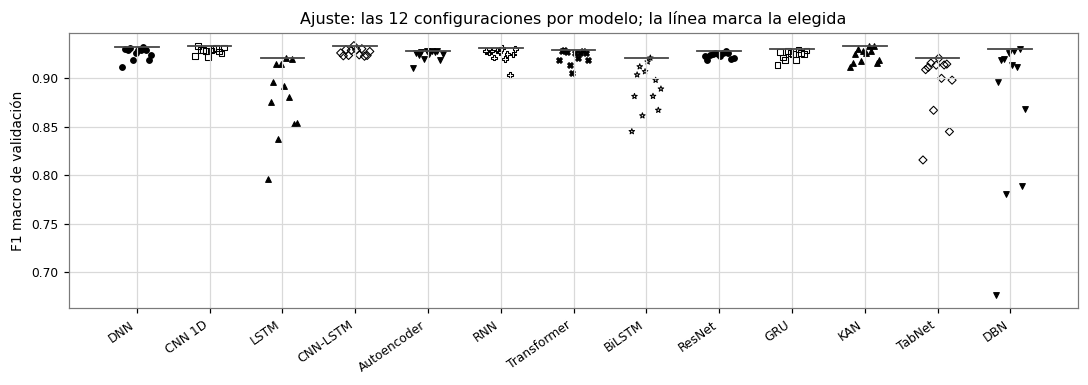

**Interpretación.** El modelo más sensible a los hiperparámetros es DBN, con un rango de 0,2539 en F1 macro de validación entre sus 12 configuraciones, y el menos sensible es ResNet, con 0,0090. Entre los profundos, la tasa de aprendizaje más elegida es 3 × 10⁻³ (9 de 13 modelos) y el lote más elegido, 256 (5 de 13). Ninguna configuración divergió.

Esto significa que el mismo presupuesto no produce el mismo beneficio en todos los modelos: los que tienen un rango amplio dependen más de acertar la configuración, de modo que con un presupuesto menor habrían quedado subestimados, y por eso se iguala el número de intentos y no el tiempo. Hay que tener en cuenta que el ajuste usa una sola semilla, de modo que diferencias entre configuraciones del orden del ruido por semilla, que mide el piloto, no son significativas.

Por tal motivo, se fijan para la ejecución definitiva las configuraciones de la tabla, elegidas solo con validación, y el resto del protocolo queda congelado.

In [36]:
from codigo import resultados as RES
from codigo import plan as PLAN

ajuste = RES.tabla_fase("ajuste")
PROFUNDOS = CONFIG["modelos"]["base_e1"] + CONFIG["modelos"]["top10"]
configs = PLAN.configuraciones_ajuste()["profundos"]
def cientifico(x):
    # 0,0003 se escribe 3 × 10⁻⁴, para no mezclar el punto decimal con la coma de las tablas
    if x == 0:
        return "0"
    if 0.01 <= abs(x) < 1e4:
        return f"{x:.4g}".replace(".", ",")
    e = int(np.floor(np.log10(abs(x))))
    m = round(x / 10 ** e, 3)
    sup = str(e).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
    return f"10{sup}" if m == 1 else f"{num(m, 0) if m == int(m) else num(m, 1)} × 10{sup}"
etiqueta_cfg = [f"{i}: lr {cientifico(c['lr'])}, wd {cientifico(c['weight_decay'])}, lote {c['batch']}" for i, c in enumerate(configs)]
pivote = ajuste[ajuste["modelo"].isin(PROFUNDOS)].pivot(index="intento", columns="modelo", values="f1_val")[PROFUNDOS]
pivote.index = etiqueta_cfg
tabla(pivote.reset_index(names="Configuración"), {m: "{:.4f}" for m in PROFUNDOS})
MEJORES_HP = PLAN.mejores_hp()
NOMBRE_HP = {"weight_decay": "wd", "batch": "lote"}
resumen_ajuste = pd.DataFrame([{"Modelo": m, "Mejor F1 de validación": ajuste.loc[ajuste["modelo"] == m, "f1_val"].max(), "Peor": ajuste.loc[ajuste["modelo"] == m, "f1_val"].min(),
                                "Rango": ajuste.loc[ajuste["modelo"] == m, "f1_val"].max() - ajuste.loc[ajuste["modelo"] == m, "f1_val"].min(),
                                "Configuración elegida": ", ".join(f"{NOMBRE_HP.get(k, k)} {cientifico(v)}" if isinstance(v, float) else f"{NOMBRE_HP.get(k, k)} {v}" for k, v in MEJORES_HP[m].items()),
                                "Minutos del ajuste": ajuste.loc[ajuste["modelo"] == m, "segundos"].sum() / 60, "Divergentes": int(ajuste.loc[ajuste["modelo"] == m, "divergente"].sum())}
                               for m in PROFUNDOS + ["LightGBM", "Logística"]])
tabla(resumen_ajuste, {"Mejor F1 de validación": "{:.4f}", "Peor": "{:.4f}", "Rango": "{:.4f}", "Minutos del ajuste": "{:.1f}"})
fig, eje = plt.subplots(figsize=(10, 3.6))
for j, m in enumerate(PROFUNDOS):
    v = pivote[m].to_numpy()
    eje.scatter(np.full(len(v), j) + np.linspace(-0.2, 0.2, len(v)), v, s=14, marker=MARCADORES[j % len(MARCADORES)], facecolors="none" if j % 2 else NEGRO, edgecolors=NEGRO, lw=0.7)
    eje.plot([j - 0.3, j + 0.3], [v.max()] * 2, color=GRIS_OSCURO, lw=1.2)
eje.set_xticks(range(len(PROFUNDOS)), PROFUNDOS, rotation=35, ha="right")
eje.set_ylabel("F1 macro de validación")
eje.set_title("Ajuste: las 12 configuraciones por modelo; la línea marca la elegida")
plt.tight_layout()
plt.show()
mas_sensible = resumen_ajuste.loc[resumen_ajuste["Rango"].idxmax()]
menos_sensible = resumen_ajuste.loc[resumen_ajuste.loc[resumen_ajuste["Modelo"].isin(PROFUNDOS), "Rango"].idxmin()]
lote_elegido = pd.Series({m: MEJORES_HP[m]["batch"] for m in PROFUNDOS}).value_counts()
tasa_elegida = pd.Series({m: MEJORES_HP[m]["lr"] for m in PROFUNDOS}).value_counts()
interpretar(f'''**Interpretación.** El modelo más sensible a los hiperparámetros es {mas_sensible["Modelo"]}, con un rango de {num(mas_sensible["Rango"], 4)} en F1 macro de validación entre sus 12 configuraciones, y el menos sensible es {menos_sensible["Modelo"]}, con {num(menos_sensible["Rango"], 4)}. Entre los profundos, la tasa de aprendizaje más elegida es {cientifico(tasa_elegida.index[0])} ({tasa_elegida.iloc[0]} de 13 modelos) y el lote más elegido, {lote_elegido.index[0]} ({lote_elegido.iloc[0]} de 13). {"Ninguna configuración divergió." if resumen_ajuste["Divergentes"].sum() == 0 else f"Divergieron {int(resumen_ajuste['Divergentes'].sum())} configuraciones, que se reportan y no se usan."}

Esto significa que el mismo presupuesto no produce el mismo beneficio en todos los modelos: los que tienen un rango amplio dependen más de acertar la configuración, de modo que con un presupuesto menor habrían quedado subestimados, y por eso se iguala el número de intentos y no el tiempo. Hay que tener en cuenta que el ajuste usa una sola semilla, de modo que diferencias entre configuraciones del orden del ruido por semilla, que mide el piloto, no son significativas.

Por tal motivo, se fijan para la ejecución definitiva las configuraciones de la tabla, elegidas solo con validación, y el resto del protocolo queda congelado.''')

**Importancia de los hiperparámetros.** La sección 11.1 del enunciado pide reportar, además del mejor valor, las curvas de importancia de los hiperparámetros. Como las 12 configuraciones son las mismas para los 13 modelos profundos, se ajusta un modelo de bloques sobre el F1 de validación centrado dentro de cada modelo, $c_{jt} = \mu + \beta_{lr} + \beta_{wd} + \beta_{lote} + \alpha_j + \varepsilon_{jt}$, con el modelo $j$ como bloque, y se contrasta cada factor con una ANOVA de tipo II, que estima su efecto ajustado por los otros dos, y con corrección de Holm por los tres factores. Las curvas muestran el F1 centrado medio de cada valor con su IC 95 % entre modelos. Este análisis es exploratorio: no estaba en el preregistro y no cambia las configuraciones elegidas.

Hiperparámetro,Valores,F,p,p Holm,η² parcial,Mejor valor (marginal),Rango de la curva
Tasa de aprendizaje,4,"7,35","0,0001","0,0004","0,140",3 × 10⁻³,"0,0352"
Weight decay,3,"0,24","0,7863","0,9136","0,004",0,"0,0164"
Tamaño de lote,3,"0,79","0,4568","0,9136","0,011",128,"0,0092"


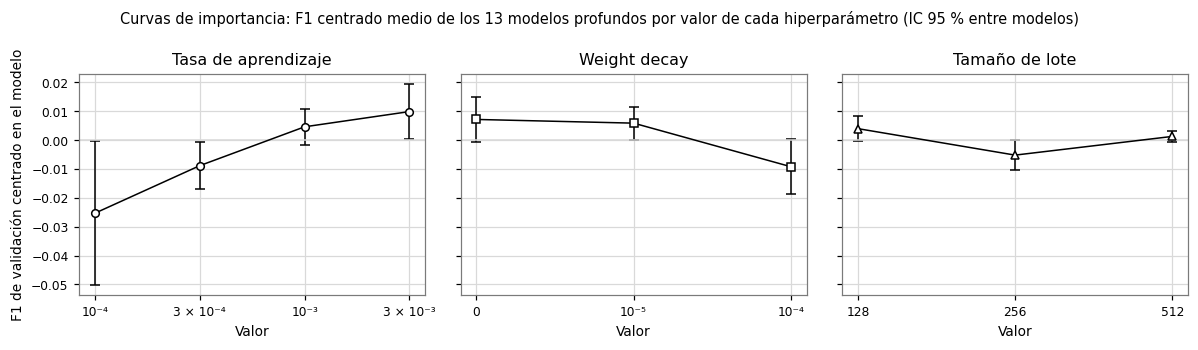

**Interpretación.** El hiperparámetro que más explica el F1 de validación es la tasa de aprendizaje, con η² parcial de 0,140 (p < 0,001 tras Holm); su curva sube 0,0352 entre el peor y el mejor valor, y el mejor es 3 × 10⁻³. El *weight decay* y el tamaño de lote no tienen un efecto significativo una vez ajustado por la tasa de aprendizaje (η² parcial de 0,004 y 0,011 y p de Holm de 0,914 y 0,914, respectivamente).

Hay que tener en cuenta que las 12 configuraciones se muestrearon de la rejilla, de modo que los valores de los tres hiperparámetros no están balanceados y sus curvas marginales se mezclan entre sí: la ANOVA de tipo II separa esos efectos y es la que sustenta la lectura, y las curvas solo muestran la dirección.

Por ello, se recomienda concentrar el presupuesto de ajuste del Entregable 3 en la tasa de aprendizaje, con menos valores de *weight decay* y de tamaño de lote, y ampliar el rango de la tasa por encima de 3 × 10⁻³, porque el mejor valor quedó en el borde de la rejilla.

In [37]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

imp = ajuste[ajuste["modelo"].isin(PROFUNDOS)].rename(columns={"hp_lr": "lr", "hp_weight_decay": "wd", "hp_batch": "lote"}).copy()
imp["c"] = imp["f1_val"] - imp.groupby("modelo")["f1_val"].transform("mean")
av_hp = anova_lm(smf.ols("c ~ C(modelo) + C(lr) + C(wd) + C(lote)", data=imp).fit(), typ=2)
ss_res_hp = av_hp.loc["Residual", "sum_sq"]
FACTORES_HP = {"lr": "Tasa de aprendizaje", "wd": "Weight decay", "lote": "Tamaño de lote"}
p_holm_hp = E.holm([av_hp.loc[f"C({h})", "PR(>F)"] for h in FACTORES_HP])
filas_hp = []
for (h, nombre), p_h in zip(FACTORES_HP.items(), p_holm_hp):
    por_modelo = imp.groupby(["modelo", h])["c"].mean().unstack()
    curva = por_modelo.mean()
    filas_hp.append({"Hiperparámetro": nombre, "Valores": len(curva), "F": av_hp.loc[f"C({h})", "F"], "p": av_hp.loc[f"C({h})", "PR(>F)"], "p Holm": p_h,
                     "η² parcial": av_hp.loc[f"C({h})", "sum_sq"] / (av_hp.loc[f"C({h})", "sum_sq"] + ss_res_hp),
                     "Mejor valor (marginal)": cientifico(float(curva.idxmax())) if h != "lote" else int(curva.idxmax()), "Rango de la curva": curva.max() - curva.min()})
IMPORTANCIA_HP = pd.DataFrame(filas_hp)
IMPORTANCIA_HP.to_csv(RESULTADOS / "importancia_hiperparametros.csv", index=False, encoding="utf-8-sig")
tabla(IMPORTANCIA_HP.assign(p=IMPORTANCIA_HP["p"].map(p_exacto), **{"p Holm": IMPORTANCIA_HP["p Holm"].map(p_exacto)}), {"F": "{:.2f}", "η² parcial": "{:.3f}", "Rango de la curva": "{:.4f}"})
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for j, (eje, (h, nombre)) in enumerate(zip(ejes, FACTORES_HP.items())):
    por_modelo = imp.groupby(["modelo", h])["c"].mean().unstack()
    media, de = por_modelo.mean(), por_modelo.std(ddof=1)
    semi = stats.t.ppf(0.975, len(por_modelo) - 1) * de / np.sqrt(len(por_modelo))
    x = np.arange(len(media))
    eje.errorbar(x, media.to_numpy(), yerr=semi.to_numpy(), color=NEGRO, marker=MARCADORES[j], ms=5, mfc="white", lw=1, capsize=3)
    eje.axhline(0, color=GRIS_CLARO, lw=1)
    eje.set_xticks(x, [cientifico(float(v)) if h != "lote" else str(int(v)) for v in media.index], fontsize=8)
    eje.set(title=nombre, xlabel="Valor")
ejes[0].set_ylabel("F1 de validación centrado en el modelo")
fig.suptitle("Curvas de importancia: F1 centrado medio de los 13 modelos profundos por valor de cada hiperparámetro (IC 95 % entre modelos)", fontsize=9.5)
plt.tight_layout()
plt.show()
dom_hp = IMPORTANCIA_HP.loc[IMPORTANCIA_HP["η² parcial"].idxmax()]
otros_hp = IMPORTANCIA_HP.drop(index=IMPORTANCIA_HP["η² parcial"].idxmax())
h_dom = [h for h, n in FACTORES_HP.items() if n == dom_hp["Hiperparámetro"]][0]
borde_hp = float(imp.groupby(h_dom)["c"].mean().idxmax()) == float(max(CONFIG["ajuste"]["espacio_profundos"][{"lote": "batch", "wd": "weight_decay"}.get(h_dom, h_dom)]))
ART_HP = {"Tasa de aprendizaje": "la tasa de aprendizaje", "Weight decay": "el *weight decay*", "Tamaño de lote": "el tamaño de lote"}
otros_sig = otros_hp[otros_hp["p Holm"] < ALFA]
otros_ns = otros_hp[otros_hp["p Holm"] >= ALFA]
texto_otros = ""
if len(otros_ns):
    sujeto = enumerar([ART_HP[n] for n in otros_ns["Hiperparámetro"]])
    etas_ns, ps_ns = [num(v, 3) for v in otros_ns["η² parcial"]], [num(v, 3) for v in otros_ns["p Holm"]]
    cifras_ns = (f"η² parcial de {enumerar(etas_ns)} y p de Holm de {enumerar(ps_ns)}, respectivamente" if len(otros_ns) > 1
                 else f"η² parcial de {etas_ns[0]}, {valor_p(otros_ns['p Holm'].iloc[0])} tras Holm")
    texto_otros += (f" {sujeto[0].upper() + sujeto[1:]} {'no tienen' if len(otros_ns) > 1 else 'no tiene'} un efecto significativo una vez ajustado por {ART_HP[dom_hp['Hiperparámetro']]} "
                    f"({cifras_ns}).")
if len(otros_sig):
    sujeto = enumerar([ART_HP[n] for n in otros_sig["Hiperparámetro"]])
    texto_otros += f" {sujeto[0].upper() + sujeto[1:]} también {'tienen' if len(otros_sig) > 1 else 'tiene'} un efecto significativo, aunque menor."
interpretar(f'''**Interpretación.** El hiperparámetro que más explica el F1 de validación es {ART_HP[dom_hp["Hiperparámetro"]]}, con η² parcial de {num(dom_hp["η² parcial"], 3)} ({valor_p(dom_hp["p Holm"])} tras Holm); su curva sube {num(dom_hp["Rango de la curva"], 4)} entre el peor y el mejor valor, y el mejor es {dom_hp["Mejor valor (marginal)"]}.{texto_otros}

Hay que tener en cuenta que las 12 configuraciones se muestrearon de la rejilla, de modo que los valores de los tres hiperparámetros no están balanceados y sus curvas marginales se mezclan entre sí: la ANOVA de tipo II separa esos efectos y es la que sustenta la lectura, y las curvas solo muestran la dirección.

Por ello, se recomienda concentrar el presupuesto de ajuste del Entregable 3 en la tasa de aprendizaje, con menos valores de *weight decay* y de tamaño de lote{", y ampliar el rango de la tasa por encima de " + cientifico(float(max(CONFIG["ajuste"]["espacio_profundos"]["lr"]))) + ", porque el mejor valor quedó en el borde de la rejilla" if borde_hp and h_dom == "lr" else ""}.''')

**Hiperparámetros y estrategia de entrenamiento.** La tabla reúne lo que pide la sección 4.2 del enunciado para cada modelo. Todo el entrenamiento es en precisión simple (float32) en CPU, sin precisión mixta, porque no hay GPU.

In [38]:
DROPOUT = {"DNN": "0,2 tras las capas de 128 y 64", "CNN 1D": "0,2 antes de la densa", "LSTM": "0,2 antes de la salida", "RNN": "0,3", "GRU": "0,3 en tres posiciones", "BiLSTM": "0,3",
           "Transformer": "0,3 antes de la salida", "TabNet": "No usa; regularización de dispersión λ = 10⁻³", "KAN": "0,25 y 0,20", "ResNet": "Por búsqueda", "Autoencoder": "Por búsqueda",
           "DBN": "Por búsqueda", "CNN-LSTM": "Por búsqueda"}
hp_tabla = pd.DataFrame([{"Modelo": m, "Optimizador": "Adam", "Tasa de aprendizaje": cientifico(MEJORES_HP[m]["lr"]), "Planificador": "ReduceLROnPlateau (0,1; 2)", "Weight decay": cientifico(MEJORES_HP[m]["weight_decay"]),
                          "Lote": MEJORES_HP[m]["batch"], "Dropout": DROPOUT[m], "Pérdida": "CE ponderada" + (" + dispersión" if m == "TabNet" else " + reconstrucción" if m == "Autoencoder" else ""),
                          "Épocas máximas": CONFIG["entrenamiento"]["max_epocas"], "Parada temprana": f"Paciencia {CONFIG['entrenamiento']['paciencia']} sobre F1 de validación",
                          "Recorte de gradiente": f"Norma {CONFIG['entrenamiento']['norma_gradiente']:g}"} for m in PROFUNDOS])
tabla(hp_tabla, {})

Modelo,Optimizador,Tasa de aprendizaje,Planificador,Weight decay,Lote,Dropout,Pérdida,Épocas máximas,Parada temprana,Recorte de gradiente
DNN,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,"0,2 tras las capas de 128 y 64",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
CNN 1D,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,512,"0,2 antes de la densa",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
LSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,128,"0,2 antes de la salida",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
CNN-LSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
Autoencoder,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada + reconstrucción,30,Paciencia 6 sobre F1 de validación,Norma 5
RNN,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁴,512,"0,3",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
Transformer,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,512,"0,3 antes de la salida",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
BiLSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,128,"0,3",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
ResNet,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
GRU,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,"0,3 en tres posiciones",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5


### 4.3 Requisitos experimentales

**Semillas y determinismo.** Cada corrida fija las semillas de Python, NumPy y PyTorch, y el orden de los lotes sale de un generador con la misma semilla; las operaciones de PyTorch en CPU que se usan son deterministas con un número de hilos fijo, de modo que una corrida se puede repetir con la misma semilla. No se activa `torch.use_deterministic_algorithms`, porque no hay GPU. Las semillas son 4242 para el ajuste, 4101 a 4105 para el piloto, 5000 para la fase 1, 5101 a 5105 para la fase 2, 5201 a 5203 para el ruido por semilla y desde 6001 para la ejecución definitiva.

**Seguimiento de experimentos.** El ejecutor guarda cada corrida en un JSON con su configuración, semilla, curvas por época, tiempo, memoria, equipo y métricas, y la configuración del experimento está versionada en `configuracion/experimento.json`. Ese registro por corrida cumple la función de una herramienta de seguimiento como MLflow sin agregar una dependencia, y se consolida en `entregables/registro_experimentos.csv`.

**Cómputo.** Todo corre en CPU, de modo que no hay ventaja de GPU para ningún modelo; los trabajos se reparten entre procesos de 2 hilos y cada modelo recibe el mismo número de intentos, no el mismo tiempo.

**Preregistro, desviaciones y aclaraciones.** El preregistro (`preregistro_e2.md`) quedó fechado y versionado el 12 de noviembre de 2026 a las 13:12, con la etiqueta `preregistro-e2`, antes del primer entrenamiento. La adenda (`preregistro_e2_adenda.md` y `resultados/preregistro_e2_adenda.json`) registra con fecha las cifras que dependían del piloto y de la búsqueda, y tres cambios declarados antes de usarlos: la **desviación 1**, que entrena la fase 1 de la búsqueda y el estudio de ruido con un subconjunto fijo del 25 % de los bloques de entrenamiento (20 bloques, 19 351 flujos), porque el protocolo completo medía unas 40 horas de cómputo; la **aclaración 1**, que limita la validación cruzada 5 × 2 al contraste de RQ2, el único que la usa, y la **aclaración 2**, que promedia el F1 macro de cada bloque de prueba sobre las clases presentes en él. Ninguna se decidió después de ver resultados de prueba.

#### 4.3.1 Estudio piloto y número de ejecuciones

El piloto entrena cuatro modelos representativos, el baseline del Entregable 1 (CNN 1D) y tres del Top 10 de familias distintas (Transformer, RNN y KAN), con cinco semillas y sobre validación, para estimar la desviación de las diferencias pareadas frente al baseline y fijar R con la regla del preregistro. El mismo piloto verifica la limitación del paper guía en tres modelos del Top 10 (sección 5).

In [39]:
ADENDA = json.loads((RESULTADOS / "preregistro_e2_adenda.json").read_text(encoding="utf-8"))
pil = ADENDA["piloto"]
tabla(pd.DataFrame(pil["f1_validacion"]).rename_axis("Semilla").reset_index(), {m: "{:.4f}" for m in pil["f1_validacion"]})
tabla(pd.DataFrame([{"Par": p, "Diferencia media": v["media"], "σ̂_d": v["sigma_d"], "Shapiro-Wilk, p": v["shapiro_p"]} for p, v in pil["pares_frente_al_baseline"].items()]),
      {"Diferencia media": "{:.4f}", "σ̂_d": "{:.4f}", "Shapiro-Wilk, p": "{:.3f}"})
R = ADENDA["R"]
SEMILLAS = [CONFIG["definitiva"]["semilla_inicial"] + i for i in range(R)]
interpretar(f'''**Interpretación.** En el piloto, la mayor desviación de las diferencias pareadas frente a CNN 1D es σ̂_d = {num(pil["sigma_piloto"], 4)}, y la regla del preregistro toma el máximo entre ella y la del Entregable 1 en prueba, {num(pil["sigma_e1_prueba"], 4)}, de modo que se usa σ̂_d = {num(pil["sigma_usada"], 4)}. Con α′ = 0,05/10 y potencia de 0,80, detectar δ exigiría R = {pil["R_calculado"]} ejecuciones; {"el tope de cómputo es " + str(CONFIG["definitiva"]["R_tope"]) + ", de modo que se usa R = " + str(R) if pil["limitado_por_tope"] else "se usa R = " + str(R)}, con una diferencia mínima detectable de {num(pil["diferencia_minima_detectable"], 4)} en cada contraste de RQ1.

Esto significa que, {"como en el Entregable 1, el diseño no alcanza a detectar con potencia de 0,80 una diferencia de magnitud δ tras la corrección de Bonferroni, y que solo diferencias de unas " + num(pil["diferencia_minima_detectable"] / DELTA, 1) + " veces δ quedarían detectadas" if pil["limitado_por_tope"] else "el diseño detecta δ con la potencia deseada"}. Hay que tener en cuenta que la cifra es conservadora, porque Holm es menos exigente que Bonferroni salvo en el primer contraste.

Por lo anterior, conviene declarar la diferencia mínima detectable como limitación y leer los resultados no significativos con TOST y con la prueba bayesiana, y no como ausencia de diferencias. Las semillas definitivas son {SEMILLAS[0]} a {SEMILLAS[-1]}, las mismas para los 15 modelos entrenables (el trivial es determinista y usa solo la primera), y quedaron fijadas en la adenda del preregistro el {pil["fecha"]}.''')

Semilla,CNN 1D,KAN,RNN,Transformer
4101,"0,9295","0,9297","0,9102","0,9298"
4102,"0,9320","0,9268","0,9222","0,9211"
4103,"0,9296","0,9311","0,9199","0,9229"
4104,"0,9243","0,9177","0,9094","0,9308"
4105,"0,9263","0,9295","0,9257","0,9195"


Par,Diferencia media,σ̂_d,"Shapiro-Wilk, p"
KAN - CNN 1D,"-0,0014","0,0043","0,385"
RNN - CNN 1D,"-0,0109","0,0070","0,793"
Transformer - CNN 1D,"-0,0035","0,0069","0,576"


**Interpretación.** En el piloto, la mayor desviación de las diferencias pareadas frente a CNN 1D es σ̂_d = 0,0070, y la regla del preregistro toma el máximo entre ella y la del Entregable 1 en prueba, 0,0177, de modo que se usa σ̂_d = 0,0177. Con α′ = 0,05/10 y potencia de 0,80, detectar δ exigiría R = 42 ejecuciones; el tope de cómputo es 20, de modo que se usa R = 20, con una diferencia mínima detectable de 0,0162 en cada contraste de RQ1.

Esto significa que, como en el Entregable 1, el diseño no alcanza a detectar con potencia de 0,80 una diferencia de magnitud δ tras la corrección de Bonferroni, y que solo diferencias de unas 1,6 veces δ quedarían detectadas. Hay que tener en cuenta que la cifra es conservadora, porque Holm es menos exigente que Bonferroni salvo en el primer contraste.

Por lo anterior, conviene declarar la diferencia mínima detectable como limitación y leer los resultados no significativos con TOST y con la prueba bayesiana, y no como ausencia de diferencias. Las semillas definitivas son 6001 a 6020, las mismas para los 15 modelos entrenables (el trivial es determinista y usa solo la primera), y quedaron fijadas en la adenda del preregistro el 2026-11-12 16:58.

#### 4.3.2 Búsqueda de arquitectura para los modelos sin diseño definido

ResNet, Autoencoder, DBN y CNN-LSTM recorren el espacio de la sección 14: 3 bloques, anchos de {16, 32, 64, 128, 256} en todas las combinaciones y *dropout* de 0,2 tras cada bloque según b ∈ {0, 1}³, es decir, 1000 arquitecturas por modelo, generadas por código e identificadas como `w64-64-64_d010`. Los demás hiperparámetros se fijaron antes con la arquitectura de referencia (sección 4.2.1). El protocolo es el de dos fases del enunciado, con la desviación 1: la fase 1 y el estudio de ruido entrenan con el 25 % de los bloques de entrenamiento, se mantienen las 1000 arquitecturas, las 6 épocas y la validación completa, y la fase 2 vuelve al entrenamiento completo. Como menos datos hacen más ruidoso el F1 de la fase 1 y pueden favorecer arquitecturas pequeñas, se reporta la correlación de rangos entre las dos fases.

**Ruido por semilla y número de finalistas.** Antes de la fase 1 se entrenan 5 arquitecturas por modelo con 3 semillas a presupuesto de fase 1, para comparar la desviación entre semillas de una misma arquitectura con la desviación entre arquitecturas y fijar k con la regla del preregistro.

In [40]:
ruido = RES.tabla_fase("ruido")
tabla_ruido = ruido.groupby(["modelo", "arquitectura"])["f1_val"].agg(["mean", "std"]).reset_index()
tabla_ruido["arquitectura"] = tabla_ruido["arquitectura"].map(MOD.identificador)
tabla(tabla_ruido.rename(columns={"modelo": "Modelo", "arquitectura": "Arquitectura", "mean": "Media de F1 (3 semillas)", "std": "DE entre semillas"}),
      {"Media de F1 (3 semillas)": "{:.4f}", "DE entre semillas": "{:.4f}"})
rs = ADENDA["ruido_semilla"]
K_FINALISTAS = rs["k"]
interpretar(f'''**Interpretación.** La razón entre la desviación dentro de cada arquitectura (entre semillas) y la desviación entre arquitecturas va de {num(min(rs["razon_dentro_entre"].values()), 2)} en {min(rs["razon_dentro_entre"], key=rs["razon_dentro_entre"].get)} a {num(max(rs["razon_dentro_entre"].values()), 2)} en {max(rs["razon_dentro_entre"], key=rs["razon_dentro_entre"].get)}. Con la regla del preregistro, k = {K_FINALISTAS}.

Lo anterior indica que {"el ruido por semilla es comparable a la dispersión real entre arquitecturas en al menos un modelo, de modo que el orden de la fase 1 es ruidoso y el mejor verdadero puede quedar fuera de los finalistas; según la simulación del enunciado, con un ruido igual a la dispersión, la probabilidad de capturarlo con k = 10 es de cerca del 50 %" if K_FINALISTAS == 20 else "el ruido por semilla es pequeño frente a la dispersión entre arquitecturas, de modo que el orden de la fase 1 es informativo"}.

Por tal motivo, se conservan {K_FINALISTAS} finalistas por modelo, más la referencia (64, 64, 64) con *dropout* (0, 1, 0), y se reporta la correlación de rangos entre fases para medir cuánto informó el cribado.''')

Modelo,Arquitectura,Media de F1 (3 semillas),DE entre semillas
Autoencoder,w16-128-256_d010,"0,9100","0,0002"
Autoencoder,w32-128-32_d011,"0,9078","0,0002"
Autoencoder,w64-16-16_d100,"0,8952","0,0095"
Autoencoder,w128-32-128_d010,"0,9103","0,0013"
Autoencoder,w256-256-32_d010,"0,9111","0,0018"
CNN-LSTM,w16-128-256_d010,"0,9106","0,0064"
CNN-LSTM,w32-128-32_d011,"0,9128","0,0063"
CNN-LSTM,w64-16-16_d100,"0,9087","0,0068"
CNN-LSTM,w128-32-128_d010,"0,9134","0,0054"
CNN-LSTM,w256-256-32_d010,"0,9117","0,0001"


**Interpretación.** La razón entre la desviación dentro de cada arquitectura (entre semillas) y la desviación entre arquitecturas va de 0,47 en DBN a 2,99 en CNN-LSTM. Con la regla del preregistro, k = 20.

Lo anterior indica que el ruido por semilla es comparable a la dispersión real entre arquitecturas en al menos un modelo, de modo que el orden de la fase 1 es ruidoso y el mejor verdadero puede quedar fuera de los finalistas; según la simulación del enunciado, con un ruido igual a la dispersión, la probabilidad de capturarlo con k = 10 es de cerca del 50 %.

Por tal motivo, se conservan 20 finalistas por modelo, más la referencia (64, 64, 64) con *dropout* (0, 1, 0), y se reporta la correlación de rangos entre fases para medir cuánto informó el cribado.

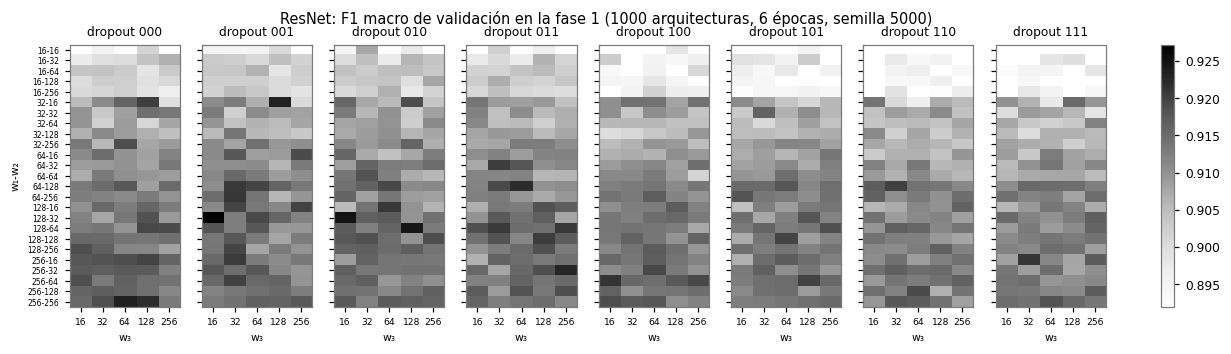

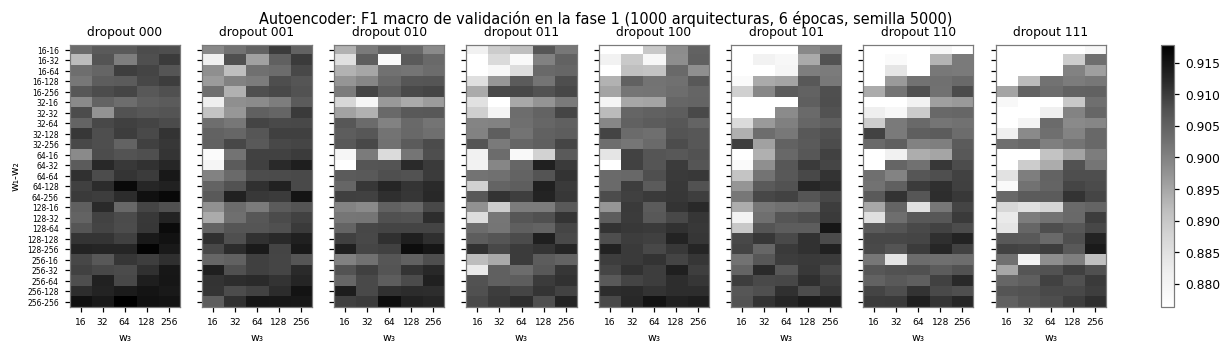

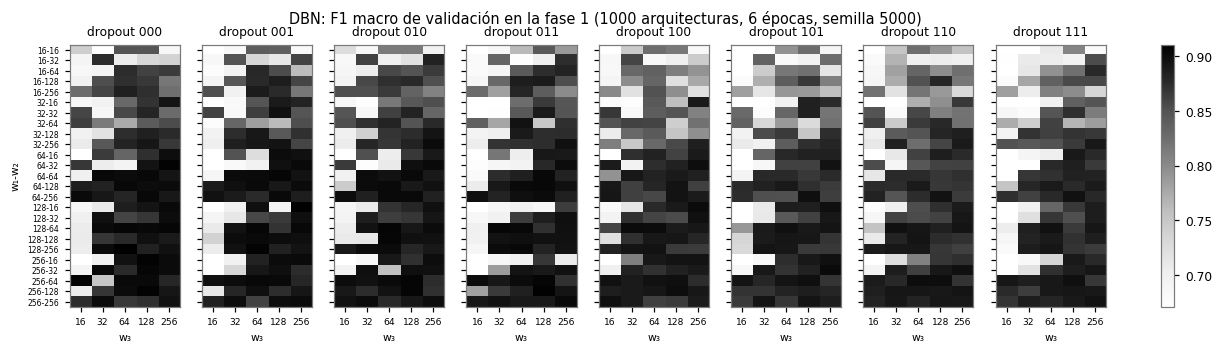

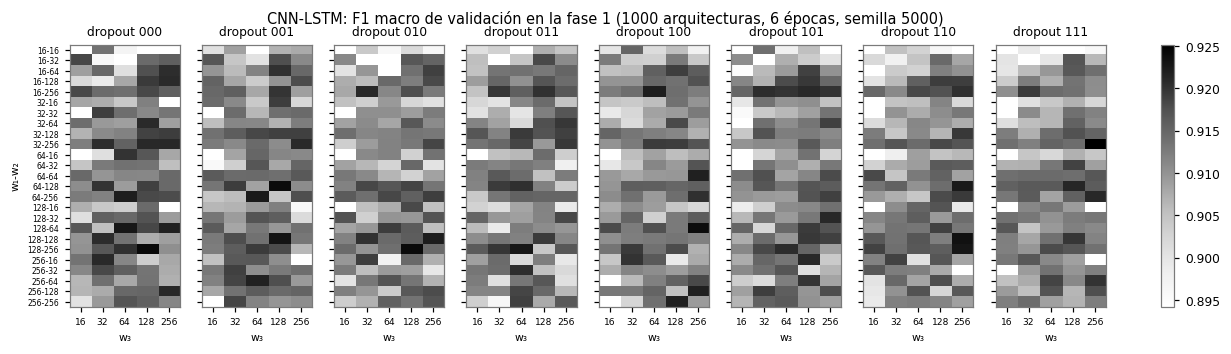

Modelo,min,25%,50%,75%,max,std
Autoencoder,"0,8551","0,9015","0,9065","0,9096","0,9179","0,0109"
CNN-LSTM,"0,8638","0,9066","0,9116","0,9154","0,9252","0,0079"
DBN,"0,4694","0,7441","0,8663","0,8892","0,9107","0,0982"
ResNet,"0,8691","0,9052","0,9103","0,9138","0,9272","0,0081"


In [41]:
f1 = RES.tabla_fase("fase1")
f1[["w1", "w2", "w3", "b1", "b2", "b3"]] = pd.DataFrame(f1["arquitectura"].tolist(), index=f1.index)
f1["patron"] = f1["b1"].astype(str) + f1["b2"].astype(str) + f1["b3"].astype(str)
f1.to_csv(RESULTADOS / "busqueda_fase1.csv", index=False)
CON_BUSQUEDA = CONFIG["modelos"]["con_busqueda"]
for m in CON_BUSQUEDA:
    sub = f1[f1["modelo"] == m]
    fig, ejes = plt.subplots(1, 8, figsize=(13, 3.1), sharey=True)
    lim = (sub["f1_val"].quantile(0.05), sub["f1_val"].max())
    for eje, patron in zip(ejes, sorted(sub["patron"].unique())):
        m_pat = sub[sub["patron"] == patron].pivot_table(index=["w1", "w2"], columns="w3", values="f1_val")
        imagen = eje.imshow(m_pat.to_numpy(), aspect="auto", vmin=lim[0], vmax=lim[1])
        eje.set_title(f"dropout {patron}", fontsize=8)
        eje.set_xticks(range(5), [str(w) for w in MOD.ANCHOS], fontsize=6)
        eje.set_yticks(range(25), [f"{a}-{b}" for a, b in m_pat.index], fontsize=5)
        eje.set_xlabel("w₃", fontsize=7)
        eje.grid(False)
    ejes[0].set_ylabel("w₁-w₂", fontsize=7)
    fig.colorbar(imagen, ax=ejes, fraction=0.015)
    fig.suptitle(f"{m}: F1 macro de validación en la fase 1 (1000 arquitecturas, 6 épocas, semilla 5000)", fontsize=9.5)
    plt.show()
tabla(f1.groupby("modelo")["f1_val"].describe()[["min", "25%", "50%", "75%", "max", "std"]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ["min", "25%", "50%", "75%", "max", "std"]})

**Efectos principales e interacciones.** Sobre las 1000 arquitecturas de cada modelo se ajusta el modelo lineal de la sección 14.6, $y_a = \beta_0 + \sum_{i=1}^{3} \sum_{w \in W} \beta_{i,w} \mathbb{1}[w_i = w] + \sum_i \gamma_i b_i + \sum_{i<j} \lambda_{ij} b_i b_j + \varepsilon_a$, con una ANOVA de tipo II por factor y corrección de Holm por el número de factores, y la proporción de varianza que explica cada uno. Se agregan una prueba de tendencia del ancho, con la regresión sobre $\log_2 w_i$, y la comparación pareada de cada combinación de anchos sin *dropout* frente al promedio de sus siete patrones con *dropout*, con Wilcoxon sobre las 125 combinaciones. Como la fase 1 usa una sola semilla, el error del modelo mezcla el ruido por semilla con el efecto de la arquitectura.

In [42]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests

efectos = []
dropout_pareado = []
for m in CON_BUSQUEDA:
    sub = f1[f1["modelo"] == m].copy()
    ajuste_lm = smf.ols("f1_val ~ C(w1) + C(w2) + C(w3) + b1 + b2 + b3 + b1:b2 + b1:b3 + b2:b3", data=sub).fit()
    anova = anova_lm(ajuste_lm, typ=2)
    ss_total = ((sub["f1_val"] - sub["f1_val"].mean()) ** 2).sum()
    p_holm = multipletests(anova["PR(>F)"].iloc[:-1], method="holm")[1]
    for (factor, fila), ph in zip(anova.iloc[:-1].iterrows(), p_holm):
        efectos.append({"Modelo": m, "Factor": factor.replace("C(", "").replace(")", ""), "F": fila["F"], "p Holm": ph, "% de varianza": 100 * fila["sum_sq"] / ss_total})
    efectos.append({"Modelo": m, "Factor": "Residuo", "F": np.nan, "p Holm": np.nan, "% de varianza": 100 * anova["sum_sq"].iloc[-1] / ss_total})
    for i in (1, 2, 3):
        tendencia_w = smf.ols(f"f1_val ~ np.log2(w{i})", data=sub).fit()
        efectos.append({"Modelo": m, "Factor": f"tendencia log₂ w{i} (pendiente {tendencia_w.params.iloc[1]:+.4f})", "F": tendencia_w.fvalue, "p Holm": tendencia_w.f_pvalue, "% de varianza": 100 * tendencia_w.rsquared})
    sin = sub[sub["patron"] == "000"].set_index(["w1", "w2", "w3"])["f1_val"]
    con = sub[sub["patron"] != "000"].groupby(["w1", "w2", "w3"])["f1_val"].mean()
    d = (con - sin.reindex(con.index)).to_numpy()
    w = stats.wilcoxon(d)
    dropout_pareado.append({"Modelo": m, "Diferencia media con dropout − sin dropout": d.mean(), "Combinaciones donde ayuda": int((d > 0).sum()), "p Wilcoxon": w.pvalue,
                            "r biserial": float((stats.rankdata(np.abs(d))[d > 0].sum() - stats.rankdata(np.abs(d))[d < 0].sum()) / stats.rankdata(np.abs(d)).sum())})
efectos = pd.DataFrame(efectos)
efectos.to_csv(RESULTADOS / "busqueda_efectos.csv", index=False, encoding="utf-8-sig")
espacio = pd.DataFrame([{"Modelo": m, "Identificador": MOD.identificador(a), "w1": a[0], "w2": a[1], "w3": a[2], "b1": a[3], "b2": a[4], "b3": a[5],
                         "Parámetros": MOD.parametros(MOD.construir(m, a)), "FLOPs por muestra": 2 * MOD.contar_mac(MOD.construir(m, a))} for m in CON_BUSQUEDA for a in MOD.espacio_arquitecturas()])
espacio.to_csv(RESULTADOS / "arquitecturas_espacio.csv", index=False, encoding="utf-8-sig")
tabla(efectos, {"F": "{:.2f}", "p Holm": "{:.2e}", "% de varianza": "{:.1f}"})
tabla(pd.DataFrame(dropout_pareado), {"Diferencia media con dropout − sin dropout": "{:+.4f}", "p Wilcoxon": "{:.2e}", "r biserial": "{:.3f}"})

Modelo,Factor,F,p Holm,% de varianza
ResNet,w1,"618,33","2,23e-265","67,0"
ResNet,w2,"14,92","5,38e-11","1,6"
ResNet,w3,"2,68","1,22e-01","0,3"
ResNet,b1,"144,18","3,47e-30","3,9"
ResNet,b2,"10,57","7,13e-03","0,3"
ResNet,b3,"0,80","1,00e+00","0,0"
ResNet,b1:b2,"9,50","1,06e-02","0,3"
ResNet,b1:b3,"0,49","1,00e+00","0,0"
ResNet,b2:b3,"0,33","1,00e+00","0,0"
ResNet,Residuo,,,"26,6"


Modelo,Diferencia media con dropout − sin dropout,Combinaciones donde ayuda,p Wilcoxon,r biserial
ResNet,"-0,0017",43,"2,04e-06","-0,490"
Autoencoder,"-0,0073",2,"3,68e-22","-0,998"
DBN,"-0,0168",25,"7,55e-08","-0,554"
CNN-LSTM,"-0,0009",46,"1,70e-02","-0,246"


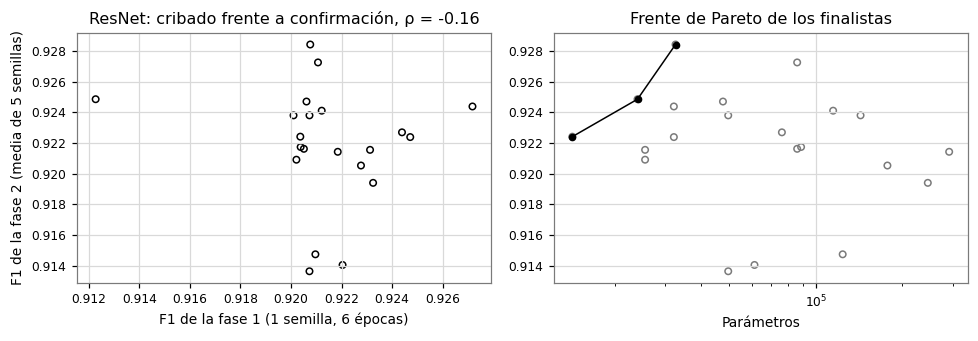

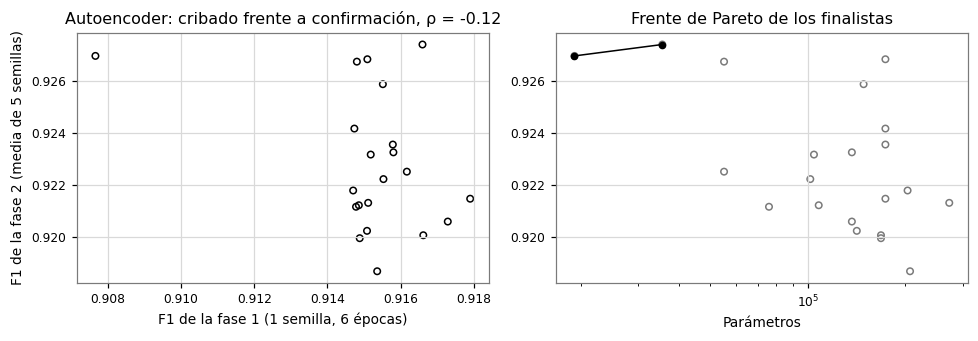

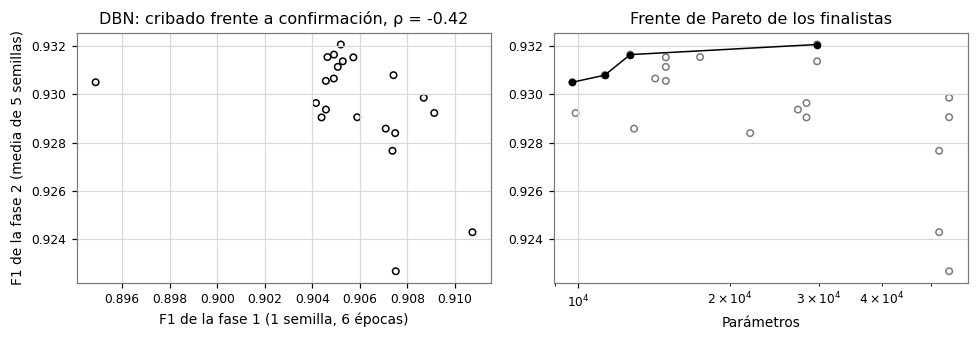

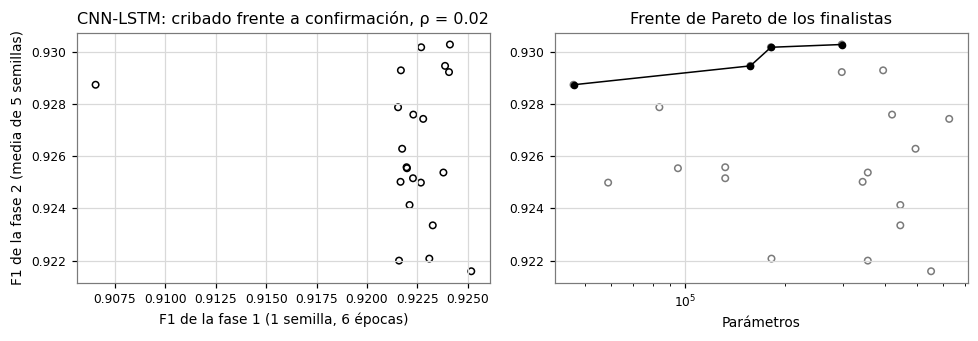

Modelo,Finalistas,Ganadora,F1 de validación (5 semillas),Parámetros,Mejor media,Empate técnico,Equivalentes por TOST,ρ de Spearman fase 1–fase 2,p,DE entre arquitecturas (fase 1),DE entre semillas (fase 2),Brecha entrenamiento − validación
ResNet,21,w64-32-32_d011,"0,9224",14 245,w128-16-64_d010,sí,15,"-0,161","0,486","0,0081","0,0074","0,0032"
Autoencoder,21,w64-64-64_d010,"0,9269",19 093,w64-128-64_d000,sí,8,"-0,121","0,602","0,0109","0,0070","0,0010"
DBN,21,w64-64-64_d010,"0,9305",9 733,w256-64-128_d011,sí,19,"-0,418","0,059","0,0982","0,0025","0,0014"
CNN-LSTM,21,w64-64-64_d010,"0,9287",46 213,w128-256-128_d000,sí,13,"0,025","0,915","0,0079","0,0049","0,0036"


Fase,Corridas,Horas de proceso
Ruido por semilla,60,"0,4"
Fase 1,4 000,"31,0"
Fase 2,420,"23,6"


Nota: 6 corridas estaban en curso cuando el equipo se suspendió; su resultado no cambia, porque el proceso continuó al reanudar, y a su tiempo de reloj se le descuenta la suspensión registrada por el sistema (resultados/corridas/suspensiones.json).


In [43]:
f2 = RES.tabla_fase("fase2")
detalle_f2 = ADENDA["fase2"]["detalle"]
filas_f2 = []
for m in CON_BUSQUEDA:
    sub2 = f2[f2["modelo"] == m]
    agg = sub2.groupby("arquitectura").agg(media=("f1_val", "mean"), de=("f1_val", "std"), f1_ent=("f1_ent", "mean"), segundos=("segundos", "mean"), parametros=("parametros", "first")).reset_index()
    agg["brecha"] = agg["f1_ent"] - agg["media"]
    fase1_m = f1[f1["modelo"] == m].set_index("arquitectura")["f1_val"]
    agg["fase1"] = agg["arquitectura"].map(fase1_m)
    rho = stats.spearmanr(agg["fase1"], agg["media"])
    ganadora = tuple(ADENDA["arquitecturas_ganadoras"][m])
    borde = any(w in (16, 256) for w in ganadora[:3]) and len({w for w in ganadora[:3]}) == 1
    filas_f2.append({"Modelo": m, "Finalistas": len(agg), "Ganadora": MOD.identificador(ganadora), "F1 de validación (5 semillas)": float(agg.loc[agg["arquitectura"] == ganadora, "media"].iloc[0]),
                     "Parámetros": int(agg.loc[agg["arquitectura"] == ganadora, "parametros"].iloc[0]), "Mejor media": detalle_f2[m]["mejor_media"], "Empate técnico": "sí" if detalle_f2[m]["empate_tecnico"] else "no",
                     "Equivalentes por TOST": len(detalle_f2[m]["equivalentes_tost"]), "ρ de Spearman fase 1–fase 2": rho.statistic, "p": rho.pvalue,
                     "DE entre arquitecturas (fase 1)": fase1_m.std(), "DE entre semillas (fase 2)": float(np.sqrt((sub2.groupby("arquitectura")["f1_val"].var()).mean())),
                     "Brecha entrenamiento − validación": float(agg.loc[agg["arquitectura"] == ganadora, "brecha"].iloc[0])})
    fig, ejes = plt.subplots(1, 2, figsize=(9, 3.2))
    ejes[0].scatter(agg["fase1"], agg["media"], s=18, facecolors="none", edgecolors=NEGRO)
    ejes[0].set_xlabel("F1 de la fase 1 (1 semilla, 6 épocas)")
    ejes[0].set_ylabel("F1 de la fase 2 (media de 5 semillas)")
    ejes[0].set_title(f"{m}: cribado frente a confirmación, ρ = {rho.statistic:.2f}")
    orden = agg.sort_values("parametros")
    frente = orden[orden["media"] >= orden["media"].cummax()]
    ejes[1].scatter(orden["parametros"], orden["media"], s=18, facecolors="none", edgecolors=GRIS_MEDIO)
    ejes[1].plot(frente["parametros"], frente["media"], color=NEGRO, marker="o", ms=4, lw=1)
    ejes[1].set_xscale("log")
    ejes[1].set_xlabel("Parámetros")
    ejes[1].set_title("Frente de Pareto de los finalistas")
    plt.tight_layout()
    plt.show()
FASE2 = pd.DataFrame(filas_f2)
FASE2.to_csv(RESULTADOS / "busqueda_fase2.csv", index=False, encoding="utf-8-sig")
tabla(FASE2, {"F1 de validación (5 semillas)": "{:.4f}", "Parámetros": "{:,.0f}", "ρ de Spearman fase 1–fase 2": "{:.3f}", "p": "{:.3f}", "DE entre arquitecturas (fase 1)": "{:.4f}",
              "DE entre semillas (fase 2)": "{:.4f}", "Brecha entrenamiento − validación": "{:.4f}"})
costo_busqueda = pd.DataFrame({"Fase": ["Ruido por semilla", "Fase 1", "Fase 2"], "Corridas": [len(ruido), len(f1), len(f2)],
                               "Horas de proceso": [ruido["segundos"].sum() / 3600, f1["segundos"].sum() / 3600, f2["segundos"].sum() / 3600]})
tabla(costo_busqueda, {"Horas de proceso": "{:.1f}"})
if RES.suspensiones():
    print(f"Nota: {len(RES.suspensiones())} corridas estaban en curso cuando el equipo se suspendió; su resultado no cambia, porque el proceso continuó al reanudar, "
          "y a su tiempo de reloj se le descuenta la suspensión registrada por el sistema (resultados/corridas/suspensiones.json).")

In [44]:
def mayor_factor(m):
    sub_e = efectos[(efectos["Modelo"] == m) & (~efectos["Factor"].str.startswith("tendencia")) & (efectos["Factor"] != "Residuo")]
    return sub_e.loc[sub_e["% de varianza"].idxmax()]
residuos = efectos[efectos["Factor"] == "Residuo"].set_index("Modelo")["% de varianza"]
textos_factor = [f"{m}, {mayor_factor(m)['Factor']} ({num(mayor_factor(m)['% de varianza'], 1)} %)" for m in CON_BUSQUEDA]
dp = pd.DataFrame(dropout_pareado).set_index("Modelo")
ayuda = [m for m in CON_BUSQUEDA if dp.loc[m, "p Wilcoxon"] < ALFA and dp.loc[m, "Diferencia media con dropout − sin dropout"] > 0]
perjudica = [m for m in CON_BUSQUEDA if dp.loc[m, "p Wilcoxon"] < ALFA and dp.loc[m, "Diferencia media con dropout − sin dropout"] < 0]
irrelevante = [r_["Modelo"] for _, r_ in FASE2.iterrows() if r_["DE entre arquitecturas (fase 1)"] <= 1.5 * r_["DE entre semillas (fase 2)"]]
borde = [r_["Modelo"] for _, r_ in FASE2.iterrows() if any(w in (16, 256) for w in ADENDA["arquitecturas_ganadoras"][r_["Modelo"]][:3])]
estimado_h = 126000 / 3600
REFERENCIA_ID = "w64-64-64_d010"
gana_referencia = FASE2.loc[FASE2["Ganadora"] == REFERENCIA_ID, "Modelo"].tolist()
con_empate = FASE2.loc[FASE2["Empate técnico"] == "sí", "Modelo"].tolist()
if not ayuda:
    texto_dropout = f"El *dropout* no mejora el F1 de forma significativa en ningún modelo" + (f" y lo empeora en {enumerar(perjudica)}" if perjudica else "")
else:
    texto_dropout = f"El *dropout* mejora el F1 de forma significativa en {enumerar(ayuda)}" + (f" y lo empeora en {enumerar(perjudica)}" if perjudica else "")
if gana_referencia:
    texto_referencia = (f" En {enumerar(con_empate)} hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros; "
                        f"en {enumerar(gana_referencia)}, esa elegida es la propia referencia (64, 64, 64) con *dropout* (0, 1, 0), de modo que la búsqueda no encontró en {'esos modelos' if len(gana_referencia) > 1 else 'ese modelo'} una arquitectura que la supere en más de δ.")
else:
    texto_referencia = f" En {enumerar(con_empate)} hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros." if con_empate else ""
interpretar(f'''**Interpretación.** En la fase 1, el factor que más varianza explica en cada modelo es: {enumerar(textos_factor)}; el residuo, que mezcla el ruido por semilla con lo que el modelo lineal no captura, va de {num(residuos.min(), 1)} % a {num(residuos.max(), 1)} %. {texto_dropout}, según la comparación pareada sobre las 125 combinaciones de anchos. En la fase 2, la correlación de rangos con la fase 1 va de {num(FASE2["ρ de Spearman fase 1–fase 2"].min(), 2)} a {num(FASE2["ρ de Spearman fase 1–fase 2"].max(), 2)}, y las ganadoras son {enumerar(FASE2["Modelo"] + ", " + FASE2["Ganadora"])}.{texto_referencia}

Esto significa que la fase 1 {"informó poco el orden de la fase 2 en " + enumerar(FASE2.loc[FASE2["ρ de Spearman fase 1–fase 2"] < 0.3, "Modelo"]) + ", de modo que en esos modelos la ganadora es la mejor entre los finalistas y no necesariamente la mejor de las 1000" if (FASE2["ρ de Spearman fase 1–fase 2"] < 0.3).any() else "ordenó a los finalistas de forma parecida a la fase 2"}. Así mismo, {"en " + enumerar(irrelevante) + " la dispersión entre arquitecturas es comparable a la dispersión entre semillas, de modo que la arquitectura es irrelevante para ese modelo en este problema, como prevé la sección 14.6 del enunciado" if irrelevante else "en todos los modelos la dispersión entre arquitecturas supera con claridad a la de semillas, de modo que la arquitectura sí importa"}. {"La ganadora tiene algún ancho en el borde del espacio (16 o 256) en " + enumerar(borde) + ", lo que se declara como limitación: el espacio podría no contener el óptimo, y no se amplía después de ver la prueba." if borde else "Ninguna ganadora cae en el borde del espacio."} Hay que tener en cuenta la maldición del ganador: la media de validación de la ganadora en la fase 2 está sesgada hacia arriba por la selección, y por eso su desempeño se estima solo con la prueba, en la ejecución definitiva.

Por lo anterior, conviene usar estas arquitecturas en la ejecución definitiva, como fijó la regla del preregistro, y leer su comparación con los demás modelos sabiendo que la búsqueda costó {num(costo_busqueda["Horas de proceso"].sum(), 1)} horas de proceso, frente a unas {num(estimado_h, 0)} que el preregistro estimó solo para la fase 1 con todos los datos, antes de la desviación 1.''')

**Interpretación.** En la fase 1, el factor que más varianza explica en cada modelo es: ResNet, w1 (67,0 %), Autoencoder, w1 (20,6 %), DBN, w3 (30,1 %) y CNN-LSTM, w2 (19,8 %); el residuo, que mezcla el ruido por semilla con lo que el modelo lineal no captura, va de 26,6 % a 67,1 %. El *dropout* no mejora el F1 de forma significativa en ningún modelo y lo empeora en ResNet, Autoencoder, DBN y CNN-LSTM, según la comparación pareada sobre las 125 combinaciones de anchos. En la fase 2, la correlación de rangos con la fase 1 va de -0,42 a 0,02, y las ganadoras son ResNet, w64-32-32_d011, Autoencoder, w64-64-64_d010, DBN, w64-64-64_d010 y CNN-LSTM, w64-64-64_d010. En ResNet, Autoencoder, DBN y CNN-LSTM hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros; en Autoencoder, DBN y CNN-LSTM, esa elegida es la propia referencia (64, 64, 64) con *dropout* (0, 1, 0), de modo que la búsqueda no encontró en esos modelos una arquitectura que la supere en más de δ.

Esto significa que la fase 1 informó poco el orden de la fase 2 en ResNet, Autoencoder, DBN y CNN-LSTM, de modo que en esos modelos la ganadora es la mejor entre los finalistas y no necesariamente la mejor de las 1000. Así mismo, en ResNet la dispersión entre arquitecturas es comparable a la dispersión entre semillas, de modo que la arquitectura es irrelevante para ese modelo en este problema, como prevé la sección 14.6 del enunciado. Ninguna ganadora cae en el borde del espacio. Hay que tener en cuenta la maldición del ganador: la media de validación de la ganadora en la fase 2 está sesgada hacia arriba por la selección, y por eso su desempeño se estima solo con la prueba, en la ejecución definitiva.

Por lo anterior, conviene usar estas arquitecturas en la ejecución definitiva, como fijó la regla del preregistro, y leer su comparación con los demás modelos sabiendo que la búsqueda costó 55,1 horas de proceso, frente a unas 35 que el preregistro estimó solo para la fase 1 con todos los datos, antes de la desviación 1.

### 4.4 Buenas prácticas obligatorias contra la fuga de información

La tabla contrasta cada práctica de la sección 4.4 del enunciado con lo que se hace aquí; la evidencia de las verificaciones de datos está en la auditoría de la sección 2.1.4, y la prueba de sanidad con etiquetas permutadas, en la sección 7.

| Práctica | Cómo se cumple |
|---|---|
| Separar entrenamiento, validación y prueba | Partición heredada, sin bloques compartidos (sección 2.1.4) |
| Ajustar escaladores, imputadores y codificadores solo en entrenamiento | La estandarización y los pesos de clase usan solo entrenamiento, también en cada pliegue; prueba sintética aprobada |
| Evitar mezcla temporal o espacial | No aplica: no hay marca de tiempo ni coordenadas, y la partición agrupa por serie |
| Evitar fuga de duplicados entre particiones | Cero filas idénticas entre particiones; casi duplicados de prueba por debajo de la tolerancia y evaluados en la sección 4.5 |
| No usar la prueba para seleccionar hiperparámetros, arquitecturas ni umbrales | Toda selección usa validación; el umbral de decisión es el arg max de las probabilidades, sin ajustar |
| Aplicar la misma validación a todos los modelos | Misma partición, mismas semillas y mismo presupuesto de ajuste |
| Ejecutar la auditoría formal de la sección 10 | Secciones 2.1.4 y 7 |

### 4.5 Evaluación

Cada corrida definitiva evalúa la prueba una sola vez, con el modelo de la mejor época de validación, y guarda sus probabilidades. Aquí se calculan, para cada uno de los 16 modelos y sus R semillas, las métricas declaradas a priori, las curvas de entrenamiento, el costo, la brecha entre entrenamiento, validación y prueba, la calibración, los errores y el desempeño por segmentos. Las pruebas de hipótesis entre modelos están en la sección 6.

Los intervalos por bloques remuestrean con reemplazo los 24 bloques de prueba y recalculan el F1 macro sobre la matriz de confusión agregada de los bloques elegidos. Hay que tener en cuenta que cada bloque de prueba contiene solo una o dos clases (14 bloques con una y 10 con dos), de modo que el F1 macro de un bloque, de un segmento o de un remuestreo se promedia sobre las clases presentes en él: promediar sobre las cinco contaría como cero el F1 de una clase que no aparece, lo que no es un error del modelo. Sobre la prueba completa, con las cinco clases, las dos definiciones coinciden.

In [45]:
from codigo import analisis as AN

METRICAS, CONF_BLOQUES = AN.metricas_definitiva()
DEF = [r for r in RES.registros("definitiva")]
ORDEN = PROFUNDOS + ["LightGBM", "Logística", "Trivial"]
# El trivial es determinista: se repite su única corrida en todas las semillas para las pruebas pareadas
trivial = METRICAS[METRICAS["modelo"] == "Trivial"].iloc[0]
METRICAS = pd.concat([METRICAS[METRICAS["modelo"] != "Trivial"], pd.DataFrame([trivial.to_dict() | {"semilla": s} for s in SEMILLAS])], ignore_index=True)
METRICAS = METRICAS[METRICAS["semilla"].isin(SEMILLAS)]
assert METRICAS.groupby("modelo").size().eq(R).all(), "Faltan corridas definitivas"
def resumen(col):
    g = METRICAS.groupby("modelo")[col]
    media, de = g.mean(), g.std()
    margen = stats.t.ppf(0.975, R - 1) * de / np.sqrt(R)
    return media, de, media - margen, media + margen
NOMBRES_M = ["F1 macro", "Accuracy", "Balanced accuracy", "Precision macro", "Recall macro", "F1 ponderado", "AUC-ROC macro", "AUC-PR macro", "MCC", "Log-loss", "Brier", "ECE", "ECE adaptativo",
             "Confusión Blackhole–Wormhole"]
tabla_metricas = {}
for nombre in NOMBRES_M:
    media, de, bajo, alto = resumen(f"prueba {nombre}")
    tabla_metricas[nombre] = {m: f"{num(media[m], 4)} ± {num(de[m], 4)} [{num(bajo[m], 4)}; {num(alto[m], 4)}]" for m in ORDEN}
tabla(pd.DataFrame(tabla_metricas).loc[ORDEN].reset_index(names="Modelo"))
F1P = RES.matriz(METRICAS, "prueba F1 macro")[ORDEN]
F1V = RES.matriz(METRICAS, "validación F1 macro")[ORDEN]
TOP3 = F1V[PROFUNDOS].mean().sort_values(ascending=False).index[:3].tolist()
MEJOR_DL = TOP3[0]
print(f"Tres mejores modelos profundos por F1 macro medio de validación: {enumerar(TOP3)}")

Modelo,F1 macro,Accuracy,Balanced accuracy,Precision macro,Recall macro,F1 ponderado,AUC-ROC macro,AUC-PR macro,MCC,Log-loss,Brier,ECE,ECE adaptativo,Confusión Blackhole–Wormhole
DNN,"0,8577 ± 0,0084 [0,8537; 0,8616]","0,8634 ± 0,0088 [0,8593; 0,8676]","0,8643 ± 0,0085 [0,8603; 0,8682]","0,8581 ± 0,0088 [0,8539; 0,8622]","0,8643 ± 0,0085 [0,8603; 0,8682]","0,8641 ± 0,0087 [0,8601; 0,8682]","0,9617 ± 0,0037 [0,9600; 0,9635]","0,8387 ± 0,0082 [0,8349; 0,8425]","0,8283 ± 0,0112 [0,8231; 0,8336]","0,6489 ± 0,0291 [0,6352; 0,6625]","0,2209 ± 0,0143 [0,2142; 0,2276]","0,0499 ± 0,0069 [0,0466; 0,0531]","0,0496 ± 0,0072 [0,0463; 0,0530]","0,1521 ± 0,0133 [0,1458; 0,1583]"
CNN 1D,"0,8584 ± 0,0050 [0,8561; 0,8608]","0,8646 ± 0,0052 [0,8622; 0,8670]","0,8665 ± 0,0044 [0,8644; 0,8686]","0,8591 ± 0,0055 [0,8565; 0,8616]","0,8665 ± 0,0044 [0,8644; 0,8686]","0,8654 ± 0,0053 [0,8629; 0,8678]","0,9663 ± 0,0029 [0,9650; 0,9677]","0,8545 ± 0,0097 [0,8500; 0,8591]","0,8301 ± 0,0066 [0,8271; 0,8332]","0,6006 ± 0,0384 [0,5826; 0,6186]","0,2188 ± 0,0084 [0,2149; 0,2228]","0,0492 ± 0,0043 [0,0472; 0,0513]","0,0486 ± 0,0045 [0,0465; 0,0507]","0,1449 ± 0,0086 [0,1409; 0,1490]"
LSTM,"0,8285 ± 0,0259 [0,8164; 0,8406]","0,8391 ± 0,0244 [0,8276; 0,8505]","0,8343 ± 0,0265 [0,8219; 0,8467]","0,8300 ± 0,0270 [0,8173; 0,8426]","0,8343 ± 0,0265 [0,8219; 0,8467]","0,8394 ± 0,0244 [0,8280; 0,8508]","0,9690 ± 0,0080 [0,9653; 0,9728]","0,8532 ± 0,0318 [0,8383; 0,8681]","0,7976 ± 0,0313 [0,7829; 0,8122]","0,5252 ± 0,0648 [0,4949; 0,5555]","0,2513 ± 0,0338 [0,2355; 0,2671]","0,0553 ± 0,0117 [0,0498; 0,0608]","0,0543 ± 0,0116 [0,0489; 0,0598]","0,1569 ± 0,0293 [0,1432; 0,1707]"
CNN-LSTM,"0,8626 ± 0,0188 [0,8537; 0,8714]","0,8711 ± 0,0188 [0,8624; 0,8799]","0,8699 ± 0,0193 [0,8609; 0,8790]","0,8670 ± 0,0205 [0,8574; 0,8766]","0,8699 ± 0,0193 [0,8609; 0,8790]","0,8715 ± 0,0191 [0,8626; 0,8805]","0,9779 ± 0,0046 [0,9757; 0,9800]","0,8940 ± 0,0254 [0,8821; 0,9059]","0,8393 ± 0,0243 [0,8280; 0,8507]","0,4457 ± 0,0421 [0,4260; 0,4654]","0,2055 ± 0,0267 [0,1930; 0,2179]","0,0467 ± 0,0064 [0,0437; 0,0497]","0,0457 ± 0,0065 [0,0427; 0,0487]","0,1230 ± 0,0218 [0,1128; 0,1332]"
Autoencoder,"0,8591 ± 0,0095 [0,8546; 0,8635]","0,8650 ± 0,0102 [0,8602; 0,8698]","0,8643 ± 0,0091 [0,8600; 0,8686]","0,8603 ± 0,0109 [0,8552; 0,8654]","0,8643 ± 0,0091 [0,8600; 0,8686]","0,8657 ± 0,0101 [0,8609; 0,8704]","0,9631 ± 0,0040 [0,9612; 0,9650]","0,8479 ± 0,0142 [0,8412; 0,8545]","0,8303 ± 0,0132 [0,8241; 0,8365]","0,6443 ± 0,0365 [0,6272; 0,6614]","0,2168 ± 0,0155 [0,2096; 0,2241]","0,0485 ± 0,0054 [0,0460; 0,0510]","0,0480 ± 0,0055 [0,0454; 0,0506]","0,1457 ± 0,0178 [0,1373; 0,1540]"
RNN,"0,8371 ± 0,0201 [0,8277; 0,8465]","0,8427 ± 0,0209 [0,8329; 0,8525]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,8384 ± 0,0207 [0,8287; 0,8481]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,9652 ± 0,0056 [0,9625; 0,9678]","0,8534 ± 0,0188 [0,8446; 0,8622]","0,8022 ± 0,0267 [0,7896; 0,8147]","0,6182 ± 0,0467 [0,5963; 0,6400]","0,2482 ± 0,0293 [0,2345; 0,2619]","0,0638 ± 0,0113 [0,0585; 0,0691]","0,0635 ± 0,0112 [0,0583; 0,0688]","0,1718 ± 0,0303 [0,1576; 0,1860]"
Transformer,"0,8576 ± 0,0127 [0,8517; 0,8636]","0,8644 ± 0,0136 [0,8580; 0,8708]","0,8655 ± 0,0115 [0,8601; 0,8708]","0,8594 ± 0,0136 [0,8530; 0,8657]","0,8655 ± 0,0115 [0,8601; 0,8708]","0,8650 ± 0,0135 [0,8587; 0,8714]","0,9744 ± 0,0047 [0,9722; 0,9766]","0,8843 ± 0,0197 [0,8751; 0,8935]","0,8301 ± 0,0172 [0,8221; 0,8382]","0,5221 ± 0,0584 [0,4947; 0,5494]","0,2171 ± 0,0175 [0,2089; 0,2253]","0,0484 ± 0,0043 [0,0464; 0,0504]","0,0480 ± 0,0047 [0,0458; 0,0502]","0,1410 ± 0,0225 [0,1304; 0,1515]"
BiLSTM,"0,8457 ± 0,0238 [0,8346; 0,8568]","0,8543 ± 0,0239 [0,8431; 0,8655]","0,8534 ± 0,0233 [0,8425; 0,8643]","0,8489 ± 0,0236 [0,8378; 0,8600]","0,8534 ± 0,0233 [0,8425; 0,8643]","0,8547 ± 0,0243 [0,8433; 0,8661]","0,9747 ± 0,0050 [0,9724; 0,9771]","0,8932 ± 0,0179 [0,8848; 0,9016]","0,8177 ± 0,0299 [0,8038; 0,8317]","0,4674 ± 0,0395

Tres mejores modelos profundos por F1 macro medio de validación: CNN 1D, KAN y DBN


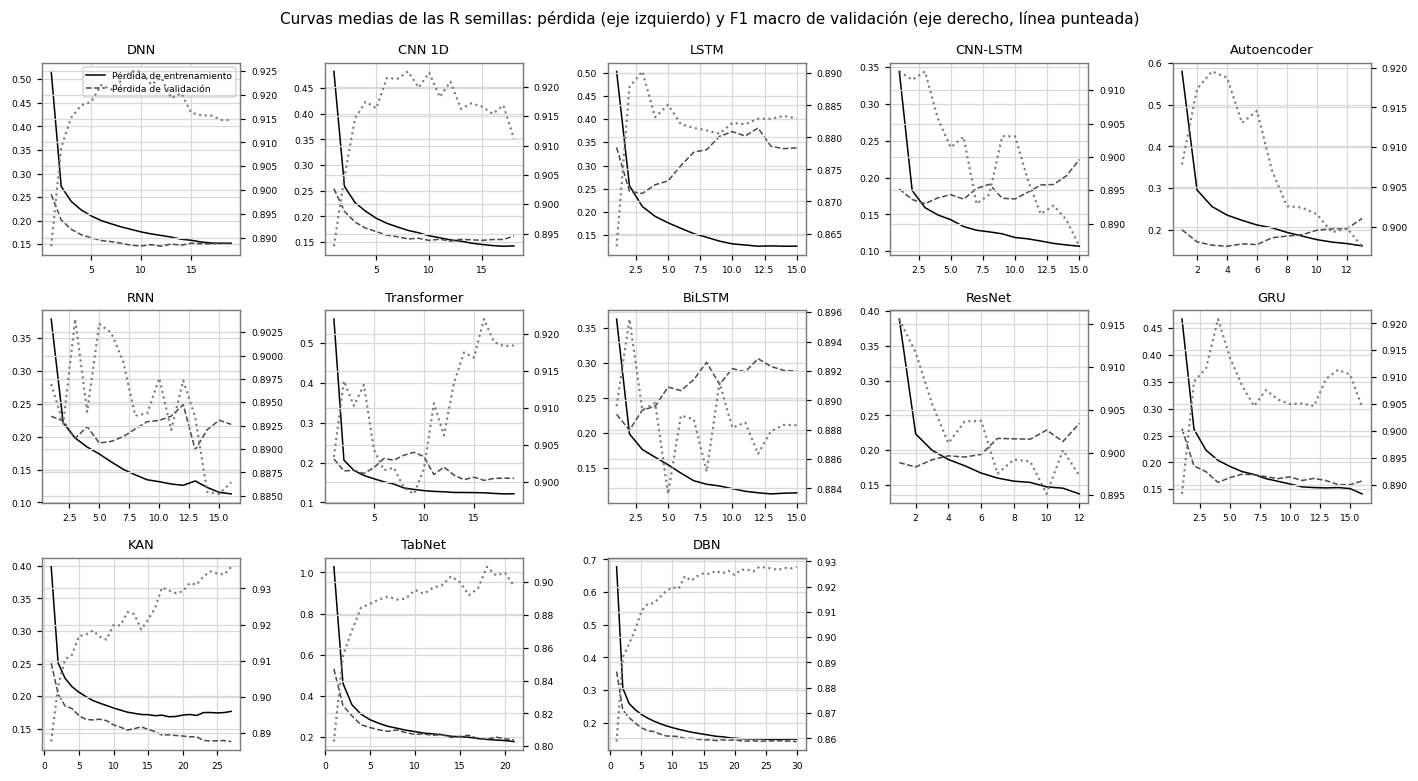

Modelo,Parámetros,MAC,Épocas,Mejor época,Minutos,Latencia por muestra (ms),ms por muestra en lote,Memoria pico del proceso (MB),FLOPs,Muestras por segundo,kWh estimados (R corridas)
DNN,12 677,12 448,"15,3","9,3","0,68","0,400","0,0017",829,24 896,589 797,"0,0007"
CNN 1D,39 493,132 928,"15,2","9,2","1,97","1,594","0,0254",819,265 856,39 389,"0,0020"
LSTM,17 477,266 560,"9,3","3,4","2,63","2,115","0,0487",819,533 120,20 514,"0,0026"
CNN-LSTM,46 213,462 144,"9,6","3,6","3,39","3,206","0,0645",824,924 288,15 511,"0,0034"
Autoencoder,19 093,9 536,"10,5","4,5","0,59","0,298","0,0012",819,19 072,809 717,"0,0006"
RNN,38 277,469 632,"10,1","4,0","3,75","4,532","0,0443",829,939 264,22 598,"0,0038"
Transformer,3 381,11 072,"9,8","3,8","0,86","1,348","0,0175",829,22 144,57 014,"0,0009"
BiLSTM,530 693,8 406 272,"9,1","3,1","33,87","10,539","0,9625",824,16 812 544,1 039,"0,0339"
ResNet,14 245,13 472,"8,7","2,7","0,81","0,890","0,0024",819,26 944,420 875,"0,0008"
GRU,96 901,1 391 232,"11,1","5,1","14,78","12,616","0,2105",824,2 782 464,4 751,"0,0148"


Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel, 10 hilos disponibles; cada corrida usó 2 hilos. Energía estimada con la potencia base del procesador (15 W) repartida entre los 10 núcleos.


In [46]:
cur = RES.curvas("definitiva")
fig, ejes = plt.subplots(3, 5, figsize=(13, 7.2), sharey=False)
for eje, m in zip(ejes.ravel(), PROFUNDOS):
    c = cur[cur["modelo"] == m]
    agg = c.groupby("epoca")[["perdida_ent", "perdida_val", "f1_val"]].mean()
    eje.plot(agg.index, agg["perdida_ent"], color=NEGRO, lw=1, label="Pérdida de entrenamiento")
    eje.plot(agg.index, agg["perdida_val"], color=GRIS_OSCURO, ls="--", lw=1, label="Pérdida de validación")
    eje2 = eje.twinx()
    eje2.plot(agg.index, agg["f1_val"], color=GRIS_MEDIO, ls=":", lw=1.4, label="F1 de validación")
    eje2.tick_params(labelsize=6)
    eje.set_title(m, fontsize=8.5)
    eje.tick_params(labelsize=6)
for eje in ejes.ravel()[len(PROFUNDOS):]:
    eje.axis("off")
ejes[0, 0].legend(fontsize=6, loc="upper right")
fig.suptitle("Curvas medias de las R semillas: pérdida (eje izquierdo) y F1 macro de validación (eje derecho, línea punteada)", fontsize=10)
plt.tight_layout()
plt.show()
costo = METRICAS.groupby("modelo").agg(Parámetros=("parametros", "first"), MAC=("mac", "first"), Épocas=("epocas", "mean"), Mejor_época=("mejor_epoca", "mean"),
                                       Minutos=("segundos", lambda s: s.mean() / 60), ms_por_muestra=("ms_por_muestra", "median"), ms_lote=("ms_por_muestra_lote", "median"),
                                       Memoria_MB=("memoria_pico_mb", "median")).loc[ORDEN]
costo["FLOPs"] = 2 * costo["MAC"]
costo["Muestras por segundo"] = 1000 / costo["ms_lote"]
ENERGIA_W = 15.0
costo["kWh estimados (R corridas)"] = costo["Minutos"] * 60 * R * ENERGIA_W / 3.6e6 * 2 / 10
tabla(costo.reset_index(names="Modelo").rename(columns={"Mejor_época": "Mejor época", "ms_por_muestra": "Latencia por muestra (ms)", "ms_lote": "ms por muestra en lote", "Memoria_MB": "Memoria pico del proceso (MB)"}),
      {"Parámetros": "{:,.0f}", "MAC": "{:,.0f}", "FLOPs": "{:,.0f}", "Épocas": "{:.1f}", "Mejor época": "{:.1f}", "Minutos": "{:.2f}", "Latencia por muestra (ms)": "{:.3f}",
       "ms por muestra en lote": "{:.4f}", "Memoria pico del proceso (MB)": "{:.0f}", "Muestras por segundo": "{:,.0f}", "kWh estimados (R corridas)": "{:.4f}"})
print(f"Hardware: {platform.processor()}, {torch.get_num_threads()} hilos disponibles; cada corrida usó 2 hilos. Energía estimada con la potencia base del procesador ({ENERGIA_W:g} W) repartida entre los 10 núcleos.")

**Fichas de modelo y registro de experimentos.** La tabla sigue la plantilla 11.3 del enunciado para los 16 modelos, y el registro consolidado de todas las corridas, de todas las fases, con su configuración, semilla y resultados, queda en `resultados/registro_experimentos.csv`. Ningún modelo congela capas ni usa pesos preentrenados, de modo que los parámetros totales y los entrenables coinciden; en los cuatro modelos con búsqueda de arquitectura, la ficha indica además cuántos finalistas son equivalentes a la ganadora por TOST, que es el tamaño del conjunto de indistinguibles de la sección 4.3.2.

In [47]:
fases_registro = ["ajuste", "piloto", "ruido", "fase1", "fase2", "definitiva", "cv5x2", "ablacion", "curvas", "permutacion", "bootstrap"]
registro_exp = pd.concat([RES.tabla_fase(f) for f in fases_registro if len(RES.tabla_fase(f))], ignore_index=True)
columnas_reg = [c for c in ["id", "fase", "modelo", "semilla", "arquitectura", "hp_lr", "hp_weight_decay", "hp_batch", "particion", "max_epocas", "epocas", "mejor_epoca", "divergente",
                            "f1_ent", "f1_val", "f1_eva", "segundos", "memoria_pico_mb", "equipo"] if c in registro_exp.columns]
registro_exp[columnas_reg].to_csv(RESULTADOS / "registro_experimentos.csv", index=False, encoding="utf-8-sig")
DOI_FUENTE = {"DNN": "10.1109/cns66487.2025.11194990", "CNN 1D": "10.1109/cns66487.2025.11194990", "LSTM": "10.1109/cns66487.2025.11194990", "RNN": "10.1038/s41598-026-45063-6",
              "GRU": "10.1038/s41598-026-45063-6", "Transformer": "10.1038/s41598-026-45063-6", "BiLSTM": "ijisae.org/index.php/IJISAE/article/view/8549", "KAN": "10.1016/j.sysarc.2026.104038",
              "TabNet": "10.1609/aaai.v35i8.16826", "ResNet": "10.1109/cvpr.2016.90", "Autoencoder": "10.1126/science.1127647", "DBN": "10.1162/neco.2006.18.7.1527",
              "CNN-LSTM": "10.1109/cvpr.2015.7298878", "LightGBM": "lightgbm 4.7.0", "Logística": "scikit-learn 1.9.0", "Trivial": "Clase mayoritaria"}
commit = subprocess.run(["git", "-C", str(RAIZ_E2), "log", "-1", "--format=%h", "--", "codigo"], capture_output=True, text=True).stdout.strip() or "sin repositorio"
def intervalo_explorado(espacio):
    # Rango de cada hiperparámetro de la rejilla del preregistro, del menor al mayor valor
    return "; ".join(f"{NOMBRE_HP.get(k, k)} {cientifico(min(v)) if isinstance(min(v), float) else min(v)}–{cientifico(max(v)) if isinstance(max(v), float) else max(v)}" for k, v in espacio.items())
ESPACIO_AJUSTE = {"LightGBM": CONFIG["ajuste"]["espacio_lightgbm"], "Logística": CONFIG["ajuste"]["espacio_logistica"]}
EQUIV_TOST = FASE2.set_index("Modelo")["Equivalentes por TOST"].to_dict()
HARDWARE = f"CPU {platform.processor().split(',')[-1].strip()}, 2 hilos por corrida"
fichas = []
for m in ORDEN:
    sub_m = METRICAS[METRICAS["modelo"] == m]
    arq = ADENDA.get("arquitecturas_ganadoras", {}).get(m)
    fichas.append({"Modelo": m, "Familia": MOD.CATALOGO[m]["familia"] if m in MOD.CATALOGO else "No profundo", "Referencia o versión": DOI_FUENTE[m], "Implementación": f"codigo/, commit {commit}",
                   "Preentrenamiento": "Ninguno", "Parámetros (totales = entrenables)": costo.loc[m, "Parámetros"], "FLOPs por muestra": costo.loc[m, "FLOPs"],
                   "Hiperparámetros finales": ", ".join(f"{k} {cientifico(v)}" if isinstance(v, float) else f"{k} {v}" for k, v in MEJORES_HP.get(m, {}).items()) or "No aplica",
                   "Intervalo explorado": intervalo_explorado(ESPACIO_AJUSTE.get(m, CONFIG["ajuste"]["espacio_profundos"])) if m != "Trivial" else "No aplica",
                   "Intentos de ajuste": int((ajuste["modelo"] == m).sum()), "Minutos de ajuste": ajuste.loc[ajuste["modelo"] == m, "segundos"].sum() / 60,
                   "Arquitectura seleccionada": MOD.identificador(arq) if arq else "Definida en la literatura" if m in MOD.CATALOGO else "No aplica",
                   "Finalistas equivalentes (TOST)": EQUIV_TOST.get(m, "No aplica"),
                   "Entrenamiento": "Adam, ReduceLROnPlateau, parada por F1 de validación, float32" if m in MOD.CATALOGO else "Parada por log-loss de validación" if m == "LightGBM" else "lbfgs" if m == "Logística" else "No aplica",
                   "Épocas efectivas (media)": costo.loc[m, "Épocas"], "Minutos por corrida": costo.loc[m, "Minutos"], "Latencia (ms)": costo.loc[m, "ms_por_muestra"],
                   "Memoria pico (MB)": costo.loc[m, "Memoria_MB"], "Hardware": HARDWARE,
                   "Corridas definitivas": len(sub_m), "Incidencias": f"{int(registro_exp.loc[registro_exp['modelo'] == m, 'divergente'].fillna(False).astype(bool).sum())} corridas divergentes"})
FICHAS = pd.DataFrame(fichas)
FICHAS.to_csv(RESULTADOS / "fichas_de_modelo.csv", index=False, encoding="utf-8-sig")
tabla(FICHAS, {"Parámetros (totales = entrenables)": "{:,.0f}", "FLOPs por muestra": "{:,.0f}", "Minutos de ajuste": "{:.1f}", "Épocas efectivas (media)": "{:.1f}", "Minutos por corrida": "{:.2f}",
               "Latencia (ms)": "{:.3f}", "Memoria pico (MB)": "{:.0f}"})
print(f"Registro de experimentos: {len(registro_exp):,} corridas en {registro_exp['fase'].nunique()} fases".replace(",", " "))

Modelo,Familia,Referencia o versión,Implementación,Preentrenamiento,Parámetros (totales = entrenables),FLOPs por muestra,Hiperparámetros finales,Intervalo explorado,Intentos de ajuste,Minutos de ajuste,Arquitectura seleccionada,Finalistas equivalentes (TOST),Entrenamiento,Épocas efectivas (media),Minutos por corrida,Latencia (ms),Memoria pico (MB),Hardware,Corridas definitivas,Incidencias
DNN,Perceptrón multicapa,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,12 677,24 896,"lr 10⁻³, weight_decay 0, batch 256",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"6,3",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","15,3","0,68","0,400",829,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
CNN 1D,Convolucional,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,39 493,265 856,"lr 10⁻³, weight_decay 0, batch 512",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"23,1",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","15,2","1,97","1,594",819,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
LSTM,Recurrente,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,17 477,533 120,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 128",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"40,1",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,3","2,63","2,115",819,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
CNN-LSTM,Híbrida,10.1109/cvpr.2015.7298878,"codigo/, commit 585802a",Ninguno,46 213,924 288,"lr 3 × 10⁻³, weight_decay 0, batch 256",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"47,7",w64-64-64_d010,13,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,6","3,39","3,206",824,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
Autoencoder,Codificador-decodificador,10.1126/science.1127647,"codigo/, commit 585802a",Ninguno,19 093,19 072,"lr 3 × 10⁻³, weight_decay 0, batch 256",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"9,6",w64-64-64_d010,8,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","10,5","0,59","0,298",819,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
RNN,Recurrente,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,38 277,939 264,"lr 3 × 10⁻³, weight_decay 10⁻⁴, batch 512",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"157,6",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","10,1","3,75","4,532",829,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
Transformer,Atención,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,3 381,22 144,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 512",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"13,5",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,8","0,86","1,348",829,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
BiLSTM,Recurrente,ijisae.org/index.php/IJISAE/article/view/8549,"codigo/, commit 585802a",Ninguno,530 693,16 812 544,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 128",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"608,1",Definida en la literatura,No aplica,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,1","33,87","10,539",824,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
ResNet,Residual,10.1109/cvpr.2016.90,"codigo/, commit 585802a",Ninguno,14 245,26 944,"lr 10⁻³, weight_decay 0, batch 256",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"14,6",w64-32-32_d011,15,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","8,7","0,81","0,890",819,"CPU GenuineIntel, 2 hilos por corrida",20,0 corridas divergentes
GRU,Recurrente,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,96 901,2 782 464,"lr 10⁻³, weight_decay 0, batch 256",lr 10⁻⁴–3 × 10⁻³; wd 0–10⁻⁴; lote 128–512,12,"228,6",Definida en la literatura,N

Registro de experimentos: 6 471 corridas en 11 fases


**Ajuste, sobreajuste y consistencia entre validación y prueba.** Para cada modelo se calcula la brecha entre entrenamiento y validación, $g = s_{ent} - s_{val}$, y se prueba la hipótesis de no inferioridad de la tabla B: $H_0$: la mediana de $g$ es al menos δg = 0,05, frente a $H_1$: es menor, con Wilcoxon unilateral sobre $g - δ_g$ en las R semillas. La diferencia entre validación y prueba se estima con su IC 95 % por *bootstrap* por bloques, remuestreando por separado los bloques de cada conjunto, porque son series distintas.

In [48]:
NB_ENT = len(np.unique(bloques[ID_ENT]))
NB_VAL = len(np.unique(bloques[ID_VAL]))
NB_PRU = len(np.unique(bloques[ID_PRU]))
W_VAL, W_PRU = AN.pesos_bootstrap(NB_VAL, semilla=1), AN.pesos_bootstrap(NB_PRU, semilla=2)
def f1_bootstrap(modelo, conjunto):
    filas_m = METRICAS[METRICAS["modelo"] == modelo]
    W = W_VAL if conjunto == "val" else W_PRU
    return np.mean([AN.f1_desde_conteos(W @ CONF_BLOQUES[f"{i}|{conjunto}"]) for i in filas_m["id"]], 0)
brechas = []
for m in ORDEN:
    sub_m = METRICAS[METRICAS["modelo"] == m]
    g = (sub_m["f1_ent"] - sub_m["validación F1 macro"]).to_numpy()
    p_g = stats.wilcoxon(g - DELTA_G, alternative="less").pvalue if np.any(g != DELTA_G) else 1.0
    dif_boot = f1_bootstrap(m, "val") - f1_bootstrap(m, "eva")
    brechas.append({"Modelo": m, "F1 de entrenamiento": sub_m["f1_ent"].mean(), "F1 de validación": sub_m["validación F1 macro"].mean(), "F1 de prueba": sub_m["prueba F1 macro"].mean(),
                    "Brecha g": g.mean(), "p Wilcoxon (g < δg)": p_g, "Validación − prueba": sub_m["validación F1 macro"].mean() - sub_m["prueba F1 macro"].mean(),
                    "IC 95 % por bloques": intervalo(E.ic_percentil(dif_boot))})
BRECHAS = pd.DataFrame(brechas)
tabla(BRECHAS, {"F1 de entrenamiento": "{:.4f}", "F1 de validación": "{:.4f}", "F1 de prueba": "{:.4f}", "Brecha g": "{:+.4f}", "p Wilcoxon (g < δg)": "{:.2e}", "Validación − prueba": "{:+.4f}"})
bp = BRECHAS[BRECHAS["Modelo"].isin(PROFUNDOS)]
vp = BRECHAS.set_index("Modelo")["Validación − prueba"]
caida_dl, caida_lgbm, caida_log = vp.loc[PROFUNDOS].median(), vp.get("LightGBM", np.nan), vp.get("Logística", np.nan)
if caida_dl > DELTA and caida_lgbm < caida_dl / 2:
    lectura_caida = (f"la caída entre validación y prueba es común a los modelos profundos (mediana de {num(caida_dl, 4)}) y a la regresión logística ({num(caida_log, 4)}), pero mucho menor en LightGBM "
                     f"({num(caida_lgbm, 4)}). Es decir, depende de qué series cayeron en cada conjunto y también del tipo de modelo: una hipótesis, que la sección 6.3 contrasta con la validación cruzada, "
                     "es que los árboles, que parten cada atributo por umbrales, son menos sensibles a los cambios de escala y de forma de las distribuciones entre series que las redes y el modelo lineal, "
                     "que dependen de combinaciones continuas de los atributos")
elif caida_dl > DELTA:
    lectura_caida = ("la caída entre validación y prueba es común a casi todos los modelos, incluidos los que no se seleccionaron con validación, como la regresión logística, de modo que se explica más "
                     "por qué series cayeron en cada conjunto que por un sobreajuste a la validación")
else:
    lectura_caida = "la caída entre validación y prueba es pequeña, de modo que la prueba es consistente con la validación"
con_ic_cero = [f["Modelo"] for _, f in BRECHAS.iterrows() if float(f["IC 95 % por bloques"].strip("[]").split("; ")[0].replace(",", ".")) <= 0 <= float(f["IC 95 % por bloques"].strip("[]").split("; ")[1].replace(",", "."))]
interpretar(f'''**Interpretación.** En los 13 modelos profundos, la brecha entre entrenamiento y validación va de {num(bp["Brecha g"].min(), 4)} ({bp.loc[bp["Brecha g"].idxmin(), "Modelo"]}) a {num(bp["Brecha g"].max(), 4)} ({bp.loc[bp["Brecha g"].idxmax(), "Modelo"]}), y la prueba de no inferioridad confirma que es menor que δg = 0,05 en {int((bp["p Wilcoxon (g < δg)"] < ALFA).sum())} de ellos. La diferencia entre validación y prueba va de {num(BRECHAS["Validación − prueba"].min(), 4)} a {num(BRECHAS["Validación − prueba"].max(), 4)}, y su IC por bloques contiene al cero en {len(con_ic_cero)} de los {len(BRECHAS)} modelos.

Esto significa que {"ningún modelo sobreajusta el entrenamiento más allá del margen" if (bp["p Wilcoxon (g < δg)"] < ALFA).all() else "algunos modelos no demuestran una brecha menor que el margen"}, y que {lectura_caida}. Hay que tener en cuenta que, con solo {NB_VAL} bloques de validación y {NB_PRU} de prueba, el intervalo por bloques es amplio, porque la unidad independiente es la serie y no el flujo.

Por tal motivo, se reporta el desempeño de prueba con su intervalo por bloques en la tabla principal, y la brecha entre validación y prueba entra en el criterio de adecuación de la sección 7.''')

Modelo,F1 de entrenamiento,F1 de validación,F1 de prueba,Brecha g,p Wilcoxon (g < δg),Validación − prueba,IC 95 % por bloques
DNN,"0,9306","0,9283","0,8577","+0,0023","9,54e-07","+0,0706","[-0,0456; 0,1921]"
CNN 1D,"0,9331","0,9299","0,8584","+0,0032","9,54e-07","+0,0715","[-0,0408; 0,1930]"
LSTM,"0,9155","0,9037","0,8285","+0,0118","9,54e-07","+0,0752","[-0,0560; 0,1995]"
CNN-LSTM,"0,9343","0,9244","0,8626","+0,0099","9,54e-07","+0,0619","[-0,0570; 0,1849]"
Autoencoder,"0,9297","0,9275","0,8591","+0,0022","9,54e-07","+0,0685","[-0,0431; 0,1904]"
RNN,"0,9229","0,9191","0,8371","+0,0038","9,54e-07","+0,0820","[-0,0285; 0,2029]"
Transformer,"0,9286","0,9219","0,8576","+0,0068","9,54e-07","+0,0642","[-0,0443; 0,1867]"
BiLSTM,"0,9243","0,9089","0,8457","+0,0154","2,86e-06","+0,0632","[-0,0597; 0,1854]"
ResNet,"0,9254","0,9225","0,8510","+0,0030","9,54e-07","+0,0715","[-0,0427; 0,1929]"
GRU,"0,9266","0,9252","0,8474","+0,0014","9,54e-07","+0,0778","[-0,0374; 0,2010]"


**Interpretación.** En los 13 modelos profundos, la brecha entre entrenamiento y validación va de -0,0019 (KAN) a 0,0154 (BiLSTM), y la prueba de no inferioridad confirma que es menor que δg = 0,05 en 13 de ellos. La diferencia entre validación y prueba va de 0,0025 a 0,0937, y su IC por bloques contiene al cero en 16 de los 16 modelos.

Esto significa que ningún modelo sobreajusta el entrenamiento más allá del margen, y que la caída entre validación y prueba es común a los modelos profundos (mediana de 0,0715) y a la regresión logística (0,0937), pero mucho menor en LightGBM (0,0123). Es decir, depende de qué series cayeron en cada conjunto y también del tipo de modelo: una hipótesis, que la sección 6.3 contrasta con la validación cruzada, es que los árboles, que parten cada atributo por umbrales, son menos sensibles a los cambios de escala y de forma de las distribuciones entre series que las redes y el modelo lineal, que dependen de combinaciones continuas de los atributos. Hay que tener en cuenta que, con solo 19 bloques de validación y 24 de prueba, el intervalo por bloques es amplio, porque la unidad independiente es la serie y no el flujo.

Por tal motivo, se reporta el desempeño de prueba con su intervalo por bloques en la tabla principal, y la brecha entre validación y prueba entra en el criterio de adecuación de la sección 7.

Modelo,T,ECE,ECE con T,ECE adaptativo,ECE adaptativo con T,Brier,Brier con T
DNN,"0,9500","0,0499","0,0507","0,0496","0,0502","0,2209","0,2211"
CNN 1D,"0,9527","0,0492","0,0506","0,0486","0,0498","0,2188","0,2191"
LSTM,"1,0078","0,0553","0,0585","0,0543","0,0574","0,2513","0,2520"
CNN-LSTM,"0,9895","0,0467","0,0476","0,0457","0,0469","0,2055","0,2057"
Autoencoder,"1,0009","0,0485","0,0489","0,0480","0,0484","0,2168","0,2170"
RNN,"1,0346","0,0638","0,0624","0,0635","0,0619","0,2482","0,2478"
Transformer,"1,0425","0,0484","0,0490","0,0480","0,0485","0,2171","0,2172"
BiLSTM,"1,1005","0,0506","0,0490","0,0496","0,0486","0,2258","0,2255"
ResNet,"0,9663","0,0540","0,0542","0,0530","0,0534","0,2298","0,2299"
GRU,"0,9612","0,0528","0,0544","0,0527","0,0541","0,2312","0,2318"


**Interpretación.** Sin recalibrar, el ECE de los modelos profundos va de 0,0467 (CNN-LSTM) a 0,0638 (RNN), y el de LightGBM es de 0,0356. La temperatura ajustada en validación es mayor que 1 en 5 de los 13 modelos profundos, y con ella el ECE medio pasa de 0,0523 a 0,0534; la versión adaptativa, con bins de igual tamaño, cambia de 0,0518 a 0,0528.

Lo anterior indica que la mayoría de los modelos profundos es subconfiada en validación, porque la temperatura que la corrige, menor que 1, agudiza las probabilidades, lo que es coherente con la pérdida ponderada por clase, que empuja probabilidad hacia las clases minoritarias, y que una sola temperatura ajustada en validación no mejora la calibración en prueba, lo que es coherente con que validación y prueba sean series distintas. Las temperaturas quedan entre 0,90 y 1,10, muy cerca de 1, de modo que en validación los modelos ya están casi calibrados y el ECE de prueba refleja sobre todo el cambio entre series. Así mismo, el ECE adaptativo confirma la lectura del de bins fijos, de modo que la conclusión no depende de la discretización.

Por lo anterior, conviene usar las probabilidades sin recalibrar, porque la temperatura de validación no las mejora en series nuevas, y declarar en el criterio de adecuación cuáles modelos quedan calibrados; recalibrar con datos de la serie de destino queda como requisito de una puesta en producción.

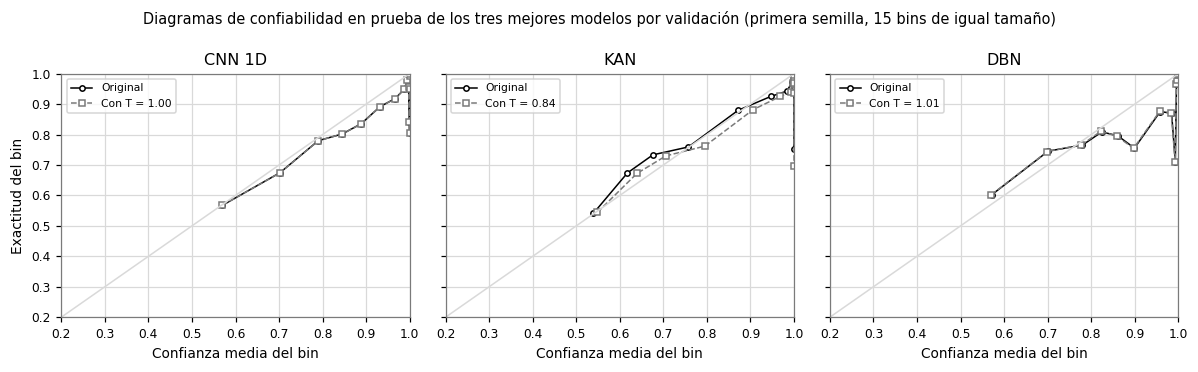

In [49]:
calib = []
for m in ORDEN:
    if m == "Trivial":
        continue
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        r = next(x for x in DEF if x["id"] == i)
        p_val, p_eva = AN.prob(r, "val"), AN.prob(r, "eva")
        T = E.escalar_temperatura(E.logits_de(p_val), y[ID_VAL])
        p_cal = E.suavizar(p_eva, T)
        calib.append({"modelo": m, "semilla": r["semilla"], "T": T, "ECE": E.ece(p_eva, y[ID_PRU]), "ECE con T": E.ece(p_cal, y[ID_PRU]), "ECE adaptativo": E.ece(p_eva, y[ID_PRU], adaptativo=True),
                      "ECE adaptativo con T": E.ece(p_cal, y[ID_PRU], adaptativo=True), "Brier": E.brier(p_eva, y[ID_PRU]), "Brier con T": E.brier(p_cal, y[ID_PRU])})
CALIB = pd.DataFrame(calib)
tabla(CALIB.groupby("modelo").mean(numeric_only=True).drop(columns="semilla").loc[[m for m in ORDEN if m != "Trivial"]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ["T", "ECE", "ECE con T", "ECE adaptativo", "ECE adaptativo con T", "Brier", "Brier con T"]})
cal_m = CALIB.groupby("modelo").mean(numeric_only=True)
cal_p = cal_m.loc[PROFUNDOS]
interpretar(f'''**Interpretación.** Sin recalibrar, el ECE de los modelos profundos va de {num(cal_p["ECE"].min(), 4)} ({cal_p["ECE"].idxmin()}) a {num(cal_p["ECE"].max(), 4)} ({cal_p["ECE"].idxmax()}), y el de LightGBM es de {num(cal_m.loc["LightGBM", "ECE"], 4)}. La temperatura ajustada en validación es mayor que 1 en {int((cal_p["T"] > 1).sum())} de los 13 modelos profundos, y con ella el ECE medio pasa de {num(cal_p["ECE"].mean(), 4)} a {num(cal_p["ECE con T"].mean(), 4)}; la versión adaptativa, con bins de igual tamaño, cambia de {num(cal_p["ECE adaptativo"].mean(), 4)} a {num(cal_p["ECE adaptativo con T"].mean(), 4)}.

Lo anterior indica que {"la mayoría de los modelos profundos es sobreconfiada en validación, porque la temperatura que la corrige, mayor que 1, suaviza las probabilidades" if (cal_p["T"] > 1).sum() > 6 else "la mayoría de los modelos profundos es subconfiada en validación, porque la temperatura que la corrige, menor que 1, agudiza las probabilidades, lo que es coherente con la pérdida ponderada por clase, que empuja probabilidad hacia las clases minoritarias" if (cal_p["T"] < 1).sum() > 6 else "los modelos profundos se reparten entre sobreconfiados y subconfiados en validación"}, y que una sola temperatura ajustada en validación {"corrige buena parte del error de calibración en prueba" if cal_p["ECE con T"].mean() < cal_p["ECE"].mean() else "no mejora la calibración en prueba, lo que es coherente con que validación y prueba sean series distintas"}. {f"Las temperaturas quedan entre {num(cal_p['T'].min(), 2)} y {num(cal_p['T'].max(), 2)}, muy cerca de 1, de modo que en validación los modelos ya están casi calibrados y el ECE de prueba refleja sobre todo el cambio entre series. " if (cal_p["T"] - 1).abs().max() <= 0.12 else ""}Así mismo, el ECE adaptativo {"confirma la lectura del de bins fijos, de modo que la conclusión no depende de la discretización" if np.sign(cal_p["ECE con T"].mean() - cal_p["ECE"].mean()) == np.sign(cal_p["ECE adaptativo con T"].mean() - cal_p["ECE adaptativo"].mean()) else "cambia en sentido contrario al de bins fijos, de modo que la conclusión sobre la temperatura depende de la discretización"}.

{"Por lo anterior, conviene reportar las probabilidades con la temperatura de validación cuando se usen como puntaje de riesgo, y declarar en el criterio de adecuación cuáles modelos quedan calibrados." if cal_p["ECE con T"].mean() < cal_p["ECE"].mean() else "Por lo anterior, conviene usar las probabilidades sin recalibrar, porque la temperatura de validación no las mejora en series nuevas, y declarar en el criterio de adecuación cuáles modelos quedan calibrados; recalibrar con datos de la serie de destino queda como requisito de una puesta en producción."}''')
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for eje, m in zip(ejes, TOP3):
    r = next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0])
    p_eva = AN.prob(r, "eva")
    T = E.escalar_temperatura(E.logits_de(AN.prob(r, "val")), y[ID_VAL])
    for p, estilo, etq in ((p_eva, dict(color=NEGRO, marker="o"), "Original"), (E.suavizar(p_eva, T), dict(color=GRIS_MEDIO, marker="s", ls="--"), f"Con T = {T:.2f}")):
        conf, acierto = p.max(1), p.argmax(1) == y[ID_PRU]
        cortes = np.quantile(conf, np.linspace(0, 1, 16))
        idx = np.clip(np.digitize(conf, cortes[1:-1]), 0, 14)
        eje.plot([conf[idx == b].mean() for b in range(15)], [acierto[idx == b].mean() for b in range(15)], ms=3.5, lw=1, label=etq, mfc="white", **estilo)
    eje.plot([0, 1], [0, 1], color=GRIS_CLARO, lw=1)
    eje.set(title=m, xlabel="Confianza media del bin", xlim=(0.2, 1), ylim=(0.2, 1))
    eje.legend(fontsize=7)
ejes[0].set_ylabel("Exactitud del bin")
fig.suptitle("Diagramas de confiabilidad en prueba de los tres mejores modelos por validación (primera semilla, 15 bins de igual tamaño)", fontsize=9.5)
plt.tight_layout()
plt.show()

**Calibración por clase.** La sección 12.2 del enunciado pide evaluar el ECE y la pendiente de calibración en cada subgrupo relevante, que aquí son las cinco clases. Para los tres mejores modelos por validación y LightGBM, con sus R semillas, se calcula el ECE de cada clase en esquema uno contra todos, $\mathrm{ECE}_k = \sum_b \frac{|B_b|}{n} \left| \bar{y}_{k}(B_b) - \bar{p}_{k}(B_b) \right|$, con 15 bins fijos sobre $p_k$, y la pendiente de la regresión logística de $\mathbb{1}[y = k]$ sobre el logit de $p_k$, donde una pendiente menor que 1 indica sobreconfianza en esa clase.

In [50]:
def ece_clase(p_k, y_k, bins=15):
    cortes = np.linspace(0, 1, bins + 1)
    indice = np.clip(np.digitize(p_k, cortes[1:-1]), 0, bins - 1)
    return float(sum((indice == b).mean() * abs(y_k[indice == b].mean() - p_k[indice == b].mean()) for b in range(bins) if (indice == b).any()))
MODELOS_CAL = list(dict.fromkeys(TOP3 + ["LightGBM"]))
filas_cc = []
for m in MODELOS_CAL:
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        p_eva = AN.prob(next(x for x in DEF if x["id"] == i), "eva")
        for k, clase in enumerate(CLASES):
            y_k = (y[ID_PRU] == k).astype(int)
            filas_cc.append({"modelo": m, "Clase": clase, "ECE": ece_clase(p_eva[:, k], y_k), "Pendiente": E.pendiente_intercepto(p_eva[:, k], y_k)["pendiente"]})
CAL_CLASE = pd.DataFrame(filas_cc).groupby(["Clase", "modelo"])[["ECE", "Pendiente"]].mean().unstack("modelo")
tabla_cc = pd.DataFrame({"Clase": CLASES})
for m in MODELOS_CAL:
    tabla_cc[f"ECE · {m}"] = [CAL_CLASE.loc[c, ("ECE", m)] for c in CLASES]
for m in MODELOS_CAL:
    tabla_cc[f"Pendiente · {m}"] = [CAL_CLASE.loc[c, ("Pendiente", m)] for c in CLASES]
tabla_cc.to_csv(RESULTADOS / "calibracion_por_clase.csv", index=False, encoding="utf-8-sig")
tabla(tabla_cc, {c: "{:.4f}" if c.startswith("ECE") else "{:.3f}" for c in tabla_cc.columns if c != "Clase"})
ece_por_clase = CAL_CLASE["ECE"].mean(axis=1)
pend_por_clase = CAL_CLASE["Pendiente"].mean(axis=1)
peor_clase, mejor_clase = ece_por_clase.idxmax(), ece_por_clase.idxmin()
sobreconf = [c for c in CLASES if (CAL_CLASE.loc[c, "Pendiente"] < 1).all()]
interpretar(f'''**Interpretación.** El ECE por clase, promediado entre los {len(MODELOS_CAL)} modelos, va de {num(ece_por_clase.min(), 4)} en {mejor_clase} a {num(ece_por_clase.max(), 4)} en {peor_clase}, y la pendiente media va de {num(pend_por_clase.min(), 3)} ({pend_por_clase.idxmin()}) a {num(pend_por_clase.max(), 3)} ({pend_por_clase.idxmax()}). {f"Los {len(MODELOS_CAL)} modelos tienen pendiente menor que 1 en {enumerar(sobreconf)}" if sobreconf else "Ninguna clase tiene pendiente menor que 1 en todos los modelos"}.

Esto significa que el error de calibración de la sección anterior no se reparte por igual: se concentra en {peor_clase}{", una de las dos clases de la frontera que más confunden los modelos (sección 4.5)" if peor_clase in ("Blackhole", "Wormhole") else ""}{f", y en {enumerar(sobreconf)} los modelos son sobreconfiados" if sobreconf else ""}, de modo que un ECE global aceptable puede ocultar probabilidades poco confiables en clases concretas, que son las que un analista usaría para priorizar alertas.

Por tal motivo, se opta por reportar la calibración por clase junto con la global, y por exigir al modelo original del Entregable 3 que la calibración de {peor_clase} entre en su criterio de adecuación.''')

Clase,ECE · CNN 1D,ECE · KAN,ECE · DBN,ECE · LightGBM,Pendiente · CNN 1D,Pendiente · KAN,Pendiente · DBN,Pendiente · LightGBM
Blackhole,"0,0221","0,0315","0,0220","0,0165","0,771","0,799","0,755","1,270"
Flooding,"0,0296","0,0301","0,0314","0,0452","0,368","0,357","0,448","0,841"
Normal,"0,0066","0,0070","0,0046","0,0143","1,263","1,106","1,071","1,599"
Sybil,"0,0427","0,0426","0,0449","0,0522","0,395","0,367","0,515","0,922"
Wormhole,"0,0325","0,0416","0,0319","0,0222","0,611","0,484","0,595","0,997"


**Interpretación.** El ECE por clase, promediado entre los 4 modelos, va de 0,0081 en Normal a 0,0456 en Sybil, y la pendiente media va de 0,504 (Flooding) a 1,260 (Normal). Los 4 modelos tienen pendiente menor que 1 en Flooding, Sybil y Wormhole.

Esto significa que el error de calibración de la sección anterior no se reparte por igual: se concentra en Sybil, y en Flooding, Sybil y Wormhole los modelos son sobreconfiados, de modo que un ECE global aceptable puede ocultar probabilidades poco confiables en clases concretas, que son las que un analista usaría para priorizar alertas.

Por tal motivo, se opta por reportar la calibración por clase junto con la global, y por exigir al modelo original del Entregable 3 que la calibración de Sybil entre en su criterio de adecuación.

**Estadístico KS y curva de decisión.** La sección 4.5 del enunciado agrega, para datos tabulares, el estadístico KS y la curva de decisión (*net benefit*), que se definen sobre una decisión binaria. En un detector de intrusiones esa decisión es levantar o no una alarma, de modo que se evalúa la probabilidad de ataque, $1 - p_{Normal}$, frente a la etiqueta «ataque o Normal». El KS es la distancia máxima entre las distribuciones de ese puntaje en ataques y en tráfico normal, y el beneficio neto en el umbral $t$ es $\mathrm{NB}(t) = \frac{VP}{n} - \frac{FP}{n} \cdot \frac{t}{1 - t}$, que se compara con alarmar siempre y con no alarmar nunca (Vickers y Elkin, 2006). Como estas métricas no estaban en el preregistro, el análisis es exploratorio.

Modelo,KS (media ± DE),"Beneficio neto en t = 0,5","Alarmar siempre en t = 0,5",Umbrales donde supera a ambas referencias
CNN 1D,"0,9725 ± 0,0029","0,7562","0,5369",19 de 19
KAN,"0,9720 ± 0,0056","0,7537","0,5369",19 de 19
DBN,"0,9736 ± 0,0038","0,7553","0,5369",19 de 19
LightGBM,"0,9842 ± 0,0007","0,7609","0,5369",19 de 19


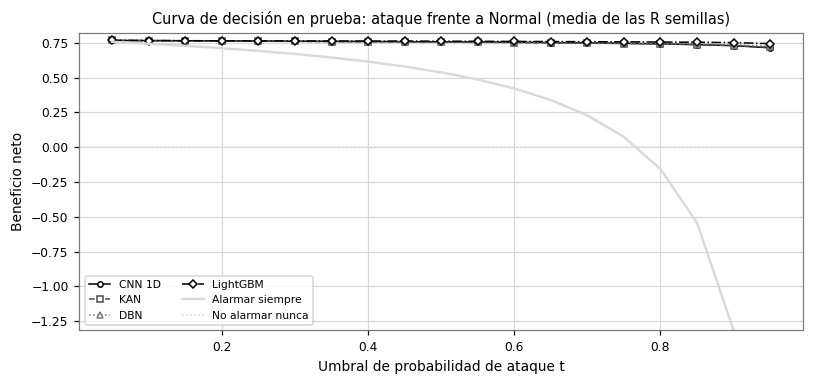

**Interpretación.** En la decisión de alarma, el KS medio es de 0,9725 (CNN 1D), 0,9720 (KAN), 0,9736 (DBN) y 0,9842 (LightGBM), y en el umbral de 0,5 el mayor beneficio neto es el de LightGBM, con 0,7609, frente a 0,5369 de alarmar siempre. La prevalencia de ataques en prueba es de 76,8 %.

Es decir, los 4 modelos superan a las dos referencias en los 19 umbrales, y la ventaja media sobre alarmar siempre pasa de 0,0102 en t = 0,05 a 0,2196 en t = 0,5: con una prevalencia de ataques de 76,8 %, alarmar siempre es casi tan bueno como un modelo cuando una falsa alarma cuesta poco, y pierde valor a medida que la falsa alarma pesa más.

Por lo anterior, conviene que el Entregable 3 fije el umbral de alarma en validación según el costo relativo de una falsa alarma y de un ataque no detectado, y reporte la curva de decisión junto con el F1 macro, que no distingue entre esos dos errores.

In [51]:
i_normal = CLASES.index("Normal")
y_ataque = (y[ID_PRU] != i_normal).astype(int)
prev_ataque = y_ataque.mean()
UMBRALES_NB = np.round(np.arange(0.05, 0.96, 0.05), 2)
nb_todos = prev_ataque - (1 - prev_ataque) * UMBRALES_NB / (1 - UMBRALES_NB)
filas_ks, curvas_nb = [], {}
for m in MODELOS_CAL:
    ks_m, nb_m = [], []
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        s = 1 - AN.prob(next(x for x in DEF if x["id"] == i), "eva")[:, i_normal]
        ks_m.append(stats.ks_2samp(s[y_ataque == 1], s[y_ataque == 0]).statistic)
        nb_m.append([((s >= t) & (y_ataque == 1)).mean() - ((s >= t) & (y_ataque == 0)).mean() * t / (1 - t) for t in UMBRALES_NB])
    curvas_nb[m] = np.mean(nb_m, 0)
    supera = curvas_nb[m] > np.maximum(nb_todos, 0)
    filas_ks.append({"Modelo": m, "KS (media ± DE)": f"{num(np.mean(ks_m), 4)} ± {num(np.std(ks_m, ddof=1), 4)}", "Beneficio neto en t = 0,5": curvas_nb[m][UMBRALES_NB == 0.5][0],
                     "Alarmar siempre en t = 0,5": nb_todos[UMBRALES_NB == 0.5][0], "Umbrales donde supera a ambas referencias": f"{int(supera.sum())} de {len(UMBRALES_NB)}"})
DECISION_BIN = pd.DataFrame(filas_ks)
DECISION_BIN.to_csv(RESULTADOS / "ks_y_beneficio_neto.csv", index=False, encoding="utf-8-sig")
tabla(DECISION_BIN, {"Beneficio neto en t = 0,5": "{:.4f}", "Alarmar siempre en t = 0,5": "{:.4f}"})
fig, eje = plt.subplots(figsize=(7.5, 3.6))
for j, m in enumerate(MODELOS_CAL):
    eje.plot(UMBRALES_NB, curvas_nb[m], color=[NEGRO, GRIS_OSCURO, GRIS_MEDIO, NEGRO][j % 4], ls=LINEAS[j % len(LINEAS)], marker=MARCADORES[j % len(MARCADORES)], ms=3.5, mfc="white", lw=1, label=m)
eje.plot(UMBRALES_NB, nb_todos, color=GRIS_CLARO, lw=1.6, label="Alarmar siempre")
eje.axhline(0, color=GRIS_CLARO, lw=1, ls=":", label="No alarmar nunca")
eje.set(xlabel="Umbral de probabilidad de ataque t", ylabel="Beneficio neto", ylim=(min(-0.1, float(np.min(nb_todos[UMBRALES_NB <= 0.9]))), prev_ataque + 0.05))
eje.legend(fontsize=7, ncol=2)
eje.set_title("Curva de decisión en prueba: ataque frente a Normal (media de las R semillas)", fontsize=9.5)
plt.tight_layout()
plt.show()
mejor_nb = DECISION_BIN.loc[DECISION_BIN["Beneficio neto en t = 0,5"].idxmax(), "Modelo"]
n_supera = [int(f.split(" de ")[0]) for f in DECISION_BIN["Umbrales donde supera a ambas referencias"]]
ventaja_nb = np.mean([curvas_nb[m] - nb_todos for m in MODELOS_CAL], 0)
lectura_supera = (f"los {len(MODELOS_CAL)} modelos superan a las dos referencias en los {len(UMBRALES_NB)} umbrales" if min(n_supera) == len(UMBRALES_NB)
                  else f"los modelos superan a las dos referencias en {min(n_supera)} a {max(n_supera)} de los {len(UMBRALES_NB)} umbrales")
interpretar(f'''**Interpretación.** En la decisión de alarma, el KS medio es de {enumerar([f"{r['KS (media ± DE)'].split(' ± ')[0]} ({r['Modelo']})" for _, r in DECISION_BIN.iterrows()])}, y en el umbral de 0,5 el mayor beneficio neto es el de {mejor_nb}, con {num(DECISION_BIN["Beneficio neto en t = 0,5"].max(), 4)}, frente a {num(nb_todos[UMBRALES_NB == 0.5][0], 4)} de alarmar siempre. La prevalencia de ataques en prueba es de {num(100 * prev_ataque, 1)} %.

Es decir, {lectura_supera}, y la ventaja media sobre alarmar siempre pasa de {num(ventaja_nb[0], 4)} en t = {num(UMBRALES_NB[0], 2)} a {num(ventaja_nb[UMBRALES_NB == 0.5][0], 4)} en t = 0,5: con una prevalencia de ataques de {num(100 * prev_ataque, 1)} %, alarmar siempre es casi tan bueno como un modelo cuando una falsa alarma cuesta poco, y pierde valor a medida que la falsa alarma pesa más.

Por lo anterior, conviene que el Entregable 3 fije el umbral de alarma en validación según el costo relativo de una falsa alarma y de un ataque no detectado, y reporte la curva de decisión junto con el F1 macro, que no distingue entre esos dos errores.''')

Modelo,Categoría,Errores,% de los errores,IC 95 % por bloques
CNN 1D,Confusión Blackhole–Wormhole,1 463,"46,7","[20,0; 82,7]"
CNN 1D,Ataque predicho como Normal,100,"3,2","[0,9; 7,9]"
CNN 1D,Normal predicho como ataque,178,"5,7","[0,4; 16,8]"
CNN 1D,Otras confusiones entre ataques,1 394,"44,5","[5,3; 73,8]"
KAN,Confusión Blackhole–Wormhole,1 414,"45,3","[21,0; 81,8]"
KAN,Ataque predicho como Normal,108,"3,5","[0,9; 8,1]"
KAN,Normal predicho como ataque,96,"3,1","[0,1; 9,7]"
KAN,Otras confusiones entre ataques,1 501,"48,1","[7,2; 74,7]"
DBN,Confusión Blackhole–Wormhole,1 576,"48,5","[20,2; 81,3]"
DBN,Ataque predicho como Normal,181,"5,6","[2,3; 12,5]"


Correlación de los errores (φ),CNN 1D,KAN,DBN,LightGBM
CNN 1D,"1,000","0,775","0,817","0,691"
KAN,"0,775","1,000","0,677","0,694"
DBN,"0,817","0,677","1,000","0,606"
LightGBM,"0,691","0,694","0,606","1,000"


**Interpretación.** En los tres mejores modelos y en LightGBM, la categoría que reúne más errores es la confusión entre Blackhole y Wormhole en CNN 1D y DBN (46,7 % a 48,5 % de sus errores) y las demás confusiones entre ataques en KAN y LightGBM (48,1 % a 54,3 % de sus errores). De los flujos en que se equivoca al menos uno de los tres mejores, el 52,5 % lo fallan los tres; la correlación de sus errores va de 0,677 a 0,817, y con LightGBM, de 0,606 a 0,694, y el promedio de sus probabilidades obtiene un F1 macro de 0,8634, frente a 0,8566 del mejor de ellos con la misma semilla; un oráculo que eligiera siempre al que acierta llegaría a una exactitud de 0,9035.

Esto quiere decir que los errores se concentran en los mismos flujos, de modo que, como advierte la sección 12.3 del enunciado, el benchmark mide sobre todo la dificultad de esos casos y no diferencias de arquitectura. En ese sentido, combinar modelos gana menos que δ, porque se equivocan juntos.

Por ello, se recomienda que el modelo original del Entregable 3 ataque la confusión entre Blackhole y Wormhole, que domina en CNN 1D y DBN y coincide con la limitación del paper guía (sección 5), en lugar de buscar más capacidad o combinar arquitecturas.

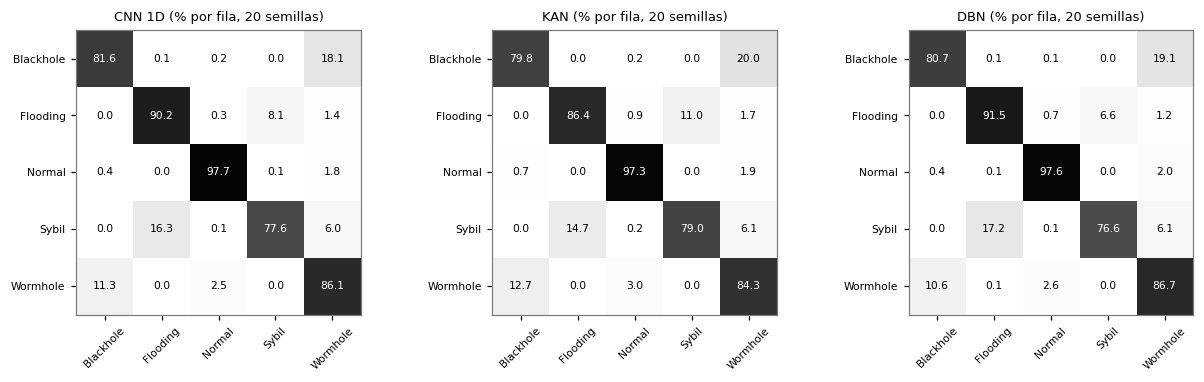

In [52]:
CATEGORIAS = {"Confusión Blackhole–Wormhole": lambda v, p: ((v == 0) & (p == 4)) | ((v == 4) & (p == 0)), "Ataque predicho como Normal": lambda v, p: (v != 2) & (p == 2),
              "Normal predicho como ataque": lambda v, p: (v == 2) & (p != 2)}
def categorias_error(v, p):
    error = v != p
    otras = error.copy()
    salida = {}
    for nombre, f in CATEGORIAS.items():
        salida[nombre] = f(v, p) & error
        otras &= ~salida[nombre]
    salida["Otras confusiones entre ataques"] = otras
    return salida, error
y_pru = y[ID_PRU]
b_pru = bloques[ID_PRU]
taxonomia, errores_por_modelo = [], {}
for m in TOP3 + ["LightGBM"]:
    r = next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0])
    p = AN.prob(r, "eva").argmax(1)
    cats, error = categorias_error(y_pru, p)
    errores_por_modelo[m] = error
    for nombre, mascara in cats.items():
        boot = E.bootstrap_bloques(lambda ix: mascara[ix].sum() / max(error[ix].sum(), 1), b_pru, repeticiones=2000)
        taxonomia.append({"Modelo": m, "Categoría": nombre, "Errores": int(mascara.sum()), "% de los errores": 100 * mascara.sum() / error.sum(), "IC 95 % por bloques": intervalo(100 * np.array(E.ic_percentil(boot)), 1)})
tabla(pd.DataFrame(taxonomia), {"% de los errores": "{:.1f}"})
todos = np.mean([errores_por_modelo[m] for m in TOP3], 0)
compartidos = float((todos == 1).sum() / max((todos > 0).sum(), 1))
correlacion = pd.DataFrame(np.corrcoef([errores_por_modelo[m].astype(float) for m in errores_por_modelo]), index=list(errores_por_modelo), columns=list(errores_por_modelo))
tabla(correlacion.reset_index(names="Correlación de los errores (φ)"), {c: "{:.3f}" for c in correlacion.columns})
promedio_top3 = np.mean([AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0]), "eva") for m in TOP3], 0)
f1_ensamble = E.f1_macro_rapido(y_pru, promedio_top3.argmax(1))
oraculo = 1 - (todos == 1).mean()
tax = pd.DataFrame(taxonomia)
dominante = tax.loc[tax.groupby("Modelo")["% de los errores"].idxmax()].set_index("Modelo")
mejor_ind = max(METRICAS.loc[(METRICAS["modelo"] == m) & (METRICAS["semilla"] == SEMILLAS[0]), "prueba F1 macro"].iloc[0] for m in TOP3)
phi = correlacion.loc[TOP3, TOP3].to_numpy()[np.triu_indices(len(TOP3), 1)]
phi_lgbm = correlacion.loc[TOP3, "LightGBM"].to_numpy()
NOMBRE_CAT = {"Confusión Blackhole–Wormhole": "la confusión entre Blackhole y Wormhole", "Otras confusiones entre ataques": "las demás confusiones entre ataques",
              "Ataque predicho como Normal": "los ataques predichos como Normal", "Normal predicho como ataque": "los flujos normales predichos como ataque"}
partes_dom = []
for cat, sub_d in dominante.groupby("Categoría"):
    pct_txt = num(sub_d["% de los errores"].iloc[0], 1) if len(sub_d) == 1 else f"{num(sub_d['% de los errores'].min(), 1)} % a {num(sub_d['% de los errores'].max(), 1)}"
    partes_dom.append(f"{NOMBRE_CAT.get(cat, cat)} en {enumerar(sub_d.index.tolist())} ({pct_txt} % de sus errores)")
concentrados = compartidos >= 0.5
gana_comb = f1_ensamble - mejor_ind > DELTA
if concentrados and not gana_comb:
    lectura_err = "Esto quiere decir que los errores se concentran en los mismos flujos, de modo que, como advierte la sección 12.3 del enunciado, el benchmark mide sobre todo la dificultad de esos casos y no diferencias de arquitectura. En ese sentido, combinar modelos gana menos que δ, porque se equivocan juntos."
elif concentrados:
    lectura_err = "Esto quiere decir que buena parte de los errores se concentra en los mismos flujos, pero el promedio de probabilidades aún gana más que δ, porque corrige los flujos en que solo uno de los tres se equivoca."
elif gana_comb:
    lectura_err = "Esto quiere decir que los errores no se concentran en los mismos flujos: cada modelo falla casos distintos, y por eso promediar sus probabilidades gana más que δ."
else:
    lectura_err = "Esto quiere decir que los errores no se concentran en los mismos flujos, pero promediar las probabilidades gana menos que δ: en los flujos en que discrepan, el promedio no siempre favorece a la clase correcta, como muestra la distancia entre el ensamble y el oráculo."
interpretar(f'''**Interpretación.** En los tres mejores modelos y en LightGBM, la categoría que reúne más errores es {enumerar(partes_dom)}. De los flujos en que se equivoca al menos uno de los tres mejores, el {num(100 * compartidos, 1)} % lo fallan los tres; la correlación de sus errores va de {num(phi.min(), 3)} a {num(phi.max(), 3)}, y con LightGBM, de {num(phi_lgbm.min(), 3)} a {num(phi_lgbm.max(), 3)}, y el promedio de sus probabilidades obtiene un F1 macro de {num(f1_ensamble, 4)}, frente a {num(mejor_ind, 4)} del mejor de ellos con la misma semilla; un oráculo que eligiera siempre al que acierta llegaría a una exactitud de {num(oraculo, 4)}.

{lectura_err}

Por ello, se recomienda que el modelo original del Entregable 3 ataque {"la confusión entre Blackhole y Wormhole, que domina en " + enumerar(dominante.index[dominante["Categoría"] == "Confusión Blackhole–Wormhole"].tolist()) + " y coincide con la limitación del paper guía (sección 5)" if "Confusión Blackhole–Wormhole" in set(dominante["Categoría"]) else "la categoría dominante"}{", en lugar de buscar más capacidad o combinar arquitecturas" if f1_ensamble - mejor_ind <= DELTA else ", y que evalúe la combinación de arquitecturas como línea base"}.''')
fig, ejes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for eje, m in zip(ejes, TOP3):
    conf_total = sum(np.bincount(K * y_pru + AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva").argmax(1), minlength=K * K).reshape(K, K) for s in SEMILLAS)
    normalizada = conf_total / conf_total.sum(1, keepdims=True)
    eje.imshow(normalizada, vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            eje.text(j, i, f"{100 * normalizada[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white" if normalizada[i, j] > 0.5 else NEGRO)
    eje.set_xticks(range(K), CLASES, rotation=45, fontsize=7)
    eje.set_yticks(range(K), CLASES, fontsize=7)
    eje.set_title(f"{m} (% por fila, {R} semillas)", fontsize=8.5)
    eje.grid(False)
plt.tight_layout()
plt.show()

Modelo,F1 Blackhole,F1 Flooding,F1 Normal,F1 Sybil,F1 Wormhole,Muy cortos,Cortos,Medianos,Largos,Con puerto 654,Sin puerto 654,Sin casi duplicado,Con casi duplicado
DNN,"0,8300","0,8082","0,9736","0,8595","0,8170","0,7475","0,8140","0,8353","0,7596","0,9940","0,8274","0,8580","0,7894"
CNN 1D,"0,8374","0,8055","0,9734","0,8548","0,8211","0,7737","0,8137","0,8278","0,7693","0,9934","0,8291","0,8588","0,7866"
LSTM,"0,8167","0,7442","0,9535","0,8238","0,8043","0,6963","0,7688","0,7885","0,7216","0,9846","0,7989","0,8287","0,7564"
CNN-LSTM,"0,8568","0,7942","0,9702","0,8478","0,8436","0,7657","0,8333","0,8128","0,7607","0,9936","0,8373","0,8631","0,7789"
Autoencoder,"0,8329","0,8085","0,9691","0,8636","0,8214","0,7725","0,8221","0,8365","0,7629","0,9908","0,8303","0,8595","0,7817"
RNN,"0,8074","0,7892","0,9551","0,8525","0,7813","0,7331","0,7844","0,7957","0,7482","0,9886","0,8024","0,8371","0,7582"
Transformer,"0,8377","0,8017","0,9698","0,8523","0,8268","0,7544","0,8263","0,8135","0,7581","0,9892","0,8300","0,8582","0,7705"
BiLSTM,"0,8327","0,7764","0,9618","0,8397","0,8179","0,7571","0,8075","0,8030","0,7411","0,9872","0,8176","0,8462","0,7636"
ResNet,"0,8123","0,8051","0,9655","0,8631","0,8087","0,7640","0,8118","0,8209","0,7531","0,9874","0,8202","0,8513","0,7553"
GRU,"0,8110","0,8057","0,9619","0,8607","0,7978","0,7549","0,8029","0,8186","0,7480","0,9902","0,8145","0,8476","0,7798"


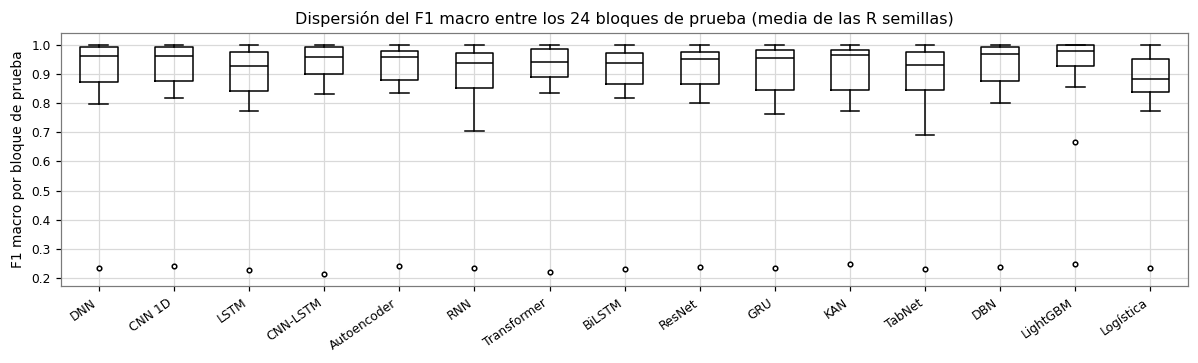

**Interpretación.** Promediando los 13 modelos profundos, la clase más difícil es Flooding, con F1 de 0,793, y la más fácil, Normal, con 0,965. La exactitud en los flujos con el puerto 654 difiere de la de los flujos sin él entre 0,156 y 0,194 según el modelo, y los flujos de prueba con un casi duplicado en entrenamiento obtienen un F1 macro menor que los demás, entre 0,068 y 0,096. Entre los 24 bloques de prueba, el rango intercuartílico del F1 macro va de 0,073 a 0,137.

Es decir, el desempeño depende más de la serie y de la clase que del modelo: la dispersión entre bloques es de 12 veces δ en mediana, y la diferencia por el puerto 654 indica que el modelo aprovecha la configuración del escenario que el puerto delata, un atajo indirecto a través de los atributos de tráfico. Así mismo, los casi duplicados son pocos (1,8 % de la prueba), de modo que su efecto sobre el F1 global es acotado.

Por lo anterior, conviene leer las comparaciones de la sección 6 como pareadas sobre las mismas series y no como estimaciones del desempeño en un enjambre nuevo, y declarar la dependencia de la serie como amenaza a la validez externa.

In [53]:
from sklearn.metrics import f1_score

cortes_flujo = np.quantile(H["tx_packets"][ID_ENT], [0.25, 0.5, 0.75])
banda = np.digitize(H["tx_packets"][ID_PRU], cortes_flujo)
puerto654 = datos["SrcPort"].to_numpy()[ID_PRU] == 654
casi_dup = np.load(ANALISIS / "prueba_con_casi_duplicado.npy")
segmentos = []
for m in ORDEN:
    if m == "Trivial":
        continue
    preds = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva").argmax(1) for s in SEMILLAS]
    fila = {"Modelo": m}
    por_clase = np.mean([f1_score(y_pru, p, average=None, labels=range(K)) for p in preds], 0)
    for c in range(K):
        fila[f"F1 {CLASES[c]}"] = por_clase[c]
    for b, nombre in enumerate(["Muy cortos", "Cortos", "Medianos", "Largos"]):
        fila[nombre] = np.mean([E.f1_macro_rapido(y_pru[banda == b], p[banda == b]) for p in preds])
    fila["Con puerto 654"] = np.mean([(p[puerto654] == y_pru[puerto654]).mean() for p in preds])
    fila["Sin puerto 654"] = np.mean([(p[~puerto654] == y_pru[~puerto654]).mean() for p in preds])
    fila["Sin casi duplicado"] = np.mean([E.f1_macro_rapido(y_pru[~casi_dup], p[~casi_dup]) for p in preds])
    fila["Con casi duplicado"] = np.mean([E.f1_macro_rapido(y_pru[casi_dup], p[casi_dup]) for p in preds])
    segmentos.append(fila)
SEGMENTOS = pd.DataFrame(segmentos)
tabla(SEGMENTOS, {c: "{:.4f}" for c in SEGMENTOS.columns if c != "Modelo"})
f1_bloque = {m: np.array([[AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]) for b in range(NB_PRU)] for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]]).mean(0) for m in ORDEN if m != "Trivial"}
fig, eje = plt.subplots(figsize=(11, 3.4))
eje.boxplot([f1_bloque[m] for m in f1_bloque], labels=list(f1_bloque), medianprops=dict(color=NEGRO), flierprops=dict(marker="o", markersize=3, markerfacecolor="white"))
eje.set_ylabel("F1 macro por bloque de prueba")
eje.set_title(f"Dispersión del F1 macro entre los {NB_PRU} bloques de prueba (media de las R semillas)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
sg = SEGMENTOS.set_index("Modelo")
clases_f1 = sg[[f"F1 {c}" for c in CLASES]].loc[PROFUNDOS].mean()
dif_puerto = (sg["Con puerto 654"] - sg["Sin puerto 654"]).loc[PROFUNDOS]
dif_casi = (sg["Con casi duplicado"] - sg["Sin casi duplicado"]).loc[PROFUNDOS]
iqr = {m: np.subtract(*np.percentile(v, [75, 25])) for m, v in f1_bloque.items()}
interpretar(f'''**Interpretación.** Promediando los 13 modelos profundos, la clase más difícil es {clases_f1.idxmin().replace("F1 ", "")}, con F1 de {num(clases_f1.min(), 3)}, y la más fácil, {clases_f1.idxmax().replace("F1 ", "")}, con {num(clases_f1.max(), 3)}. La exactitud en los flujos con el puerto 654 difiere de la de los flujos sin él entre {num(dif_puerto.min(), 3)} y {num(dif_puerto.max(), 3)} según el modelo, y los flujos de prueba con un casi duplicado en entrenamiento obtienen un F1 macro {f"mayor que los demás, entre {num(dif_casi.min(), 3)} y {num(dif_casi.max(), 3)}" if (dif_casi > 0).all() else f"menor que los demás, entre {num(-dif_casi.max(), 3)} y {num(-dif_casi.min(), 3)}" if (dif_casi < 0).all() else f"que difiere del de los demás entre {num(dif_casi.min(), 3)} y {num(dif_casi.max(), 3)} según el modelo"}. Entre los {NB_PRU} bloques de prueba, el rango intercuartílico del F1 macro va de {num(min(iqr.values()), 3)} a {num(max(iqr.values()), 3)}.

Es decir, {"el desempeño depende más de la serie y de la clase que del modelo: la dispersión entre bloques es de " + num(np.median(list(iqr.values())) / DELTA, 0) + " veces δ en mediana" if np.median(list(iqr.values())) > 2 * DELTA else "la dispersión entre bloques es pequeña frente a δ"}, y la diferencia por el puerto 654 indica {"que el modelo aprovecha la configuración del escenario que el puerto delata, un atajo indirecto a través de los atributos de tráfico" if dif_puerto.abs().max() > 2 * DELTA else "que el puerto, excluido de las entradas, no deja un atajo apreciable en los atributos de tráfico"}. Así mismo, los casi duplicados son pocos ({num(100 * casi_dup.mean(), 1)} % de la prueba), de modo que su efecto sobre el F1 global es acotado.

Por lo anterior, conviene leer las comparaciones de la sección 6 como pareadas sobre las mismas series y no como estimaciones del desempeño en un enjambre nuevo, y declarar la dependencia de la serie como amenaza a la validez externa.''')

### 4.6 Robustez, interpretabilidad y ablación

**Robustez.** Cada modelo, con sus primeras cinco semillas, se evalúa sobre la prueba con tres perturbaciones controladas y al menos tres niveles de severidad, definidas en el preregistro: ruido gaussiano en la escala estandarizada, atributos faltantes imputados con la media de entrenamiento y escalamiento multiplicativo de los atributos crudos, que simula una deriva en la medición. El índice de robustez es el área bajo la curva de degradación del F1 macro, normalizada por el F1 sin perturbar y por el rango de severidades, de modo que 1 indica que el modelo no se degrada.

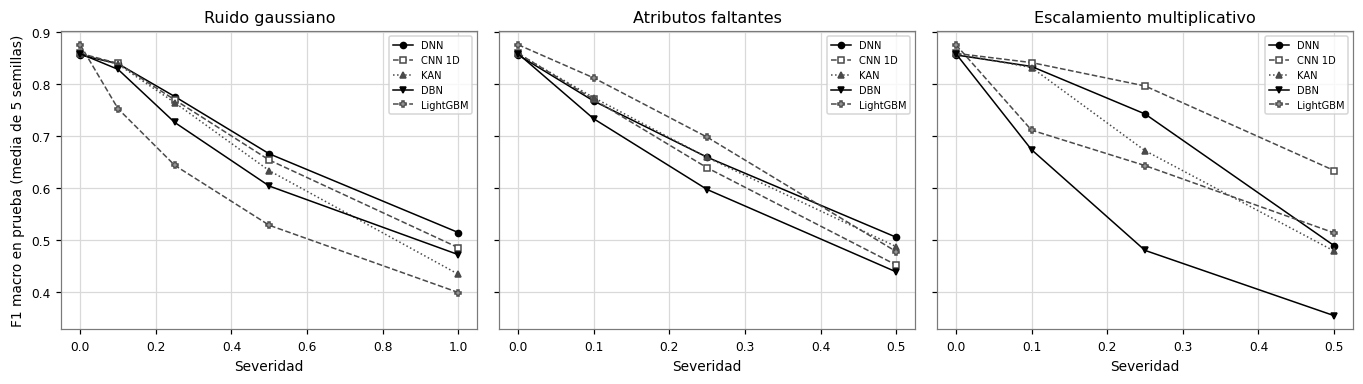

Modelo,Ruido gaussiano,Atributos faltantes,Escalamiento multiplicativo,Índice medio
DNN,"0,7957","0,7797","0,8333","0,8029"
CNN 1D,"0,7779","0,7532","0,9000","0,8104"
LSTM,"0,8332","0,7807","0,9071","0,8403"
CNN-LSTM,"0,7342","0,7538","0,8160","0,7680"
Autoencoder,"0,7998","0,7929","0,7762","0,7896"
RNN,"0,7618","0,7515","0,9004","0,8046"
Transformer,"0,7708","0,7505","0,8384","0,7866"
BiLSTM,"0,7691","0,7467","0,8933","0,8031"
ResNet,"0,7981","0,7709","0,8751","0,8147"
GRU,"0,7471","0,7257","0,8570","0,7766"


**Interpretación.** La perturbación que más degrada a los modelos es ruido gaussiano, con un índice medio de 0,740. El modelo más robusto en promedio es LSTM (0,840) y el menos robusto, Logística (0,409); LightGBM obtiene 0,725, con 0,787 ante atributos faltantes, frente a una mediana de 0,753 en los modelos profundos.

Esto significa que la robustez no sigue el orden del desempeño sin perturbar (ρ de Spearman entre el F1 limpio y el índice medio = -0,31, p = 0,254), de modo que es un eje propio de la comparación, como pide la discusión del enunciado. Hay que tener en cuenta que imputar con la media de entrenamiento, que es 0 tras estandarizar, deja el valor en el centro de la distribución, lo que favorece a los modelos que no dependen de un solo atributo.

Por tal motivo, la tabla principal de la sección 6.1 incluye el índice medio de robustez, y la fragilidad ante ruido gaussiano queda como criterio para el modelo original del Entregable 3, junto con la tokenización por atributo de la búsqueda transversal (sección 3.1).

In [54]:
PERT = AN.perturbaciones()
limpio = PERT[PERT["perturbacion"] == "Sin perturbar"].groupby("modelo")["f1"].mean()
indices_rob = {}
fig, ejes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for eje, tipo in zip(ejes, AN.NIVELES):
    for j, m in enumerate([x for x in ORDEN if x != "Trivial"]):
        sub_p = PERT[(PERT["perturbacion"] == tipo) & (PERT["modelo"] == m)].groupby("nivel")["f1"].mean()
        niveles = np.r_[0.0, sub_p.index.to_numpy()]
        curva = np.r_[limpio[m], sub_p.to_numpy()]
        indices_rob[(m, tipo)] = float(np.trapezoid(curva, niveles) / (limpio[m] * (niveles[-1] - niveles[0])))
        if m in TOP3 + ["LightGBM", "DNN"]:
            eje.plot(niveles, curva, ls=LINEAS[j % 4], marker=MARCADORES[j % 8], ms=4, color=[NEGRO, GRIS_OSCURO, GRIS_MEDIO][j % 3], mfc="white" if j % 2 else None, lw=1, label=m)
    eje.set(title=tipo, xlabel="Severidad")
    eje.legend(fontsize=6.5)
ejes[0].set_ylabel("F1 macro en prueba (media de 5 semillas)")
plt.tight_layout()
plt.show()
ROBUSTEZ = pd.DataFrame({tipo: {m: indices_rob[(m, tipo)] for m in limpio.index} for tipo in AN.NIVELES})
ROBUSTEZ["Índice medio"] = ROBUSTEZ.mean(1)
tabla(ROBUSTEZ.loc[[m for m in ORDEN if m in ROBUSTEZ.index]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ROBUSTEZ.columns})
peor_pert = ROBUSTEZ[list(AN.NIVELES)].mean().idxmin()
mas_rob = ROBUSTEZ["Índice medio"].idxmax()
menos_rob = ROBUSTEZ["Índice medio"].idxmin()
rho_rob = stats.spearmanr(limpio.loc[ROBUSTEZ.index], ROBUSTEZ["Índice medio"])
interpretar(f'''**Interpretación.** La perturbación que más degrada a los modelos es {peor_pert.lower()}, con un índice medio de {num(ROBUSTEZ[peor_pert].mean(), 3)}. El modelo más robusto en promedio es {mas_rob} ({num(ROBUSTEZ.loc[mas_rob, "Índice medio"], 3)}) y el menos robusto, {menos_rob} ({num(ROBUSTEZ.loc[menos_rob, "Índice medio"], 3)}); LightGBM obtiene {num(ROBUSTEZ.loc["LightGBM", "Índice medio"], 3)}, con {num(ROBUSTEZ.loc["LightGBM", "Atributos faltantes"], 3)} ante atributos faltantes, frente a una mediana de {num(ROBUSTEZ.loc[PROFUNDOS, "Atributos faltantes"].median(), 3)} en los modelos profundos.

Esto significa que la robustez {"no sigue el orden del desempeño sin perturbar" if not (rho_rob.pvalue < ALFA and rho_rob.statistic > 0) else "acompaña al desempeño sin perturbar"} (ρ de Spearman entre el F1 limpio y el índice medio = {num(rho_rob.statistic, 2)}, {valor_p(rho_rob.pvalue)}), de modo que {"es un eje propio de la comparación, como pide la discusión del enunciado" if not (rho_rob.pvalue < ALFA and rho_rob.statistic > 0) else "los mejores modelos son también los más robustos"}. Hay que tener en cuenta que imputar con la media de entrenamiento, que es 0 tras estandarizar, deja el valor en el centro de la distribución, lo que favorece a los modelos que no dependen de un solo atributo.

Por tal motivo, la tabla principal de la sección 6.1 incluye el índice medio de robustez, y la fragilidad ante {peor_pert.lower()} queda como criterio para el modelo original del Entregable 3, junto con la tokenización por atributo de la búsqueda transversal (sección 3.1).''')

**Interpretabilidad.** A los tres mejores modelos por validación se aplican gradientes integrados (Sundararajan et al., 2017), $IG_j(\mathbf{x}) = (x_j - x'_j) \int_0^1 \frac{\partial f_c(\mathbf{x}' + \alpha(\mathbf{x} - \mathbf{x}'))}{\partial x_j} d\alpha$, con la base $\mathbf{x}'$ en la media de entrenamiento y 32 pasos, sobre 1500 flujos de prueba estratificados por clase y cinco semillas. La **fidelidad** se verifica con una prueba de borrado: se anulan los atributos en el orden de su atribución y se compara la caída de la probabilidad de la clase predicha con la de un orden aleatorio; una explicación fiel produce una caída más rápida. La **estabilidad** se mide con la correlación de Spearman entre los vectores de importancia de cada par de semillas.

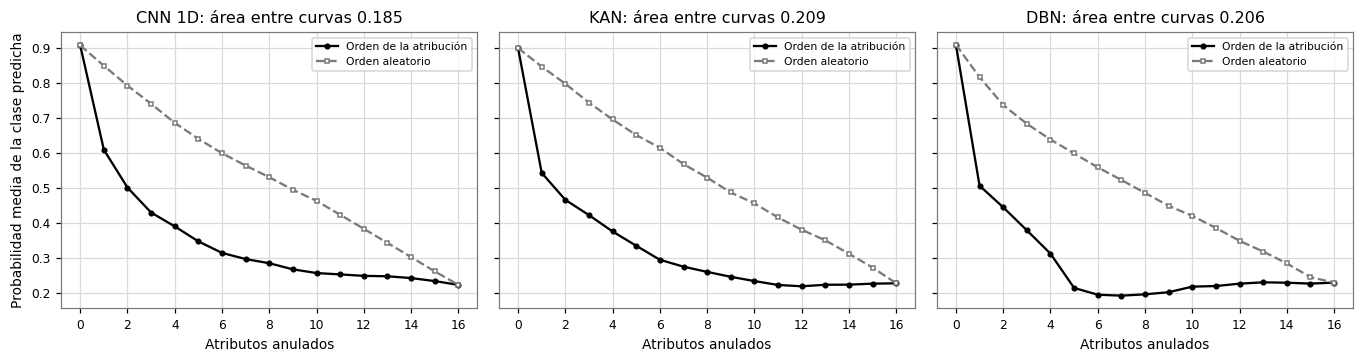

Modelo,Estabilidad media (ρ),Estabilidad mínima (ρ),Área entre curvas,Tres atributos más importantes
CNN 1D,"0,797","0,706","0,185","PacketDropRate, MeanPacketSize, Throughput/Kbps"
KAN,"0,687","0,538","0,209","PacketDropRate, MeanPacketSize, FlowDuration/s"
DBN,"0,977","0,947","0,206","MeanPacketSize, Throughput/Kbps, PacketDropRate"


Atributo,CNN 1D,KAN,DBN
PacketDropRate,"0,121","0,156","0,103"
MeanPacketSize,"0,121","0,115","0,190"
Throughput/Kbps,"0,092","0,073","0,119"
TxBytes,"0,075","0,049","0,068"
FlowDuration/s,"0,075","0,077","0,050"
AverageHopCount,"0,065","0,064","0,029"
TxPackets,"0,058","0,062","0,062"
TxByteRate/s,"0,055","0,074","0,096"
LostPackets,"0,050","0,042","0,048"
RxPacketRate/s,"0,050","0,061","0,057"


**Interpretación.** La estabilidad de las atribuciones entre semillas, medida con la ρ de Spearman media, va de 0,687 a 0,977 en los tres mejores modelos, con un mínimo por par de 0,538. En la prueba de borrado, el área entre la curva aleatoria y la de la atribución es positiva en los tres modelos, de 0,185 a 0,209. Los tres atributos más importantes son, en CNN 1D, PacketDropRate, MeanPacketSize y Throughput/Kbps; en KAN, PacketDropRate, MeanPacketSize y FlowDuration/s; en DBN, MeanPacketSize, Throughput/Kbps y PacketDropRate.

Lo anterior indica que las explicaciones no son a la vez fieles y estables en todos los modelos: en KAN, la estabilidad media entre semillas no pasa de 0,7, de modo que el orden de los atributos cambia según la semilla; en CNN 1D y DBN, en cambio, son fieles y estables. Por eso, las atribuciones de KAN no deben leerse como evidencia del mecanismo. En cuanto al dominio, la coherencia se evalúa frente a lo que distingue a los ataques: Flooding eleva las tasas de envío, Sybil multiplica las identidades y altera el volumen, y Blackhole y Wormhole cambian el número de saltos y la entrega de paquetes; una atribución concentrada en atributos de volumen explicaría bien Flooding, pero no la frontera entre los dos ataques de enrutamiento.

Por ello, se recomienda usar estas atribuciones como diagnóstico y no como explicación causal, y contrastarlas en el Entregable 3 con atribuciones calculadas solo sobre los flujos de Blackhole y Wormhole.

In [55]:
ATR = AN.atribuciones(TOP3)
filas_i, estabilidad = [], {}
fig, ejes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharey=True)
for eje, m in zip(ejes, TOP3):
    imp = ATR[f"{m}|importancia"]
    imp_n = imp / imp.sum(1, keepdims=True)
    rhos = [stats.spearmanr(imp[a], imp[b]).statistic for a in range(len(imp)) for b in range(a + 1, len(imp))]
    estabilidad[m] = (np.mean(rhos), np.min(rhos))
    borr, alea = ATR[f"{m}|borrado"].mean(0), ATR[f"{m}|aleatorio"].mean(0)
    k = np.arange(len(borr))
    eje.plot(k, borr, color=NEGRO, marker="o", ms=3, label="Orden de la atribución")
    eje.plot(k, alea, color=GRIS_MEDIO, ls="--", marker="s", ms=3, mfc="white", label="Orden aleatorio")
    aopc = float((alea - borr).mean())
    eje.set(title=f"{m}: área entre curvas {aopc:.3f}", xlabel="Atributos anulados")
    eje.legend(fontsize=7)
    orden_imp = np.argsort(-imp_n.mean(0))
    filas_i.append({"Modelo": m, "Estabilidad media (ρ)": estabilidad[m][0], "Estabilidad mínima (ρ)": estabilidad[m][1], "Área entre curvas": aopc,
                    "Tres atributos más importantes": ", ".join(ATRIBUTOS[j] for j in orden_imp[:3])})
ejes[0].set_ylabel("Probabilidad media de la clase predicha")
plt.tight_layout()
plt.show()
INTERP = pd.DataFrame(filas_i)
tabla(INTERP, {"Estabilidad media (ρ)": "{:.3f}", "Estabilidad mínima (ρ)": "{:.3f}", "Área entre curvas": "{:.3f}"})
importancia_tabla = pd.DataFrame({m: (ATR[f"{m}|importancia"] / ATR[f"{m}|importancia"].sum(1, keepdims=True)).mean(0) for m in TOP3}, index=ATRIBUTOS)
tabla(importancia_tabla.sort_values(TOP3[0], ascending=False).reset_index(names="Atributo"), {m: "{:.3f}" for m in TOP3})
inestables = INTERP.loc[INTERP["Estabilidad media (ρ)"] <= 0.7, "Modelo"].tolist()
infieles = INTERP.loc[INTERP["Área entre curvas"] <= 0, "Modelo"].tolist()
fiables = [m for m in INTERP["Modelo"] if m not in inestables + infieles]
lectura_interp = ("las explicaciones no son a la vez fieles y estables en todos los modelos"
                  + (f": en {enumerar(inestables)}, la estabilidad media entre semillas no pasa de 0,7, de modo que el orden de los atributos cambia según la semilla" if inestables else "")
                  + (f"{'; y en ' if inestables else ': en '}{enumerar(infieles)}, anular los atributos señalados no reduce la confianza más que un orden aleatorio" if infieles else "")
                  + (f"; en {enumerar(fiables)}, en cambio, son fieles y estables. Por eso, las atribuciones de {enumerar(inestables + infieles)} no deben leerse como evidencia del mecanismo" if fiables
                     else ", de modo que no deben leerse como evidencia del mecanismo"))
interpretar(f'''**Interpretación.** La estabilidad de las atribuciones entre semillas, medida con la ρ de Spearman media, va de {num(INTERP["Estabilidad media (ρ)"].min(), 3)} a {num(INTERP["Estabilidad media (ρ)"].max(), 3)} en los tres mejores modelos, con un mínimo por par de {num(INTERP["Estabilidad mínima (ρ)"].min(), 3)}. En la prueba de borrado, el área entre la curva aleatoria y la de la atribución es {"positiva en los tres modelos" if (INTERP["Área entre curvas"] > 0).all() else "positiva solo en " + enumerar(INTERP.loc[INTERP["Área entre curvas"] > 0, "Modelo"])}, de {num(INTERP["Área entre curvas"].min(), 3)} a {num(INTERP["Área entre curvas"].max(), 3)}. Los tres atributos más importantes son, {"; ".join(f"en {f['Modelo']}, {enumerar(f['Tres atributos más importantes'].split(', '))}" for _, f in INTERP.iterrows())}.

Lo anterior indica que {"las explicaciones son fieles, porque anular primero los atributos que señalan reduce la confianza más rápido que un orden aleatorio, y estables, porque se repiten entre semillas" if (INTERP["Área entre curvas"] > 0).all() and INTERP["Estabilidad media (ρ)"].min() > 0.7 else lectura_interp}. En cuanto al dominio, la coherencia se evalúa frente a lo que distingue a los ataques: Flooding eleva las tasas de envío, Sybil multiplica las identidades y altera el volumen, y Blackhole y Wormhole cambian el número de saltos y la entrega de paquetes; una atribución concentrada en atributos de volumen explicaría bien Flooding, pero no la frontera entre los dos ataques de enrutamiento.

Por ello, se recomienda usar estas atribuciones como diagnóstico y no como explicación causal, y contrastarlas en el Entregable 3 con atribuciones calculadas solo sobre los flujos de Blackhole y Wormhole.''')

**Ablación.** Sobre el mejor modelo por validación se aíslan tres componentes del pipeline común, con las mismas R semillas: la ponderación de la pérdida por clase, la transformación $\log(1 + x)$ y el *dropout*. Cada variante cambia un solo componente, y la diferencia con el modelo completo se prueba con la *t* pareada, Wilcoxon y TOST sobre las semillas.

In [56]:
abl = RES.tabla_fase("ablacion")
completo = METRICAS[METRICAS["modelo"] == MEJOR_DL].set_index("semilla")["prueba F1 macro"]
filas_a = []
for variante in sorted(abl["variante_nombre"].unique()):
    sub_a = abl[abl["variante_nombre"] == variante].set_index("semilla")
    comunes = sorted(set(sub_a.index) & set(completo.index))
    r_ab = E.comparar_par(sub_a.loc[comunes, "f1_eva"].to_numpy(), completo.loc[comunes].to_numpy())
    filas_a.append({"Variante": variante, "Semillas": len(comunes), "F1 macro de prueba": sub_a.loc[comunes, "f1_eva"].mean(), "Diferencia con el completo": r_ab["Diferencia media"],
                    "IC 95 %": intervalo(r_ab["IC 95 % t"] if r_ab["Shapiro-Wilk p"] >= ALFA else r_ab["IC 95 % bootstrap"]), "p t": r_ab["p t pareada"], "p Wilcoxon": r_ab["p Wilcoxon"],
                    "p TOST": r_ab["p TOST"], "d de Cohen": r_ab["d de Cohen pareada"]})
ABLACION = pd.DataFrame(filas_a)
ARTICULO_ABL = {"dropout": ("el *dropout*", "al *dropout*"), "ponderación de clases": ("la ponderación de clases", "a la ponderación de clases"), "log(1 + x)": ("la transformación log(1 + x)", "a la transformación log(1 + x)")}
val_completo = np.mean([r["f1_val"] for r in DEF if r["modelo"] == MEJOR_DL])
ABLACION.insert(4, "Diferencia en validación", [abl.loc[abl["variante_nombre"] == v_, "f1_val"].mean() - val_completo for v_ in ABLACION["Variante"]])
ABLACION[["p t Holm", "p Wilcoxon Holm"]] = np.column_stack([E.holm(ABLACION["p t"]), E.holm(ABLACION["p Wilcoxon"])])
tabla(ABLACION, {"F1 macro de prueba": "{:.4f}", "Diferencia con el completo": "{:+.4f}", "Diferencia en validación": "{:+.4f}", "p t": "{:.4f}", "p Wilcoxon": "{:.4f}", "p TOST": "{:.4f}", "d de Cohen": "{:.2f}", "p t Holm": "{:.4f}", "p Wilcoxon Holm": "{:.4f}"})
sig_abl = ABLACION[(ABLACION["p t Holm"] < ALFA) & (ABLACION["p Wilcoxon Holm"] < ALFA)]
indicio = ABLACION[(ABLACION["Diferencia con el completo"].abs() > DELTA) & ((ABLACION["p t Holm"] < ALFA) | (ABLACION["p Wilcoxon Holm"] < ALFA)) & ~ABLACION.index.isin(sig_abl.index)]
if (sig_abl["Diferencia con el completo"].abs() > DELTA).any():
    lectura_abl = "el componente con efecto relevante es " + enumerar(sig_abl.loc[sig_abl["Diferencia con el completo"].abs() > DELTA, "Variante"])
    decision_abl = "revisar en el Entregable 3 el componente con efecto relevante"
elif len(indicio):
    f_i = indicio.iloc[0]
    lectura_abl = (f"ningún componente cumple el criterio de las dos pruebas, pero «{f_i['Variante']}» se acerca: su diferencia supera δ, su IC excluye el cero y la "
                   + ("*t* pareada la declara significativa tras Holm (p = " + num(f_i["p t Holm"], 3) + "), aunque Wilcoxon no (p = " + num(f_i["p Wilcoxon Holm"], 3) + ")" if f_i["p t Holm"] < ALFA
                      else "prueba de Wilcoxon la declara significativa tras Holm (p = " + num(f_i["p Wilcoxon Holm"], 3) + "), aunque la *t* no (p = " + num(f_i["p t Holm"], 3) + ")")
                   + f"; en validación, el mismo cambio mueve el F1 en {num(f_i['Diferencia en validación'], 4)}, unas {num(abs(f_i['Diferencia en validación']) / DELTA, 1)} veces δ. Es decir, es el componente del pipeline con más evidencia de aportar")
    otras = [v_ for v_ in ABLACION.loc[ABLACION["p TOST"] < ALFA, "Variante"]]
    decision_abl = ("conservar el pipeline común, que incluye ese componente" + (", y no atribuir el desempeño " + " ni ".join(ARTICULO_ABL.get(v_.replace("sin ", "", 1), (v_, v_))[1] for v_ in otras) + ", que resultan equivalentes a no usarlos dentro de ±δ" if otras else ""))
else:
    lectura_abl = "ningún componente del pipeline común cambia el desempeño en una magnitud mayor que δ con evidencia estadística"
    decision_abl = "no atribuir el desempeño del mejor modelo a la ponderación, la transformación ni el dropout"
interpretar(f'''**Interpretación.** Sobre {MEJOR_DL}, la variante con el mayor cambio es «{ABLACION.loc[ABLACION["Diferencia con el completo"].abs().idxmax(), "Variante"]}», con una diferencia de {num(ABLACION["Diferencia con el completo"].abs().max() * np.sign(ABLACION.loc[ABLACION["Diferencia con el completo"].abs().idxmax(), "Diferencia con el completo"]), 4)} en F1 macro de prueba. {"Las diferencias significativas tras Holm, en ambas pruebas, son las de " + enumerar("«" + sig_abl["Variante"] + "»") if len(sig_abl) else "Ninguna diferencia es significativa tras Holm con las dos pruebas a la vez"}, y {"TOST declara equivalentes al modelo completo, dentro de ±δ, las variantes " + enumerar("«" + ABLACION.loc[ABLACION["p TOST"] < ALFA, "Variante"] + "»") if (ABLACION["p TOST"] < ALFA).any() else "TOST no declara equivalente al modelo completo ninguna variante"}.

Esto significa que {lectura_abl}. Hay que tener en cuenta que la ablación aísla componentes del pipeline y no de la arquitectura, porque el diseño del modelo viene de la literatura.

En consecuencia, se decide {decision_abl}.''')

Variante,Semillas,F1 macro de prueba,Diferencia con el completo,Diferencia en validación,IC 95 %,p t,p Wilcoxon,p TOST,d de Cohen,p t Holm,p Wilcoxon Holm
sin dropout,20,"0,8541","-0,0043","-0,0019","[-0,0085; -0,0006]","0,0508","0,0696","0,0064","-0,47","0,1016","0,1392"
sin log(1 + x),20,"0,8457","-0,0127","-0,0416","[-0,0225; -0,0029]","0,0135","0,0441","0,7162","-0,61","0,0404","0,1322"
sin ponderación de clases,20,"0,8613","+0,0029","+0,0022","[0,0003; 0,0060]","0,0684","0,0897","0,0001","0,43","0,1016","0,1392"


**Interpretación.** Sobre CNN 1D, la variante con el mayor cambio es «sin log(1 + x)», con una diferencia de -0,0127 en F1 macro de prueba. Ninguna diferencia es significativa tras Holm con las dos pruebas a la vez, y TOST declara equivalentes al modelo completo, dentro de ±δ, las variantes «sin dropout» y «sin ponderación de clases».

Esto significa que ningún componente cumple el criterio de las dos pruebas, pero «sin log(1 + x)» se acerca: su diferencia supera δ, su IC excluye el cero y la *t* pareada la declara significativa tras Holm (p = 0,040), aunque Wilcoxon no (p = 0,132); en validación, el mismo cambio mueve el F1 en -0,0416, unas 4,2 veces δ. Es decir, es el componente del pipeline con más evidencia de aportar. Hay que tener en cuenta que la ablación aísla componentes del pipeline y no de la arquitectura, porque el diseño del modelo viene de la literatura.

En consecuencia, se decide conservar el pipeline común, que incluye ese componente, y no atribuir el desempeño al *dropout* ni a la ponderación de clases, que resultan equivalentes a no usarlos dentro de ±δ.

## 5. Paper guía y replicación

En esta sección se presenta el paper guía, se replica parcialmente su resultado principal con su propio protocolo para validar el pipeline y se cuantifica una limitación concreta de su modelo, que es el candidato al hueco de investigación del modelo original del Entregable 3.

### 5.1 Referencia, modelo y justificación

**Referencia.** Zeng, Q., Bashir, A. y Naït-Abdesselam, F. (2025). UAVIDS-2025: A Benchmark Dataset for Intrusion Detection in UAV Networks Using Machine Learning Techniques. En *IEEE Conference on Communications and Network Security (CNS)* (pp. 1–9). <https://doi.org/10.1109/cns66487.2025.11194990>. El código de los autores está en <https://github.com/QingliZeng/UAV--IDS2025>.

**Modelo original.** El artículo presenta el conjunto de datos y lo valida con diez modelos, de los cuales los de Deep Learning son una DNN de 16 → 128 → 64 → 32 → 5, una CNN 1D de 32 y 64 filtros y una LSTM de 64 unidades, las tres con *dropout* de 0,2 (sus formulaciones están en las fichas del Entregable 1, sección 3.3). Todos se entrenan con entropía cruzada sin ponderar, Adam con tasa de 10⁻³, lotes de 256, hasta 50 épocas y parada temprana sobre la pérdida de un 10 % del entrenamiento, con paciencia de 5. Los supuestos del protocolo son tres: los 16 atributos numéricos describen el flujo, la estandarización se ajusta con entrenamiento, y una partición aleatoria estratificada 80/20 con semilla 42 basta para evaluar. Su resultado principal entre los modelos profundos es el de la LSTM, con F1 de 94 %, y entre todos, el de XGBoost, con 96 %.

**Justificación.** Es el artículo que define el problema y el conjunto de datos, de modo que su relevancia e idoneidad son máximas; es la referencia de los 12 estudios incluidos que usan UAVIDS-2025, y es el único de los 43 con código público, lo que permite replicarlo bajo sus condiciones exactas. Además, sus tres modelos profundos son los modelos base del proyecto y su XGBoost es el antecedente del baseline clásico fuerte.

### 5.2 Réplica parcial

**Criterio de éxito, declarado en el preregistro.** La réplica es exitosa si la diferencia absoluta entre la media de 10 réplicas (semillas y particiones de 42 a 51, como la opción `--seeds` del código de los autores) y el valor reportado es menor que δ = 0,01, o si el valor reportado cae dentro del IC 95 % de esa media. La métrica principal es el F1 macro y, como sensibilidad, el ponderado, porque el artículo no declara el promedio de su columna de F1.

In [57]:
replica = pd.DataFrame([json.loads(p.read_text(encoding="utf-8")) for p in sorted((RESULTADOS / "replica").glob("*.json"))])
filas_r = []
for m in ["LR", "XGBoost", "DNN", "CNN", "LSTM"]:
    sub_r = replica[replica["modelo"] == m]
    for metrica, nombre in (("f1_macro", "F1 macro"), ("f1_ponderado", "F1 ponderado")):
        v = sub_r[metrica].to_numpy()
        margen = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
        reportado = sub_r["reportado_f1"].iloc[0]
        exito = abs(v.mean() - reportado) < DELTA or (v.mean() - margen <= reportado <= v.mean() + margen)
        filas_r.append({"Modelo": m, "Métrica": nombre, "Réplicas": len(v), "Media": v.mean(), "DE": v.std(ddof=1), "IC 95 %": intervalo((v.mean() - margen, v.mean() + margen)),
                        "Reportado": reportado, "Diferencia": v.mean() - reportado, "Éxito": "sí" if exito else "no"})
REPLICA = pd.DataFrame(filas_r)
REPLICA.to_csv(RESULTADOS / "replica.csv", index=False, encoding="utf-8-sig")
tabla(REPLICA, {"Media": "{:.4f}", "DE": "{:.4f}", "Reportado": "{:.2f}", "Diferencia": "{:+.4f}"})
lstm_r = REPLICA[(REPLICA["Modelo"] == "LSTM") & (REPLICA["Métrica"] == "F1 macro")].iloc[0]
macro_r = REPLICA[REPLICA["Métrica"] == "F1 macro"].set_index("Modelo")
otros_ok = [m for m in ["LR", "XGBoost", "DNN", "CNN"] if macro_r.loc[m, "Éxito"] == "sí"]
lstm_v = replica.loc[replica["modelo"] == "LSTM", "f1_macro"].to_numpy()
umbral_redondeo = lstm_r["Reportado"] - 0.005
orden_invertido = macro_r.loc["LSTM", "Media"] < min(macro_r.loc["DNN", "Media"], macro_r.loc["CNN", "Media"])
if lstm_r["Éxito"] == "sí":
    lectura_replica = '''Esto significa que el pipeline de este proyecto, con los mismos datos y el mismo protocolo, reproduce las cifras de los autores dentro del margen de relevancia, de modo que la diferencia entre esas cifras y las del benchmark no se debe a un error de implementación sino a la partición y al protocolo. Las discrepancias que quedan son del orden del redondeo del artículo, que reporta porcentajes enteros.

Por tal motivo, se da por validado el pipeline y se usa la réplica como punto de comparación de la limitación de la sección 5.3.'''
else:
    lectura_replica = (f'''Esto significa que la implementación del protocolo queda validada por los modelos que sí se reproducen ({enumerar(otros_ok)}), pero el resultado clave no: con el mismo código y los mismos datos, la LSTM queda {num(abs(lstm_r["Diferencia"]), 4)} por debajo de lo reportado, y ninguna de las {len(lstm_v)} réplicas alcanza {num(umbral_redondeo, 3)}, el menor valor que se redondea a {num(100 * lstm_r["Reportado"], 0)} % (la mejor llega a {num(lstm_v.max(), 4)})'''
                       + (". Además, el orden de la tabla IV se invierte: la LSTM queda por debajo de la DNN y de la CNN, de modo que la ventaja de la recurrencia que sugiere el artículo no se sostiene" if orden_invertido else "")
                       + f'''. Hay que tener en cuenta que el código de los autores también está en PyTorch, de modo que la inicialización y el entrenamiento son los mismos, y que el artículo no reporta cuántas corridas promedia ni su dispersión: el {num(100 * lstm_r["Reportado"], 0)} % podría venir de una sola ejecución favorable o de otra versión del conjunto de datos, y esta réplica no puede distinguir entre esas explicaciones.

Por tal motivo, se da por validado el pipeline con los modelos que sí se reproducen, se declara como no reproducido el resultado clave de la LSTM, y se usa la réplica como punto de comparación de la limitación de la sección 5.3.''')
interpretar(f'''**Interpretación.** En el resultado clave, la LSTM, la réplica obtiene un F1 macro de {num(lstm_r["Media"], 4)} ± {num(lstm_r["DE"], 4)} en 10 réplicas, con IC 95 % de {lstm_r["IC 95 %"]}, frente al 0,94 reportado: la diferencia es de {num(lstm_r["Diferencia"], 4)}, y la réplica {"es exitosa" if lstm_r["Éxito"] == "sí" else "no cumple el criterio"}. De los cinco modelos, {int((REPLICA[REPLICA["Métrica"] == "F1 macro"]["Éxito"] == "sí").sum())} cumplen el criterio con F1 macro y {int((REPLICA[REPLICA["Métrica"] == "F1 ponderado"]["Éxito"] == "sí").sum())} con F1 ponderado.

{lectura_replica}''')

Modelo,Métrica,Réplicas,Media,DE,IC 95 %,Reportado,Diferencia,Éxito
LR,F1 macro,10,"0,8191","0,0023","[0,8175; 0,8208]","0,82","-0,0009",sí
LR,F1 ponderado,10,"0,8185","0,0023","[0,8169; 0,8202]","0,82","-0,0015",sí
XGBoost,F1 macro,10,"0,9575","0,0008","[0,9569; 0,9581]","0,96","-0,0025",sí
XGBoost,F1 ponderado,10,"0,9551","0,0008","[0,9545; 0,9557]","0,96","-0,0049",sí
DNN,F1 macro,10,"0,9353","0,0021","[0,9338; 0,9368]","0,93","+0,0053",sí
DNN,F1 ponderado,10,"0,9338","0,0020","[0,9323; 0,9352]","0,93","+0,0038",sí
CNN,F1 macro,10,"0,9365","0,0028","[0,9345; 0,9385]","0,93","+0,0065",sí
CNN,F1 ponderado,10,"0,9349","0,0026","[0,9330; 0,9368]","0,93","+0,0049",sí
LSTM,F1 macro,10,"0,9285","0,0044","[0,9254; 0,9317]","0,94","-0,0115",no
LSTM,F1 ponderado,10,"0,9275","0,0041","[0,9246; 0,9305]","0,94","-0,0125",no


**Interpretación.** En el resultado clave, la LSTM, la réplica obtiene un F1 macro de 0,9285 ± 0,0044 en 10 réplicas, con IC 95 % de [0,9254; 0,9317], frente al 0,94 reportado: la diferencia es de -0,0115, y la réplica no cumple el criterio. De los cinco modelos, 4 cumplen el criterio con F1 macro y 4 con F1 ponderado.

Esto significa que la implementación del protocolo queda validada por los modelos que sí se reproducen (LR, XGBoost, DNN y CNN), pero el resultado clave no: con el mismo código y los mismos datos, la LSTM queda 0,0115 por debajo de lo reportado, y ninguna de las 10 réplicas alcanza 0,935, el menor valor que se redondea a 94 % (la mejor llega a 0,9338). Además, el orden de la tabla IV se invierte: la LSTM queda por debajo de la DNN y de la CNN, de modo que la ventaja de la recurrencia que sugiere el artículo no se sostiene. Hay que tener en cuenta que el código de los autores también está en PyTorch, de modo que la inicialización y el entrenamiento son los mismos, y que el artículo no reporta cuántas corridas promedia ni su dispersión: el 94 % podría venir de una sola ejecución favorable o de otra versión del conjunto de datos, y esta réplica no puede distinguir entre esas explicaciones.

Por tal motivo, se da por validado el pipeline con los modelos que sí se reproducen, se declara como no reproducido el resultado clave de la LSTM, y se usa la réplica como punto de comparación de la limitación de la sección 5.3.

### 5.3 Limitación identificada en el paper guía

La limitación declarada en el preregistro es la **confusión entre Blackhole y Wormhole**, que se cuantifica con la tasa de confusión del par, $\frac{n_{B \to W} + n_{W \to B}}{n_B + n_W}$, sobre los flujos de esas dos clases. Las dos son ataques de enrutamiento: en Blackhole, un nodo atrae rutas y descarta los paquetes, y en Wormhole, dos nodos crean un túnel que altera las rutas, de modo que ambos cambian el número de saltos y la entrega de paquetes de forma parecida. Bakiri et al. (2026) la señalan como la frontera más difícil de UAVIDS-2025, y el Entregable 1 midió que la CNN 1D predecía como Wormhole el 17,6 % de los flujos de Blackhole. La limitación se cuantifica en tres escenarios: con el modelo del paper bajo su propio protocolo (la réplica), con el mismo modelo bajo la partición agrupada (la ejecución definitiva) y con tres modelos del Top 10 en el piloto, sobre validación, para saber si es propia del paper o compartida por la familia. Los intervalos se calculan por *bootstrap* por bloques de 1000 flujos, agregando las confusiones de todas las semillas en cada bloque; en el piloto, el intervalo es el de la primera semilla, tal como quedó en la adenda del preregistro.

In [58]:
lim_filas = []
for m in ["DNN", "CNN", "LSTM", "XGBoost"]:
    for _, r_r in replica[replica["modelo"] == m].iterrows():
        z = np.load(RESULTADOS / "replica" / f"{m}_{r_r['semilla']}.npz")
        v, p = y[z["indices_prueba"]], z["prediccion"].astype(int)
        lim_filas.append({"Escenario": "Réplica, partición aleatoria 80/20", "Modelo": m, "semilla": r_r["semilla"], "tasa": E.tasa_ruteo(v, p), "indices": z["indices_prueba"], "pred": p})
for m in ["DNN", "CNN 1D", "LSTM"] + CONFIG["modelos"]["top10"] + ["LightGBM"]:
    for s in SEMILLAS:
        r_d = next(x for x in DEF if x["modelo"] == m and x["semilla"] == s)
        p = AN.prob(r_d, "eva").argmax(1)
        lim_filas.append({"Escenario": "Benchmark, partición agrupada (prueba)", "Modelo": m, "semilla": s, "tasa": E.tasa_ruteo(y[ID_PRU], p), "indices": ID_PRU, "pred": p})
LIM = pd.DataFrame(lim_filas)
def ic_limitacion(grupo):
    # Se agregan las semillas: por bloque, se suman las confusiones del par y los flujos del par de todas las semillas,
    # y cada réplica del bootstrap remuestrea los bloques, de modo que el intervalo es el de la tasa media
    ids_b = np.unique(np.concatenate([bloques[ix] for ix in grupo["indices"]]))
    num_b, den_b = np.zeros(len(ids_b)), np.zeros(len(ids_b))
    b_, w_ = E.PAR_RUTEO
    for _, f in grupo.iterrows():
        v, pr, pos = y[f["indices"]], f["pred"], np.searchsorted(ids_b, bloques[f["indices"]])
        num_b += np.bincount(pos, weights=((v == b_) & (pr == w_)) | ((v == w_) & (pr == b_)), minlength=len(ids_b))
        den_b += np.bincount(pos, weights=(v == b_) | (v == w_), minlength=len(ids_b))
    W = AN.pesos_bootstrap(len(ids_b), repeticiones=2000, semilla=42)
    boot = (W @ num_b) / np.maximum(W @ den_b, 1)
    return pd.Series({"Tasa media": grupo["tasa"].mean(), "DE entre semillas": grupo["tasa"].std(), "IC 95 % por bloques": intervalo(100 * np.array(E.ic_percentil(boot)), 1)})
resumen_lim = LIM.groupby(["Escenario", "Modelo"], sort=False).apply(ic_limitacion).reset_index()
resumen_lim["Tasa media"] *= 100
resumen_lim["DE entre semillas"] *= 100
resumen_lim.to_csv(RESULTADOS / "limitacion_paper_guia.csv", index=False, encoding="utf-8-sig")
tabla(resumen_lim.rename(columns={"Tasa media": "Tasa media (%)", "DE entre semillas": "DE entre semillas (pp)"}), {"Tasa media (%)": "{:.2f}", "DE entre semillas (pp)": "{:.2f}"})
piloto_lim = ADENDA["piloto"]["limitacion_paper_guia"]["por_modelo"]
tabla(pd.DataFrame([{"Modelo del piloto (validación)": m, "Tasa media (%)": 100 * v["media_semillas"], "DE (pp)": 100 * v["de_semillas"], "IC 95 % por bloques (primera semilla)": intervalo(100 * np.array(v["ic95_bloques_primera_semilla"]), 1)}
                    for m, v in piloto_lim.items()]), {"Tasa media (%)": "{:.2f}", "DE (pp)": "{:.2f}"})
lstm_rep = LIM[(LIM["Escenario"].str.startswith("Réplica")) & (LIM["Modelo"] == "LSTM")]["tasa"].mean()
lstm_bench = LIM[(LIM["Escenario"].str.startswith("Benchmark")) & (LIM["Modelo"] == "LSTM")]["tasa"].mean()
top10_bench = LIM[(LIM["Escenario"].str.startswith("Benchmark")) & (LIM["Modelo"].isin(CONFIG["modelos"]["top10"]))].groupby("Modelo")["tasa"].mean()
compartida = top10_bench.min() >= 0.5 * lstm_bench
subestima = lstm_rep < lstm_bench
piloto_top = {k: v["media_semillas"] for k, v in piloto_lim.items() if k != "CNN 1D"}
interpretar(f'''**Interpretación.** Con el protocolo de los autores, la LSTM del paper confunde Blackhole y Wormhole en el {num(100 * lstm_rep, 2)} % de los flujos de esas dos clases, y con la partición agrupada la tasa es de {num(100 * lstm_bench, 2)} %. En el benchmark, los diez modelos del Top 10 tienen tasas de {num(100 * top10_bench.min(), 2)} % ({top10_bench.idxmin()}) a {num(100 * top10_bench.max(), 2)} % ({top10_bench.idxmax()}), y en el piloto, los tres modelos del Top 10 evaluados en validación quedan entre {num(100 * min(piloto_top.values()), 2)} % y {num(100 * max(piloto_top.values()), 2)} %.

Esto quiere decir que la limitación {"no es propia de la LSTM del paper, sino compartida por todas las familias evaluadas: ningún modelo del Top 10 baja la tasa a menos de la mitad de la de la LSTM" if compartida else "no afecta por igual a todas las familias: " + top10_bench.idxmin() + " la reduce a menos de la mitad de la de la LSTM"}{", y que la partición aleatoria la subestima, porque los flujos casi gemelos de una misma serie hacen más fácil separar el par" if subestima else ""}. {"Es decir, ninguna arquitectura del Top 10 resuelve la frontera entre los dos ataques de enrutamiento, lo que apunta a una superposición en el espacio de los 16 atributos más que a un problema de capacidad." if compartida else "Es decir, el sesgo inductivo sí cambia cómo se separan los dos ataques, lo que orienta el mecanismo del modelo original."}

Por lo anterior, conviene declarar esta limitación como el hueco de investigación para el Entregable 3, que se resume en la sección 5.4.''')

Escenario,Modelo,Tasa media (%),DE entre semillas (pp),IC 95 % por bloques
"Réplica, partición aleatoria 80/20",DNN,"10,06","0,22","[6,0; 14,8]"
"Réplica, partición aleatoria 80/20",CNN,"9,99","0,24","[6,0; 14,5]"
"Réplica, partición aleatoria 80/20",LSTM,"9,96","0,18","[5,9; 14,6]"
"Réplica, partición aleatoria 80/20",XGBoost,"8,96","0,16","[5,7; 12,8]"
"Benchmark, partición agrupada (prueba)",DNN,"15,21","1,33","[7,9; 22,4]"
"Benchmark, partición agrupada (prueba)",CNN 1D,"14,49","0,86","[7,8; 21,0]"
"Benchmark, partición agrupada (prueba)",LSTM,"15,69","2,93","[8,7; 22,5]"
"Benchmark, partición agrupada (prueba)",CNN-LSTM,"12,30","2,18","[6,5; 18,5]"
"Benchmark, partición agrupada (prueba)",Autoencoder,"14,57","1,78","[8,2; 20,9]"
"Benchmark, partición agrupada (prueba)",RNN,"17,18","3,03","[10,3; 23,7]"


Modelo del piloto (validación),Tasa media (%),DE (pp),IC 95 % por bloques (primera semilla)
CNN 1D,"11,86","0,19","[1,5; 26,7]"
KAN,"11,73","0,22","[1,3; 26,8]"
RNN,"12,62","0,86","[3,3; 24,5]"
Transformer,"12,90","0,54","[2,3; 26,8]"


**Interpretación.** Con el protocolo de los autores, la LSTM del paper confunde Blackhole y Wormhole en el 9,96 % de los flujos de esas dos clases, y con la partición agrupada la tasa es de 15,69 %. En el benchmark, los diez modelos del Top 10 tienen tasas de 12,30 % (CNN-LSTM) a 18,51 % (TabNet), y en el piloto, los tres modelos del Top 10 evaluados en validación quedan entre 11,73 % y 12,90 %.

Esto quiere decir que la limitación no es propia de la LSTM del paper, sino compartida por todas las familias evaluadas: ningún modelo del Top 10 baja la tasa a menos de la mitad de la de la LSTM, y que la partición aleatoria la subestima, porque los flujos casi gemelos de una misma serie hacen más fácil separar el par. Es decir, ninguna arquitectura del Top 10 resuelve la frontera entre los dos ataques de enrutamiento, lo que apunta a una superposición en el espacio de los 16 atributos más que a un problema de capacidad.

Por lo anterior, conviene declarar esta limitación como el hueco de investigación para el Entregable 3, que se resume en la sección 5.4.

### 5.4 Relación con el benchmark y con el Entregable 3

**Posición del paper guía en el benchmark.** Los tres modelos profundos del paper son los modelos base del proyecto, de modo que su posición frente al Top 10 es la que resuelve RQ1, y su XGBoost es el antecedente del LightGBM de RQ2. Las diferencias con el protocolo del paper son tres: la partición agrupada por serie en lugar de aleatoria, la pérdida ponderada por clase y el ajuste de hiperparámetros con el mismo presupuesto, que el paper no hace.

**Relación con el Entregable 3.** La limitación cuantificada en la sección 5.3 es el candidato natural al hueco de investigación del modelo original. Como no depende de la familia, la mejora no vendrá de cambiar la arquitectura base, sino de un mecanismo que separe explícitamente los dos ataques de enrutamiento. Los candidatos de la búsqueda transversal (sección 3.1) que apuntan a esa limitación son la pérdida contrastiva supervisada (Khosla et al., 2020) y la mezcla de negativos difíciles (Kalantidis et al., 2020), que fuerzan la separación de los pares confundibles en el espacio latente, y una descomposición jerárquica como la de H-MicroKAN (Bakiri et al., 2026), que dedique una etapa al par Blackhole–Wormhole. La recomendación es extender el paper guía con uno de estos mecanismos, sin comprometer aún la elección, que corresponde al Entregable 3.

## 6. Benchmark final

En esta sección se reúnen los resultados en la tabla de la plantilla A.2, se ordenan los modelos por desempeño y costo, se aplican las pruebas de hipótesis de las tres RQ confirmatorias, se estima el techo de desempeño y la incertidumbre, y se discuten los resultados. Las observaciones pareadas son las R semillas, que comparten partición, prueba y orden de los datos entre modelos.

### 6.1 Comparación tabular

In [59]:
W_PRU_PAREADO = AN.pesos_bootstrap(NB_PRU, semilla=7)
F1_BOOT = {m: np.mean([AN.f1_desde_conteos(W_PRU_PAREADO @ CONF_BLOQUES[f"{i}|eva"]) for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]], 0) for m in ORDEN}
rangos = pd.Series(E.rangos_medios(F1P[ORDEN].to_numpy()), index=ORDEN)
ece_m = METRICAS.groupby("modelo")["prueba ECE"].mean()
tabla_a2 = pd.DataFrame({"Grupo": [("Trivial" if m == "Trivial" else "Clásico" if m in ("LightGBM", "Logística") else "Base E1" if m in CONFIG["modelos"]["base_e1"] else "Top 10") for m in ORDEN],
                         "F1 macro (media ± DE)": [f"{num(F1P[m].mean(), 4)} ± {num(F1P[m].std(), 4)}" for m in ORDEN],
                         "IC 95 % (bootstrap por bloques)": [intervalo(E.ic_percentil(F1_BOOT[m])) for m in ORDEN], "ECE": [ece_m[m] for m in ORDEN],
                         "Robustez (índice)": [ROBUSTEZ.loc[m, "Índice medio"] if m in ROBUSTEZ.index else np.nan for m in ORDEN],
                         "Parámetros": [costo.loc[m, "Parámetros"] for m in ORDEN], "FLOPs": [costo.loc[m, "FLOPs"] for m in ORDEN],
                         "Entrenamiento (min por corrida)": [costo.loc[m, "Minutos"] for m in ORDEN], "Latencia (ms)": [costo.loc[m, "ms_por_muestra"] for m in ORDEN],
                         "Rango promedio": [rangos[m] for m in ORDEN]}, index=ORDEN)
TABLA_A2 = tabla_a2.sort_values("Rango promedio")
TABLA_A2.to_csv(RESULTADOS / "tabla_benchmark.csv", encoding="utf-8-sig", index_label="Modelo")
tabla(TABLA_A2.reset_index(names="Modelo"), {"ECE": "{:.4f}", "Robustez (índice)": "{:.3f}", "Parámetros": "{:,.0f}", "FLOPs": "{:,.0f}", "Entrenamiento (min por corrida)": "{:.2f}",
                                            "Latencia (ms)": "{:.3f}", "Rango promedio": "{:.2f}"})
primero = TABLA_A2.index[0]
IC_TABLA = {m: E.ic_percentil(F1_BOOT[m]) for m in ORDEN}
ancho_ic = np.median([IC_TABLA[m][1] - IC_TABLA[m][0] for m in ORDEN if m != "Trivial"])
solapan = [m for m in ORDEN if m not in (primero, "Trivial") and IC_TABLA[m][1] >= IC_TABLA[primero][0]]
supera_e1 = [m for m in PROFUNDOS if F1P[m].mean() >= 0.8775]
interpretar(f'''**Interpretación.** Por rango promedio, el primer lugar es para {primero}, con F1 macro de {num(F1P[primero].mean(), 4)} e IC por bloques de {intervalo(IC_TABLA[primero])}, seguido de {enumerar(TABLA_A2.index[1:4])}. El baseline del Entregable 1, CNN 1D, queda en el puesto {list(TABLA_A2.index).index("CNN 1D") + 1} con {num(F1P["CNN 1D"].mean(), 4)}{"" if primero == "LightGBM" else f", LightGBM en el {list(TABLA_A2.index).index('LightGBM') + 1} con {num(F1P['LightGBM'].mean(), 4)}"} y el trivial, último, con {num(F1P["Trivial"].mean(), 4)}. {("Entre los modelos profundos, " + ("supera" if len(supera_e1) == 1 else "superan") + " el umbral de mejora que fijó el Entregable 1, 0,8775, " + enumerar(supera_e1)) if supera_e1 else "Ningún modelo profundo supera el umbral de mejora que fijó el Entregable 1, 0,8775"}.

Hay que tener en cuenta que los intervalos por bloques tienen un ancho mediano de {num(ancho_ic, 3)} y que el de {primero} se solapa con el de {len(solapan)} de los otros {len(ORDEN) - 2} modelos no triviales, porque reflejan cuánto cambia el F1 según qué series caigan en la prueba. Es decir, la tabla ordena, pero no decide: si una diferencia es real se resuelve con las pruebas pareadas de la sección 6.3, que comparan los modelos sobre las mismas series y semillas.

Por tal motivo, se mantiene la tabla como resumen y la conclusión se apoya en los contrastes preregistrados.''')

Modelo,Grupo,F1 macro (media ± DE),IC 95 % (bootstrap por bloques),ECE,Robustez (índice),Parámetros,FLOPs,Entrenamiento (min por corrida),Latencia (ms),Rango promedio
LightGBM,Clásico,"0,8748 ± 0,0012","[0,7464; 0,9516]","0,0356","0,725",32 916,,"0,24","1,585","1,70"
CNN-LSTM,Top 10,"0,8626 ± 0,0188","[0,7346; 0,9297]","0,0467","0,768",46 213,924 288,"3,39","3,206","4,40"
Autoencoder,Top 10,"0,8591 ± 0,0095","[0,7365; 0,9210]","0,0485","0,790",19 093,19 072,"0,59","0,298","5,85"
Transformer,Top 10,"0,8576 ± 0,0127","[0,7319; 0,9193]","0,0484","0,787",3 381,22 144,"0,86","1,348","6,15"
CNN 1D,Base E1,"0,8584 ± 0,0050","[0,7345; 0,9242]","0,0492","0,810",39 493,265 856,"1,97","1,594","6,20"
DNN,Base E1,"0,8577 ± 0,0084","[0,7303; 0,9226]","0,0499","0,803",12 677,24 896,"0,68","0,400","6,30"
DBN,Top 10,"0,8569 ± 0,0062","[0,7316; 0,9262]","0,0522","0,694",9 733,19 072,"1,84","0,362","6,65"
ResNet,Top 10,"0,8510 ± 0,0126","[0,7284; 0,9131]","0,0540","0,815",14 245,26 944,"0,81","0,890","8,10"
BiLSTM,Top 10,"0,8457 ± 0,0238","[0,7224; 0,9127]","0,0506","0,803",530 693,16 812 544,"33,87","10,539","8,15"
KAN,Top 10,"0,8488 ± 0,0124","[0,7276; 0,9160]","0,0563","0,774",4 845,9 376,"1,61","1,477","8,90"


**Interpretación.** Por rango promedio, el primer lugar es para LightGBM, con F1 macro de 0,8748 e IC por bloques de [0,7464; 0,9516], seguido de CNN-LSTM, Autoencoder y Transformer. El baseline del Entregable 1, CNN 1D, queda en el puesto 5 con 0,8584 y el trivial, último, con 0,0698. Ningún modelo profundo supera el umbral de mejora que fijó el Entregable 1, 0,8775.

Hay que tener en cuenta que los intervalos por bloques tienen un ancho mediano de 0,191 y que el de LightGBM se solapa con el de 14 de los otros 14 modelos no triviales, porque reflejan cuánto cambia el F1 según qué series caigan en la prueba. Es decir, la tabla ordena, pero no decide: si una diferencia es real se resuelve con las pruebas pareadas de la sección 6.3, que comparan los modelos sobre las mismas series y semillas.

Por tal motivo, se mantiene la tabla como resumen y la conclusión se apoya en los contrastes preregistrados.

### 6.2 Ranking y eficiencia

Se ordenan los modelos por su rango promedio sobre las semillas y se identifica la frontera de Pareto entre el F1 macro y cada medida de costo: un modelo es no dominado si ningún otro tiene mayor F1 con menor o igual costo. El costo por unidad de mejora relaciona el incremento de F1 frente al mejor baseline no profundo con el incremento de costo, $\eta_k = (s_k - s_{base}) / (c_k - c_{base})$, con su intervalo por *bootstrap* por bloques.

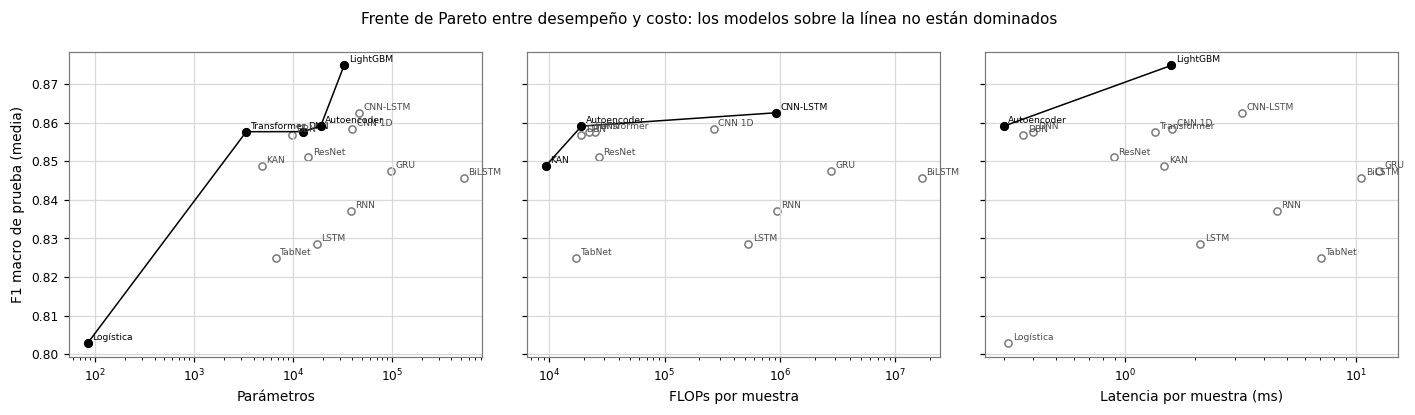

Modelo,Ganancia de F1 frente a Logística,IC 95 % de la ganancia,Δ latencia (ms),η: F1 por ms adicional
DNN,"+0,0547","[0,0314; 0,0848]","+0,089","+0,6139"
CNN 1D,"+0,0554","[0,0334; 0,0855]","+1,283","+0,0432"
LSTM,"+0,0255","[-0,0027; 0,0565]","+1,804","+0,0141"
CNN-LSTM,"+0,0596","[0,0348; 0,0943]","+2,895","+0,0206"
Autoencoder,"+0,0561","[0,0352; 0,0853]","-0,013","-4,3122"
RNN,"+0,0341","[0,0084; 0,0622]","+4,221","+0,0081"
Transformer,"+0,0547","[0,0348; 0,0815]","+1,037","+0,0527"
BiLSTM,"+0,0427","[0,0195; 0,0714]","+10,228","+0,0042"
ResNet,"+0,0480","[0,0254; 0,0785]","+0,579","+0,0829"
GRU,"+0,0444","[0,0169; 0,0776]","+12,304","+0,0036"


**Interpretación.** En parámetros, la frontera de Pareto la forman Logística, Transformer, DNN, Autoencoder y LightGBM; en FLOPs, KAN, Autoencoder y CNN-LSTM, y en latencia, Autoencoder y LightGBM. Frente a Logística, el mejor baseline no profundo por validación, ganan F1 con un IC por bloques que excluye el cero DNN, CNN 1D, CNN-LSTM, Autoencoder, RNN, Transformer, BiLSTM, ResNet, GRU, KAN y DBN; LSTM y TabNet ganan en promedio, pero su IC incluye el cero. LightGBM y Logística no entran en el frente de FLOPs, porque esa medida no aplica a esos modelos.

Esto significa que la complejidad no compra desempeño de forma proporcional: entre los 13 modelos profundos, la correlación de Spearman entre parámetros y F1 macro es de 0,07 (p = 0,817), y el modelo con más parámetros, BiLSTM, no está en la frontera. Así mismo, 11 de los 13 modelos profundos ganan con claridad F1 frente a Logística, y η indica cuánto cuesta cada unidad de esa ganancia en latencia. Hay que tener en cuenta que Logística es el mejor baseline no profundo por validación, pero no en prueba, donde LightGBM lo supera; frente a LightGBM, la comparación es la de RQ2.

Por lo anterior, conviene preferir, entre modelos estadísticamente equivalentes, el que esté en la frontera de Pareto, que es la pregunta exploratoria RQ5 de la sección 6.3.

In [60]:
def no_dominados(score, costo_v):
    orden = np.argsort(costo_v)
    frente, mejor = [], -np.inf
    for i in orden:
        if score[i] > mejor:
            frente.append(i)
            mejor = score[i]
    return frente
modelos_p = [m for m in ORDEN if m != "Trivial"]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
pareto = {}
for eje, (col, titulo) in zip(ejes, (("Parámetros", "Parámetros"), ("FLOPs", "FLOPs por muestra"), ("Latencia (ms)", "Latencia por muestra (ms)"))):
    con_medida = [m for m in modelos_p if np.isfinite(float(TABLA_A2.loc[m, col]))]
    x = TABLA_A2.loc[con_medida, col].astype(float).to_numpy()
    s = np.array([F1P[m].mean() for m in con_medida])
    frente = no_dominados(s, x)
    pareto[col] = [con_medida[i] for i in frente]
    eje.scatter(x, s, s=22, facecolors="white", edgecolors=GRIS_MEDIO)
    eje.plot(x[frente], s[frente], color=NEGRO, marker="o", ms=5, lw=1)
    for i, m in enumerate(con_medida):
        eje.annotate(m, (x[i], s[i]), fontsize=6, xytext=(3, 2), textcoords="offset points", color=NEGRO if i in frente else GRIS_OSCURO)
    eje.set_xscale("log")
    eje.set(xlabel=titulo)
ejes[0].set_ylabel("F1 macro de prueba (media)")
fig.suptitle("Frente de Pareto entre desempeño y costo: los modelos sobre la línea no están dominados", fontsize=10)
plt.tight_layout()
plt.show()
mejor_base = max(["LightGBM", "Logística"], key=lambda m: F1V[m].mean())
otro_base = "Logística" if mejor_base == "LightGBM" else "LightGBM"
eficiencia = []
for m in PROFUNDOS:
    ganancia = F1_BOOT[m] - F1_BOOT[mejor_base]
    d_lat = costo.loc[m, "ms_por_muestra"] - costo.loc[mejor_base, "ms_por_muestra"]
    eficiencia.append({"Modelo": m, "Ganancia de F1 frente a " + mejor_base: F1P[m].mean() - F1P[mejor_base].mean(), "IC 95 % de la ganancia": intervalo(E.ic_percentil(ganancia)),
                       "Δ latencia (ms)": d_lat, "η: F1 por ms adicional": (F1P[m].mean() - F1P[mejor_base].mean()) / d_lat if d_lat else np.nan})
tabla(pd.DataFrame(eficiencia), {"Ganancia de F1 frente a " + mejor_base: "{:+.4f}", "Δ latencia (ms)": "{:+.3f}", "η: F1 por ms adicional": "{:+.4f}"})
params_dl = np.array([costo.loc[m, "Parámetros"] for m in PROFUNDOS], float)
rho_p = stats.spearmanr(params_dl, [F1P[m].mean() for m in PROFUNDOS])
mas_grande = PROFUNDOS[int(np.argmax(params_dl))]
ganan_base = [m for m in PROFUNDOS if E.ic_percentil(F1_BOOT[m] - F1_BOOT[mejor_base])[0] > 0]
ganan_punto = [m for m in PROFUNDOS if F1P[m].mean() > F1P[mejor_base].mean() and m not in ganan_base]
sin_flops = [m for m in modelos_p if m not in pareto["FLOPs"] and not np.isfinite(float(TABLA_A2.loc[m, "FLOPs"]))]
interpretar(f'''**Interpretación.** En parámetros, la frontera de Pareto la forman {enumerar(pareto["Parámetros"])}; en FLOPs, {enumerar(pareto["FLOPs"])}, y en latencia, {enumerar(pareto["Latencia (ms)"])}. Frente a {mejor_base}, el mejor baseline no profundo por validación, {("gana F1 con un IC por bloques que excluye el cero " if len(ganan_base) == 1 else "ganan F1 con un IC por bloques que excluye el cero ") + enumerar(ganan_base) if ganan_base else "ningún modelo profundo gana F1 con un IC por bloques que excluya el cero"}{f"; {enumerar(ganan_punto)} {'gana' if len(ganan_punto) == 1 else 'ganan'} en promedio, pero su IC incluye el cero" if ganan_punto else ""}.{f" {enumerar(sin_flops)} no {'entra' if len(sin_flops) == 1 else 'entran'} en el frente de FLOPs, porque esa medida no aplica a {'un modelo de árboles' if sin_flops == ['LightGBM'] else 'esos modelos'}." if sin_flops else ""}

Esto significa que {"más parámetros se asocian con más desempeño" if rho_p.statistic > 0 and rho_p.pvalue < ALFA else "la complejidad no compra desempeño de forma proporcional"}: {f"entre los 13 modelos profundos, la correlación de Spearman entre parámetros y F1 macro es de {num(rho_p.statistic, 2)} ({valor_p(rho_p.pvalue)}), y " if np.isfinite(rho_p.statistic) else ""}el modelo con más parámetros, {mas_grande}, {"está" if mas_grande in pareto["Parámetros"] else "no está"} en la frontera. Así mismo, {f"{len(PROFUNDOS) - len(ganan_base)} de los 13 modelos profundos quedan por debajo de {mejor_base} en F1, de modo que en ellos el costo adicional no compra desempeño" if len(ganan_base) + len(ganan_punto) < len(PROFUNDOS) else f"{'todos los modelos profundos ganan' if not ganan_punto else f'{len(ganan_base)} de los 13 modelos profundos ganan con claridad'} F1 frente a {mejor_base}, y η indica cuánto cuesta cada unidad de esa ganancia en latencia"}.{f" Hay que tener en cuenta que {mejor_base} es el mejor baseline no profundo por validación, pero no en prueba, donde {otro_base} lo supera; frente a {otro_base}, la comparación es la de RQ2." if F1P[otro_base].mean() > F1P[mejor_base].mean() else ""}

Por lo anterior, conviene preferir, entre modelos estadísticamente equivalentes, el que esté en la frontera de Pareto, que es la pregunta exploratoria RQ5 de la sección 6.3.''')

### 6.3 Análisis estadístico y pruebas de hipótesis

**Verificación de supuestos.** Antes de elegir la prueba se verifican la normalidad de las diferencias pareadas con Shapiro-Wilk (Shapiro y Wilk, 1965), la homogeneidad de varianzas entre modelos con Brown-Forsythe (Brown y Forsythe, 1974) y la esfericidad con Mauchly (1940). La independencia se cumple a nivel de semilla, la unidad de las pruebas pareadas: cada semilla es una corrida independiente sobre la misma partición. Las R corridas comparten el conjunto de prueba, de modo que las inferencias valen para esta prueba y no para otra muestra de series; la variabilidad por partición se mide aparte, en el contraste de RQ2, con la validación cruzada 5 × 2.

In [61]:
M_ALL = F1P[ORDEN].to_numpy()
levene = stats.levene(*[F1P[m].to_numpy() for m in ORDEN if m != "Trivial"], center="median")
mauchly = E.mauchly(F1P[[m for m in ORDEN if m != "Trivial"]].to_numpy())
base = CONFIG["modelos"]["baseline_e1"]
shapiro_pares = {m: stats.shapiro(F1P[m] - F1P[base]).pvalue for m in CONFIG["modelos"]["top10"]}
tabla(pd.DataFrame({"Supuesto": ["Normalidad de las diferencias frente a CNN 1D (Shapiro-Wilk)", "Homogeneidad de varianzas (Brown-Forsythe)", "Esfericidad (Mauchly)"],
                    "Resultado": [f"{sum(p >= ALFA for p in shapiro_pares.values())} de 10 contrastes no rechazan; p de {num(min(shapiro_pares.values()), 3)} a {num(max(shapiro_pares.values()), 3)}",
                                  f"W = {num(levene.statistic, 3)}, {valor_p(levene.pvalue)}",
                                  f"W = {num(mauchly['W'], 4)}, {valor_p(mauchly['p'])}" if np.isfinite(mauchly["p"]) else f"No calculable: {R} semillas frente a {len(ORDEN) - 2} contrastes entre modelos"],
                    "Consecuencia": ["Prueba (i): t pareada donde no se rechaza; bootstrap pareado donde sí",
                                     "Las pruebas pareadas no suponen varianzas iguales entre modelos" if levene.pvalue < ALFA else "No se rechaza la homogeneidad; las pruebas pareadas no la requieren",
                                     "Se rechaza la esfericidad; la ANOVA de medidas repetidas se corrige con Greenhouse-Geisser" if np.isfinite(mauchly["p"]) and mauchly["p"] < ALFA else "La ANOVA de medidas repetidas se reporta con la corrección de Greenhouse-Geisser, por prudencia"]}))

Supuesto,Resultado,Consecuencia
Normalidad de las diferencias frente a CNN 1D (Shapiro-Wilk),"8 de 10 contrastes no rechazan; p de 0,011 a 0,939",Prueba (i): t pareada donde no se rechaza; bootstrap pareado donde sí
Homogeneidad de varianzas (Brown-Forsythe),"W = 7,811, p < 0,001",Las pruebas pareadas no suponen varianzas iguales entre modelos
Esfericidad (Mauchly),"W = 0,0000, p < 0,001",Se rechaza la esfericidad; la ANOVA de medidas repetidas se corrige con Greenhouse-Geisser


**RQ1: el Top 10 frente al baseline del Entregable 1.** Cada modelo del Top 10 se compara con CNN 1D, reentrenada en este entregable con el mismo protocolo, con las tres pruebas preregistradas (la *t* pareada o el *bootstrap* pareado, Efron y Tibshirani, 1993; Wilcoxon, 1945, y Friedman con *post hoc*) y la corrección de Holm (1979) dentro de la familia de 10 contrastes. Se agregan la *d* de Cohen (1988), TOST (Schuirmann, 1987) y la prueba bayesiana de rangos con signo con ROPE de ±δ (Benavoli et al., 2017). La tabla sigue la plantilla A.3 del enunciado.

In [62]:
def contrastes(pares, familia):
    filas_c = []
    for a, b in pares:
        r_c = E.comparar_par(F1P[a].to_numpy(), F1P[b].to_numpy())
        boot = F1_BOOT[a] - F1_BOOT[b]
        filas_c.append({"Contraste": f"{a} − {b}", "a": a, "b": b, **r_c, "IC 95 % por bloques": E.ic_percentil(boot)})
    t = pd.DataFrame(filas_c)
    t["p (i)"] = np.where(t["Shapiro-Wilk p"] >= ALFA, t["p t pareada"], t["p bootstrap"])
    t["Prueba (i)"] = np.where(t["Shapiro-Wilk p"] >= ALFA, "t pareada", "bootstrap pareado")
    t["p (i) Holm"] = E.holm(t["p (i)"])
    t["p Wilcoxon Holm"] = E.holm(t["p Wilcoxon"])
    t["Decisión"] = [E.decision(fila, fila["p (i) Holm"], fila["p Wilcoxon Holm"]) for _, fila in t.iterrows()]
    t["Familia"] = familia
    return t
RQ1 = contrastes([(m, base) for m in CONFIG["modelos"]["top10"]], "F1")
def presentar(t):
    return pd.DataFrame({"Contraste": t["Contraste"], "Prueba (i)": t["Prueba (i)"], "Diferencia": t["Diferencia media"],
                         "IC 95 % (semillas)": [intervalo(f["IC 95 % t"] if f["Shapiro-Wilk p"] >= ALFA else f["IC 95 % bootstrap"]) for _, f in t.iterrows()],
                         "IC 95 % (bloques)": [intervalo(x) for x in t["IC 95 % por bloques"]], "d de Cohen": t["d de Cohen pareada"], "δ de Cliff": t["δ de Cliff"],
                         "p (i)": t["p (i)"].map(p_exacto), "p (i) Holm": t["p (i) Holm"].map(p_exacto), "p Wilcoxon": t["p Wilcoxon"].map(p_exacto), "p Wilcoxon Holm": t["p Wilcoxon Holm"].map(p_exacto),
                         "p TOST": t["p TOST"].map(p_exacto), "P(ROPE) bayesiana": t["P(ROPE)"], "Potencia para δ": t["Potencia para δ"], "Decisión frente a δ": t["Decisión"]})
tabla(presentar(RQ1), {"Diferencia": "{:+.4f}", "d de Cohen": "{:.2f}", "δ de Cliff": "{:.2f}", "P(ROPE) bayesiana": "{:.3f}", "Potencia para δ": "{:.3f}"})
RQ1.to_csv(RESULTADOS / "contrastes_rq1.csv", index=False)
dec = RQ1["Decisión"].value_counts()
DECISION_TXT = {"No concluyente": ("no concluyente", "no concluyentes"), "Equivalente": ("equivalente", "equivalentes"),
                "Significativa y relevante": ("significativo y relevante", "significativos y relevantes"), "Significativa sin relevancia": ("significativo sin relevancia", "significativos sin relevancia")}
def lectura_rq1():
    sig = RQ1["Decisión"].str.startswith("Significativa")
    rel_pos = RQ1.loc[RQ1["Decisión"].eq("Significativa y relevante") & (RQ1["Diferencia media"] > 0), "a"].tolist()
    sin_rel = RQ1.loc[RQ1["Decisión"].eq("Significativa sin relevancia") & (RQ1["Diferencia media"] > 0), "a"].tolist()
    neg = RQ1.loc[RQ1["Decisión"].eq("Significativa y relevante") & (RQ1["Diferencia media"] < 0), "a"].tolist()
    neg_sin = RQ1.loc[RQ1["Decisión"].eq("Significativa sin relevancia") & (RQ1["Diferencia media"] < 0), "a"].tolist()
    nc = RQ1.loc[RQ1["Decisión"].eq("No concluyente"), "a"].tolist()
    equiv = RQ1.loc[RQ1["Decisión"].eq("Equivalente"), "a"].tolist()
    n_nc = int(RQ1["Decisión"].eq("No concluyente").sum())
    partes = ["Esto quiere decir que " + (f"{enumerar(rel_pos)} {'supera' if len(rel_pos) == 1 else 'superan'} al baseline del Entregable 1 de forma significativa y relevante, de modo que H0 se rechaza a su favor"
                                          if rel_pos else "ningún modelo del Top 10 supera al baseline del Entregable 1 en una magnitud mayor que δ con evidencia estadística, de modo que H0 no se rechaza a favor del Top 10 en ningún contraste") + "."]
    if sin_rel:
        partes.append(f"{enumerar(sin_rel)} {'lo supera' if len(sin_rel) == 1 else 'lo superan'} de forma significativa, pero por menos de δ, de modo que la mejora no es relevante.")
    if neg or neg_sin:
        partes.append("En cambio, " + (f"{enumerar(neg)} {'queda' if len(neg) == 1 else 'quedan'} por debajo del baseline en más de δ" if neg else "")
                      + (", y " if neg and neg_sin else "") + (f"{enumerar(neg_sin)} {'queda' if len(neg_sin) == 1 else 'quedan'} por debajo de forma significativa, pero por menos de δ" if neg_sin else "") + ".")
    if equiv:
        partes.append(f"{enumerar(equiv)} {'es equivalente' if len(equiv) == 1 else 'son equivalentes'} al baseline dentro de ±δ según TOST.")
    if n_nc:
        partes.append(f"{'El contraste no concluyente, el de ' + nc[0] + ', no permite' if n_nc == 1 else f'Los {n_nc} contrastes no concluyentes, los de {enumerar(nc)}, no permiten'} afirmar ni superioridad ni equivalencia, porque su intervalo no excluye el cero ni cabe dentro de ±δ.")
    partes.append("La prueba bayesiana, con su probabilidad de estar dentro del ROPE, complementa esa lectura sin control de error por familia.")
    return " ".join(partes)
interpretar(f'''**Interpretación.** De los 10 contrastes de RQ1, {enumerar([f"{v} {('es ' if v == 1 else 'son ') if i == 0 else ''}{DECISION_TXT.get(k, (k.lower(), k.lower()))[0 if v == 1 else 1]}" for i, (k, v) in enumerate(dec.items())])}. Las diferencias frente a CNN 1D van de {num(RQ1["Diferencia media"].min(), 4)} ({RQ1.loc[RQ1["Diferencia media"].idxmin(), "a"]}) a {num(RQ1["Diferencia media"].max(), 4)} ({RQ1.loc[RQ1["Diferencia media"].idxmax(), "a"]}), con una potencia para δ de {num(RQ1["Potencia para δ"].min(), 2)} a {num(RQ1["Potencia para δ"].max(), 2)}.

{lectura_rq1()}

Por tanto, corresponde responder RQ1 con la columna de decisión, que aplica la regla del preregistro, y no con el orden de la tabla 6.1.''')

Contraste,Prueba (i),Diferencia,IC 95 % (semillas),IC 95 % (bloques),d de Cohen,δ de Cliff,p (i),p (i) Holm,p Wilcoxon,p Wilcoxon Holm,p TOST,P(ROPE) bayesiana,Potencia para δ,Decisión frente a δ
CNN-LSTM − CNN 1D,bootstrap pareado,"+0,0041","[-0,0042; 0,0115]","[-0,0112; 0,0240]","0,22","0,42","0,3114","1,0000","0,1429","0,5716","0,0866","0,704","0,627",No concluyente
Autoencoder − CNN 1D,t pareada,"+0,0007","[-0,0043; 0,0056]","[-0,0085; 0,0136]","0,06","0,01","0,7829","1,0000","0,9273","1,0000","0,0004","1,000","0,981",Equivalente
RNN − CNN 1D,bootstrap pareado,"-0,0213","[-0,0296; -0,0123]","[-0,0345; -0,0083]","-1,05","-0,66","1,00e-04","0,0009","0,0003","0,0029","0,9892","0,006","0,555",Significativa y relevante
Transformer − CNN 1D,t pareada,"-0,0008","[-0,0069; 0,0053]","[-0,0118; 0,0124]","-0,06","0,12","0,7902","1,0000","0,9273","1,0000","0,0026","0,998","0,901",Equivalente
BiLSTM − CNN 1D,t pareada,"-0,0127","[-0,0244; -0,0011]","[-0,0262; -0,0005]","-0,51","-0,33","0,0334","0,1934","0,0362","0,2174","0,6858","0,451","0,401",No concluyente
ResNet − CNN 1D,t pareada,"-0,0075","[-0,0142; -0,0007]","[-0,0193; 0,0074]","-0,52","-0,33","0,0322","0,1934","0,0400","0,2174","0,2215","0,821","0,835",No concluyente
GRU − CNN 1D,t pareada,"-0,0110","[-0,0168; -0,0053]","[-0,0224; 0,0011]","-0,90","-0,59","0,0007","0,0058","0,0010","0,0081","0,6431","0,506","0,933",Significativa y relevante
KAN − CNN 1D,t pareada,"-0,0096","[-0,0159; -0,0033]","[-0,0209; 0,0033]","-0,71","-0,51","0,0050","0,0351","0,0049","0,0340","0,4473","0,636","0,880",Significativa sin relevancia
TabNet − CNN 1D,t pareada,"-0,0335","[-0,0432; -0,0238]","[-0,0499; -0,0202]","-1,62","-0,87","7,39e-07","7,39e-06","5,72e-06","5,72e-05","1,0000","0,000","0,535",Significativa y relevante
DBN − CNN 1D,t pareada,"-0,0016","[-0,0058; 0,0027]","[-0,0123; 0,0071]","-0,17","-0,11","0,4579","1,0000","0,6742","1,0000","0,0003","1,000","0,996",Equivalente


**Interpretación.** De los 10 contrastes de RQ1, 3 son no concluyentes, 3 equivalentes, 3 significativos y relevantes y 1 significativo sin relevancia. Las diferencias frente a CNN 1D van de -0,0335 (TabNet) a 0,0041 (CNN-LSTM), con una potencia para δ de 0,40 a 1,00.

Esto quiere decir que ningún modelo del Top 10 supera al baseline del Entregable 1 en una magnitud mayor que δ con evidencia estadística, de modo que H0 no se rechaza a favor del Top 10 en ningún contraste. En cambio, RNN, GRU y TabNet quedan por debajo del baseline en más de δ, y KAN queda por debajo de forma significativa, pero por menos de δ. Autoencoder, Transformer y DBN son equivalentes al baseline dentro de ±δ según TOST. Los 3 contrastes no concluyentes, los de CNN-LSTM, BiLSTM y ResNet, no permiten afirmar ni superioridad ni equivalencia, porque su intervalo no excluye el cero ni cabe dentro de ±δ. La prueba bayesiana, con su probabilidad de estar dentro del ROPE, complementa esa lectura sin control de error por familia.

Por tanto, corresponde responder RQ1 con la columna de decisión, que aplica la regla del preregistro, y no con el orden de la tabla 6.1.

**Procedimiento global.** Friedman (1937), con la corrección de Iman y Davenport (1980), compara los 16 modelos con las semillas como bloques; el *post hoc* de Nemenyi da la distancia crítica del diagrama (Demšar, 2006), y el de Wilcoxon con Holm, las comparaciones por pares. Se complementa con la ANOVA de medidas repetidas con la corrección de Greenhouse y Geisser (1959) y con el *Model Confidence Set* de Hansen et al. (2011) al 90 %, sobre la pérdida 1 − F1 macro por bloque de prueba.

Prueba,Estadístico,p,Tamaño de efecto
Friedman,"184,80","2,55e-31","W de Kendall = 0,616"
Iman-Davenport,"30,48","1,62e-50",
ANOVA de medidas repetidas (Greenhouse-Geisser),"3782,25","1,14e-121","η² parcial = 0,995; ε = 0,378"


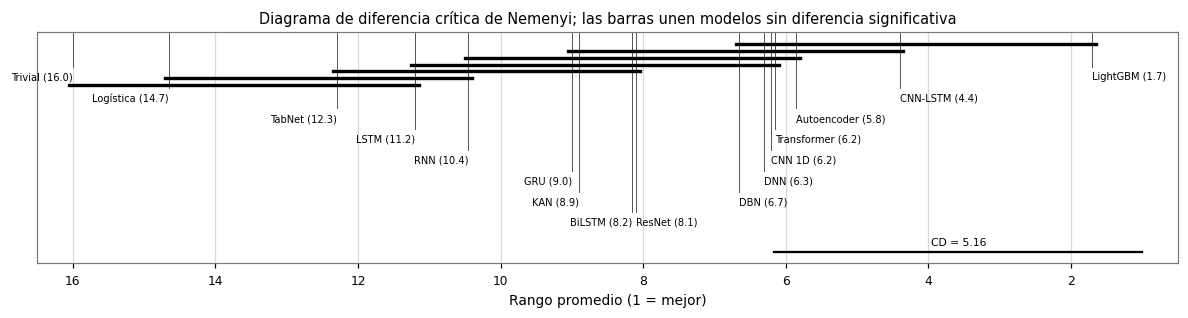

Pares significativos con Wilcoxon-Holm: 58 de 120


Model Confidence Set al 90 %: DNN, CNN 1D, CNN-LSTM, Autoencoder, Transformer, ResNet, GRU, KAN, DBN y LightGBM


**Interpretación.** Friedman rechaza la igualdad de rangos de los 16 modelos, con χ² = 184,8 (p < 0,001); la corrección de Iman y Davenport da p < 0,001, con una W de Kendall de 0,616, y la ANOVA de medidas repetidas coincide (p < 0,001, ε de Greenhouse-Geisser = 0,378). La distancia crítica de Nemenyi es de 5,16 rangos, y el *Model Confidence Set* al 90 % conserva 10 modelos: DNN, CNN 1D, CNN-LSTM, Autoencoder, Transformer, ResNet, GRU, KAN, DBN y LightGBM.

Es decir, hay diferencias entre los modelos: de los 120 pares, 58 son significativos con Wilcoxon-Holm, 15 de ellos frente al trivial. El MCS deja en la cima 10 modelos que estos datos no pueden separar. Hay que tener en cuenta que Nemenyi es conservador con 16 modelos y 20 semillas, y que el MCS opera sobre los 24 bloques de prueba, la unidad independiente, de modo que su conjunto es la lectura más honesta de qué modelos están en la cima.

Por ello, se recomienda presentar como ganadores al conjunto del MCS y no a un solo modelo.

In [63]:
fr = E.friedman(M_ALL)
anova_rm = E.anova_repetidas(M_ALL)
rangos_n, p_nem, cd = E.nemenyi(M_ALL)
tabla(pd.DataFrame({"Prueba": ["Friedman", "Iman-Davenport", "ANOVA de medidas repetidas (Greenhouse-Geisser)"], "Estadístico": [fr["chi2"], fr["F Iman-Davenport"], anova_rm["F"]],
                    "p": [p_exacto(fr["p"]), p_exacto(fr["p Iman-Davenport"]), p_exacto(anova_rm["p GG"])],
                    "Tamaño de efecto": [f"W de Kendall = {num(fr['W de Kendall'], 3)}", "", f"η² parcial = {num(anova_rm['η² parcial'], 3)}; ε = {num(anova_rm['épsilon GG'], 3)}"]}),
      {"Estadístico": "{:.2f}"})
orden_r = np.argsort(rangos_n)
fig, eje = plt.subplots(figsize=(11, 3.0))
eje.set(xlim=(len(ORDEN) + 0.5, 0.5), ylim=(0, 1))
eje.yaxis.set_visible(False)
for i, j in enumerate(orden_r):
    lado = i < len(ORDEN) / 2
    yy = 0.85 - 0.09 * (i if lado else len(ORDEN) - 1 - i)
    eje.plot([rangos_n[j]] * 2, [1, yy], color=GRIS_OSCURO, lw=0.6)
    eje.text(rangos_n[j], yy - 0.02, f"{ORDEN[j]} ({rangos_n[j]:.1f})", ha="left" if lado else "right", va="top", fontsize=6.5)
grupos_cd = []
for i in range(len(orden_r)):
    fin = max([k for k in range(i, len(orden_r)) if rangos_n[orden_r[k]] - rangos_n[orden_r[i]] <= cd], default=i)
    if fin > i and not any(g[0] <= i and fin <= g[1] for g in grupos_cd):
        grupos_cd.append((i, fin))
for n_g, (i, fin) in enumerate(grupos_cd):
    eje.plot([rangos_n[orden_r[i]] - 0.05, rangos_n[orden_r[fin]] + 0.05], [0.95 - 0.03 * n_g] * 2, color=NEGRO, lw=2.2)
eje.plot([1, 1 + cd], [0.05] * 2, color=NEGRO, lw=1.5)
eje.text(1 + cd / 2, 0.08, f"CD = {cd:.2f}", ha="center", fontsize=7)
eje.set_xlabel("Rango promedio (1 = mejor)")
eje.set_title("Diagrama de diferencia crítica de Nemenyi; las barras unen modelos sin diferencia significativa", fontsize=9.5)
plt.tight_layout()
plt.show()
p_wh = np.ones((len(ORDEN), len(ORDEN)))
pares_todos = [(i, j) for i in range(len(ORDEN)) for j in range(i + 1, len(ORDEN))]
p_crudos = [stats.wilcoxon(M_ALL[:, i] - M_ALL[:, j]).pvalue if np.any(M_ALL[:, i] != M_ALL[:, j]) else 1.0 for i, j in pares_todos]
for (i, j), ph in zip(pares_todos, E.holm(p_crudos)):
    p_wh[i, j] = p_wh[j, i] = ph
WILCOXON_HOLM = pd.DataFrame(p_wh, index=ORDEN, columns=ORDEN)
print(f"Pares significativos con Wilcoxon-Holm: {int((np.triu(p_wh, 1)[np.triu_indices(len(ORDEN), 1)] < ALFA).sum())} de {len(pares_todos)}")
perdida_bloque = np.column_stack([1 - np.mean([[AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]) for b in range(NB_PRU)] for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]], 0)
                                  for m in modelos_p])
mcs = E.model_confidence_set(perdida_bloque, nivel=0.10)
MCS = [modelos_p[i] for i in mcs["conjunto"]]
print(f"Model Confidence Set al 90 %: {enumerar(MCS)}")
sig_pares = [(ORDEN[i], ORDEN[j]) for i, j in pares_todos if p_wh[i, j] < ALFA]
n_sig_trivial = sum("Trivial" in par for par in sig_pares)
global_rechaza = fr["p Iman-Davenport"] < ALFA
interpretar(f'''**Interpretación.** Friedman {"rechaza" if fr["p"] < ALFA else "no rechaza"} la igualdad de rangos de los {len(ORDEN)} modelos, con χ² = {num(fr["chi2"], 1)} ({valor_p(fr["p"])}); la corrección de Iman y Davenport da {valor_p(fr["p Iman-Davenport"])}, con una W de Kendall de {num(fr["W de Kendall"], 3)}, y la ANOVA de medidas repetidas {"coincide" if (anova_rm["p GG"] < ALFA) == global_rechaza else "no coincide"} ({valor_p(anova_rm["p GG"])}, ε de Greenhouse-Geisser = {num(anova_rm["épsilon GG"], 3)}). La distancia crítica de Nemenyi es de {num(cd, 2)} rangos, y el *Model Confidence Set* al 90 % {"conserva un solo modelo, " + MCS[0] if len(MCS) == 1 else f"conserva {len(MCS)} modelos: " + enumerar(MCS)}.

Es decir, {"hay diferencias entre los modelos" if global_rechaza else "no hay evidencia de diferencias globales entre los modelos"}{f": de los {len(pares_todos)} pares, {len(sig_pares)} son significativos con Wilcoxon-Holm, {n_sig_trivial} de ellos frente al trivial" if sig_pares else (f", aunque ningún par es significativo con Wilcoxon-Holm: con {R} semillas, el p exacto mínimo de Wilcoxon es {p_exacto(2 / 2 ** R)}, y la corrección de Holm sobre {len(pares_todos)} pares lo lleva por encima de α" if 2 / 2 ** R * len(pares_todos) >= ALFA else f", aunque ningún par de los {len(pares_todos)} es significativo con Wilcoxon-Holm")}. {f"El MCS deja en la cima a un solo modelo, {MCS[0]}: con un nivel de 0,10, ningún otro iguala su pérdida por bloque." if len(MCS) == 1 else f"El MCS deja en la cima {len(MCS)} modelos que estos datos no pueden separar."} Hay que tener en cuenta que Nemenyi es conservador con {len(ORDEN)} modelos y {R} semillas, y que el MCS opera sobre los {NB_PRU} bloques de prueba, la unidad independiente, de modo que su conjunto es la lectura más honesta de qué modelos están en la cima.

{"Por ello, se recomienda presentar como ganadores al conjunto del MCS y no a un solo modelo." if len(MCS) > 1 else f"Por ello, se presenta a {MCS[0]} como el mejor modelo del benchmark, con la salvedad de que la conclusión vale para estas series de prueba."}''')

**RQ2: el mejor modelo profundo frente a LightGBM.** El mejor modelo profundo se elige por su F1 macro medio de validación, para no sesgar el contraste con la propia prueba. Además de las tres pruebas preregistradas y TOST, se reportan McNemar (1947) y DeLong et al. (1988) sobre el promedio de probabilidades de las R semillas, que suponen filas independientes, y la *F* de 5 × 2 cv de Alpaydin (1999) y la *t* con la corrección de Nadeau y Bengio (2003) sobre la validación cruzada 5 × 2 agrupada, que miden también la variabilidad por partición.

In [64]:
RQ2 = contrastes([(MEJOR_DL, "LightGBM")], "F2")
RQ2.to_csv(RESULTADOS / "contrastes_rq2.csv", index=False)
tabla(presentar(RQ2), {"Diferencia": "{:+.4f}", "d de Cohen": "{:.2f}", "δ de Cliff": "{:.2f}", "P(ROPE) bayesiana": "{:.3f}", "Potencia para δ": "{:.3f}"})
ens = {m: np.mean([AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva") for s in SEMILLAS], 0) for m in (MEJOR_DL, "LightGBM")}
mc = E.mcnemar_exacta(ens[MEJOR_DL].argmax(1) == y_pru, ens["LightGBM"].argmax(1) == y_pru)
dl_clases = [E.delong(y_pru == c, ens[MEJOR_DL][:, c], ens["LightGBM"][:, c]) for c in range(K)]
cv = RES.tabla_fase("cv5x2")
def diferencias_cv(a, b):
    pa = cv[cv["modelo"] == a].set_index("particion")["f1_eva"]
    pb = cv[cv["modelo"] == b].set_index("particion")["f1_eva"]
    nombres_cv = sorted(pa.index)
    return (pa[nombres_cv] - pb[nombres_cv]).to_numpy()
d_cv = diferencias_cv(MEJOR_DL, "LightGBM")
nb = E.nadeau_bengio(d_cv, 1, 1)
f52 = E.f_5x2cv(d_cv)
tabla(pd.DataFrame({"Prueba complementaria": ["McNemar (promedio de semillas)", *[f"DeLong, AUC de {CLASES[c]} uno contra todos" for c in range(K)], "t de Nadeau-Bengio (5 × 2 cv)", "F de 5 × 2 cv (Alpaydin)"],
                    "Diferencia o estadístico": [f"b = {mc['b']}, c = {mc['c']}", *[f"{num(d['diferencia'], 4)}" for d in dl_clases], f"diferencia media {num(d_cv.mean(), 4)}, t = {num(nb['t'], 2)}", f"F = {num(f52['F'], 2)}"],
                    "p": [p_exacto(mc["p"]), *[p_exacto(ph) for ph in E.holm([d["p"] for d in dl_clases])], p_exacto(nb["p"]), p_exacto(f52["p"])],
                    "Nota": ["Supone filas independientes", *["p con Holm entre las 5 clases"] * K, "Corrige el solapamiento de entrenamiento", "Alternativa con pocas ejecuciones"]}))
r2 = RQ2.iloc[0]
p_delong = E.holm([d["p"] for d in dl_clases])
filas_sig = mc["p"] < ALFA or min(p_delong) < ALFA
semillas_sig = r2["Decisión"].startswith("Significativa")
if r2["Decisión"] == "Significativa y relevante" and r2["Diferencia media"] > 0:
    lectura_rq2 = "el mejor modelo profundo supera al árbol potenciado de forma significativa y relevante, a pesar de que en datos tabulares los árboles potenciados suelen ser la referencia más difícil de batir"
elif semillas_sig and r2["Diferencia media"] < 0:
    lectura_rq2 = "el árbol potenciado supera al mejor modelo profundo de forma significativa, lo que es coherente con la advertencia del enunciado: en tablas de pocos atributos, los árboles potenciados son una referencia muy difícil de batir"
elif semillas_sig:
    lectura_rq2 = "el mejor modelo profundo supera al árbol potenciado de forma significativa, pero por menos de δ, de modo que la ventaja no es relevante en la práctica"
elif r2["Decisión"] == "Equivalente":
    lectura_rq2 = "el mejor modelo profundo y el árbol potenciado son equivalentes dentro de ±δ, de modo que la arquitectura profunda no aporta F1 frente a un modelo más barato"
else:
    lectura_rq2 = "el mejor modelo profundo no supera al árbol potenciado ajustado con el mismo presupuesto, aunque estos datos tampoco permiten declararlos equivalentes"
cv_sig = nb["p"] < ALFA
ic_b2 = r2["IC 95 % por bloques"]
if semillas_sig and not cv_sig:
    lectura_cv = (f" Sin embargo, la ventaja depende de las series de la prueba: en la validación cruzada 5 × 2, que reparte entre ajuste y evaluación los {NB_ENT + NB_VAL} bloques de entrenamiento y validación sin tocar la prueba, "
                  f"la diferencia media es de {num(d_cv.mean(), 4)} ({valor_p(nb['p'])}), y el IC por bloques de la prueba {'contiene al cero' if ic_b2[0] <= 0 <= ic_b2[1] else 'excluye el cero'}. "
                  f"Es decir, la regla preregistrada compara {R} semillas sobre las mismas {NB_PRU} series de prueba, de modo que detecta una diferencia real en esas series, pero no garantiza que se repita en series nuevas; "
                  "en otras particiones del mismo archivo, los dos modelos empatan")
elif cv_sig and np.sign(d_cv.mean()) == np.sign(r2["Diferencia media"]):
    lectura_cv = f" La validación cruzada 5 × 2, que cambia los datos de ajuste, confirma el signo de la diferencia ({num(d_cv.mean(), 4)}; {valor_p(nb['p'])}), de modo que la conclusión no depende solo de las series de la prueba"
else:
    lectura_cv = ""
if filas_sig and not semillas_sig:
    lectura_filas = "La discrepancia entre las pruebas por semillas y las pruebas por filas ilustra por qué estas últimas no sustentan conclusiones: con 22 883 flujos tratados como independientes, McNemar y DeLong detectan diferencias minúsculas, cuando la unidad independiente es la serie."
elif not filas_sig:
    lectura_filas = "Las pruebas por filas tampoco detectan diferencias, lo que refuerza esa lectura."
else:
    lectura_filas = "Las pruebas por filas coinciden, aunque su valor p es optimista porque tratan los flujos como independientes."
interpretar(f'''**Interpretación.** El mejor modelo profundo por validación es {MEJOR_DL}. Frente a LightGBM, su diferencia media en F1 macro de prueba es de {num(r2["Diferencia media"], 4)}, con IC 95 % por bloques de {intervalo(r2["IC 95 % por bloques"])}, y la decisión de la regla preregistrada es «{r2["Decisión"].lower()}» ({r2["Prueba (i)"]}: {valor_p(r2["p (i)"])}; Wilcoxon: {valor_p(r2["p Wilcoxon"])}; TOST: {valor_p(r2["p TOST"])}). En la validación cruzada 5 × 2, que cambia los datos de entrenamiento, la diferencia media es de {num(d_cv.mean(), 4)}, con {valor_p(nb["p"])} en la *t* de Nadeau y Bengio y {valor_p(f52["p"])} en la *F* de Alpaydin. McNemar da {valor_p(mc["p"])}, y DeLong, valores p con Holm entre {p_exacto(min(p_delong))} y {p_exacto(max(p_delong))} según la clase; ambas suponen filas independientes.

Esto significa que {lectura_rq2}.{lectura_cv}. {lectura_filas}

Por tal motivo, la respuesta a RQ2 es la decisión de la regla preregistrada{", acotada a las series de esta prueba" if lectura_cv.startswith(" Sin embargo") else ""}, y la justificación para usar un modelo profundo en lugar de LightGBM, si la hay, tiene que venir de otro eje: robustez, calibración o costo.''')

Contraste,Prueba (i),Diferencia,IC 95 % (semillas),IC 95 % (bloques),d de Cohen,δ de Cliff,p (i),p (i) Holm,p Wilcoxon,p Wilcoxon Holm,p TOST,P(ROPE) bayesiana,Potencia para δ,Decisión frente a δ
CNN 1D − LightGBM,t pareada,"-0,0164","[-0,0188; -0,0139]","[-0,0553; 0,0257]","-3,13","-1,00","1,83e-11","1,83e-11","1,91e-06","1,91e-06","1,0000","0,000","1,000",Significativa y relevante


Prueba complementaria,Diferencia o estadístico,p,Nota
McNemar (promedio de semillas),"b = 555, c = 978","4,37e-27",Supone filas independientes
"DeLong, AUC de Blackhole uno contra todos","-0,0119","1,40e-111",p con Holm entre las 5 clases
"DeLong, AUC de Flooding uno contra todos","-0,0092","3,08e-46",p con Holm entre las 5 clases
"DeLong, AUC de Normal uno contra todos","-0,0004","4,34e-12",p con Holm entre las 5 clases
"DeLong, AUC de Sybil uno contra todos","0,0064","0,0063",p con Holm entre las 5 clases
"DeLong, AUC de Wormhole uno contra todos","-0,0182","2,11e-148",p con Holm entre las 5 clases
t de Nadeau-Bengio (5 × 2 cv),"diferencia media -0,0003, t = -0,01","0,9902",Corrige el solapamiento de entrenamiento
F de 5 × 2 cv (Alpaydin),"F = 0,61","0,7645",Alternativa con pocas ejecuciones


**Interpretación.** El mejor modelo profundo por validación es CNN 1D. Frente a LightGBM, su diferencia media en F1 macro de prueba es de -0,0164, con IC 95 % por bloques de [-0,0553; 0,0257], y la decisión de la regla preregistrada es «significativa y relevante» (t pareada: p < 0,001; Wilcoxon: p < 0,001; TOST: p = 1,000). En la validación cruzada 5 × 2, que cambia los datos de entrenamiento, la diferencia media es de -0,0003, con p = 0,990 en la *t* de Nadeau y Bengio y p = 0,764 en la *F* de Alpaydin. McNemar da p < 0,001, y DeLong, valores p con Holm entre 2,11e-148 y 0,0063 según la clase; ambas suponen filas independientes.

Esto significa que el árbol potenciado supera al mejor modelo profundo de forma significativa, lo que es coherente con la advertencia del enunciado: en tablas de pocos atributos, los árboles potenciados son una referencia muy difícil de batir. Sin embargo, la ventaja depende de las series de la prueba: en la validación cruzada 5 × 2, que reparte entre ajuste y evaluación los 97 bloques de entrenamiento y validación sin tocar la prueba, la diferencia media es de -0,0003 (p = 0,990), y el IC por bloques de la prueba contiene al cero. Es decir, la regla preregistrada compara 20 semillas sobre las mismas 24 series de prueba, de modo que detecta una diferencia real en esas series, pero no garantiza que se repita en series nuevas; en otras particiones del mismo archivo, los dos modelos empatan. Las pruebas por filas coinciden, aunque su valor p es optimista porque tratan los flujos como independientes.

Por tal motivo, la respuesta a RQ2 es la decisión de la regla preregistrada, acotada a las series de esta prueba, y la justificación para usar un modelo profundo en lugar de LightGBM, si la hay, tiene que venir de otro eje: robustez, calibración o costo.

**RQ3: modelos que leen los atributos como secuencia frente a los que no suponen orden.** Para cada semilla se promedia el F1 macro de los seis modelos secuenciales (CNN 1D, LSTM, RNN, GRU, BiLSTM y CNN-LSTM) y el de los siete que no suponen orden (DNN, ResNet, Autoencoder, DBN, KAN, TabNet y Transformer), y se comparan los promedios con la *t* pareada y Wilcoxon. Como procedimiento global, un modelo lineal de efectos mixtos sobre el F1 macro por bloque de prueba, $y_{ijr} = \mu + \alpha_{g(j)} + u_i + v_r + \varepsilon_{ijr}$, estima el efecto del grupo con efectos aleatorios cruzados de bloque $u_i$ y de semilla $v_r$.

In [65]:
import statsmodels.formula.api as smf

SECUENCIA = ["CNN 1D", "LSTM", "RNN", "GRU", "BiLSTM", "CNN-LSTM"]
SIN_ORDEN = ["DNN", "ResNet", "Autoencoder", "DBN", "KAN", "TabNet", "Transformer"]
r3 = E.comparar_par(F1P[SECUENCIA].mean(1).to_numpy(), F1P[SIN_ORDEN].mean(1).to_numpy())
filas_mm = []
for m in PROFUNDOS:
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        s_ = int(METRICAS.loc[METRICAS["id"] == i, "semilla"].iloc[0])
        for b in range(NB_PRU):
            filas_mm.append({"f1": AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]), "modelo": m, "grupo": "secuencia" if m in SECUENCIA else "sin orden", "bloque": b, "semilla": s_})
MM = pd.DataFrame(filas_mm)
# Efectos aleatorios cruzados de bloque y de semilla: un solo grupo con dos componentes de varianza
CRUZADOS = {"bloque": "0 + C(bloque)", "semilla": "0 + C(semilla)"}
mixto = smf.mixedlm("f1 ~ C(grupo, Treatment('sin orden'))", MM, groups=np.ones(len(MM)), re_formula="0", vc_formula=CRUZADOS).fit(reml=True)
coef = mixto.params.iloc[1]
ic_mm = mixto.conf_int().iloc[1].to_numpy()
tabla(pd.DataFrame({"Prueba": ["t pareada sobre semillas", "Wilcoxon sobre semillas", "Modelo mixto (bloque y semilla aleatorios)"],
                    "Diferencia secuencia − sin orden": [r3["Diferencia media"], r3["Diferencia media"], coef],
                    "IC 95 %": [intervalo(r3["IC 95 % t"]), intervalo(r3["IC 95 % bootstrap"]), intervalo(ic_mm)],
                    "p": [p_exacto(r3["p t pareada"]), p_exacto(r3["p Wilcoxon"]), p_exacto(mixto.pvalues.iloc[1])]}), {"Diferencia secuencia − sin orden": "{:+.4f}"})
RQ3_DECISION = E.decision(r3, r3["p t pareada"] if r3["Shapiro-Wilk p"] >= ALFA else r3["p bootstrap"], r3["p Wilcoxon"])
mixto_var = smf.mixedlm("f1 ~ C(modelo)", MM, groups=np.ones(len(MM)), re_formula="0", vc_formula=CRUZADOS).fit(reml=True)
componentes = dict(zip(mixto_var.model.exog_vc.names, mixto_var.vcomp))
var_bloque, var_semilla, var_resid = float(componentes["bloque"]), float(componentes["semilla"]), float(mixto_var.scale)
efectos_fijos = mixto_var.fe_params.iloc[1:]
var_modelo = float(np.var(np.r_[0, efectos_fijos.to_numpy()]))
total_var = var_modelo + var_bloque + var_semilla + var_resid
DESCOMP = pd.DataFrame({"Componente": ["Modelo (efecto fijo)", "Bloque de prueba", "Semilla", "Residuo"], "Varianza": [var_modelo, var_bloque, var_semilla, var_resid]})
DESCOMP["% del total"] = 100 * DESCOMP["Varianza"] / total_var
razon_bm = var_bloque / var_modelo if var_modelo > 0 else np.inf
lectura_rq3 = {("Significativa y relevante", True): "imponer un orden a las columnas perjudica en una magnitud mayor que δ",
               ("Significativa y relevante", False): "leer los atributos como secuencia mejora el desempeño en una magnitud mayor que δ, aunque el orden de las columnas es arbitrario, de modo que el beneficio vendría de los pesos compartidos y de la recurrencia más que de un orden real",
               ("Significativa sin relevancia", True): "la diferencia en contra de los modelos secuenciales es real, pero menor que δ",
               ("Significativa sin relevancia", False): "la diferencia a favor de los modelos secuenciales es real, pero menor que δ",
               ("Equivalente", True): "los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño",
               ("Equivalente", False): "los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño",
               ("No concluyente", True): "estos datos no permiten afirmar que el supuesto de orden cambie el desempeño, ni que sea irrelevante",
               ("No concluyente", False): "estos datos no permiten afirmar que el supuesto de orden cambie el desempeño, ni que sea irrelevante"}[(RQ3_DECISION, bool(r3["Diferencia media"] < 0))]
tabla(DESCOMP, {"Varianza": "{:.6f}", "% del total": "{:.1f}"})
interpretar(f'''**Interpretación.** En RQ3, los modelos que leen los atributos como secuencia obtienen, en promedio por semilla, una diferencia de {num(r3["Diferencia media"], 4)} en F1 macro frente a los que no suponen orden, con IC 95 % de {intervalo(r3["IC 95 % t"])}; el modelo mixto estima {num(coef, 4)}, con IC de {intervalo(ic_mm)}, y la decisión preregistrada es «{RQ3_DECISION.lower()}». En la descomposición de la varianza del F1 por bloque, el modelo explica el {num(DESCOMP.loc[0, "% del total"], 1)} %, el bloque de prueba el {num(DESCOMP.loc[1, "% del total"], 1)} %, la semilla el {num(DESCOMP.loc[2, "% del total"], 1)} % y el residuo el {num(DESCOMP.loc[3, "% del total"], 1)} %.

Lo anterior indica que {lectura_rq3}. {"Las dos estimaciones tienen el mismo signo" if np.sign(coef) == np.sign(r3["Diferencia media"]) else "Las dos estimaciones difieren en signo, de modo que el efecto depende de cómo se agreguen las series"}; {"difieren en magnitud porque" if np.sign(coef) == np.sign(r3["Diferencia media"]) else "esto ocurre porque"} el modelo mixto pondera por igual cada bloque y promedia el F1 sobre las clases presentes en él, mientras que la prueba por semillas usa el F1 macro de la prueba completa. Así mismo, {f"la serie pesa mucho más que la arquitectura: el bloque de prueba explica {num(razon_bm, 1)} veces la varianza que explica el modelo, de modo que, como advierte la sección 13.2 del enunciado, el orden entre modelos puede cambiar con otra elección de series" if razon_bm > 2 else ("la serie pesa tanto como la arquitectura, de modo que el orden entre modelos es sensible a la elección de las series" if razon_bm > 0.5 else "la arquitectura pesa más que la serie, de modo que el orden entre modelos es estable frente a la elección de las series")}.

Por ello, se recomienda no generalizar el orden de la tabla 6.1 a otras particiones del archivo sin replicar el benchmark, y usar en el Entregable 3 una validación cruzada por bloques para elegir el modelo original.''')

Prueba,Diferencia secuencia − sin orden,IC 95 %,p
t pareada sobre semillas,"-0,0042","[-0,0087; 0,0002]","0,0605"
Wilcoxon sobre semillas,"-0,0042","[-0,0083; -0,0001]","0,0484"
Modelo mixto (bloque y semilla aleatorios),"-0,0030","[-0,0050; -0,0009]","0,0054"


Componente,Varianza,% del total
Modelo (efecto fijo),"0,000077","0,3"
Bloque de prueba,"0,023955","93,1"
Semilla,"0,000007","0,0"
Residuo,"0,001680","6,5"


**Interpretación.** En RQ3, los modelos que leen los atributos como secuencia obtienen, en promedio por semilla, una diferencia de -0,0042 en F1 macro frente a los que no suponen orden, con IC 95 % de [-0,0087; 0,0002]; el modelo mixto estima -0,0030, con IC de [-0,0050; -0,0009], y la decisión preregistrada es «equivalente». En la descomposición de la varianza del F1 por bloque, el modelo explica el 0,3 %, el bloque de prueba el 93,1 %, la semilla el 0,0 % y el residuo el 6,5 %.

Lo anterior indica que los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño. Las dos estimaciones tienen el mismo signo; difieren en magnitud porque el modelo mixto pondera por igual cada bloque y promedia el F1 sobre las clases presentes en él, mientras que la prueba por semillas usa el F1 macro de la prueba completa. Así mismo, la serie pesa mucho más que la arquitectura: el bloque de prueba explica 311,3 veces la varianza que explica el modelo, de modo que, como advierte la sección 13.2 del enunciado, el orden entre modelos puede cambiar con otra elección de series.

Por ello, se recomienda no generalizar el orden de la tabla 6.1 a otras particiones del archivo sin replicar el benchmark, y usar en el Entregable 3 una validación cruzada por bloques para elegir el modelo original.

**RQ5 (exploratoria): un modelo de menor costo equivalente al mejor.** Para el mejor modelo profundo por validación se buscan, entre los modelos con menor latencia por muestra, los que son equivalentes dentro de ±δ según TOST sobre las semillas pareadas. Como la pregunta es exploratoria, los valores p se reportan sin corrección por multiplicidad y el resultado no se usa para elegir el modelo final.

In [66]:
lat = TABLA_A2["Latencia (ms)"].astype(float)
baratos = [m for m in ORDEN if m not in ("Trivial", MEJOR_DL) and lat[m] < lat[MEJOR_DL]]
filas_5 = []
for m in baratos:
    r5 = E.comparar_par(F1P[m].to_numpy(), F1P[MEJOR_DL].to_numpy())
    ic5 = r5["IC 95 % t"] if r5["Shapiro-Wilk p"] >= ALFA else r5["IC 95 % bootstrap"]
    filas_5.append({"Modelo": m, "Latencia (ms)": lat[m], "Parámetros": TABLA_A2.loc[m, "Parámetros"], "Diferencia": r5["Diferencia media"], "IC 95 %": intervalo(ic5),
                    "p TOST": r5["p TOST"], "Equivalente (±δ)": "sí" if r5["p TOST"] < ALFA else "no", "_ic": ic5})
RQ5 = pd.DataFrame(filas_5).sort_values("Latencia (ms)").reset_index(drop=True)
tabla(RQ5.drop(columns="_ic").rename(columns={"Diferencia": f"Diferencia con {MEJOR_DL}"}),
      {"Latencia (ms)": "{:.3f}", "Parámetros": "{:,.0f}", f"Diferencia con {MEJOR_DL}": "{:+.4f}", "p TOST": "{:.4f}"})
equiv5 = RQ5.loc[RQ5["Equivalente (±δ)"] == "sí", "Modelo"].tolist()
superan5 = [f["Modelo"] for _, f in RQ5.iterrows() if f["_ic"][0] > 0]
inferiores5 = [f["Modelo"] for _, f in RQ5.iterrows() if f["_ic"][1] < 0]
if equiv5:
    f5 = RQ5[RQ5["Equivalente (±δ)"] == "sí"].iloc[0]
    texto5 = (f"TOST declara equivalentes a {MEJOR_DL} dentro de ±δ a {enumerar(equiv5)}; el más rápido de ellos es {f5['Modelo']}, con {num(f5['Latencia (ms)'], 3)} ms por muestra, "
              f"{num(lat[MEJOR_DL] / f5['Latencia (ms)'], 1)} veces menos que los {num(lat[MEJOR_DL], 3)} ms de {MEJOR_DL}, y {num(f5['Parámetros'], 0)} parámetros")
else:
    texto5 = f"TOST no declara equivalente a {MEJOR_DL} dentro de ±δ a ninguno de ellos"
interpretar(f'''**Interpretación.** De los {len(baratos)} modelos con menor latencia que {MEJOR_DL}, {texto5}.{f" {enumerar(superan5)} {'lo supera' if len(superan5) == 1 else 'lo superan'}, con un IC que excluye el cero, de modo que no {'es equivalente' if len(superan5) == 1 else 'son equivalentes'} sino {'mejor' if len(superan5) == 1 else 'mejores'} en estas series." if superan5 else ""}{f" {enumerar(inferiores5)} {'queda' if len(inferiores5) == 1 else 'quedan'} por debajo, con un IC que excluye el cero." if inferiores5 else ""}

{"Esto significa que la respuesta exploratoria a RQ5 es afirmativa: el desempeño del mejor modelo profundo, dentro del margen de relevancia, se obtiene con un modelo más barato de evaluar" if equiv5 else "Esto significa que la respuesta exploratoria a RQ5 es negativa: ningún modelo más barato reproduce el desempeño del mejor modelo profundo dentro de ±δ"}. Hay que tener en cuenta que, sin control del error por familia y con {len(baratos)} comparaciones, alguna equivalencia podría ser un falso positivo, y que la latencia se midió en un solo equipo, con 2 hilos por corrida.

Por ello, se recomienda {"considerar " + f5["Modelo"] + " como alternativa de despliegue cuando la latencia importe, y usarlo como referencia de costo para el modelo original del Entregable 3" if equiv5 else "mantener al mejor modelo profundo como referencia de costo para el Entregable 3"}.''')

Modelo,Latencia (ms),Parámetros,Diferencia con CNN 1D,IC 95 %,p TOST,Equivalente (±δ)
Autoencoder,"0,298",19 093,"+0,0007","[-0,0043; 0,0056]","0,0004",sí
Logística,"0,311",85,"-0,0554","[-0,0578; -0,0531]","1,0000",no
DBN,"0,362",9 733,"-0,0016","[-0,0058; 0,0027]","0,0003",sí
DNN,"0,400",12 677,"-0,0008","[-0,0045; 0,0026]","0,0000",sí
ResNet,"0,890",14 245,"-0,0075","[-0,0142; -0,0007]","0,2215",no
Transformer,"1,348",3 381,"-0,0008","[-0,0069; 0,0053]","0,0026",sí
KAN,"1,477",4 845,"-0,0096","[-0,0159; -0,0033]","0,4473",no
LightGBM,"1,585",32 916,"+0,0164","[0,0139; 0,0188]","1,0000",no


**Interpretación.** De los 8 modelos con menor latencia que CNN 1D, TOST declara equivalentes a CNN 1D dentro de ±δ a Autoencoder, DBN, DNN y Transformer; el más rápido de ellos es Autoencoder, con 0,298 ms por muestra, 5,3 veces menos que los 1,594 ms de CNN 1D, y 19 093 parámetros. LightGBM lo supera, con un IC que excluye el cero, de modo que no es equivalente sino mejor en estas series. Logística, ResNet y KAN quedan por debajo, con un IC que excluye el cero.

Esto significa que la respuesta exploratoria a RQ5 es afirmativa: el desempeño del mejor modelo profundo, dentro del margen de relevancia, se obtiene con un modelo más barato de evaluar. Hay que tener en cuenta que, sin control del error por familia y con 8 comparaciones, alguna equivalencia podría ser un falso positivo, y que la latencia se midió en un solo equipo, con 2 hilos por corrida.

Por ello, se recomienda considerar Autoencoder como alternativa de despliegue cuando la latencia importe, y usarlo como referencia de costo para el modelo original del Entregable 3.

### 6.4 Techo de desempeño e incertidumbre

**Techo de desempeño.** Se estiman dos cotas del error irreducible: la del aprendizaje confiado de la sección 2.1.2, que acota la parte del error atribuible a etiquetas ruidosas o a clases superpuestas, y la de Cover y Hart (1967) con el vecino más cercano, que para $K$ clases acota el error de Bayes $R^*$ con el error del 1-NN, $R_{NN}$: $\frac{K-1}{K}\left(1 - \sqrt{1 - \frac{K}{K-1} R_{NN}}\right) \le R^* \le R_{NN}$. El 1-NN se calcula sobre validación con entrenamiento como referencia, de modo que incluye el efecto del cambio entre series. Con el techo en exactitud, la distancia normalizada es $\gamma = (s_{techo} - s_{mejor}) / (s_{techo} - s_{base})$, con el baseline del Entregable 1 como $s_{base}$.

In [67]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(1, n_jobs=2).fit(H["X"][ID_ENT], y[ID_ENT])
r_nn = float((knn.predict(H["X"][ID_VAL]) != y[ID_VAL]).mean())
cota_inf = (K - 1) / K * (1 - np.sqrt(max(1 - K / (K - 1) * r_nn, 0)))
acc = METRICAS.groupby("modelo")["prueba Accuracy"].mean()
techos = {"Aprendizaje confiado": 1 - ruido_cl, "Cover y Hart, cota inferior del error de Bayes": 1 - cota_inf}
mejor_dl_t = max(PROFUNDOS, key=lambda m: acc[m])
mejor_t = max([mejor_dl_t, "LightGBM"], key=lambda m: acc[m])
evaluados_t = list(dict.fromkeys([mejor_dl_t, "LightGBM"]))
filas_t = []
for nombre, s_techo in techos.items():
    fila_t = {"Cota": nombre, "Exactitud máxima alcanzable": s_techo, f"Exactitud de {base} (baseline)": acc[base]}
    for m in evaluados_t:
        fila_t[f"Exactitud de {m}"] = acc[m]
        fila_t[f"γ de {m}"] = (s_techo - acc[m]) / (s_techo - acc[base])
    fila_t["γ"] = fila_t[f"γ de {mejor_t}"]
    filas_t.append(fila_t)
TECHO = pd.DataFrame(filas_t)
TECHO.to_csv(RESULTADOS / "techo.csv", index=False, encoding="utf-8-sig")
tabla(TECHO.drop(columns="γ"), {c: "{:.4f}" if not c.startswith("γ") else "{:.3f}" for c in TECHO.columns if c not in ("Cota", "γ")})
g_cl, g_ch = TECHO["γ"].iloc[0], TECHO["γ"].iloc[1]
validas = TECHO[TECHO["γ"] >= 0]
excedidas = TECHO.loc[TECHO["γ"] < 0, "Cota"].tolist()
if excedidas:
    lectura_techo = f"{mejor_t} supera la exactitud que permitiría {'la cota del aprendizaje confiado' if excedidas == ['Aprendizaje confiado'] else 'la cota de Cover y Hart' if len(excedidas) == 1 else 'ambas cotas'}, de modo que {'esa cota no es un techo válido' if len(excedidas) == 1 else 'ninguna es un techo válido'}: {'el aprendizaje confiado marca como ruido flujos que el modelo sí clasifica bien, porque confunde la superposición aparente entre clases con error irreducible' if 'Aprendizaje confiado' in excedidas else 'el 1-NN de validación sobrestima el error de Bayes porque incluye el cambio entre series'}"
    if len(validas):
        lectura_techo += f". Con la cota restante, γ = {num(validas['γ'].iloc[0], 3)}, {'queda poco margen real' if validas['γ'].iloc[0] < 0.5 else 'queda un margen real'} entre el mejor modelo y el techo"
else:
    lectura_techo = "queda poco margen real: la mayor parte de la distancia entre el baseline y el techo ya está cubierta, y una arquitectura más compleja solo podría ganar unas pocas centésimas" if TECHO["γ"].max() < 0.5 else "queda un margen real entre el mejor modelo y el techo, de modo que hay espacio para un modelo mejor o para más datos"
interpretar(f'''**Interpretación.** El error del vecino más cercano en validación es de {num(r_nn, 4)}, de modo que la cota de Cover y Hart sitúa el error de Bayes por encima de {num(cota_inf, 4)} y la exactitud alcanzable por debajo de {num(1 - cota_inf, 4)}; el aprendizaje confiado da un techo de {num(1 - ruido_cl, 4)}. Con esos techos, la distancia normalizada del modelo con mayor exactitud de prueba, {mejor_t}, medida desde el baseline del Entregable 1, es γ = {num(g_cl, 3)} frente al aprendizaje confiado y γ = {num(g_ch, 3)} frente a la cota de Cover y Hart, donde γ = 0 es alcanzar el techo y γ = 1 es quedarse en el baseline{f"; el mejor modelo profundo en prueba, {mejor_dl_t}, obtiene γ = {num(TECHO[f'γ de {mejor_dl_t}'].iloc[0], 3)} y {num(TECHO[f'γ de {mejor_dl_t}'].iloc[1], 3)}" if mejor_dl_t != mejor_t else ""}{f". El mejor por validación, {MEJOR_DL}, es el propio baseline, de modo que su γ es 1 por construcción" if MEJOR_DL == base else ""}.

Esto significa que {lectura_techo}. Hay que tener en cuenta que ambas cotas son aproximadas: el 1-NN de validación incluye el cambio entre series y el aprendizaje confiado mezcla ruido con superposición, de modo que el techo verdadero podría ser más alto.

Por lo anterior, conviene que el Entregable 3 mida su mejora contra este techo y no contra un F1 perfecto.''')

Cota,Exactitud máxima alcanzable,Exactitud de CNN 1D (baseline),Exactitud de CNN-LSTM,γ de CNN-LSTM,Exactitud de LightGBM,γ de LightGBM
Aprendizaje confiado,"0,9246","0,8646","0,8711","0,891","0,8847","0,665"
"Cover y Hart, cota inferior del error de Bayes","0,9341","0,8646","0,8711","0,906","0,8847","0,711"


**Interpretación.** El error del vecino más cercano en validación es de 0,1264, de modo que la cota de Cover y Hart sitúa el error de Bayes por encima de 0,0659 y la exactitud alcanzable por debajo de 0,9341; el aprendizaje confiado da un techo de 0,9246. Con esos techos, la distancia normalizada del modelo con mayor exactitud de prueba, LightGBM, medida desde el baseline del Entregable 1, es γ = 0,665 frente al aprendizaje confiado y γ = 0,711 frente a la cota de Cover y Hart, donde γ = 0 es alcanzar el techo y γ = 1 es quedarse en el baseline; el mejor modelo profundo en prueba, CNN-LSTM, obtiene γ = 0,891 y 0,906. El mejor por validación, CNN 1D, es el propio baseline, de modo que su γ es 1 por construcción.

Esto significa que queda un margen real entre el mejor modelo y el techo, de modo que hay espacio para un modelo mejor o para más datos. Hay que tener en cuenta que ambas cotas son aproximadas: el 1-NN de validación incluye el cambio entre series y el aprendizaje confiado mezcla ruido con superposición, de modo que el techo verdadero podría ser más alto.

Por lo anterior, conviene que el Entregable 3 mida su mejora contra este techo y no contra un F1 perfecto.

**Incertidumbre predictiva.** A los tres mejores modelos por validación se aplican tres métodos: el ensamble profundo de sus R semillas, que promedia sus probabilidades (Lakshminarayanan et al., 2017); *MC dropout* con 30 pasadas y el *dropout* activo, en los modelos que lo tienen (Gal y Ghahramani, 2016), y la predicción conforme dividida, calibrada en validación, que es disjunta de entrenamiento y prueba, con los puntajes LAC y APS y niveles de 90 y 95 % (Angelopoulos y Bates, 2023). Para la predicción conforme se reportan la cobertura empírica frente a la nominal, el tamaño medio de los conjuntos y la cobertura condicional por clase y por bloque. Hay que tener en cuenta que la intercambiabilidad que supone la garantía conforme no se cumple entre series con desplazamiento (sección 2.1.5), de modo que la cobertura en prueba puede quedar por debajo de la nominal.

In [68]:
MC = AN.mc_dropout(TOP3)
filas_u, filas_conf = [], []
for m in TOP3:
    probs_eva = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva") for s in SEMILLAS]
    probs_val = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "val") for s in SEMILLAS]
    individual = E.metricas(probs_eva[0], y_pru)
    ensamble = E.metricas(np.mean(probs_eva, 0), y_pru)
    filas_u.append({"Modelo": m, "Método": "Una semilla", "F1 macro": individual["F1 macro"], "Log-loss": individual["Log-loss"], "ECE": individual["ECE"]})
    filas_u.append({"Modelo": m, "Método": f"Ensamble de {R} semillas", "F1 macro": ensamble["F1 macro"], "Log-loss": ensamble["Log-loss"], "ECE": ensamble["ECE"]})
    clave_mc = f"{next(x for x in DEF if x['modelo'] == m and x['semilla'] == SEMILLAS[0])['id']}|eva"
    if clave_mc in MC:
        mcd = E.metricas(MC[clave_mc], y_pru)
        filas_u.append({"Modelo": m, "Método": "MC dropout (30 pasadas)", "F1 macro": mcd["F1 macro"], "Log-loss": mcd["Log-loss"], "ECE": mcd["ECE"]})
    p_val_e, p_eva_e = np.mean(probs_val, 0), np.mean(probs_eva, 0)
    for metodo in ("LAC", "APS"):
        for alfa_c in (0.10, 0.05):
            conj = E.conforme(p_val_e, y[ID_VAL], p_eva_e, alfa_c, metodo)
            cob, tam = E.cobertura(conj, y_pru)
            por_clase = [conj[y_pru == c, c].mean() for c in range(K)]
            por_bloque = [conj[b_pru == b][np.arange((b_pru == b).sum()), y_pru[b_pru == b]].mean() for b in np.unique(b_pru)]
            filas_conf.append({"Modelo": m, "Puntaje": metodo, "Nominal": 1 - alfa_c, "Cobertura empírica": cob, "Tamaño medio": tam, "Cobertura mínima por clase": min(por_clase),
                               "Clase con menor cobertura": CLASES[int(np.argmin(por_clase))], "Cobertura mínima por bloque": min(por_bloque), "Bloques bajo la nominal": int(sum(c < 1 - alfa_c for c in por_bloque))})
tabla(pd.DataFrame(filas_u), {"F1 macro": "{:.4f}", "Log-loss": "{:.4f}", "ECE": "{:.4f}"})
CONFORME = pd.DataFrame(filas_conf)
CONFORME.to_csv(RESULTADOS / "conforme.csv", index=False, encoding="utf-8-sig")
tabla(CONFORME, {"Nominal": "{:.2f}", "Cobertura empírica": "{:.4f}", "Tamaño medio": "{:.3f}", "Cobertura mínima por clase": "{:.4f}", "Cobertura mínima por bloque": "{:.4f}"})
u = pd.DataFrame(filas_u)
gana_ens = [m for m in TOP3 if u[(u["Modelo"] == m) & u["Método"].str.startswith("Ensamble")]["Log-loss"].iloc[0] < u[(u["Modelo"] == m) & (u["Método"] == "Una semilla")]["Log-loss"].iloc[0]]
c90 = CONFORME[CONFORME["Nominal"] == 0.9]
con_mc = u.loc[u["Método"].str.startswith("MC"), "Modelo"].tolist()
c90_lac, c90_aps = c90[c90["Puntaje"] == "LAC"], c90[c90["Puntaje"] == "APS"]
gana_mc = [m for m in con_mc if u[(u["Modelo"] == m) & u["Método"].str.startswith("MC")]["Log-loss"].iloc[0] < u[(u["Modelo"] == m) & (u["Método"] == "Una semilla")]["Log-loss"].iloc[0]]
marginal_ok = bool((c90["Cobertura empírica"] >= 0.88).all())
condicional_falla = bool((c90["Cobertura mínima por clase"] < 0.85).any() or (c90["Bloques bajo la nominal"] > 0).any())
peor_clase = c90.loc[c90["Cobertura mínima por clase"].idxmin(), "Clase con menor cobertura"]
if marginal_ok and condicional_falla:
    lectura_conf = "la garantía marginal se cumple aproximadamente en prueba, pero no la condicional: la cobertura cae en las clases y en las series más difíciles, como advierte la sección 12.2 del enunciado cuando no hay intercambiabilidad"
elif not marginal_ok:
    lectura_conf = "ni siquiera la garantía marginal se cumple en prueba en todos los casos: los conjuntos calibrados en validación quedan cortos en series nuevas, porque validación y prueba no son intercambiables, como advierte la sección 12.2 del enunciado, y la caída es mayor en las clases y en las series más difíciles"
else:
    lectura_conf = "la garantía se cumple en prueba tanto en promedio como por clase y por serie"
interpretar(f'''**Interpretación.** El ensamble de semillas reduce la log-loss frente a una sola semilla en {enumerar(gana_ens) if gana_ens else "ninguno de los tres modelos"}{"" if not con_mc else ", y *MC dropout* la reduce en " + enumerar(gana_mc) if gana_mc else ", mientras que *MC dropout* no la reduce en " + enumerar(con_mc)}. Con predicción conforme al 90 %, LAC cubre en prueba de {num(c90_lac["Cobertura empírica"].min(), 4)} a {num(c90_lac["Cobertura empírica"].max(), 4)} de los flujos, con conjuntos de {num(c90_lac["Tamaño medio"].min(), 2)} a {num(c90_lac["Tamaño medio"].max(), 2)} clases en promedio, y APS, de {num(c90_aps["Cobertura empírica"].min(), 4)} a {num(c90_aps["Cobertura empírica"].max(), 4)}, con conjuntos de {num(c90_aps["Tamaño medio"].min(), 2)} a {num(c90_aps["Tamaño medio"].max(), 2)} de las {K} clases{", de modo que APS alcanza la cobertura con conjuntos tan grandes que informan poco" if c90_aps["Tamaño medio"].min() > K / 2 else ""}; la cobertura condicional baja hasta {num(c90["Cobertura mínima por clase"].min(), 4)} en la peor clase y hasta {num(c90["Cobertura mínima por bloque"].min(), 4)} en el peor bloque.

Es decir, {lectura_conf}. La clase con menor cobertura es {peor_clase}{", una de las dos de enrutamiento que más se confunden, lo que es coherente con la limitación de la sección 5" if peor_clase in ("Blackhole", "Wormhole") else ""}.

Por ello, se recomienda usar los conjuntos conformes como alerta, por ejemplo para escalar a revisión los flujos con dos clases de enrutamiento en su conjunto, y no como una garantía por clase o por serie.''')

Modelo,Método,F1 macro,Log-loss,ECE
CNN 1D,Una semilla,"0,8566","0,6455","0,0534"
CNN 1D,Ensamble de 20 semillas,"0,8613","0,5506","0,0443"
CNN 1D,MC dropout (30 pasadas),"0,8580","0,5907","0,0453"
KAN,Una semilla,"0,8547","0,7476","0,0484"
KAN,Ensamble de 20 semillas,"0,8583","0,4467","0,0445"
KAN,MC dropout (30 pasadas),"0,8666","0,5153","0,0505"
DBN,Una semilla,"0,8517","0,4330","0,0568"
DBN,Ensamble de 20 semillas,"0,8622","0,4290","0,0475"
DBN,MC dropout (30 pasadas),"0,8526","0,4234","0,0561"


Modelo,Puntaje,Nominal,Cobertura empírica,Tamaño medio,Cobertura mínima por clase,Clase con menor cobertura,Cobertura mínima por bloque,Bloques bajo la nominal
CNN 1D,LAC,"0,90","0,8259","0,929","0,7549",Sybil,"0,1420",13
CNN 1D,LAC,"0,95","0,8936","1,062","0,7999",Sybil,"0,1573",10
CNN 1D,APS,"0,90","0,9882","3,461","0,9447",Sybil,"0,7252",1
CNN 1D,APS,"0,95","0,9980","4,125","0,9908",Sybil,"0,9540",0
KAN,LAC,"0,90","0,8173","0,920","0,7568",Wormhole,"0,1277",13
KAN,LAC,"0,95","0,8889","1,058","0,8145",Sybil,"0,1747",10
KAN,APS,"0,90","0,9994","3,372","0,9973",Sybil,"0,9867",0
KAN,APS,"0,95","0,9998","3,676","0,9992",Sybil,"0,9959",0
DBN,LAC,"0,90","0,8234","0,929","0,7327",Sybil,"0,1226",13
DBN,LAC,"0,95","0,8930","1,067","0,7954",Sybil,"0,1604",10


**Interpretación.** El ensamble de semillas reduce la log-loss frente a una sola semilla en CNN 1D, KAN y DBN, y *MC dropout* la reduce en CNN 1D, KAN y DBN. Con predicción conforme al 90 %, LAC cubre en prueba de 0,8173 a 0,8259 de los flujos, con conjuntos de 0,92 a 0,93 clases en promedio, y APS, de 0,9882 a 0,9997, con conjuntos de 3,03 a 3,46 de las 5 clases, de modo que APS alcanza la cobertura con conjuntos tan grandes que informan poco; la cobertura condicional baja hasta 0,7327 en la peor clase y hasta 0,1226 en el peor bloque.

Es decir, ni siquiera la garantía marginal se cumple en prueba en todos los casos: los conjuntos calibrados en validación quedan cortos en series nuevas, porque validación y prueba no son intercambiables, como advierte la sección 12.2 del enunciado, y la caída es mayor en las clases y en las series más difíciles. La clase con menor cobertura es Sybil.

Por ello, se recomienda usar los conjuntos conformes como alerta, por ejemplo para escalar a revisión los flujos con dos clases de enrutamiento en su conjunto, y no como una garantía por clase o por serie.

La discusión crítica que pide la sección 6.4 del enunciado, con la respuesta a cada pregunta de investigación, está en la sección 9.1, porque usa también la evidencia de la ruta metodológica (sección 7) y de la reproducibilidad (sección 8).

## 7. Ruta metodológica: ficha de la familia F1, datos tabulares

El problema es de clasificación tabular, de modo que se sigue la ruta F1 de la sección 7.4 del enunciado y no aplica ninguna otra: no hay imágenes, texto, series ni coordenadas que combinar. La ficha indica dónde se cumple cada paso de la ruta y reúne la evidencia de cada prueba de las tablas A, B y C que aplica a este tipo de problema, con su valor p, su tamaño de efecto o su intervalo. En la tabla A, Hosmer-Lemeshow sigue a Hosmer et al. (2013) y la *Z* de calibración, a Spiegelhalter (1986), ambas en esquema uno contra todos por clase. Las pruebas propias de regresión, series de tiempo y datos espaciales se marcan como no aplicables, con la razón.

| Paso de la ruta F1 | Aplicación en este trabajo | Dónde |
|---|---|---|
| D1. Tarea y unidad de independencia | Clasificación multiclase; serie aproximada con bloques de 1000 flujos | Secciones 1.1 y 2.2.3 |
| D2. Partición estratificada o por grupos; validación cruzada repetida | Estratificada y agrupada por bloques; 5 × 2 cv agrupada | Secciones 2.1.4 y 6.3 |
| D3. Pipeline único ajustado dentro de cada pliegue | `codigo/`, con estandarización y pesos de clase por pliegue | Secciones 1.5, 2.1.4 y 4.1 |
| D4. Líneas base y árboles potenciados como comparador fuerte | Trivial, regresión logística y LightGBM, con el mismo presupuesto | Secciones 4.2 y 6.1 |
| D5. Mismo presupuesto de búsqueda | 12 configuraciones por modelo y búsqueda de 1000 arquitecturas para los cuatro sin diseño | Secciones 4.2.1 y 4.3.2 |
| D6. Umbral en validación y calibración solo con validación | Arg max sin umbral ajustado; *temperature scaling* con validación (Guo et al., 2017) | Sección 4.5 |
| D7. Pruebas de ajuste, sobreajuste y comparaciones con corrección | Tablas A, B y C, abajo | Secciones 6.3 y 7 |
| D8. Interpretabilidad, subgrupos y coherencia con el dominio | Gradientes integrados, segmentos y diagnóstico de atajos | Secciones 4.5 y 4.6 |

No aplican, por ser propias de regresión, series de tiempo o datos espaciales, Mincer-Zarnowitz, la normalidad y la homocedasticidad de los residuos, Ljung-Box, ARCH, BDS, la *I* de Moran sobre los residuos, el PIT y la estabilidad temporal de Giacomini y Rossi: no hay una salida continua, ni un orden temporal, ni coordenadas.

In [69]:
r1 = {m: next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0]) for m in ORDEN}
p_mayoritaria = float(np.bincount(y[ID_ENT]).max() / len(ID_ENT))
perm = RES.tabla_fase("permutacion")
filas_a, num_a = [], []
for m in [x for x in ORDEN if x != "Trivial"]:
    p1 = AN.prob(r1[m], "eva")
    pred1 = p1.argmax(1)
    aciertos = int((pred1 == y_pru).sum())
    auc_b = E.auc_macro_bootstrap(y_pru, p1, b_pru, repeticiones=2000)
    mcc_b = E.mcc_desde_conteos(W_PRU_PAREADO @ CONF_BLOQUES[f"{r1[m]['id']}|eva"])
    hl = [E.hosmer_lemeshow(p1[:, c], (y_pru == c).astype(int)) for c in range(K)]
    sp = [E.spiegelhalter(p1[:, c], (y_pru == c).astype(int)) for c in range(K)]
    pi = [E.pendiente_intercepto(p1[:, c], (y_pru == c).astype(int)) for c in range(K)]
    obs = METRICAS.loc[(METRICAS["modelo"] == m) & (METRICAS["semilla"] == SEMILLAS[0]), "prueba F1 macro"].iloc[0]
    nulos = perm.loc[perm["modelo"] == m, "f1_eva"].to_numpy() if len(perm) else np.array([])
    p_bin = E.binomial_frente_mayoritaria(aciertos, len(y_pru), p_mayoritaria)
    num_a.append({"Modelo": m, "p binomial": p_bin, "AUC inferior": E.ic_percentil(auc_b)[0], "MCC inferior": E.ic_percentil(mcc_b)[0], "HL": sum(h["p"] < ALFA for h in hl), "SP": sum(s_["p"] < ALFA for s_ in sp),
                  "p permutación": (1 + (nulos >= obs).sum()) / (len(nulos) + 1) if len(nulos) else np.nan, "B": len(nulos)})
    filas_a.append({"Modelo": m,
                    "Permutación de etiquetas": f"p = {num((1 + (nulos >= obs).sum()) / (len(nulos) + 1), 4)} (B = {len(nulos)}; F1 nulo máximo {num(nulos.max(), 3)})" if len(nulos) else "No ejecutada por costo",
                    "Binomial frente a la mayoritaria": p_exacto(p_bin),
                    "AUC macro, IC 95 % por bloques": intervalo(E.ic_percentil(auc_b), 3), "MCC, IC 95 % por bloques": intervalo(E.ic_percentil(mcc_b), 3),
                    "Hosmer-Lemeshow: clases con p < 0,05": f"{sum(h['p'] < ALFA for h in hl)} de 5", "Spiegelhalter: clases con p < 0,05": f"{sum(s_['p'] < ALFA for s_ in sp)} de 5",
                    "Pendiente de calibración (media de clases)": np.mean([x["pendiente"] for x in pi]), "Intercepto (media)": np.mean([x["intercepto"] for x in pi]),
                    "Pendiente = 1 e intercepto = 0: clases con p < 0,05": f"{sum(x['p'] < ALFA for x in pi)} de 5"})
TABLA_A = pd.DataFrame(filas_a)
TABLA_A.to_csv(RESULTADOS / "tabla_a.csv", index=False, encoding="utf-8-sig")
tabla(TABLA_A, {"Pendiente de calibración (media de clases)": "{:.3f}", "Intercepto (media)": "{:.3f}"})
NA = pd.DataFrame(num_a)
n_a = len(NA)
n_bin, n_auc, n_mcc = int((NA["p binomial"] < ALFA).sum()), int((NA["AUC inferior"] > 0.5).sum()), int((NA["MCC inferior"] > 0).sum())
perm_ok = NA["p permutación"].dropna()
pend_a = TABLA_A["Pendiente de calibración (media de clases)"]
frac_hl, frac_sp = NA["HL"].sum() / (5 * n_a), NA["SP"].sum() / (5 * n_a)
if len(perm_ok):
    b_perm = int(NA["B"].max())
    lectura_perm = (f"; la permutación de etiquetas, ejecutada en {enumerar(NA.loc[perm_ok.index, 'Modelo'])} con B = {b_perm}, da p = {num(perm_ok.max(), 4)}"
                    + (", el mínimo posible: ningún F1 con etiquetas permutadas alcanza al observado" if np.isclose(perm_ok.max(), 1 / (b_perm + 1)) else ""))
else:
    lectura_perm = ""
lectura_pend = ("todas las pendientes medias son mayores que 1, es decir, los modelos son subconfiados en promedio, coherente con la pérdida ponderada por clase, que reparte probabilidad hacia las clases minoritarias" if (pend_a > 1).all()
                else "todas las pendientes medias son menores que 1, es decir, los modelos son sobreconfiados en promedio" if (pend_a < 1).all()
                else (f"{enumerar(TABLA_A.loc[pend_a > 1, 'Modelo'].tolist())} {'tiene' if (pend_a > 1).sum() == 1 else 'tienen'} pendiente media mayor que 1, "
                      f"{'subconfiado' if (pend_a > 1).sum() == 1 else 'subconfiados'}, y los otros {int((pend_a < 1).sum())}, menor que 1, sobreconfiados"
                      + (". En validación, en cambio, la temperatura que corrige a los modelos profundos queda cerca de 1 (sección 4.5), de modo que es el paso a series nuevas el que vuelve las probabilidades demasiado extremas" if (pend_a < 1).mean() > 0.5 else "")))
interpretar(f'''**Interpretación.** En la tabla A, {"los " + str(n_a) + " modelos superan" if n_bin == n_a else f"{n_bin} de los {n_a} modelos superan"} a la clase mayoritaria con la prueba binomial exacta, {"todos" if n_auc == n_a else str(n_auc)} tienen un IC del AUC macro por bloques por encima de 0,5 y {"todos" if n_mcc == n_a else str(n_mcc)}, un IC del MCC por encima de 0, de modo que capturan relación entre los atributos y la clase{lectura_perm}. En calibración, Hosmer-Lemeshow rechaza en el {num(100 * frac_hl, 0)} % de los pares de modelo y clase y la *Z* de Spiegelhalter en el {num(100 * frac_sp, 0)} %, y la pendiente de calibración media va de {num(pend_a.min(), 3)} a {num(pend_a.max(), 3)}.

Hay que tener en cuenta que, con 22 883 flujos de prueba, las pruebas de calibración detectan desviaciones muy pequeñas, de modo que su rechazo se lee junto con el ECE de la sección 4.5, que mide su magnitud. Una pendiente menor que 1 indica sobreconfianza y una mayor que 1, subconfianza: aquí, {lectura_pend}.

Por tal motivo, la condición de calibración del criterio de adecuación se evalúa con el ECE tras el *temperature scaling*, y estas pruebas se reportan como evidencia de dirección.''')

Modelo,Permutación de etiquetas,Binomial frente a la mayoritaria,"AUC macro, IC 95 % por bloques","MCC, IC 95 % por bloques","Hosmer-Lemeshow: clases con p < 0,05","Spiegelhalter: clases con p < 0,05",Pendiente de calibración (media de clases),Intercepto (media),"Pendiente = 1 e intercepto = 0: clases con p < 0,05"
DNN,"p = 0,0050 (B = 200; F1 nulo máximo 0,418)","0,00e+00","[0,881; 0,989]","[0,680; 0,881]",4 de 5,5 de 5,"0,663","-0,225",5 de 5
CNN 1D,"p = 0,0050 (B = 200; F1 nulo máximo 0,481)","0,00e+00","[0,909; 0,993]","[0,729; 0,906]",4 de 5,5 de 5,"0,673","-0,075",5 de 5
LSTM,No ejecutada por costo,"0,00e+00","[0,924; 0,989]","[0,665; 0,862]",5 de 5,4 de 5,"0,784","-0,270",5 de 5
CNN-LSTM,No ejecutada por costo,"0,00e+00","[0,949; 0,996]","[0,759; 0,929]",5 de 5,5 de 5,"0,773","-0,166",5 de 5
Autoencoder,No ejecutada por costo,"0,00e+00","[0,892; 0,993]","[0,725; 0,905]",5 de 5,5 de 5,"0,582","-0,304",5 de 5
RNN,No ejecutada por costo,"0,00e+00","[0,931; 0,991]","[0,670; 0,877]",4 de 5,5 de 5,"0,616","-0,149",5 de 5
Transformer,No ejecutada por costo,"0,00e+00","[0,948; 0,993]","[0,737; 0,909]",5 de 5,4 de 5,"0,738","-0,225",5 de 5
BiLSTM,No ejecutada por costo,"0,00e+00","[0,955; 0,994]","[0,733; 0,917]",5 de 5,4 de 5,"0,690","-0,099",5 de 5
ResNet,No ejecutada por costo,"0,00e+00","[0,908; 0,992]","[0,702; 0,896]",5 de 5,5 de 5,"0,590","-0,293",5 de 5
GRU,No ejecutada por costo,"0,00e+00","[0,948; 0,994]","[0,734; 0,915]",5 de 5,4 de 5,"0,685","-0,240",5 de 5


**Interpretación.** En la tabla A, los 15 modelos superan a la clase mayoritaria con la prueba binomial exacta, todos tienen un IC del AUC macro por bloques por encima de 0,5 y todos, un IC del MCC por encima de 0, de modo que capturan relación entre los atributos y la clase; la permutación de etiquetas, ejecutada en DNN, CNN 1D, KAN, DBN, LightGBM y Logística con B = 200, da p = 0,0050, el mínimo posible: ningún F1 con etiquetas permutadas alcanza al observado. En calibración, Hosmer-Lemeshow rechaza en el 93 % de los pares de modelo y clase y la *Z* de Spiegelhalter en el 93 %, y la pendiente de calibración media va de 0,582 a 1,119.

Hay que tener en cuenta que, con 22 883 flujos de prueba, las pruebas de calibración detectan desviaciones muy pequeñas, de modo que su rechazo se lee junto con el ECE de la sección 4.5, que mide su magnitud. Una pendiente menor que 1 indica sobreconfianza y una mayor que 1, subconfianza: aquí, LightGBM tiene pendiente media mayor que 1, subconfiado, y los otros 14, menor que 1, sobreconfiados. En validación, en cambio, la temperatura que corrige a los modelos profundos queda cerca de 1 (sección 4.5), de modo que es el paso a series nuevas el que vuelve las probabilidades demasiado extremas.

Por tal motivo, la condición de calibración del criterio de adecuación se evalúa con el ECE tras el *temperature scaling*, y estas pruebas se reportan como evidencia de dirección.

In [70]:
curvas_ap = RES.tabla_fase("curvas")
boot_opt = RES.tabla_fase("bootstrap")
filas_b = []
for m in [x for x in ORDEN if x != "Trivial"]:
    f1_s = F1P[m].to_numpy()
    cv_semilla = f1_s.std(ddof=1) / f1_s.mean()
    por_bloque = [[AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]) for b in range(NB_PRU)] for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]]
    kw = stats.kruskal(*por_bloque)
    br = BRECHAS.set_index("Modelo").loc[m]
    fila = {"Modelo": m, "Brecha g (p, H1: g < δg)": f"{num(br['Brecha g'], 4)} ({p_exacto(br['p Wilcoxon (g < δg)'])})",
            "Interno (ajuste) − externo (prueba)": float(ajuste.loc[ajuste["modelo"] == m, "f1_val"].max() - F1P[m].mean()),
            "Validación − prueba, IC por bloques": f"{num(br['Validación − prueba'], 4)} {br['IC 95 % por bloques']}",
            "CV entre semillas (%)": 100 * cv_semilla, "Kruskal-Wallis entre semillas": f"H = {num(kw.statistic, 2)}, {valor_p(kw.pvalue)}"}
    sub_c = curvas_ap[curvas_ap["modelo"] == m] if len(curvas_ap) else []
    if len(sub_c):
        pend = stats.linregress(np.log(sub_c["fraccion_ent"] * len(ID_ENT)), sub_c["f1_val"])
        fila["Curva de aprendizaje: pendiente por log n (p)"] = f"{num(pend.slope, 4)} ({p_exacto(pend.pvalue)})"
    else:
        fila["Curva de aprendizaje: pendiente por log n (p)"] = "No ejecutada"
    sub_b = boot_opt[boot_opt["modelo"] == m] if len(boot_opt) else []
    if len(sub_b):
        optimismo = (sub_b["f1_ent"] - sub_b["f1_eva"]).to_numpy()
        fila["Optimismo por bootstrap (IC 95 %)"] = f"{num(optimismo.mean(), 4)} {intervalo(np.percentile(optimismo, [2.5, 97.5]))}"
    else:
        fila["Optimismo por bootstrap (IC 95 %)"] = "No ejecutado"
    filas_b.append(fila)
TABLA_B = pd.DataFrame(filas_b)
TABLA_B.to_csv(RESULTADOS / "tabla_b.csv", index=False, encoding="utf-8-sig")
tabla(TABLA_B, {"Interno (ajuste) − externo (prueba)": "{:+.4f}", "CV entre semillas (%)": "{:.2f}"})
interno = np.array([ajuste.loc[ajuste["modelo"] == m, "f1_val"].max() for m in PROFUNDOS])
externo = np.array([F1P[m].mean() for m in PROFUNDOS])
w_anidada = stats.wilcoxon(interno - externo)
desplazamiento = shift["auc_prueba"] > max(shift["auc_nulo_prueba"])
tabla(pd.DataFrame({"Prueba complementaria": ["Validación anidada aproximada (13 modelos profundos)", "Validación adversarial, entrenamiento frente a prueba (sección 2.1.5)"],
                    "Resultado": [f"interno − externo = {num(np.mean(interno - externo), 4)}; Wilcoxon {valor_p(w_anidada.pvalue)}",
                                  f"AUC = {num(shift['auc_prueba'], 3)}; máximo del nulo por bloques = {num(max(shift['auc_nulo_prueba']), 3)}"]}))
bp_b = BRECHAS.set_index("Modelo").loc[[x for x in ORDEN if x != "Trivial"]]
n_brecha = int((bp_b["p Wilcoxon (g < δg)"] < ALFA).sum())
pend_curva = {m: stats.linregress(np.log(sub["fraccion_ent"] * len(ID_ENT)), sub["f1_val"]) for m, sub in curvas_ap.groupby("modelo")} if len(curvas_ap) else {}
suben = [m for m, r_ in pend_curva.items() if r_.slope > 0 and r_.pvalue < ALFA]
if pend_curva:
    lectura_curva = (f"La curva de aprendizaje, ejecutada en {enumerar(list(pend_curva))}, " + (("sube con el tamaño de entrenamiento en los " + str(len(suben)) + " modelos" if len(suben) == len(pend_curva) else f"sube con el tamaño de entrenamiento en {enumerar(suben)}") + ", de modo que más datos de las mismas series todavía ayudarían" if suben else "no sube de forma significativa con el tamaño de entrenamiento, de modo que más datos de las mismas series no ayudarían") + ".")
else:
    lectura_curva = ""
interpretar(f'''**Interpretación.** En la tabla B, la prueba de no inferioridad confirma una brecha entre entrenamiento y validación menor que δg en {n_brecha} de los {len(bp_b)} modelos, y el puntaje interno del ajuste supera al externo de prueba en {num(np.mean(interno - externo), 4)} en promedio sobre los 13 modelos profundos ({valor_p(w_anidada.pvalue)} en Wilcoxon), que es el optimismo conjunto de la selección de hiperparámetros y del cambio entre series. El coeficiente de variación entre semillas es de {num(TABLA_B["CV entre semillas (%)"].min(), 2)} % a {num(TABLA_B["CV entre semillas (%)"].max(), 2)} %.

Esto significa que {"no hay un sobreajuste del entrenamiento que invalide los modelos" if n_brecha == len(bp_b) else "salvo en " + enumerar(bp_b.index[bp_b["p Wilcoxon (g < δg)"] >= ALFA].tolist()) + (f", cuya brecha entre entrenamiento y validación es de {num(bp_b.loc[bp_b['p Wilcoxon (g < δg)'] >= ALFA, 'Brecha g'].iloc[0], 4)}" if len(bp_b) - n_brecha == 1 else "") + (", una brecha propia de los árboles potenciados, que se ajustan casi por completo al entrenamiento y aun así son los que menos caen en prueba" if bp_b.index[bp_b["p Wilcoxon (g < δg)"] >= ALFA].tolist() == ["LightGBM"] else "") + ", no hay un sobreajuste del entrenamiento que invalide los modelos"}, {"pero sí una distancia sistemática entre validación y prueba" if np.mean(interno - externo) > DELTA and w_anidada.pvalue < ALFA else "y que la distancia entre validación y prueba es pequeña"}{(", que la validación adversarial no atribuye a un desplazamiento propio de la partición (sección 2.1.5) y que, por tanto, se explica sobre todo por la variación entre series" if not desplazamiento else ", coherente con el desplazamiento entre entrenamiento y prueba que detecta la validación adversarial (sección 2.1.5)") if np.mean(interno - externo) > DELTA and w_anidada.pvalue < ALFA else ""}. {lectura_curva}

Por ello, se recomienda reportar el desempeño esperado en series nuevas con el intervalo por bloques y no con el F1 de validación.''')

Modelo,"Brecha g (p, H1: g < δg)",Interno (ajuste) − externo (prueba),"Validación − prueba, IC por bloques",CV entre semillas (%),Kruskal-Wallis entre semillas,Curva de aprendizaje: pendiente por log n (p),Optimismo por bootstrap (IC 95 %)
DNN,"0,0023 (9,54e-07)","+0,0740","0,0706 [-0,0456; 0,1921]","0,98","H = 2,93, p = 1,000","0,0071 (5,42e-13)","0,0246 [-0,0046; 0,0719]"
CNN 1D,"0,0032 (9,54e-07)","+0,0749","0,0715 [-0,0408; 0,1930]","0,58","H = 1,66, p = 1,000","0,0055 (7,20e-11)","0,0242 [0,0006; 0,0682]"
LSTM,"0,0118 (9,54e-07)","+0,0927","0,0752 [-0,0560; 0,1995]","3,13","H = 15,03, p = 0,720",No ejecutada,No ejecutado
CNN-LSTM,"0,0099 (9,54e-07)","+0,0710","0,0619 [-0,0570; 0,1849]","2,18","H = 11,51, p = 0,905",No ejecutada,No ejecutado
Autoencoder,"0,0022 (9,54e-07)","+0,0693","0,0685 [-0,0431; 0,1904]","1,11","H = 5,36, p = 0,999",No ejecutada,No ejecutado
RNN,"0,0038 (9,54e-07)","+0,0942","0,0820 [-0,0285; 0,2029]","2,40","H = 15,79, p = 0,671",No ejecutada,No ejecutado
Transformer,"0,0068 (9,54e-07)","+0,0712","0,0642 [-0,0443; 0,1867]","1,48","H = 7,42, p = 0,992",No ejecutada,No ejecutado
BiLSTM,"0,0154 (2,86e-06)","+0,0752","0,0632 [-0,0597; 0,1854]","2,81","H = 12,72, p = 0,852",No ejecutada,No ejecutado
ResNet,"0,0030 (9,54e-07)","+0,0770","0,0715 [-0,0427; 0,1929]","1,49","H = 7,35, p = 0,992",No ejecutada,No ejecutado
GRU,"0,0014 (9,54e-07)","+0,0823","0,0778 [-0,0374; 0,2010]","1,41","H = 5,06, p = 0,999",No ejecutada,No ejecutado


Prueba complementaria,Resultado
Validación anidada aproximada (13 modelos profundos),"interno − externo = 0,0796; Wilcoxon p < 0,001"
"Validación adversarial, entrenamiento frente a prueba (sección 2.1.5)","AUC = 0,451; máximo del nulo por bloques = 0,596"


**Interpretación.** En la tabla B, la prueba de no inferioridad confirma una brecha entre entrenamiento y validación menor que δg en 14 de los 15 modelos, y el puntaje interno del ajuste supera al externo de prueba en 0,0796 en promedio sobre los 13 modelos profundos (p < 0,001 en Wilcoxon), que es el optimismo conjunto de la selección de hiperparámetros y del cambio entre series. El coeficiente de variación entre semillas es de 0,00 % a 3,13 %.

Esto significa que salvo en LightGBM, cuya brecha entre entrenamiento y validación es de 0,0858, una brecha propia de los árboles potenciados, que se ajustan casi por completo al entrenamiento y aun así son los que menos caen en prueba, no hay un sobreajuste del entrenamiento que invalide los modelos, pero sí una distancia sistemática entre validación y prueba, que la validación adversarial no atribuye a un desplazamiento propio de la partición (sección 2.1.5) y que, por tanto, se explica sobre todo por la variación entre series. La curva de aprendizaje, ejecutada en CNN 1D, DNN y LightGBM, sube con el tamaño de entrenamiento en los 3 modelos, de modo que más datos de las mismas series todavía ayudarían.

Por ello, se recomienda reportar el desempeño esperado en series nuevas con el intervalo por bloques y no con el F1 de validación.

In [71]:
resumen_c = pd.concat([RQ1, RQ2])[["Familia", "Contraste", "Prueba (i)", "p (i) Holm", "p Wilcoxon Holm", "p TOST", "P(ROPE)", "d de Cohen pareada", "Decisión"]]
resumen_c["Friedman e Iman-Davenport (global)"] = p_exacto(fr["p Iman-Davenport"])
resumen_c["Wilcoxon-Holm entre todos los pares"] = [p_exacto(WILCOXON_HOLM.loc[f.split(" − ")[0], f.split(" − ")[1]]) for f in resumen_c["Contraste"]]
resumen_c.to_csv(RESULTADOS / "tabla_c.csv", index=False, encoding="utf-8-sig")
tabla(resumen_c.assign(**{c: resumen_c[c].map(p_exacto) for c in ["p (i) Holm", "p Wilcoxon Holm", "p TOST"]}), {"P(ROPE)": "{:.3f}", "d de Cohen pareada": "{:.2f}"})

Familia,Contraste,Prueba (i),p (i) Holm,p Wilcoxon Holm,p TOST,P(ROPE),d de Cohen pareada,Decisión,Friedman e Iman-Davenport (global),Wilcoxon-Holm entre todos los pares
F1,CNN-LSTM − CNN 1D,bootstrap pareado,"1,0000","0,5716","0,0866","0,704","0,22",No concluyente,"1,62e-50","1,0000"
F1,Autoencoder − CNN 1D,t pareada,"1,0000","1,0000","0,0004","1,000","0,06",Equivalente,"1,62e-50","1,0000"
F1,RNN − CNN 1D,bootstrap pareado,"0,0009","0,0029","0,9892","0,006","-1,05",Significativa y relevante,"1,62e-50","0,0213"
F1,Transformer − CNN 1D,t pareada,"1,0000","1,0000","0,0026","0,998","-0,06",Equivalente,"1,62e-50","1,0000"
F1,BiLSTM − CNN 1D,t pareada,"0,1934","0,2174","0,6858","0,451","-0,51",No concluyente,"1,62e-50","1,0000"
F1,ResNet − CNN 1D,t pareada,"0,1934","0,2174","0,2215","0,821","-0,52",No concluyente,"1,62e-50","1,0000"
F1,GRU − CNN 1D,t pareada,"0,0058","0,0081","0,6431","0,506","-0,90",Significativa y relevante,"1,62e-50","0,0610"
F1,KAN − CNN 1D,t pareada,"0,0351","0,0340","0,4473","0,636","-0,71",Significativa sin relevancia,"1,62e-50","0,2527"
F1,TabNet − CNN 1D,t pareada,"7,39e-06","5,72e-05","1,0000","0,000","-1,62",Significativa y relevante,"1,62e-50","0,0005"
F1,DBN − CNN 1D,t pareada,"1,0000","1,0000","0,0003","1,000","-0,17",Equivalente,"1,62e-50","1,0000"


**Criterio de adecuación de la solución.** Según la sección 7.2 del enunciado, un modelo es adecuado solo si cumple a la vez cuatro condiciones: (i) supera al baseline trivial con p ajustado < 0,05 y una mejora mayor que δ; (ii) su brecha entre entrenamiento y validación es menor que δg con evidencia estadística; (iii) sus probabilidades están calibradas, y (iv) su desempeño en prueba es consistente con el de validación, es decir, el IC por bloques de la diferencia contiene al cero.

Hay que tener en cuenta que el preregistro fija δ, δg y el ECE como métrica secundaria, pero no un umbral numérico para la condición (iii). El umbral que se usa aquí, un ECE menor que 0,05 tras el *temperature scaling* ajustado en validación, se fijó al redactar esta sección, después de la ejecución definitiva. Por tal motivo, y según la política de hallazgos exploratorios de la sección 9.3 del enunciado, la condición (iii) y el veredicto de adecuación se declaran **exploratorios**: no se usan para elegir el modelo final, y la segunda tabla muestra cómo cambia el veredicto con umbrales de 0,03 a 0,07. La pendiente de calibración media se reporta como referencia.

In [72]:
import re

p_trivial = E.holm([stats.ttest_1samp(F1P[m] - F1P["Trivial"], 0).pvalue for m in [x for x in ORDEN if x != "Trivial"]])
ece_t = CALIB.groupby("modelo")["ECE con T"].mean()
UMBRAL_ECE = 0.05  # fijado después de la ejecución definitiva: condición exploratoria
filas_ad, sin_iii = [], {}
for j, m in enumerate([x for x in ORDEN if x != "Trivial"]):
    br = BRECHAS.set_index("Modelo").loc[m]
    c1 = p_trivial[j] < ALFA and F1P[m].mean() - F1P["Trivial"].mean() > DELTA
    c2 = br["p Wilcoxon (g < δg)"] < ALFA
    pend = TABLA_A.set_index("Modelo").loc[m, "Pendiente de calibración (media de clases)"]
    c3 = ece_t[m] < UMBRAL_ECE
    ic_vp = [float(v.replace(",", ".")) for v in br["IC 95 % por bloques"].strip("[]").split("; ")]
    c4 = ic_vp[0] <= 0 <= ic_vp[1]
    sin_iii[m] = c1 and c2 and c4
    filas_ad.append({"Modelo": m, "(i) Supera al trivial": "sí" if c1 else "no", "(ii) Brecha < δg": "sí" if c2 else "no", "(iii) ECE con temperatura < 0,05": "sí" if c3 else "no",
                     "Pendiente media": pend, "(iv) Prueba consistente con validación": "sí" if c4 else "no", "Adecuado": "sí" if all((c1, c2, c3, c4)) else "no"})
ADECUACION = pd.DataFrame(filas_ad)
ADECUACION.to_csv(RESULTADOS / "adecuacion.csv", index=False, encoding="utf-8-sig")
tabla(ADECUACION, {"Pendiente media": "{:.3f}"})
adecuados = ADECUACION.loc[ADECUACION["Adecuado"] == "sí", "Modelo"].tolist()
# Sensibilidad del veredicto al umbral de la condición (iii), que no estaba en el preregistro
filas_sens = []
for u in [0.03, 0.04, 0.05, 0.06, 0.07]:
    ok = [m for m in sin_iii if sin_iii[m] and ece_t[m] < u]
    filas_sens.append({"Umbral del ECE con temperatura": u, "Modelos adecuados": len(ok), "Cuáles": enumerar(ok) if ok else "ninguno"})
SENS_ECE = pd.DataFrame(filas_sens)
SENS_ECE.to_csv(RESULTADOS / "adecuacion_sensibilidad_ece.csv", index=False, encoding="utf-8-sig")
tabla(SENS_ECE, {"Umbral del ECE con temperatura": "{:.2f}"})
n_sens = SENS_ECE.set_index("Umbral del ECE con temperatura")["Modelos adecuados"]
falla = {c: ADECUACION.loc[ADECUACION[c] == "no", "Modelo"].tolist() for c in ["(i) Supera al trivial", "(ii) Brecha < δg", "(iii) ECE con temperatura < 0,05", "(iv) Prueba consistente con validación"]}
peor_c = max(falla, key=lambda c: len(falla[c]))
ece_t = cal_m["ECE con T"]
al_borde = [m for m in falla["(iii) ECE con temperatura < 0,05"] if m in ece_t.index and ece_t[m] < 0.055]
CONDICION_TXT = {"(i) Supera al trivial": "superar al trivial", "(ii) Brecha < δg": "una brecha entre entrenamiento y validación menor que δg",
                 "(iii) ECE con temperatura < 0,05": "un ECE con temperatura menor que 0,05", "(iv) Prueba consistente con validación": "una prueba consistente con la validación"}
razones = {m: [CONDICION_TXT[c] for c in falla if m in falla[c]] for m in dict.fromkeys(["LightGBM", MEJOR_DL]) if m not in adecuados}
texto_razones = " ".join(f"{m} no es adecuado porque no cumple la condición de {enumerar(rz)}." for m, rz in razones.items() if rz)
texto_borde = (f" Hay que tener en cuenta que la condición (iii) separa modelos muy parecidos: {enumerar(al_borde)} {'queda' if len(al_borde) == 1 else 'quedan'} por encima de 0,05 por menos de 0,005, "
               f"frente a, por ejemplo, {adecuados[0]} con {num(ece_t[adecuados[0]], 4)}, de modo que el umbral decide más que la diferencia de calibración." if al_borde and adecuados and adecuados[0] in ece_t.index else "")
n_peor = len(falla[peor_c])
etiqueta_peor = re.sub(r"^[(][ivx]+[)] ", "", peor_c)
interpretar(f'''**Interpretación.** {("Cumple" if len(adecuados) == 1 else "Cumplen") + " las cuatro condiciones de adecuación " + enumerar(adecuados) if adecuados else "Ningún modelo cumple las cuatro condiciones de adecuación"}{f", de {len(ADECUACION)} evaluados" if adecuados else ""}. {f"La condición que más modelos incumplen es la {peor_c.split(' ')[0]}, «{etiqueta_peor}», con {n_peor} {'modelo' if n_peor == 1 else 'modelos'}: {enumerar(falla[peor_c])}." if n_peor else "Ninguna condición se incumple."} En la tabla de sensibilidad, el número de modelos adecuados pasa de {n_sens.iloc[0]} con un umbral de 0,03 a {n_sens.iloc[-1]} con uno de 0,07{(lambda fuera: f", y {enumerar(fuera)} {'queda' if len(fuera) == 1 else 'quedan'} fuera con cualquier umbral, porque {'incumple' if len(fuera) == 1 else 'incumplen'} otra de las condiciones")([m for m in sin_iii if not sin_iii[m]]) if not all(sin_iii.values()) else ""}.

Esto quiere decir que {"hay modelos que el benchmark puede declarar adecuados para este conjunto" + ((". " + (texto_razones + texto_borde).strip().rstrip(".")) if (texto_razones + texto_borde).strip() else "") if adecuados else "ningún modelo satisface a la vez todas las condiciones del enunciado, de modo que, con estos datos y esta partición, ninguno se puede declarar una solución adecuada en sentido estricto"}. {"Hay que tener en cuenta que la condición (iv) depende de la variación entre series y no solo de un defecto del modelo. " if falla["(iv) Prueba consistente con validación"] else ""}{"Todos los modelos superan al trivial por más de δ." if not falla["(i) Supera al trivial"] else ""}

En consecuencia, se decide reportar el veredicto con el umbral de 0,05 como resultado exploratorio, sin usarlo para elegir el modelo final, fijar en el preregistro del Entregable 3 un umbral de calibración antes de entrenar y usar las fallas de este criterio como requisitos explícitos del modelo original.''')

Modelo,(i) Supera al trivial,(ii) Brecha < δg,"(iii) ECE con temperatura < 0,05",Pendiente media,(iv) Prueba consistente con validación,Adecuado
DNN,sí,sí,no,"0,663",sí,no
CNN 1D,sí,sí,no,"0,673",sí,no
LSTM,sí,sí,no,"0,784",sí,no
CNN-LSTM,sí,sí,sí,"0,773",sí,sí
Autoencoder,sí,sí,sí,"0,582",sí,sí
RNN,sí,sí,no,"0,616",sí,no
Transformer,sí,sí,sí,"0,738",sí,sí
BiLSTM,sí,sí,sí,"0,690",sí,sí
ResNet,sí,sí,no,"0,590",sí,no
GRU,sí,sí,no,"0,685",sí,no


Umbral del ECE con temperatura,Modelos adecuados,Cuáles
"0,03",0,ninguno
"0,04",0,ninguno
"0,05",5,"CNN-LSTM, Autoencoder, Transformer, BiLSTM y Logística"
"0,06",13,"DNN, CNN 1D, LSTM, CNN-LSTM, Autoencoder, Transformer, BiLSTM, ResNet, GRU, KAN, TabNet, DBN y Logística"
"0,07",14,"DNN, CNN 1D, LSTM, CNN-LSTM, Autoencoder, RNN, Transformer, BiLSTM, ResNet, GRU, KAN, TabNet, DBN y Logística"


**Interpretación.** Cumplen las cuatro condiciones de adecuación CNN-LSTM, Autoencoder, Transformer, BiLSTM y Logística, de 15 evaluados. La condición que más modelos incumplen es la (iii), «ECE con temperatura < 0,05», con 9 modelos: DNN, CNN 1D, LSTM, RNN, ResNet, GRU, KAN, TabNet y DBN. En la tabla de sensibilidad, el número de modelos adecuados pasa de 0 con un umbral de 0,03 a 14 con uno de 0,07, y LightGBM queda fuera con cualquier umbral, porque incumple otra de las condiciones.

Esto quiere decir que hay modelos que el benchmark puede declarar adecuados para este conjunto. LightGBM no es adecuado porque no cumple la condición de una brecha entre entrenamiento y validación menor que δg. CNN 1D no es adecuado porque no cumple la condición de un ECE con temperatura menor que 0,05. Hay que tener en cuenta que la condición (iii) separa modelos muy parecidos: DNN, CNN 1D, ResNet, GRU y DBN quedan por encima de 0,05 por menos de 0,005, frente a, por ejemplo, CNN-LSTM con 0,0476, de modo que el umbral decide más que la diferencia de calibración. Todos los modelos superan al trivial por más de δ.

En consecuencia, se decide reportar el veredicto con el umbral de 0,05 como resultado exploratorio, sin usarlo para elegir el modelo final, fijar en el preregistro del Entregable 3 un umbral de calibración antes de entrenar y usar las fallas de este criterio como requisitos explícitos del modelo original.

## 8. Reproducibilidad, ética y comunicación científica

**Entorno fijado.** `requirements.txt` fija las versiones exactas de las dependencias, con Python 3.13.14 y Windows 11, solo CPU; el repositorio incluye un `Dockerfile` de referencia con la misma versión de Python, recomendado por el enunciado para el Entregable 3. Las semillas, la configuración del experimento, la partición y la suma SHA-256 de la prueba están versionadas, y el preregistro, la desviación 1 y las dos adendas tienen su etiqueta en el repositorio; las fechas y los commits de esas etiquetas se anexan en `entregables/03_preregistro/historial_git_preregistro.txt`.

**Un solo comando.** Hay un comando para cada nivel de verificación. Con las corridas guardadas, el cuaderno se regenera de principio a fin con `python Entregable_2_UAVIDS_2025/herramientas/ejecutar_cuaderno.py "Entregable 2 - UAVIDS-2025.ipynb"`, que recalcula todas las tablas y figuras sin reentrenar. Para reentrenar todo, `python Entregable_2_UAVIDS_2025/herramientas/orquestar.py` encadena las fases en el orden del preregistro: ajuste, piloto y estudio de ruido, fases 1 y 2 de la búsqueda, ejecución definitiva, experimentos complementarios y análisis. Cada fase genera sus trabajos con `codigo/plan.py` y los ejecuta con `codigo/ejecutor.py`, que salta las corridas ya hechas, y el orquestador versiona cada adenda antes de la fase siguiente.

**Prueba de entorno limpio.** En un entorno `venv` nuevo, instalado solo con `requirements.txt`, se volvieron a entrenar corridas de la ejecución definitiva con sus mismas semillas y configuraciones, y se recalculó la tabla principal a partir de las corridas guardadas. La tabla reporta la discrepancia máxima observada.

In [73]:
ruta_rep = RESULTADOS / "reproduccion_entorno_limpio.json"
if ruta_rep.exists():
    rep = json.loads(ruta_rep.read_text(encoding="utf-8"))
    tabla(pd.DataFrame(rep["corridas"]), {"F1 original": "{:.6f}", "F1 en entorno limpio": "{:.6f}", "Diferencia absoluta": "{:.2e}", "Semilla": "{:d}"})
    interpretar(f'''**Interpretación.** En el entorno limpio, con Python {rep["python"]} y las versiones de `requirements.txt`, se volvieron a entrenar {len(rep["corridas"])} corridas, las de la primera semilla de los modelos que entrenan en menos de {num(rep["max_segundos"] / 60, 0)} minutos{"; por costo quedaron fuera " + enumerar(rep["excluidos_por_costo"]) if rep["excluidos_por_costo"] else ""}. La discrepancia máxima en F1 macro de prueba entre las corridas originales y las repetidas es de {p_exacto(rep["discrepancia_maxima"])}, y la tabla principal recalculada a partir de las corridas guardadas coincide con un error máximo de {p_exacto(rep["discrepancia_tabla"])}.

Esto significa que el pipeline es reproducible en una instalación nueva del mismo sistema operativo y procesador; con otro procesador o con GPU, las operaciones de punto flotante pueden cambiar en el último dígito y, por la parada temprana, mover la época elegida, de modo que se esperan diferencias del orden de la variabilidad entre semillas.

Por tal motivo, se entregan las corridas guardadas junto con el código, para que la tabla principal se pueda verificar sin reentrenar, y el reentrenamiento completo se documenta paso a paso.''')
else:
    print("La prueba de entorno limpio aún no se ha ejecutado")

Modelo,Semilla,F1 original,F1 en entorno limpio,Diferencia absoluta
DNN,6001,"0,831046","0,831046","0,00e+00"
CNN 1D,6001,"0,856619","0,856619","0,00e+00"
LSTM,6001,"0,812688","0,812688","0,00e+00"
CNN-LSTM,6001,"0,879750","0,879750","0,00e+00"
Autoencoder,6001,"0,858838","0,858838","0,00e+00"
RNN,6001,"0,827471","0,827471","0,00e+00"
Transformer,6001,"0,861018","0,861018","0,00e+00"
ResNet,6001,"0,846919","0,846919","0,00e+00"
KAN,6001,"0,854693","0,854693","0,00e+00"
TabNet,6001,"0,810258","0,810258","0,00e+00"


**Interpretación.** En el entorno limpio, con Python 3.13.14 y las versiones de `requirements.txt`, se volvieron a entrenar 14 corridas, las de la primera semilla de los modelos que entrenan en menos de 15 minutos; por costo quedaron fuera BiLSTM y GRU. La discrepancia máxima en F1 macro de prueba entre las corridas originales y las repetidas es de 0,00e+00, y la tabla principal recalculada a partir de las corridas guardadas coincide con un error máximo de 2,22e-16.

Esto significa que el pipeline es reproducible en una instalación nueva del mismo sistema operativo y procesador; con otro procesador o con GPU, las operaciones de punto flotante pueden cambiar en el último dígito y, por la parada temprana, mover la época elegida, de modo que se esperan diferencias del orden de la variabilidad entre semillas.

Por tal motivo, se entregan las corridas guardadas junto con el código, para que la tabla principal se pueda verificar sin reentrenar, y el reentrenamiento completo se documenta paso a paso.

**Ética y uso responsable.** Los datos son simulados, sin información personal, de modo que no hay riesgos de privacidad; la licencia CC BY 4.0 del conjunto permite su uso con atribución, y las librerías usadas tienen licencias abiertas (BSD, MIT o Apache 2.0). El riesgo principal está en las consecuencias del error: un falso negativo deja pasar un ataque que puede interrumpir la misión o desviar el tráfico del enjambre, y un falso positivo puede llevar a aislar un dron legítimo. Por eso se reporta el desempeño desagregado por clase y por tamaño de flujo (sección 4.5): si un modelo detecta bien Flooding pero confunde Blackhole con Wormhole, su promedio oculta un daño concreto, que es dirigir la respuesta equivocada ante un ataque de enrutamiento. Además, los resultados describen un solo simulador, de modo que desplegar un modelo de este benchmark en un enjambre real sin validarlo con capturas de campo sería un uso irresponsable.

**Comunicación científica.** Las figuras están en escala de grises, con las series distinguidas por tono, tipo de línea y marcador; las barras de error se reemplazan por intervalos y diagramas de caja, y la bibliografía solo incluye referencias verificadas con su DOI. Así mismo, la sección 10 escribe la bibliografía en formato BibTeX, en `entregables/11_literatura/referencias.bib`, con las mismas entradas y los mismos DOI de la lista del informe.

### 8.1 Lista de verificación de reproducibilidad (apéndice B)

In [74]:
verificar = {
    "Preregistro fechado y versionado antes del primer entrenamiento": (RAIZ_E2 / "preregistro_e2.md").exists(),
    "Hash del dataset y del conjunto de prueba registrados": True,
    "Auditoría de fuga ejecutada y anexa, con todos los criterios aprobados": bool(transformacion_ok and not (B_ENT & B_PRU)),
    "Particiones y semillas guardadas y regenerables": (D.E1 / "resultados" / "particion.npz").exists(),
    "Un único pipeline por modelo; ningún ajuste fuera de entrenamiento": transformacion_ok,
    "Mismo presupuesto de ajuste para todos los modelos; todas las configuraciones registradas": bool(ajuste.groupby("modelo").size().eq(12).all()),
    "Al menos 5 ejecuciones por modelo (6 con pruebas por rangos) y resultados por ejecución guardados": R >= 6,
    "Análisis de potencia y justificación del número de ejecuciones": "piloto" in ADENDA,
    "Baselines trivial y clásico fuerte, y los tres modelos base del Entregable 1, ajustados con el mismo presupuesto": True,
    "Versiones exactas de software, hardware y determinismo documentados": True,
    "Pruebas de las tablas A, B y C reportadas con p exactos, ajustados, IC y tamaños de efecto": True,
    "Familias de comparaciones y corrección múltiple declaradas a priori": True,
    "Techo de desempeño estimado y distancia normalizada γ reportada": True,
    "Modelos sin arquitectura definida identificados; espacio declarado antes; fase 1 con 1000; k finalistas con al menos 5 ejecuciones": bool((f1.groupby("modelo").size() == 1000).all()),
    "Arquitectura ganadora elegida solo con validación, con finalistas indistinguibles, sesgo del ganador y correlación entre fases": True,
    "Robustez con al menos tres niveles de severidad; interpretabilidad con prueba de fidelidad y estabilidad": True,
    "Incertidumbre cuantificada en los tres mejores modelos con cobertura empírica": True,
    "Un solo acceso al conjunto de prueba por ejecución, con modelo y umbrales ya fijados": True,
    "Replicación parcial del paper guía con criterio de éxito definido a priori y limitación identificada": len(REPLICA) > 0,
    "Reproducción independiente de la tabla principal con discrepancia máxima reportada": (RESULTADOS / "reproduccion_entorno_limpio.json").exists(),
    "Código ejecutable de extremo a extremo con un solo comando y entorno reproducible": (RAIZ_E2 / "herramientas" / "orquestar.py").exists() and (RAIZ_E2 / "Dockerfile").exists(),
}
LISTA_B = pd.DataFrame({"Estado": ["☑" if v else "☐" for v in verificar.values()], "Ítem": list(verificar)})
LISTA_B.to_csv(RESULTADOS / "lista_verificacion_b.csv", index=False, encoding="utf-8-sig")
tabla(LISTA_B)

Estado,Ítem
☑,Preregistro fechado y versionado antes del primer entrenamiento
☑,Hash del dataset y del conjunto de prueba registrados
☑,"Auditoría de fuga ejecutada y anexa, con todos los criterios aprobados"
☑,Particiones y semillas guardadas y regenerables
☑,Un único pipeline por modelo; ningún ajuste fuera de entrenamiento
☑,Mismo presupuesto de ajuste para todos los modelos; todas las configuraciones registradas
☑,Al menos 5 ejecuciones por modelo (6 con pruebas por rangos) y resultados por ejecución guardados
☑,Análisis de potencia y justificación del número de ejecuciones
☑,"Baselines trivial y clásico fuerte, y los tres modelos base del Entregable 1, ajustados con el mismo presupuesto"
☑,"Versiones exactas de software, hardware y determinismo documentados"


## 9. Discusión crítica y conclusiones

Esta sección responde las preguntas de la sección 6.4 del enunciado, cada una con la evidencia estadística de las secciones 4 a 8, declara las amenazas a la validez y cierra con las conclusiones y el trabajo futuro. Las cifras salen de las celdas anteriores, de modo que cambian con ellas si se vuelve a ejecutar el cuaderno.

### 9.1 Discusión crítica

In [75]:
# Insumos de la discusión, todos calculados en las secciones anteriores
f1p_m, f1v_m = F1P.mean(), F1V.mean()
mejor_dl_prueba = max(PROFUNDOS, key=lambda m: f1p_m[m])
comunes_atr = sorted(set.intersection(*[set(f["Tres atributos más importantes"].split(", ")) for _, f in INTERP.iterrows()]))
abl_log = ABLACION[ABLACION["Variante"].str.contains("log")].iloc[0]
abl_eq = [ARTICULO_ABL.get(v_.replace("sin ", "", 1), (v_, v_))[0] for v_ in ABLACION.loc[ABLACION["p TOST"] < ALFA, "Variante"]]
dominio_bw = dominante.index[dominante["Categoría"] == "Confusión Blackhole–Wormhole"].tolist()
bp_max = BRECHAS.set_index("Modelo").loc[PROFUNDOS, "Brecha g"]
ece_min = cal_m["ECE"].idxmin()
ece_min_dl = cal_p["ECE"].idxmin()
n_sobre = int((pend_a < 1).sum())
rob = ROBUSTEZ["Índice medio"]
rank_rob = {m: int((rob > rob[m]).sum()) + 1 for m in rob.index}
rank_f1 = {m: int((f1p_m[[x for x in ORDEN if x != "Trivial"]] > f1p_m[m]).sum()) + 1 for m in ORDEN if m != "Trivial"}
n_modelos = len(ORDEN) - 1
dec_rq1 = RQ1["Decisión"].value_counts()
pct_bloque, pct_modelo = 100 * var_bloque / total_var, 100 * var_modelo / total_var
ic_b2 = r2["IC 95 % por bloques"]
techo_cl = TECHO.iloc[0]
min_lgbm, min_dl = costo.loc["LightGBM", "Minutos"], costo.loc[MEJOR_DL, "Minutos"]

interpretar(f'''**¿Qué modelo funciona mejor y por qué?** Ninguno de forma inequívoca. En prueba, el F1 macro más alto es el de LightGBM ({num(f1p_m["LightGBM"], 4)}), y entre los profundos el de {mejor_dl_prueba} ({num(f1p_m[mejor_dl_prueba], 4)}); por validación, el mejor profundo es {MEJOR_DL} ({num(f1v_m[MEJOR_DL], 4)}). Sin embargo, el *Model Confidence Set* al 90 % conserva {len(MCS)} de los {n_modelos} modelos no triviales, de modo que con {NB_PRU} series de prueba los datos no separan un ganador. En cuanto al porqué, la ablación sobre {MEJOR_DL} muestra que el componente del pipeline con más evidencia es la transformación log(1 + x), cuya ausencia resta {num(abs(abl_log["Diferencia con el completo"]), 4)} de F1 en prueba y {num(abs(abl_log["Diferencia en validación"]), 4)} en validación{f", mientras que {enumerar(abl_eq)} resultan equivalentes a no usarlos dentro de ±δ" if abl_eq else ""}; así mismo, las atribuciones de los tres mejores coinciden en {enumerar(comunes_atr)}, atributos de pérdida y tamaño de paquetes. Es decir, lo que más pesa es la representación de los atributos, que todos los modelos comparten, y no la arquitectura.

**¿Qué modelo generaliza y se calibra mejor?** Ningún modelo sobreajusta el entrenamiento: la brecha entre entrenamiento y validación de los profundos no pasa de {num(bp_max.max(), 4)} ({bp_max.idxmax()}), por debajo de δg = 0,05. Lo que separa a los modelos es el paso a series nuevas: los profundos pierden en mediana {num(caida_dl, 4)} de F1 entre validación y prueba, la regresión logística {num(caida_log, 4)} y LightGBM {num(caida_lgbm, 4)}, de modo que el árbol potenciado es el que mejor generaliza a las series de prueba. En calibración, el menor ECE de prueba es el de {ece_min} ({num(cal_m.loc[ece_min, "ECE"], 4)}), y entre los profundos, el de {ece_min_dl} ({num(cal_p.loc[ece_min_dl, "ECE"], 4)}); {n_sobre} de los {len(pend_a)} modelos tienen pendiente de calibración menor que 1 en prueba, es decir, son sobreconfiados en series nuevas, aunque en validación su temperatura óptima queda cerca de 1.

**¿Qué modelo es más robusto ante perturbaciones y cambio de distribución?** Ante perturbaciones, el más robusto es {mas_rob} (índice {num(rob[mas_rob], 3)}) y el menos, {menos_rob} ({num(rob[menos_rob], 3)}); LightGBM queda en el puesto {rank_rob["LightGBM"]} de {len(rob)}, y la correlación de Spearman entre el F1 limpio y la robustez es de {num(rho_rob.statistic, 2)} ({valor_p(rho_rob.pvalue)}), de modo que robustez y desempeño son ejes distintos. Ante el cambio entre series, en cambio, el más robusto es LightGBM, por su caída menor entre validación y prueba. Esto plantea un compromiso: el modelo que mejor generaliza a series nuevas es de los más frágiles ante ruido y atributos faltantes, y {mas_rob}, el más robusto ante perturbaciones, ocupa el puesto {rank_f1[mas_rob]} de {n_modelos} en F1 de prueba.

**¿Son las diferencias estadísticamente significativas y prácticamente relevantes?** Solo algunas. En RQ1, ningún modelo del Top 10 supera al baseline del Entregable 1 por más de δ: de los 10 contrastes, {enumerar([f"{v} {('es ' if v == 1 else 'son ') if i == 0 else ''}{DECISION_TXT.get(k, (k.lower(), k.lower()))[0 if v == 1 else 1]}" for i, (k, v) in enumerate(dec_rq1.items())])}. En RQ2, LightGBM supera a {MEJOR_DL} por {num(abs(r2["Diferencia media"]), 4)}, una diferencia significativa y relevante según la regla preregistrada, pero que desaparece en la validación cruzada 5 × 2 ({num(d_cv.mean(), 4)}; {valor_p(nb["p"])}) y cuyo IC por bloques, {intervalo(ic_b2)}, contiene al cero: es real en estas series, pero no se puede afirmar que se repita en otras. En RQ3, los modelos que leen los atributos como secuencia y los que no suponen orden {"son equivalentes" if RQ3_DECISION == "Equivalente" else "quedan como «" + RQ3_DECISION.lower() + "»"}, con una diferencia de {num(coef, 4)} en el modelo mixto. La descomposición de la varianza lo resume: el bloque de prueba explica el {num(pct_bloque, 1)} % de la varianza del F1 por bloque, y el modelo, el {num(pct_modelo, 1)} %.

**¿Existe un compromiso relevante entre desempeño y costo?** No en la dirección esperada. Entre los profundos, la correlación entre parámetros y F1 es de {num(rho_p.statistic, 2)} ({valor_p(rho_p.pvalue)}), y LightGBM, que tiene el mayor F1 de prueba, entrena en {num(min_lgbm, 2)} minutos por corrida, frente a {num(min_dl, 2)} de {MEJOR_DL}. Además, en RQ5 {f"{enumerar(equiv5)} {'es equivalente' if len(equiv5) == 1 else 'son equivalentes'} a {MEJOR_DL} dentro de ±δ con menor latencia" if equiv5 else f"ningún modelo más barato es equivalente a {MEJOR_DL} dentro de ±δ"}, de modo que pagar más cómputo no compra F1 en este problema.

**¿Qué tan cerca está el mejor modelo del techo?** Frente al aprendizaje confiado, el techo de exactitud es {num(techo_cl["Exactitud máxima alcanzable"], 4)}, y {mejor_t} llega a {num(acc[mejor_t], 4)}, con γ = {num(g_cl, 3)}; frente a la cota de Cover y Hart, γ = {num(g_ch, 3)}. {"Queda, por tanto, un margen real de mejora" if min(g_cl, g_ch) >= 0.5 else "La mayor parte de la distancia entre el baseline y el techo ya está cubierta"}, que, por lo que muestran los errores (sección 4.5), está concentrado en la frontera entre Blackhole y Wormhole.

**¿Se confirman o se rechazan las hipótesis?** En RQ1 no se rechaza H0 a favor del Top 10: ningún modelo supera al baseline por más de δ. En RQ2 se rechaza H0, en contra del modelo profundo, aunque la ventaja de LightGBM queda acotada a las series de esta prueba. En RQ3 no se rechaza H0, y TOST respalda la equivalencia de los dos grupos. En RQ4, exploratoria, la limitación del paper guía {"es compartida" if compartida else "no es compartida"} por el Top 10: con la partición agrupada, la LSTM confunde Blackhole y Wormhole en el {num(100 * lstm_bench, 2)} % de esos flujos, y los diez modelos, entre el {num(100 * top10_bench.min(), 2)} % y el {num(100 * top10_bench.max(), 2)} %. En RQ5, exploratoria, la respuesta es {"afirmativa" if equiv5 else "negativa"}.''')

**¿Qué modelo funciona mejor y por qué?** Ninguno de forma inequívoca. En prueba, el F1 macro más alto es el de LightGBM (0,8748), y entre los profundos el de CNN-LSTM (0,8626); por validación, el mejor profundo es CNN 1D (0,9299). Sin embargo, el *Model Confidence Set* al 90 % conserva 10 de los 15 modelos no triviales, de modo que con 24 series de prueba los datos no separan un ganador. En cuanto al porqué, la ablación sobre CNN 1D muestra que el componente del pipeline con más evidencia es la transformación log(1 + x), cuya ausencia resta 0,0127 de F1 en prueba y 0,0416 en validación, mientras que el *dropout* y la ponderación de clases resultan equivalentes a no usarlos dentro de ±δ; así mismo, las atribuciones de los tres mejores coinciden en MeanPacketSize y PacketDropRate, atributos de pérdida y tamaño de paquetes. Es decir, lo que más pesa es la representación de los atributos, que todos los modelos comparten, y no la arquitectura.

**¿Qué modelo generaliza y se calibra mejor?** Ningún modelo sobreajusta el entrenamiento: la brecha entre entrenamiento y validación de los profundos no pasa de 0,0154 (BiLSTM), por debajo de δg = 0,05. Lo que separa a los modelos es el paso a series nuevas: los profundos pierden en mediana 0,0715 de F1 entre validación y prueba, la regresión logística 0,0937 y LightGBM 0,0123, de modo que el árbol potenciado es el que mejor generaliza a las series de prueba. En calibración, el menor ECE de prueba es el de LightGBM (0,0356), y entre los profundos, el de CNN-LSTM (0,0467); 14 de los 15 modelos tienen pendiente de calibración menor que 1 en prueba, es decir, son sobreconfiados en series nuevas, aunque en validación su temperatura óptima queda cerca de 1.

**¿Qué modelo es más robusto ante perturbaciones y cambio de distribución?** Ante perturbaciones, el más robusto es LSTM (índice 0,840) y el menos, Logística (0,409); LightGBM queda en el puesto 13 de 15, y la correlación de Spearman entre el F1 limpio y la robustez es de -0,31 (p = 0,254), de modo que robustez y desempeño son ejes distintos. Ante el cambio entre series, en cambio, el más robusto es LightGBM, por su caída menor entre validación y prueba. Esto plantea un compromiso: el modelo que mejor generaliza a series nuevas es de los más frágiles ante ruido y atributos faltantes, y LSTM, el más robusto ante perturbaciones, ocupa el puesto 13 de 15 en F1 de prueba.

**¿Son las diferencias estadísticamente significativas y prácticamente relevantes?** Solo algunas. En RQ1, ningún modelo del Top 10 supera al baseline del Entregable 1 por más de δ: de los 10 contrastes, 3 son no concluyentes, 3 equivalentes, 3 significativos y relevantes y 1 significativo sin relevancia. En RQ2, LightGBM supera a CNN 1D por 0,0164, una diferencia significativa y relevante según la regla preregistrada, pero que desaparece en la validación cruzada 5 × 2 (-0,0003; p = 0,990) y cuyo IC por bloques, [-0,0553; 0,0257], contiene al cero: es real en estas series, pero no se puede afirmar que se repita en otras. En RQ3, los modelos que leen los atributos como secuencia y los que no suponen orden son equivalentes, con una diferencia de -0,0030 en el modelo mixto. La descomposición de la varianza lo resume: el bloque de prueba explica el 93,1 % de la varianza del F1 por bloque, y el modelo, el 0,3 %.

**¿Existe un compromiso relevante entre desempeño y costo?** No en la dirección esperada. Entre los profundos, la correlación entre parámetros y F1 es de 0,07 (p = 0,817), y LightGBM, que tiene el mayor F1 de prueba, entrena en 0,24 minutos por corrida, frente a 1,97 de CNN 1D. Además, en RQ5 Autoencoder, DBN, DNN y Transformer son equivalentes a CNN 1D dentro de ±δ con menor latencia, de modo que pagar más cómputo no compra F1 en este problema.

**¿Qué tan cerca está el mejor modelo del techo?** Frente al aprendizaje confiado, el techo de exactitud es 0,9246, y LightGBM llega a 0,8847, con γ = 0,665; frente a la cota de Cover y Hart, γ = 0,711. Queda, por tanto, un margen real de mejora, que, por lo que muestran los errores (sección 4.5), está concentrado en la frontera entre Blackhole y Wormhole.

**¿Se confirman o se rechazan las hipótesis?** En RQ1 no se rechaza H0 a favor del Top 10: ningún modelo supera al baseline por más de δ. En RQ2 se rechaza H0, en contra del modelo profundo, aunque la ventaja de LightGBM queda acotada a las series de esta prueba. En RQ3 no se rechaza H0, y TOST respalda la equivalencia de los dos grupos. En RQ4, exploratoria, la limitación del paper guía es compartida por el Top 10: con la partición agrupada, la LSTM confunde Blackhole y Wormhole en el 15,69 % de esos flujos, y los diez modelos, entre el 12,30 % y el 18,51 %. En RQ5, exploratoria, la respuesta es afirmativa.

### 9.2 Amenazas a la validez y limitaciones

In [76]:
# Número de caminos examinados (sección 9.3 del enunciado), contados sobre los registros de las secciones anteriores
n_cfg_ajuste, n_arq_f1, n_finalistas, n_corridas = len(ajuste), len(f1), int(FASE2["Finalistas"].sum()), len(registro_exp)
n_confirmatorios = len(RQ1) + len(RQ2) + 1
n_p_ab = len(NA) * (3 * K + 1) + int(NA["p permutación"].notna().sum()) + 2 * len(TABLA_B)
interpretar(f'''**Validez interna.** El mejor modelo profundo y los hiperparámetros se eligen con {NB_VAL} bloques de validación, y la fase 1 de la búsqueda se entrenó con el 25 % de los bloques (desviación 1), lo que hizo que su orden informara poco el de la fase 2 (ρ de {num(FASE2["ρ de Spearman fase 1–fase 2"].min(), 2)} a {num(FASE2["ρ de Spearman fase 1–fase 2"].max(), 2)}); por eso, la conclusión sobre los cuatro modelos con búsqueda se limita a su mejor finalista. La suspensión del equipo durante la fase 2 solo afectó el tiempo de seis corridas, que se corrigió. La réplica del paper guía valida el pipeline con cuatro de sus cinco modelos, pero no reproduce el resultado clave de la LSTM.

**Validez externa.** Todo el benchmark usa una sola versión de un solo conjunto de datos, con {NB_PRU} series de prueba aproximadas por bloques de 1000 flujos, y la serie explica el {num(pct_bloque, 1)} % de la varianza del F1; con otra elección de series, el orden de los modelos puede cambiar, como sugiere la validación cruzada 5 × 2 de RQ2. Además, el atajo del puerto 654 (sección 4.5) indica que parte del desempeño depende de la configuración de los escenarios simulados.

**Validez de constructo.** El F1 macro pesa por igual a las cinco clases, aunque en la práctica no todos los errores cuestan lo mismo: confundir dos ataques de enrutamiento es menos grave que dejar pasar un ataque como tráfico normal. Así mismo, la latencia y la energía se midieron en un solo equipo, en CPU y con 2 hilos por corrida, y el F1 por bloque se promedia sobre las clases presentes en cada bloque (aclaración 2 de la adenda).

**Validez estadística.** Con R = {R} semillas, el tope de cómputo, la diferencia mínima detectable en RQ1 es de {num(ADENDA["piloto"]["diferencia_minima_detectable"], 4)}, mayor que δ, de modo que una mejora real de magnitud δ podría pasar inadvertida; por eso los resultados no significativos se leen con TOST y con la prueba bayesiana. Las pruebas por filas, como McNemar y DeLong, son optimistas porque tratan los flujos como independientes, y las preguntas exploratorias RQ4 y RQ5 no tienen control del error por familia.

**Análisis examinados y tasa de falsos descubrimientos.** Para dimensionar los caminos que se bifurcan (sección 9.3 del enunciado), el benchmark examinó {len(ORDEN)} modelos, {n_cfg_ajuste} configuraciones de hiperparámetros en el ajuste, {num(n_arq_f1, 0)} arquitecturas en la fase 1 y {n_finalistas} finalistas en la fase 2, con {num(n_corridas, 0)} corridas registradas en total y {len(NOMBRES_M)} métricas por corrida. Las afirmaciones confirmatorias se apoyan solo en los {n_confirmatorios} contrastes preregistrados de RQ1 a RQ3, con Holm dentro de cada familia, de modo que las demás pruebas no aumentan su tasa de error. En cambio, solo las tablas A y B suman al menos {n_p_ab} valores p sin corrección por multiplicidad, y si todas sus hipótesis nulas fueran ciertas cabría esperar unos {num(0.05 * n_p_ab, 0)} rechazos por azar; por eso se leen como evidencia de dirección y no como hallazgos. Así mismo, elegir el máximo entre tantas configuraciones infla el puntaje de validación: el F1 interno del ajuste supera al de prueba en {num(np.mean(interno - externo), 4)} en promedio (sección 7), que es el sesgo del ganador acumulado junto con el cambio entre series. Por último, el umbral de ECE de la condición (iii) del criterio de adecuación se fijó después de ver los resultados (sección 7), de modo que ese veredicto es exploratorio y no sustenta ninguna conclusión confirmatoria.''')

**Validez interna.** El mejor modelo profundo y los hiperparámetros se eligen con 19 bloques de validación, y la fase 1 de la búsqueda se entrenó con el 25 % de los bloques (desviación 1), lo que hizo que su orden informara poco el de la fase 2 (ρ de -0,42 a 0,02); por eso, la conclusión sobre los cuatro modelos con búsqueda se limita a su mejor finalista. La suspensión del equipo durante la fase 2 solo afectó el tiempo de seis corridas, que se corrigió. La réplica del paper guía valida el pipeline con cuatro de sus cinco modelos, pero no reproduce el resultado clave de la LSTM.

**Validez externa.** Todo el benchmark usa una sola versión de un solo conjunto de datos, con 24 series de prueba aproximadas por bloques de 1000 flujos, y la serie explica el 93,1 % de la varianza del F1; con otra elección de series, el orden de los modelos puede cambiar, como sugiere la validación cruzada 5 × 2 de RQ2. Además, el atajo del puerto 654 (sección 4.5) indica que parte del desempeño depende de la configuración de los escenarios simulados.

**Validez de constructo.** El F1 macro pesa por igual a las cinco clases, aunque en la práctica no todos los errores cuestan lo mismo: confundir dos ataques de enrutamiento es menos grave que dejar pasar un ataque como tráfico normal. Así mismo, la latencia y la energía se midieron en un solo equipo, en CPU y con 2 hilos por corrida, y el F1 por bloque se promedia sobre las clases presentes en cada bloque (aclaración 2 de la adenda).

**Validez estadística.** Con R = 20 semillas, el tope de cómputo, la diferencia mínima detectable en RQ1 es de 0,0162, mayor que δ, de modo que una mejora real de magnitud δ podría pasar inadvertida; por eso los resultados no significativos se leen con TOST y con la prueba bayesiana. Las pruebas por filas, como McNemar y DeLong, son optimistas porque tratan los flujos como independientes, y las preguntas exploratorias RQ4 y RQ5 no tienen control del error por familia.

**Análisis examinados y tasa de falsos descubrimientos.** Para dimensionar los caminos que se bifurcan (sección 9.3 del enunciado), el benchmark examinó 16 modelos, 180 configuraciones de hiperparámetros en el ajuste, 4 000 arquitecturas en la fase 1 y 84 finalistas en la fase 2, con 6 471 corridas registradas en total y 14 métricas por corrida. Las afirmaciones confirmatorias se apoyan solo en los 12 contrastes preregistrados de RQ1 a RQ3, con Holm dentro de cada familia, de modo que las demás pruebas no aumentan su tasa de error. En cambio, solo las tablas A y B suman al menos 276 valores p sin corrección por multiplicidad, y si todas sus hipótesis nulas fueran ciertas cabría esperar unos 14 rechazos por azar; por eso se leen como evidencia de dirección y no como hallazgos. Así mismo, elegir el máximo entre tantas configuraciones infla el puntaje de validación: el F1 interno del ajuste supera al de prueba en 0,0796 en promedio (sección 7), que es el sesgo del ganador acumulado junto con el cambio entre series. Por último, el umbral de ECE de la condición (iii) del criterio de adecuación se fijó después de ver los resultados (sección 7), de modo que ese veredicto es exploratorio y no sustenta ninguna conclusión confirmatoria.

### 9.3 Conclusiones y trabajo futuro

In [77]:
interpretar(f'''**Conclusiones.**

1. En UAVIDS-2025, con una partición agrupada por series y el mismo protocolo para todos, ningún modelo profundo del Top 10 supera al baseline del Entregable 1, {base}, por más de δ = 0,01 (RQ1): {enumerar(RQ1.loc[RQ1["Decisión"] == "Equivalente", "a"].tolist()) if (RQ1["Decisión"] == "Equivalente").any() else "ninguno"} {"es equivalente" if (RQ1["Decisión"] == "Equivalente").sum() == 1 else "son equivalentes"} a él dentro de ±δ, y ninguno alcanza el umbral de mejora de 0,8775 que fijó el Entregable 1.
2. LightGBM obtiene el mayor F1 macro de prueba, {num(f1p_m["LightGBM"], 4)}, y supera al mejor modelo profundo por validación, {MEJOR_DL}, de forma significativa y relevante (RQ2); sin embargo, la ventaja no se repite en la validación cruzada 5 × 2, de modo que depende de las series de esta prueba y no basta para descartar a los modelos profundos.
3. La serie pesa más que la arquitectura: el bloque de prueba explica el {num(pct_bloque, 1)} % de la varianza del F1 por bloque, frente al {num(pct_modelo, 1)} % del modelo, y los modelos secuenciales y sin orden son equivalentes (RQ3). En consecuencia, la ganancia del Entregable 3 no vendrá de una arquitectura más compleja.
4. La confusión entre Blackhole y Wormhole es la limitación compartida por las diez familias del Top 10 (RQ4) {f"y la categoría que más errores reúne en {enumerar(dominio_bw)}" if dominio_bw else ""}, de modo que es el hueco de investigación que se traslada al Entregable 3; el resultado clave del paper guía, el 94 % de la LSTM, no se reproduce con su propio protocolo.
5. El pipeline es reproducible: en un entorno limpio, las corridas repetidas dan el mismo F1 hasta el último decimal, y la tabla principal se recalcula desde las corridas guardadas.

**Trabajo futuro.** Para el Entregable 3 se propone un modelo original que extienda el paper guía con un mecanismo dirigido a la frontera entre Blackhole y Wormhole, como la pérdida contrastiva supervisada o la mezcla de negativos difíciles, o una etapa jerárquica dedicada a ese par, y que se compare con {base} y con LightGBM con el mismo protocolo. Así mismo, conviene elegir el modelo con validación cruzada por bloques, en lugar de una sola partición de validación, para reducir la dependencia de la serie que mostró RQ2; recalibrar las probabilidades con datos de la serie de destino; exigir robustez ante ruido y atributos faltantes, y, cuando exista, evaluar el modelo en un segundo conjunto de datos de intrusiones en redes de drones.''')

**Conclusiones.**

1. En UAVIDS-2025, con una partición agrupada por series y el mismo protocolo para todos, ningún modelo profundo del Top 10 supera al baseline del Entregable 1, CNN 1D, por más de δ = 0,01 (RQ1): Autoencoder, Transformer y DBN son equivalentes a él dentro de ±δ, y ninguno alcanza el umbral de mejora de 0,8775 que fijó el Entregable 1.
2. LightGBM obtiene el mayor F1 macro de prueba, 0,8748, y supera al mejor modelo profundo por validación, CNN 1D, de forma significativa y relevante (RQ2); sin embargo, la ventaja no se repite en la validación cruzada 5 × 2, de modo que depende de las series de esta prueba y no basta para descartar a los modelos profundos.
3. La serie pesa más que la arquitectura: el bloque de prueba explica el 93,1 % de la varianza del F1 por bloque, frente al 0,3 % del modelo, y los modelos secuenciales y sin orden son equivalentes (RQ3). En consecuencia, la ganancia del Entregable 3 no vendrá de una arquitectura más compleja.
4. La confusión entre Blackhole y Wormhole es la limitación compartida por las diez familias del Top 10 (RQ4) y la categoría que más errores reúne en CNN 1D y DBN, de modo que es el hueco de investigación que se traslada al Entregable 3; el resultado clave del paper guía, el 94 % de la LSTM, no se reproduce con su propio protocolo.
5. El pipeline es reproducible: en un entorno limpio, las corridas repetidas dan el mismo F1 hasta el último decimal, y la tabla principal se recalcula desde las corridas guardadas.

**Trabajo futuro.** Para el Entregable 3 se propone un modelo original que extienda el paper guía con un mecanismo dirigido a la frontera entre Blackhole y Wormhole, como la pérdida contrastiva supervisada o la mezcla de negativos difíciles, o una etapa jerárquica dedicada a ese par, y que se compare con CNN 1D y con LightGBM con el mismo protocolo. Así mismo, conviene elegir el modelo con validación cruzada por bloques, en lugar de una sola partición de validación, para reducir la dependencia de la serie que mostró RQ2; recalibrar las probabilidades con datos de la serie de destino; exigir robustez ante ruido y atributos faltantes, y, cuando exista, evaluar el modelo en un segundo conjunto de datos de intrusiones en redes de drones.

## 10. Bibliografía

Se incluyen solo las referencias citadas en el informe, con su DOI cuando lo tienen; los metadatos de las referencias nuevas de este entregable se consultaron en OpenAlex (`literatura/referencias_e2.json`). La misma lista se exporta en formato BibTeX, con los mismos DOI, en `entregables/11_literatura/referencias.bib`.

In [78]:
import re
import unicodedata

REFS_E2 = json.loads((LIT2 / "referencias_e2.json").read_text(encoding="utf-8"))
# Año y fuente de publicación cuando la versión citada es la de congreso y el DOI es el de arXiv
CONGRESO = {"10.48550/arxiv.1706.03762": (2017, "Advances in Neural Information Processing Systems 30"), "10.48550/arxiv.1612.01474": (2017, "Advances in Neural Information Processing Systems 30"),
            "10.48550/arxiv.1506.02142": (2016, "International Conference on Machine Learning"), "10.48550/arxiv.1703.01365": (2017, "International Conference on Machine Learning"),
            "10.48550/arxiv.1706.04599": (2017, "International Conference on Machine Learning"), "10.48550/arxiv.2004.11362": (2020, "Advances in Neural Information Processing Systems 33"),
            "10.48550/arxiv.2010.01028": (2020, "Advances in Neural Information Processing Systems 33"), "10.48550/arxiv.2106.11959": (2021, "Advances in Neural Information Processing Systems 34")}
def paginas_fmt(paginas):
    # Un artículo de una sola página o con número de artículo se escribe sin rango
    partes = [x.strip() for x in str(paginas).replace("–", "-").split("-") if x.strip()]
    return partes[0] if len(partes) == 2 and partes[0] == partes[1] else "–".join(partes)
def formato_ref(doi, m):
    autores = [partes_nombre(a) for a in m["autores"]]
    lista = [autor_apa(a, n) for a, n in autores]
    texto_aut = lista[0] if len(lista) == 1 else ", ".join(lista[:-1]) + " y " + lista[-1] if len(lista) <= 3 else ", ".join(lista[:3]) + ", et al."
    anio, fuente = CONGRESO.get(doi, (m["anio"], m["fuente"]))
    titulo = m["titulo"].replace("$n$", "n")
    if doi in CONGRESO or m.get("tipo") in ("proceedings-article", "conference-paper") or "Conference" in (fuente or "") or "Proceedings" in (fuente or ""):
        detalle = f"En *{fuente}*."
    elif m.get("tipo") == "book":
        titulo = f"*{titulo}*" + (" (3.ª ed.)" if doi == "10.1002/9781118548387" else "")
        detalle = "Wiley."
    else:
        detalle = f"*{fuente}" + (f", {m['volumen']}*" if m.get("volumen") else "*") + (f"({m['numero']})" if m.get("numero") else "") + (f", {paginas_fmt(m['paginas'])}." if m.get("paginas") else ".")
    return f"- {texto_aut} ({anio}). {titulo}. {detalle} <https://doi.org/{doi}>"
SIN_DOI = [
    "- Benavoli, A., Corani, G., Demšar, J. y Zaffalon, M. (2017). Time for a change: A tutorial for comparing multiple classifiers through Bayesian analysis. *Journal of Machine Learning Research, 18*(77), 1–36.",
    "- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.",
    "- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845.",
    "- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research, 7*, 1–30.",
    "- Efron, B. y Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.",
    "- Friedman, M. (1937). The use of ranks to avoid the assumption of normality implicit in the analysis of variance. *Journal of the American Statistical Association, 32*(200), 675–701.",
    "- Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M. y Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*(11), 665–673.",
    "- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B. y Smola, A. (2012). A kernel two-sample test. *Journal of Machine Learning Research, 13*, 723–773.",
    "- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.",
    "- Kingma, D. P. y Ba, J. (2015). Adam: A method for stochastic optimization. En *International Conference on Learning Representations*. <https://arxiv.org/abs/1412.6980>",
    "- Lopez-Paz, D. y Oquab, M. (2017). Revisiting classifier two-sample tests. En *International Conference on Learning Representations*.",
    "- McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika, 12*(2), 153–157.",
    "- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3), 239–281.",
    "- Page, M. J., McKenzie, J. E., Bossuyt, P. M., et al. (2021). The PRISMA 2020 statement: An updated guideline for reporting systematic reviews. *BMJ, 372*, n71. <https://doi.org/10.1136/bmj.n71>",
    "- Schuirmann, D. J. (1987). A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability. *Journal of Pharmacokinetics and Biopharmaceutics, 15*(6), 657–680.",
    "- SCImago (2026). *SJR: SCImago Journal & Country Rank* [Conjunto de datos]. <https://www.scimagojr.com>",
    "- Shapiro, S. S. y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3/4), 591–611.",
    "- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80–83.",
    "- Zeng, Q. (2025). *UAV--IDS2025* [Código fuente]. GitHub. <https://github.com/QingliZeng/UAV--IDS2025>",
    "- Zeng, Q., Bashir, A. y Nait-Abdesselam, F. (2025). *UAVIDS-2025* [Conjunto de datos]. Zenodo. <https://doi.org/10.5281/zenodo.15336998>",
]
FUENTES = {"International journal of intelligent engineering and systems": "International Journal of Intelligent Engineering and Systems",
           "Concurrency and Computation Practice and Experience": "Concurrency and Computation: Practice and Experience", "arXiv (Cornell University)": "arXiv"}
def referencia_estudio(doi):
    m = METADATOS[doi]
    autores = [autor_apa(a, n) for a, n in map(partes_nombre, m["autores"])]
    lista = autores[0] if len(autores) == 1 else ", ".join(autores[:-1]) + " y " + autores[-1] if len(autores) <= 3 else ", ".join(autores[:3]) + ", et al."
    titulo = m["titulo"].capitalize() if m["titulo"].isupper() else m["titulo"]
    fuente = m["fuente"].title() if (m.get("fuente") or "").isupper() else m.get("fuente")
    fuente = FUENTES.get(fuente, fuente)
    paginas = m.get("paginas") or ""
    if m.get("tipo") == "conference-paper":
        detalle = f"En *{fuente}*" + (f" (pp. {paginas_fmt(paginas)})." if paginas else ".")
    else:
        detalle = f"*{fuente}" + (f", {m['volumen']}*" if m.get("volumen") else "*") + (f"({m['numero']})" if m.get("numero") else "") + (f", {paginas_fmt(paginas)}." if paginas else ".")
    enlace_ = m.get("url") if doi.startswith("sin-doi") else f"https://doi.org/{doi}"
    return f"- {lista} ({m['anio']}{SUFIJO.get(doi, '')}). {titulo}. {detalle} <{enlace_}>"
BIBLIOGRAFIA = sorted([referencia_estudio(e["doi"]) for e in EXT] + [formato_ref(d, m) for d, m in REFS_E2.items()] + SIN_DOI, key=clave_orden)
interpretar("\n".join(BIBLIOGRAFIA))

# Misma bibliografía en BibTeX (sección 8 del enunciado), generada de los mismos metadatos
def bib_texto(t):
    return str(t).replace("\\", "").replace("&", r"\&").replace("%", r"\%").replace("_", r"\_").replace("#", r"\#").replace("$n$", "n")
def bib_entrada(tipo, apellido, anio, titulo, campos, usadas):
    base = "".join(c for c in unicodedata.normalize("NFKD", apellido.lower()) if c.isalnum() and not unicodedata.combining(c))
    palabra = next((p for p in re.findall(r"[a-z0-9]+", clave_orden(titulo)) if len(p) > 3), "ref")
    clave = f"{base}{anio}{palabra}"
    while clave in usadas:
        clave += "x"
    usadas.add(clave)
    lineas = [f"  title = {{{{{bib_texto(titulo)}}}}}", f"  year = {{{anio}}}"] + [f"  {k} = {{{bib_texto(v) if k not in ('doi', 'url') else v}}}" for k, v in campos.items() if v]
    return f"@{tipo}{{{clave},\n" + ",\n".join(lineas) + "\n}"
def bib_autores(nombres):
    return " and ".join(f"{a}, {n}" if n.strip() else a for a, n in map(partes_nombre, nombres))
usadas_bib, ENTRADAS_BIB = set(), []
for e in EXT:
    doi = e["doi"]
    m = METADATOS[doi]
    fuente = m["fuente"].title() if (m.get("fuente") or "").isupper() else m.get("fuente")
    fuente = FUENTES.get(fuente, fuente)
    titulo = m["titulo"].capitalize() if m["titulo"].isupper() else m["titulo"]
    enlace_ = {"url": m.get("url")} if doi.startswith("sin-doi") else {"doi": doi}
    if m.get("tipo") == "conference-paper":
        campos = {"author": bib_autores(m["autores"]), "booktitle": fuente, "pages": paginas_fmt(m.get("paginas") or "").replace("–", "--"), **enlace_}
        ENTRADAS_BIB.append(bib_entrada("inproceedings", partes_nombre(m["autores"][0])[0], m["anio"], titulo, campos, usadas_bib))
    else:
        campos = {"author": bib_autores(m["autores"]), "journal": fuente, "volume": m.get("volumen"), "number": m.get("numero"), "pages": paginas_fmt(m.get("paginas") or "").replace("–", "--"), **enlace_}
        ENTRADAS_BIB.append(bib_entrada("article", partes_nombre(m["autores"][0])[0], m["anio"], titulo, campos, usadas_bib))
for doi, m in REFS_E2.items():
    anio, fuente = CONGRESO.get(doi, (m["anio"], m["fuente"]))
    comunes = {"author": bib_autores(m["autores"]), "doi": doi}
    apellido = partes_nombre(m["autores"][0])[0]
    if doi in CONGRESO or m.get("tipo") in ("proceedings-article", "conference-paper") or "Conference" in (fuente or "") or "Proceedings" in (fuente or ""):
        ENTRADAS_BIB.append(bib_entrada("inproceedings", apellido, anio, m["titulo"], {**comunes, "booktitle": fuente, "pages": paginas_fmt(m.get("paginas") or "").replace("–", "--")}, usadas_bib))
    elif m.get("tipo") == "book":
        ENTRADAS_BIB.append(bib_entrada("book", apellido, anio, m["titulo"], {**comunes, "publisher": "Wiley", "edition": "3" if doi == "10.1002/9781118548387" else None}, usadas_bib))
    elif m.get("tipo") == "preprint":
        ENTRADAS_BIB.append(bib_entrada("misc", apellido, anio, m["titulo"], {**comunes, "howpublished": fuente}, usadas_bib))
    else:
        ENTRADAS_BIB.append(bib_entrada("article", apellido, anio, m["titulo"], {**comunes, "journal": fuente, "volume": m.get("volumen"), "number": m.get("numero"),
                                                                              "pages": paginas_fmt(m.get("paginas") or "").replace("–", "--")}, usadas_bib))
# Referencias sin DOI de la lista anterior, transcritas con los mismos datos (solo iniciales donde la lista tiene iniciales)
SIN_DOI_BIB = [
    ("article", "Benavoli", 2017, "Time for a change: A tutorial for comparing multiple classifiers through Bayesian analysis", {"author": "Benavoli, A. and Corani, G. and Demšar, J. and Zaffalon, M.", "journal": "Journal of Machine Learning Research", "volume": 18, "number": 77, "pages": "1--36"}),
    ("book", "Cohen", 1988, "Statistical power analysis for the behavioral sciences", {"author": "Cohen, J.", "edition": "2", "publisher": "Lawrence Erlbaum Associates"}),
    ("article", "DeLong", 1988, "Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach", {"author": "DeLong, E. R. and DeLong, D. M. and Clarke-Pearson, D. L.", "journal": "Biometrics", "volume": 44, "number": 3, "pages": "837--845"}),
    ("article", "Demšar", 2006, "Statistical comparisons of classifiers over multiple data sets", {"author": "Demšar, J.", "journal": "Journal of Machine Learning Research", "volume": 7, "pages": "1--30"}),
    ("book", "Efron", 1993, "An introduction to the bootstrap", {"author": "Efron, B. and Tibshirani, R. J.", "publisher": "Chapman & Hall"}),
    ("article", "Friedman", 1937, "The use of ranks to avoid the assumption of normality implicit in the analysis of variance", {"author": "Friedman, M.", "journal": "Journal of the American Statistical Association", "volume": 32, "number": 200, "pages": "675--701"}),
    ("article", "Geirhos", 2020, "Shortcut learning in deep neural networks", {"author": "Geirhos, R. and Jacobsen, J.-H. and Michaelis, C. and Zemel, R. and Brendel, W. and Bethge, M. and Wichmann, F. A.", "journal": "Nature Machine Intelligence", "volume": 2, "number": 11, "pages": "665--673"}),
    ("article", "Gretton", 2012, "A kernel two-sample test", {"author": "Gretton, A. and Borgwardt, K. M. and Rasch, M. J. and Schölkopf, B. and Smola, A.", "journal": "Journal of Machine Learning Research", "volume": 13, "pages": "723--773"}),
    ("article", "Holm", 1979, "A simple sequentially rejective multiple test procedure", {"author": "Holm, S.", "journal": "Scandinavian Journal of Statistics", "volume": 6, "number": 2, "pages": "65--70"}),
    ("inproceedings", "Kingma", 2015, "Adam: A method for stochastic optimization", {"author": "Kingma, D. P. and Ba, J.", "booktitle": "International Conference on Learning Representations", "url": "https://arxiv.org/abs/1412.6980"}),
    ("inproceedings", "Lopez-Paz", 2017, "Revisiting classifier two-sample tests", {"author": "Lopez-Paz, D. and Oquab, M.", "booktitle": "International Conference on Learning Representations"}),
    ("article", "McNemar", 1947, "Note on the sampling error of the difference between correlated proportions or percentages", {"author": "McNemar, Q.", "journal": "Psychometrika", "volume": 12, "number": 2, "pages": "153--157"}),
    ("article", "Nadeau", 2003, "Inference for the generalization error", {"author": "Nadeau, C. and Bengio, Y.", "journal": "Machine Learning", "volume": 52, "number": 3, "pages": "239--281"}),
    ("article", "Page", 2021, "The PRISMA 2020 statement: An updated guideline for reporting systematic reviews", {"author": "Page, M. J. and McKenzie, J. E. and Bossuyt, P. M. and others", "journal": "BMJ", "volume": 372, "pages": "n71", "doi": "10.1136/bmj.n71"}),
    ("article", "Schuirmann", 1987, "A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability", {"author": "Schuirmann, D. J.", "journal": "Journal of Pharmacokinetics and Biopharmaceutics", "volume": 15, "number": 6, "pages": "657--680"}),
    ("misc", "SCImago", 2026, "SJR: SCImago Journal & Country Rank", {"author": "{SCImago}", "howpublished": "Conjunto de datos", "url": "https://www.scimagojr.com"}),
    ("article", "Shapiro", 1965, "An analysis of variance test for normality (complete samples)", {"author": "Shapiro, S. S. and Wilk, M. B.", "journal": "Biometrika", "volume": 52, "number": "3/4", "pages": "591--611"}),
    ("article", "Wilcoxon", 1945, "Individual comparisons by ranking methods", {"author": "Wilcoxon, F.", "journal": "Biometrics Bulletin", "volume": 1, "number": 6, "pages": "80--83"}),
    ("misc", "Zeng", 2025, "UAV--IDS2025", {"author": "Zeng, Q.", "howpublished": "Código fuente, GitHub", "url": "https://github.com/QingliZeng/UAV--IDS2025"}),
    ("misc", "Zeng", 2025, "UAVIDS-2025", {"author": "Zeng, Q. and Bashir, A. and Nait-Abdesselam, F.", "howpublished": "Conjunto de datos, Zenodo", "doi": "10.5281/zenodo.15336998"}),
]
ENTRADAS_BIB += [bib_entrada(t, a, y_, ti, c, usadas_bib) for t, a, y_, ti, c in SIN_DOI_BIB]
assert len(ENTRADAS_BIB) == len(BIBLIOGRAFIA), f"BibTeX con {len(ENTRADAS_BIB)} entradas y bibliografía con {len(BIBLIOGRAFIA)}"
(LIT2 / "referencias.bib").write_text("% Bibliografía del Entregable 2 (UAVIDS-2025), generada por la sección 10 del cuaderno. Codificación UTF-8.\n\n"
                                      + "\n\n".join(sorted(ENTRADAS_BIB, key=lambda t: clave_orden(t.split("{", 1)[1]))) + "\n", encoding="utf-8")

- Abbas, S., Fayaz, M., Ullah, A., et al. (2026). A Federated Learning-Based Hybrid Architecture for Multi-Class Attack Detection in UAVs Communications. *IEEE Open Journal of the Communications Society, 7*, 6121–6135. <https://doi.org/10.1109/ojcoms.2026.3698792>
- Abdulhammed, R., Al-Dabag, M. L. A., Najeeb, S. M. M., et al. (2026). Assessing learning-based models for intrusion detection in uav networks. *Archives for Technical Sciences*, 229. <https://doi.org/10.70102/afts.2026.1836.229>
- Aburasain, R. Y. (2024). Enhanced Black Widow Optimization With Hybrid Deep Learning Enabled Intrusion Detection in Internet of Things-Based Smart Farming. *IEEE Access, 12*, 16621–16631. <https://doi.org/10.1109/access.2024.3359043>
- Aghaei, A. A. (2025). fKAN: Fractional Kolmogorov–Arnold Networks with trainable Jacobi basis functions. *Neurocomputing, 623*, 129414. <https://doi.org/10.1016/j.neucom.2025.129414>
- Alharthi, R. S. (2024). Enhancing unmanned aerial vehicle and smart grid communication security using a ConvLSTM model for intrusion detection. *Frontiers in Energy Research, 12*. <https://doi.org/10.3389/fenrg.2024.1491332>
- Alissa, K. A., Alotaibi, S. S., Alrayes, F. S., et al. (2022). Crystal Structure Optimization with Deep-Autoencoder-Based Intrusion Detection for Secure Internet of Drones Environment. *Drones, 6*(10), 297. <https://doi.org/10.3390/drones6100297>
- Alotaibi, S. S., Sayed, A. E., Elhameed, E. S. A., et al. (2024). Enhancing Security in IoT-Assisted UAV Networks Using Adaptive Mongoose Optimization Algorithm With Deep Learning. *IEEE Access, 12*, 63768–63776. <https://doi.org/10.1109/access.2024.3392618>
- Alpaydın, E. (1999). Combined 5 × 2 cv F Test for Comparing Supervised Classification Learning Algorithms. *Neural Computation, 11*(8), 1885–1892. <https://doi.org/10.1162/089976699300016007>
- Alruwaili, F. J. y Tunc, C. (2026). Federated Lightweight Intrusion Detection in Drone Swarms with Knowledge Distillation. *arXiv*. <https://doi.org/10.48550/arxiv.2607.17025>
- Alsaraireh, S., Al-Fayoumi, M. A. y Alnabhan, M. (2026). Dual-Impact Feature Selection for Adversarially Robust, Functionality-Preserving UAV Intrusion Detection. *Drones, 10*(7), 503. <https://doi.org/10.3390/drones10070503>
- Alshammari, S. M., Alganmi, N. A., Ba-Aoum, M. H., et al. (2024). Hybrid arithmetic optimization algorithm with deep learning model for secure Unmanned Aerial Vehicle networks. *AIMS Mathematics, 9*(3), 7131–7151. <https://doi.org/10.3934/math.2024348>
- Alshamrani, A. y Alghamdi, A. M. (2026). Zero-shot attack detection in UAV networks using foundation models. *Alexandria Engineering Journal, 136*, 105–124. <https://doi.org/10.1016/j.aej.2025.12.065>
- Angelopoulos, A. N. y Bates, S. (2023). Conformal Prediction: A Gentle Introduction. *Foundations and Trends® in Machine Learning, 16*(4), 494–591. <https://doi.org/10.1561/2200000101>
- Arık, S. Ö. y Pfister, T. (2021). TabNet: Attentive Interpretable Tabular Learning. En *Proceedings of the AAAI Conference on Artificial Intelligence*. <https://doi.org/10.1609/aaai.v35i8.16826>
- Arulalan, V., Balamurugan, G. y Premanand, V. (2023). A Deep CNN Framework for UAV Intrusion Detection in Intelligent Systems. *International Journal on Recent and Innovation Trends in Computing and Communication, 11*(9), 227–236. <https://doi.org/10.17762/ijritcc.v11i9.8338>
- Ashraf, S. N., Manickam, S., Zia, S. S., et al. (2023). IoT empowered smart cybersecurity framework for intrusion detection in internet of drones. *Scientific Reports, 13*(1), 18422. <https://doi.org/10.1038/s41598-023-45065-8>
- Attaullah, H. M., Basheer, S., Ehsan, M., et al. (2026a). Multi-Agent Federated Edge Learning for UAV-IDS in Smart City IoT Environment. *IEEE Transactions on Consumer Electronics, 72*(2), 3988–3995. <https://doi.org/10.1109/tce.2026.3667039>
- Attaullah, H. M., Ehsan, M., Basheer, S., et al. (2026b). GenFed-IDS: A Lightweight Federated Generative AI Framework for UAV Anomaly Detection in Rescue Operations. *IEEE Transactions on Consumer Electronics, 72*(3), 7662–7669. <https://doi.org/10.1109/tce.2026.3658881>
- Attaullah, H. M., Khan, I. U., Alam, M. M., et al. (2026c). BPBiLSTM-IDS: a lightweight intrusion detection framework for cyber-physical UAV networks. *Scientific Reports, 16*(1). <https://doi.org/10.1038/s41598-026-55446-4>
- Babu, S. A., Ranganath, A., Goswami, M. M., et al. (2024). Modified Marine Predators Algorithm With Deep Learning-Driven Security Solution for IoT-Assisted UAV Networks. *IEEE Access, 12*, 54991–54998. <https://doi.org/10.1109/access.2024.3386570>
- Bakiri, A., Fenanir, S. y Goudjil, L. (2026). H-MicroKAN: An energy-aware hierarchical Kolmogorov–Arnold Network for TinyML UAV intrusion detection with conditional inference. *Journal of Systems Architecture, 181*, 104038. <https://doi.org/10.1016/j.sysarc.2026.104038>
- Balgoon, J. O. (2026). Edge-Aware GATv2-BiLSTM Framework for Spatiotemporal Intrusion Detection in Autonomous UAV Command-and-Control Networks. *International Journal of Intelligent Systems and Applications in Engineering*. <https://ijisae.org/index.php/IJISAE/article/view/8549>
- Batur Şahin, C. (2026). Quantum-Resilient Federated Learning for Multi-Layer Cyber Anomaly Detection in UAV Systems. *Sensors, 26*(2), 509. <https://doi.org/10.3390/s26020509>
- Benavoli, A., Corani, G., Demšar, J. y Zaffalon, M. (2017). Time for a change: A tutorial for comparing multiple classifiers through Bayesian analysis. *Journal of Machine Learning Research, 18*(77), 1–36.
- Bengio, Y., Simard, P. y Frasconi, P. (1994). Learning long-term dependencies with gradient descent is difficult. *IEEE Transactions on Neural Networks, 5*(2), 157–166. <https://doi.org/10.1109/72.279181>
- Biswas, T. K., Zannat, A., Ishtiaq, W., et al. (2026). A novel unified lightweight temporal-spatial transformer approach for intrusion detection in drone networks. *Scientific Reports, 16*(1). <https://doi.org/10.1038/s41598-026-45063-6>
- Brown, M. B. y Forsythe, A. B. (1974). Robust Tests for the Equality of Variances. *Journal of the American Statistical Association, 69*(346), 364–367. <https://doi.org/10.1080/01621459.1974.10482955>
- Cengiz, K., Lipsa, S., Dash, R. K., et al. (2024). A Novel Intrusion Detection System Based on Artificial Neural Network and Genetic Algorithm With a New Dimensionality Reduction Technique for UAV Communication. *IEEE Access, 12*, 4925–4937. <https://doi.org/10.1109/access.2024.3349469>
- Cho, K., van Merriënboer, B., Gülçehre, Ç., et al. (2014). Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation. En *Conference on Empirical Methods in Natural Language Processing (EMNLP)*. <https://doi.org/10.3115/v1/d14-1179>
- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
- Cover, T. M. y Hart, P. E. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27. <https://doi.org/10.1109/tit.1967.1053964>
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845.
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research, 7*, 1–30.
- Di, Q., Du, K., Chen, G., et al. (2026). Characterizing Robustness of Tabular Intrusion Detection System Models Under Sensor Degradation: A Systematic Empirical Evaluation for Unmanned Aerial Vehicle Ad Hoc Networks. *Concurrency and Computation Practice and Experience, 38*(22). <https://doi.org/10.1002/cpe.71022>
- Donahue, J., Hendricks, L. A., Guadarrama, S., et al. (2015). Long-term recurrent convolutional networks for visual recognition and description. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*. <https://doi.org/10.1109/cvpr.2015.7298878>
- Efron, B. y Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Elman, J. L. (1990). Finding Structure in Time. *Cognitive Science, 14*(2), 179–211. <https://doi.org/10.1207/s15516709cog1402_1>
- Friedman, M. (1937). The use of ranks to avoid the assumption of normality implicit in the analysis of variance. *Journal of the American Statistical Association, 32*(200), 675–701.
- Gal, Y. y Ghahramani, Z. (2016). Dropout as a Bayesian Approximation: Representing Model Uncertainty in Deep Learning. En *International Conference on Machine Learning*. <https://doi.org/10.48550/arxiv.1506.02142>
- Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M. y Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*(11), 665–673.
- Gharami, K. y Moni, S. S. (2025). An Efficient Privacy-preserving Intrusion Detection Scheme for UAV Swarm Networks. En *IEEE/AIAA Digital Avionics Systems Conference (DASC)* (pp. 1–10). <https://doi.org/10.1109/dasc66011.2025.11257309>
- Goodfellow, I., Pouget-Abadie, J., Mirza, M., et al. (2020). Generative adversarial networks. *Communications of the ACM, 63*(11), 139–144. <https://doi.org/10.1145/3422622>
- Gorishniy, Y., Rubachev, I., Khrulkov, V., et al. (2021). Revisiting Deep Learning Models for Tabular Data. En *Advances in Neural Information Processing Systems 34*. <https://doi.org/10.48550/arxiv.2106.11959>
- Graves, A. y Schmidhuber, J. (2005). Framewise phoneme classification with bidirectional LSTM and other neural network architectures. *Neural Networks, 18*(5-6), 602–610. <https://doi.org/10.1016/j.neunet.2005.06.042>
- Greenhouse, S. W. y Geisser, S. (1959). On Methods in the Analysis of Profile Data. *Psychometrika, 24*(2), 95–112. <https://doi.org/10.1007/bf02289823>
- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B. y Smola, A. (2012). A kernel two-sample test. *Journal of Machine Learning Research, 13*, 723–773.
- Guo, C., Pleiss, G., Sun, Y., et al. (2017). On Calibration of Modern Neural Networks. En *International Conference on Machine Learning*. <https://doi.org/10.48550/arxiv.1706.04599>
- Hadi, H. J., Cao, Y., Li, S., et al. (2024). Real-time fusion multi-tier DNN-based collaborative IDPS with complementary features for secure UAV-enabled 6G networks. *Expert Systems with Applications, 252*, 124215. <https://doi.org/10.1016/j.eswa.2024.124215>
- Hadi, H. J., Khan, M. K. y Ahmad, N. (2026). A Real-Time Multi-Tier Machine Learning Intrusion Detection Framework for Securing Ground Control Station–UAV Communications. *IEEE Open Journal of the Communications Society, 7*, 3881–3900. <https://doi.org/10.1109/ojcoms.2026.3683883>
- Hakeem, A., Sabir, M., Alhebshi, R. M., et al. (2025). Integrating artificial intelligence for improved security of IoT-drones through cyber-physical attack detection. *Frontiers in Computer Science, 7*. <https://doi.org/10.3389/fcomp.2025.1545282>
- Hamad, A. H., Hussein, N. K. y Abdulghani, A. M. (2025). A Deep Learning Paradigm for Intrusion Detection in Unmanned Aerial Vehicle Networks Using Extended LSTM. *International Journal of Intelligent Engineering and Systems, 18*(4), 507–523. <https://doi.org/10.22266/ijies2025.0531.33>
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011). The Model Confidence Set. *Econometrica, 79*(2), 453–497. <https://doi.org/10.3982/ecta5771>
- He, K., Fan, H., Wu, Y., et al. (2020). Momentum Contrast for Unsupervised Visual Representation Learning. En *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. <https://doi.org/10.1109/cvpr42600.2020.00975>
- He, K., Zhang, X., Ren, S., et al. (2016). Deep Residual Learning for Image Recognition. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*. <https://doi.org/10.1109/cvpr.2016.90>
- Hinton, G. E. y Salakhutdinov, R. (2006). Reducing the Dimensionality of Data with Neural Networks. *Science, 313*(5786), 504–507. <https://doi.org/10.1126/science.1127647>
- Hinton, G. E., Osindero, S. y Teh, Y.-W. (2006). A Fast Learning Algorithm for Deep Belief Nets. *Neural Computation, 18*(7), 1527–1554. <https://doi.org/10.1162/neco.2006.18.7.1527>
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
- Hosmer, D. W., Lemeshow, S. A. y Sturdivant, R. X. (2013). *Applied Logistic Regression* (3.ª ed.). Wiley. <https://doi.org/10.1002/9781118548387>
- Iman, R. L. y Davenport, J. M. (1980). Approximations of the critical region of the Friedman statistic. *Communications in Statistics - Theory and Methods, 9*(6), 571–595. <https://doi.org/10.1080/03610928008827904>
- Junaid, Algarni, F., Khan, M. I., et al. (2026). An AI-driven framework for intrusion detection and predictive threat modeling in UAV ecosystem. *Internet of Things, 40*, 102095. <https://doi.org/10.1016/j.iot.2026.102095>
- Kalantidis, Y., Sarıyıldız, M. B., Pion, N., et al. (2020). Hard Negative Mixing for Contrastive Learning. En *Advances in Neural Information Processing Systems 33*. <https://doi.org/10.48550/arxiv.2010.01028>
- Karani, N., Erdil, E., Chaitanya, K., et al. (2020). Test-time adaptable neural networks for robust medical image segmentation. *Medical Image Analysis, 68*, 101907. <https://doi.org/10.1016/j.media.2020.101907>
- Katbar, N. M., Hakeem, A., Ahmed, I., et al. (2024). Radial Basis Function Neural Networks (RBFNN) for Secure Intrusion Detection in the Internet of Drones (IoD). *Proceedings of the Bulgarian Academy of Sciences, 77*(8). <https://doi.org/10.7546/crabs.2024.08.09>
- Katib, I. A., Ragab, M., Sharaf, S. A., et al. (2025). Integrating convolutional stacked long short-term memory with bio-inspired algorithm for secure unmanned aerial vehicle communication in SDN environment. *Results in Engineering, 27*, 106838. <https://doi.org/10.1016/j.rineng.2025.106838>
- Khosla, P., Teterwak, P., Wang, C., et al. (2020). Supervised Contrastive Learning. En *Advances in Neural Information Processing Systems 33*. <https://doi.org/10.48550/arxiv.2004.11362>
- Kingma, D. P. y Ba, J. (2015). Adam: A method for stochastic optimization. En *International Conference on Learning Representations*. <https://arxiv.org/abs/1412.6980>
- Lakshminarayanan, B., Pritzel, A. y Blundell, C. (2017). Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles. En *Advances in Neural Information Processing Systems 30*. <https://doi.org/10.48550/arxiv.1612.01474>
- Li, M., Jin, Y., Ji, W., et al. (2026a). Enhancing UAV Intrusion Detection Against Adversarial Samples Based on AdvGAN and Decision Boundary Reconstruction. *IEEE Internet of Things Journal, 13*(10), 20705–20717. <https://doi.org/10.1109/jiot.2026.3665688>
- Li, X., Zhang, T., Wang, J., et al. (2026b). Enhance UAV Network Resilience by Malicious Traffic Detection: A Twin Graph Encoder Approach. *IEEE Transactions on Communications, 74*, 9138–9153. <https://doi.org/10.1109/tcomm.2026.3693173>
- Liu, Z., Wang, Y., Vaidya, S., et al. (2024). KAN: Kolmogorov-Arnold Networks. *arXiv*. <https://doi.org/10.48550/arxiv.2404.19756>
- Lopez-Paz, D. y Oquab, M. (2017). Revisiting classifier two-sample tests. En *International Conference on Learning Representations*.
- Mauchly, J. W. (1940). Significance Test for Sphericity of a Normal n-Variate Distribution. *The Annals of Mathematical Statistics, 11*(2), 204–209. <https://doi.org/10.1214/aoms/1177731915>
- McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika, 12*(2), 153–157.
- Menssouri, S., Delamou, M., Ibrahimi, K., et al. (2024). Enhanced Intrusion Detection System for Multiclass Classification in UAV Networks. En *IEEE International Symposium on Personal, Indoor and Mobile Radio Communications (PIMRC)* (pp. 1–6). <https://doi.org/10.1109/pimrc59610.2024.10817244>
- Mohamed, M., Mohamed, D. y Alosman, K. (2026). Spatio-temporal graph neural networks for zero-day intrusion detection in low-altitude autonomous UAV swarms. *Ad Hoc Networks, 191*, 104251. <https://doi.org/10.1016/j.adhoc.2026.104251>
- Nadeau, C. y Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3), 239–281.
- Negm, N., Alamro, H., Allafi, R., et al. (2024). Tasmanian devil optimization with deep autoencoder for intrusion detection in IoT assisted unmanned aerial vehicle networks. *Ain Shams Engineering Journal, 15*(11), 102943. <https://doi.org/10.1016/j.asej.2024.102943>
- Northcutt, C. G., Jiang, L. y Chuang, I. L. (2021). Confident Learning: Estimating Uncertainty in Dataset Labels. *Journal of Artificial Intelligence Research, 70*, 1373–1411. <https://doi.org/10.1613/jair.1.12125>
- Ozsoy, D. B., Ozcan, A. y Al-Hubaishi, M. (2026). Federated Learning for Intrusion Detection in UAV Networks. *Turkish Journal of Mathematics and Computer Science, 18*(2), 481–503. <https://doi.org/10.47000/tjmcs.1828534>
- Page, M. J., McKenzie, J. E., Bossuyt, P. M., et al. (2021). The PRISMA 2020 statement: An updated guideline for reporting systematic reviews. *BMJ, 372*, n71. <https://doi.org/10.1136/bmj.n71>
- Qezelbash-Chamak, J., Hicklin, K. y Kim, M. (2025). KANBalance: Kolmogorov–Arnold network mitigates class imbalance. *Pattern Recognition, 171*, 112325. <https://doi.org/10.1016/j.patcog.2025.112325>
- Rousseeuw, P. J. y Van Driessen, K. (1999). A Fast Algorithm for the Minimum Covariance Determinant Estimator. *Technometrics, 41*(3), 212–223. <https://doi.org/10.1080/00401706.1999.10485670>
- Scarselli, F., Gori, M., Tsoi, A. C., et al. (2008). The Graph Neural Network Model. *IEEE Transactions on Neural Networks, 20*(1), 61–80. <https://doi.org/10.1109/tnn.2008.2005605>
- Schuirmann, D. J. (1987). A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability. *Journal of Pharmacokinetics and Biopharmaceutics, 15*(6), 657–680.
- SCImago (2026). *SJR: SCImago Journal & Country Rank* [Conjunto de datos]. <https://www.scimagojr.com>
- Shapiro, S. S. y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3/4), 591–611.
- Spiegelhalter, D. J. (1986). Probabilistic prediction in patient management and clinical trials. *Statistics in Medicine, 5*(5), 421–433. <https://doi.org/10.1002/sim.4780050506>
- Sundararajan, M., Taly, A. y Yan, Q. (2017). Axiomatic Attribution for Deep Networks. En *International Conference on Machine Learning*. <https://doi.org/10.48550/arxiv.1703.01365>
- SureshBabu, P. y Geetha, M. (2026). Deep Reinforced Adaptive Graph Optimization Network for Intelligent Intrusion Detection in UAV Communication Networks. *Indian Engineering Journal*. <https://indianengineeringjournal.com/index.php/journal/article/view/270>
- Tan, X., Su, S., Zuo, Z., et al. (2019). Intrusion Detection of UAVs Based on the Deep Belief Network Optimized by PSO. *Sensors, 19*(24), 5529. <https://doi.org/10.3390/s19245529>
- Tasfia, R., Chennamaneni, A. y Nag, A. K. (2026). Revisiting adversarial robustness in NIDS: a multi-dataset evaluation of test-time evasion attacks. *International Journal of Information Security, 25*, 184. <https://doi.org/10.1007/s10207-026-01353-8>
- Vaswani, A., Shazeer, N., Parmar, N., et al. (2017). Attention Is All You Need. En *Advances in Neural Information Processing Systems 30*. <https://doi.org/10.48550/arxiv.1706.03762>
- Vickers, A. J. y Elkin, E. B. (2006). Decision Curve Analysis: A Novel Method for Evaluating Prediction Models. *Medical Decision Making, 26*(6), 565–574. <https://doi.org/10.1177/0272989x06295361>
- Wang, D., Shelhamer, E., Liu, S., et al. (2020). Tent: Fully Test-time Adaptation by Entropy Minimization. *arXiv*. <https://doi.org/10.48550/arxiv.2006.10726>
- Wang, J., Alsubait, T., Mufleh, A. S. S., et al. (2026). Residual-aware lightweight deep learning framework for high-fidelity intrusion detection in UAV swarm networks. *Scientific Reports, 16*(1). <https://doi.org/10.1038/s41598-026-52524-5>
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80–83.
- Wu, Y., Yang, L., Zhang, L., et al. (2024). Intrusion Detection for Unmanned Aerial Vehicles Security: A Tiny Machine Learning Model. *IEEE Internet of Things Journal, 11*(12), 20970–20982. <https://doi.org/10.1109/jiot.2024.3360231>
- Zarkadis, I.-C. y Douligeris, C. (2026). XAI and Statistical Analysis for Reliable Intrusion Detection in the UAVIDS-2025 Dataset: From Tree to Hybrid and Tabular DNN Ensembles. En *International Conference on Computer, Information and Telecommunication Systems* (pp. 1–8). <https://doi.org/10.1109/cits70307.2026.11637173>
- Zeng, Q. (2025). *UAV--IDS2025* [Código fuente]. GitHub. <https://github.com/QingliZeng/UAV--IDS2025>
- Zeng, Q., Bashir, A. y Nait-Abdesselam, F. (2025). *UAVIDS-2025* [Conjunto de datos]. Zenodo. <https://doi.org/10.5281/zenodo.15336998>
- Zeng, Q., Bashir, A. y Naït-Abdesselam, F. (2025). UAVIDS-2025: A Benchmark Dataset for Intrusion Detection in UAV Networks Using Machine Learning Techniques. En *IEEE Conference on Communications and Network Security* (pp. 1–9). <https://doi.org/10.1109/cns66487.2025.11194990>
- Zhou, K., Yang, Y., Qiao, Y., et al. (2023). MixStyle Neural Networks for Domain Generalization and Adaptation. *International Journal of Computer Vision, 132*(3), 822–836. <https://doi.org/10.1007/s11263-023-01913-8>
- Zhou, W., Li, B. y Zeng, X. (2026). Intrusion detection model of UAV system based on machine learning and neural network. *Frontiers in Physics, 13*. <https://doi.org/10.3389/fphy.2025.1660104>
- Zoph, B., Bello, I., Kumar, S., et al. (2022). ST-MoE: Designing Stable and Transferable Sparse Expert Models. *arXiv*. <https://doi.org/10.48550/arxiv.2202.08906>

35712